In [2]:
import pandas as pd
from pathlib import Path

# Resolve project root (works in both Jupyter Notebooks and .py scripts)
try:
    PROJECT_ROOT = Path(__file__).resolve().parents[1]
except NameError:
    # In Jupyter/Colab, Path.cwd() gets the folder containing the notebook
    # Adjust .parents[0] or remove it depending on where your notebook is relative to the project root
    PROJECT_ROOT = Path.cwd().parent if Path.cwd().name != "project_root_folder_name" else Path.cwd()

DATA_DIR = PROJECT_ROOT / "data"

print("DATA DIR:", DATA_DIR)

# Load data files
cases = pd.read_parquet(DATA_DIR / "cases.parquet")
case_images = pd.read_parquet(DATA_DIR / "case_images.parquet")

captions = pd.read_csv(
    DATA_DIR / "captions_and_labels.csv",
    low_memory=False
)

abstracts = pd.read_parquet(DATA_DIR / "abstracts.parquet")
metadata = pd.read_parquet(DATA_DIR / "metadata.parquet")

# Print dataset summaries
print("\n========== CASES ==========")
print("Shape:", cases.shape)
print("Columns:", cases.columns.tolist())

print("\n========== CASE IMAGES ==========")
print("Shape:", case_images.shape)
print("Columns:", case_images.columns.tolist())

print("\n========== CAPTIONS ==========")
print("Shape:", captions.shape)
print("Columns:", captions.columns.tolist())

print("\n========== ABSTRACTS ==========")
print("Shape:", abstracts.shape)
print("Columns:", abstracts.columns.tolist())

print("\n========== METADATA ==========")
print("Shape:", metadata.shape)
print("Columns:", metadata.columns.tolist())

print("\n========== SUCCESS ==========")
print("All MultiCaRe metadata files loaded successfully!")

DATA DIR: d:\Bai hoc\Winter Semester 5th\Project\multicare_project\data

========== CASES ==========
Shape: (76137, 2)
Columns: ['cases', 'article_id']

========== CASE IMAGES ==========
Shape: (76137, 2)
Columns: ['case_images', 'article_id']

========== CAPTIONS ==========
Shape: (139254, 18)
Columns: ['file_id', 'file', 'file_path', 'main_image', 'image_component', 'patient_id', 'license', 'file_size', 'caption', 'case_substring', 'image_type', 'image_subtype', 'radiology_region', 'radiology_region_granular', 'radiology_view', 'ml_labels_for_supervised_classification', 'gt_labels_for_semisupervised_classification', 'main_image_link']

========== ABSTRACTS ==========
Shape: (76137, 2)
Columns: ['abstract', 'article_id']

========== METADATA ==========
Shape: (76137, 2)
Columns: ['article_id', 'article_metadata']

========== SUCCESS ==========
All MultiCaRe metadata files loaded successfully!


In [3]:

# ============================================================
# STEP 2: BASIC DATA DISCOVERY
# ============================================================

print("\n" + "=" * 70)
print("STEP 2 - MULTICARE DATA DISCOVERY")
print("=" * 70)

# ------------------------------------------------------------
# 1. Basic information
# ------------------------------------------------------------

datasets = {
    "cases": cases,
    "case_images": case_images,
    "captions": captions,
    "abstracts": abstracts,
    "metadata": metadata
}

for name, df in datasets.items():
    print(f"\n{name.upper()}")
    print("-" * 50)
    print("Rows:", len(df))
    print("Columns:", df.columns.tolist())


# ------------------------------------------------------------
# 2. Show first 3 rows
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("SAMPLE DATA")
print("=" * 70)

for name, df in datasets.items():
    print(f"\n### {name.upper()} ###")
    print(df.head(3).to_string())


# ------------------------------------------------------------
# 3. Check missing values
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("MISSING VALUES")
print("=" * 70)

for name, df in datasets.items():
    print(f"\n### {name.upper()} ###")

    missing = (
        df.isnull()
        .sum()
        .sort_values(ascending=False)
    )

    print(missing.head(15))


print("\n" + "=" * 70)
print("STEP 2 COMPLETE")
print("=" * 70)


STEP 2 - MULTICARE DATA DISCOVERY

CASES
--------------------------------------------------
Rows: 76137
Columns: ['cases', 'article_id']

CASE_IMAGES
--------------------------------------------------
Rows: 76137
Columns: ['case_images', 'article_id']

CAPTIONS
--------------------------------------------------
Rows: 139254
Columns: ['file_id', 'file', 'file_path', 'main_image', 'image_component', 'patient_id', 'license', 'file_size', 'caption', 'case_substring', 'image_type', 'image_subtype', 'radiology_region', 'radiology_region_granular', 'radiology_view', 'ml_labels_for_supervised_classification', 'gt_labels_for_semisupervised_classification', 'main_image_link']

ABSTRACTS
--------------------------------------------------
Rows: 76137
Columns: ['abstract', 'article_id']

METADATA
--------------------------------------------------
Rows: 76137
Columns: ['article_id', 'article_metadata']

SAMPLE DATA

### CASES ###
                                                                     

In [9]:
# ============================================================
# STEP 3 - DISEASE DISCOVERY
# MultiCaRe Dataset
# ============================================================

from pathlib import Path
import ast
import re

import numpy as np
import pandas as pd


# ============================================================
# 0. PATHS
# ============================================================

DATA_DIR = Path("../data")
DISCOVERY_DIR = Path("../discovery")

DISCOVERY_DIR.mkdir(
    parents=True,
    exist_ok=True
)

print("DATA_DIR:", DATA_DIR.resolve())
print("DISCOVERY_DIR:", DISCOVERY_DIR.resolve())


# ============================================================
# 1. LOAD DATA
# ============================================================

print("=" * 70)
print("STEP 3 - DISEASE DISCOVERY")
print("=" * 70)

print("\n[0] Loading MultiCaRe tables...")

cases = pd.read_parquet(
    DATA_DIR / "cases.parquet"
)

case_images = pd.read_parquet(
    DATA_DIR / "case_images.parquet"
)

captions = pd.read_csv(
    DATA_DIR / "captions_and_labels.csv"
)

abstracts = pd.read_parquet(
    DATA_DIR / "abstracts.parquet"
)

metadata = pd.read_parquet(
    DATA_DIR / "metadata.parquet"
)

print("cases:", cases.shape)
print("case_images:", case_images.shape)
print("captions:", captions.shape)
print("abstracts:", abstracts.shape)
print("metadata:", metadata.shape)

# ============================================================
# 2. ROBUST OBJECT PARSER
# ============================================================

def parse_object(value):
    """
    Convert nested Parquet objects into Python objects.

    Handles:
    - dict
    - list
    - tuple
    - numpy arrays
    - string representations of Python objects
    """

    if value is None:
        return None

    # Handle numpy.ndarray and similar objects
    if hasattr(value, "tolist"):
        try:
            value = value.tolist()
        except Exception:
            pass

    # Already parsed
    if isinstance(value, (dict, list, tuple)):
        return value

    # String representation
    if isinstance(value, str):
        try:
            return ast.literal_eval(value)
        except Exception:
            return value

    return value


# ============================================================
# 3. SAFE TEXT CONVERTER
# ============================================================

def safe_text(value):
    """
    Convert arbitrary values into searchable text.
    Avoids pd.isna() errors with arrays.
    """

    if value is None:
        return ""

    # numpy arrays / pandas arrays
    if hasattr(value, "tolist"):
        try:
            value = value.tolist()
        except Exception:
            pass

    # dictionaries
    if isinstance(value, dict):
        parts = []

        for key, val in value.items():
            text = safe_text(val)

            if text:
                parts.append(f"{key}: {text}")

        return " ".join(parts)

    # lists / tuples / sets
    if isinstance(value, (list, tuple, set)):
        parts = []

        for item in value:
            text = safe_text(item)

            if text:
                parts.append(text)

        return " ".join(parts)

    # strings
    if isinstance(value, str):
        return value

    # scalar NaN
    try:
        if pd.isna(value):
            return ""
    except (TypeError, ValueError):
        pass

    return str(value)


# ============================================================
# 4. EXTRACT CASE TEXT
# ============================================================

print("\n[1] Extracting case text...")

case_records = []

for _, row in cases.iterrows():

    article_id = row["article_id"]

    case_data = parse_object(row["cases"])

    if case_data is None:
        continue

    # If one article contains a single dictionary
    if isinstance(case_data, dict):
        case_data = [case_data]

    if not isinstance(case_data, (list, tuple)):
        continue

    for case in case_data:

        if not isinstance(case, dict):
            continue

        case_records.append({
            "article_id": article_id,
            "case_id": case.get("case_id"),
            "case_text": safe_text(case.get("case_text")),
            "age": case.get("age"),
            "gender": case.get("gender")
        })


case_df = pd.DataFrame(case_records)

print("Extracted cases:", len(case_df))

if not case_df.empty:

    print("Case columns:")
    print(case_df.columns.tolist())

    print("\nSample case:")
    print(case_df.head(3).to_string())

else:

    print("\nWARNING: case_df is EMPTY!")

    # Create expected columns to prevent merge KeyError
    case_df = pd.DataFrame(
        columns=[
            "article_id",
            "case_id",
            "case_text",
            "age",
            "gender"
        ]
    )


# ============================================================
# 5. PREPARE ABSTRACTS
# ============================================================

print("\n[2] Preparing abstracts...")

abstract_records = []

for _, row in abstracts.iterrows():

    abstract_records.append({
        "article_id": row["article_id"],
        "abstract": safe_text(row["abstract"])
    })


abstract_df = pd.DataFrame(abstract_records)

print("Abstract records:", len(abstract_df))

print("Abstract columns:")
print(abstract_df.columns.tolist())


# ============================================================
# 6. PREPARE METADATA
# ============================================================

print("\n[3] Preparing metadata...")

metadata_records = []

for _, row in metadata.iterrows():

    article_id = row["article_id"]

    metadata_data = parse_object(row["article_metadata"])

    if not isinstance(metadata_data, dict):
        metadata_data = {}

    metadata_records.append({
        "article_id": article_id,

        "title": safe_text(
            metadata_data.get("title")
        ),

        "keywords": safe_text(
            metadata_data.get("keywords")
        ),

        "major_mesh_terms": safe_text(
            metadata_data.get("major_mesh_terms")
        ),

        "mesh_terms": safe_text(
            metadata_data.get("mesh_terms")
        )
    })


metadata_text = pd.DataFrame(metadata_records)

print("Metadata records:", len(metadata_text))

print("Metadata columns:")
print(metadata_text.columns.tolist())


# ============================================================
# 7. CHECK DATAFRAMES BEFORE MERGE
# ============================================================

print("\n[4] Checking dataframes before merge...")

print("\ncase_df:")
print(case_df.shape)
print(case_df.columns.tolist())

print("\nabstract_df:")
print(abstract_df.shape)
print(abstract_df.columns.tolist())

print("\nmetadata_text:")
print(metadata_text.shape)
print(metadata_text.columns.tolist())


# ============================================================
# 8. MERGE ALL CLINICAL INFORMATION
# ============================================================

print("\n[5] Combining clinical information...")


# ------------------------------------------------------------
# CASE + ABSTRACT
# ------------------------------------------------------------

discovery_df = case_df.merge(
    abstract_df[
        [
            "article_id",
            "abstract"
        ]
    ],
    on="article_id",
    how="left"
)


# ------------------------------------------------------------
# + METADATA
# ------------------------------------------------------------

discovery_df = discovery_df.merge(
    metadata_text,
    on="article_id",
    how="left"
)


# ============================================================
# 9. FILL MISSING TEXT
# ============================================================

text_columns = [
    "case_text",
    "abstract",
    "title",
    "keywords",
    "major_mesh_terms",
    "mesh_terms"
]

for col in text_columns:

    if col not in discovery_df.columns:
        discovery_df[col] = ""

    discovery_df[col] = discovery_df[col].fillna("").astype(str)


# ============================================================
# 10. CREATE COMBINED TEXT
# ============================================================

print("\n[6] Creating combined clinical text...")


discovery_df["combined_text"] = (
    discovery_df["case_text"]
    + " "
    + discovery_df["abstract"]
    + " "
    + discovery_df["title"]
    + " "
    + discovery_df["keywords"]
    + " "
    + discovery_df["major_mesh_terms"]
    + " "
    + discovery_df["mesh_terms"]
)


# Normalize spaces

discovery_df["combined_text"] = (
    discovery_df["combined_text"]
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)


print("Combined records:", len(discovery_df))


# ============================================================
# 11. SAVE FULL DISEASE DISCOVERY TABLE
# ============================================================

disease_mentions_path = (
    DISCOVERY_DIR / "disease_mentions.csv"
)

discovery_df.to_csv(
    disease_mentions_path,
    index=False,
    encoding="utf-8-sig"
)

print(
    f"\nSaved full discovery table:\n"
    f"{disease_mentions_path}"
)


# ============================================================
# 12. INFECTIOUS / TROPICAL KEYWORDS
# ============================================================

print("\n[7] Searching infectious / tropical disease candidates...")


infectious_keywords = [

    # General infection
    "infection",
    "infectious",
    "infective",

    # Bacterial
    "bacterial",
    "bacteria",
    "bacteremia",
    "sepsis",
    "abscess",
    "cellulitis",
    "streptococ",
    "staphylococ",
    "mycobacter",

    # Viral
    "viral",
    "virus",
    "herpes",
    "varicella",
    "zoster",
    "pox",
    "smallpox",
    "monkeypox",
    "mpox",
    "hiv",
    "aids",
    "hepatitis",

    # Fungal
    "fungal",
    "fungus",
    "mycosis",
    "candida",
    "candidiasis",
    "aspergillus",
    "cryptococcus",
    "histoplasma",
    "dermatophyte",
    "tinea",

    # Parasitic
    "parasite",
    "parasitic",
    "scabies",
    "leishmania",
    "leishmaniasis",
    "malaria",
    "toxoplasma",
    "toxoplasmosis",
    "helminth",
    "filariasis",
    "trypanosomiasis",

    # Tropical diseases
    "tropical",
    "dengue",
    "chikungunya",
    "zika",
    "schistosomiasis",
    "filariasis",

    # Other important infectious diseases
    "leprosy",
    "tuberculosis",
    "syphilis",
    "gonorrhea",
    "meningitis",
    "encephalitis",
    "pneumonia",
    "osteomyelitis",
    "endocarditis",
    "septic"
]


# ============================================================
# 13. FIND CANDIDATE ARTICLES
# ============================================================

keyword_pattern = re.compile(
    "|".join(
        re.escape(keyword)
        for keyword in infectious_keywords
    ),
    flags=re.IGNORECASE
)


discovery_df["infectious_match"] = (
    discovery_df["combined_text"]
    .str.findall(keyword_pattern)
)


infectious_candidates = discovery_df[
    discovery_df["infectious_match"].str.len() > 0
].copy()


print(
    "Candidate infectious/tropical records:",
    len(infectious_candidates)
)


# ============================================================
# 14. CLEAN MATCHES
# ============================================================

infectious_candidates["matched_keywords"] = (
    infectious_candidates["infectious_match"]
    .apply(
        lambda x: ", ".join(
            sorted(
                set(
                    item.lower()
                    for item in x
                )
            )
        )
    )
)


# ============================================================
# 15. SAVE CANDIDATE DATA
# ============================================================

candidate_path = (
    DISCOVERY_DIR /
    "infectious_candidates.csv"
)


infectious_candidates.to_csv(
    candidate_path,
    index=False,
    encoding="utf-8-sig"
)


print(
    f"Saved candidate records:\n"
    f"{candidate_path}"
)


# ============================================================
# 16. KEYWORD STATISTICS
# ============================================================

print("\n[8] Calculating keyword statistics...")


keyword_counts = []


for keyword in infectious_keywords:

    pattern = re.compile(
        re.escape(keyword),
        flags=re.IGNORECASE
    )

    count = (
        discovery_df["combined_text"]
        .str.contains(
            pattern,
            na=False
        )
        .sum()
    )

    keyword_counts.append({
        "keyword": keyword,
        "article_count": int(count)
    })


disease_statistics = pd.DataFrame(
    keyword_counts
)


disease_statistics = (
    disease_statistics
    .sort_values(
        "article_count",
        ascending=False
    )
    .reset_index(drop=True)
)


# ============================================================
# 17. SAVE STATISTICS
# ============================================================

statistics_path = (
    DISCOVERY_DIR /
    "disease_statistics.csv"
)


disease_statistics.to_csv(
    statistics_path,
    index=False,
    encoding="utf-8-sig"
)


print(
    f"Saved disease statistics:\n"
    f"{statistics_path}"
)


# ============================================================
# 18. DISPLAY TOP RESULTS
# ============================================================

print("\n" + "=" * 70)
print("TOP INFECTIOUS / TROPICAL KEYWORD RESULTS")
print("=" * 70)

print(
    disease_statistics.head(30).to_string(
        index=False
    )
)


# ============================================================
# 19. DISPLAY CANDIDATE SAMPLE
# ============================================================

print("\n" + "=" * 70)
print("SAMPLE INFECTIOUS / TROPICAL CANDIDATES")
print("=" * 70)


if len(infectious_candidates) > 0:

    display_columns = [
        "article_id",
        "case_id",
        "title",
        "matched_keywords"
    ]

    available_columns = [
        col
        for col in display_columns
        if col in infectious_candidates.columns
    ]

    print(
        infectious_candidates[
            available_columns
        ]
        .head(20)
        .to_string(index=False)
    )

else:

    print(
        "No infectious/tropical candidates found."
    )


# ============================================================
# 20. FINAL SUMMARY
# ============================================================

print("\n" + "=" * 70)
print("STEP 3 COMPLETE")
print("=" * 70)

print(
    f"Total MultiCaRe articles: "
    f"{len(discovery_df):,}"
)

print(
    f"Extracted case records: "
    f"{len(case_df):,}"
)

print(
    f"Infectious/tropical candidates: "
    f"{len(infectious_candidates):,}"
)

print("\nOutput files:")

print(
    f"1. {disease_mentions_path}"
)

print(
    f"2. {candidate_path}"
)

print(
    f"3. {statistics_path}"
)

print("\nNext step:")
print(
    "Normalize disease names and identify actual "
    "infectious/tropical disease classes from MultiCaRe."
)

DATA_DIR: D:\Bai hoc\Winter Semester 5th\Project\multicare_project\data
DISCOVERY_DIR: D:\Bai hoc\Winter Semester 5th\Project\multicare_project\discovery
STEP 3 - DISEASE DISCOVERY

[0] Loading MultiCaRe tables...


C:\Users\Tuyet Phuong\AppData\Local\Temp\ipykernel_3740\2145155442.py:48: DtypeWarning: Columns (0: main_image_link) have mixed types. Specify dtype option on import or set low_memory=False.
  captions = pd.read_csv(


cases: (76137, 2)
case_images: (76137, 2)
captions: (139254, 18)
abstracts: (76137, 2)
metadata: (76137, 2)

[1] Extracting case text...
Extracted cases: 98641
Case columns:
['article_id', 'case_id', 'case_text', 'age', 'gender']

Sample case:
   article_id        case_id                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                        

In [6]:
print("=" * 70)
print("DEBUG CASES")
print("=" * 70)

print("Shape:", cases.shape)
print("Columns:", cases.columns.tolist())

sample = cases["cases"].iloc[0]

print("\nRaw type:")
print(type(sample))

print("\nRaw value:")
print(sample)

parsed = parse_object(sample)

print("\nParsed type:")
print(type(parsed))

if isinstance(parsed, list):
    print("Number of items:", len(parsed))

    if len(parsed) > 0:
        print("\nFirst item type:")
        print(type(parsed[0]))

        print("\nFirst item:")
        print(parsed[0])

DEBUG CASES
Shape: (76137, 2)
Columns: ['cases', 'article_id']

Raw type:
<class 'numpy.ndarray'>

Raw value:
[{'age': 53.0, 'case_id': 'PMC3738355_01', 'case_text': 'A 53-year-old woman presented with a 10-year history of intermittent abdominal pain, swelling and continuous vomiting. The patient denied presence of fever, nausea, and weight loss. There were no significant findings at physical examination. An abdominal ultrasound exam revealed a 10.4 x 10.0 cm mass of heterogeneous echogenicity in the left upper abdomen. Axial unenhanced CT scan (Fig. 1a) confirmed an ill-defined heterogeneous mass 9.1 cm in diameter that filled the left abdominal quadrant, located between the left lobe of the liver and the spleen. The CT attenuation of the mass was around 26-53 HU on non-enhanced scan. After intravenous contrast medium injection the mass enhanced gradually and heterogeneously (Fig. 1b-e), but was still hypodense relative to the spleen. There was no accompanying lymphadenopathy or evide

In [10]:
# ============================================================
# CHECK STEP 3 RESULTS
# ============================================================

stats_path = Path("../discovery/disease_statistics.csv")

stats = pd.read_csv(stats_path)

print("=" * 70)
print("MULTICARE INFECTIOUS / TROPICAL CANDIDATES")
print("=" * 70)

print(stats.head(50).to_string(index=False))

MULTICARE INFECTIOUS / TROPICAL CANDIDATES
      keyword  article_count
    infection          23715
        virus           9792
     bacteria           7416
   infectious           6873
        viral           6562
    pneumonia           6554
    bacterial           5798
          hiv           5462
    hepatitis           5226
      abscess           4488
 tuberculosis           3944
       fungal           3594
       septic           3521
          pox           3206
       sepsis           3111
      candida           2575
       herpes           2062
   mycobacter           1967
  staphylococ           1919
         aids           1736
 encephalitis           1629
    infective           1619
   meningitis           1564
   streptococ           1495
     syphilis           1282
 endocarditis           1195
      mycosis           1055
     parasite           1028
osteomyelitis           1022
   bacteremia            980
       zoster            862
   cellulitis            741


In [11]:
candidate_path = Path("../discovery/infectious_candidates.csv")

candidates = pd.read_csv(candidate_path)

print("\nTotal candidate records:", len(candidates))

print("\nColumns:")
print(candidates.columns.tolist())

print("\nSample candidates:")

print(
    candidates[
        [
            "article_id",
            "case_id",
            "title",
            "matched_keywords"
        ]
    ]
    .head(30)
    .to_string(index=False)
)


Total candidate records: 42959

Columns:
['article_id', 'case_id', 'case_text', 'age', 'gender', 'abstract', 'title', 'keywords', 'major_mesh_terms', 'mesh_terms', 'combined_text', 'infectious_match', 'matched_keywords']

Sample candidates:
 article_id        case_id                                                                                                                                                                            title                                                                                                                  matched_keywords
 PMC5015624  PMC5015624_01                                                                              Central retinal artery occlusion following laser treatment for ocular ischemic aortic arch syndrome                                                                                                                        infectious
 PMC6381877  PMC6381877_01 Promising Combination Therapy with Bevacizumab and Erlotinib in

In [12]:
# ============================================================
# STEP 4 - DISEASE EXTRACTION & NORMALIZATION
# MultiCaRe Dataset ONLY
# ============================================================

from pathlib import Path
import re
import pandas as pd
import numpy as np


# ============================================================
# 0. PATHS
# ============================================================

DATA_DIR = Path("../data")
DISCOVERY_DIR = Path("../discovery")

DISCOVERY_DIR.mkdir(
    parents=True,
    exist_ok=True
)

print("=" * 70)
print("STEP 4 - DISEASE EXTRACTION & NORMALIZATION")
print("=" * 70)


# ============================================================
# 1. LOAD STEP 3 RESULTS
# ============================================================

candidate_path = (
    DISCOVERY_DIR /
    "infectious_candidates.csv"
)

candidates = pd.read_csv(
    candidate_path,
    low_memory=False
)

print("\n[1] Loaded candidate data")
print("Shape:", candidates.shape)

print("\nColumns:")
print(candidates.columns.tolist())


# ============================================================
# 2. COMBINE THE MOST IMPORTANT CLINICAL FIELDS
# ============================================================

print("\n[2] Preparing disease extraction text...")


text_columns = [
    "title",
    "keywords",
    "major_mesh_terms",
    "mesh_terms",
    "case_text",
    "abstract"
]


for col in text_columns:

    if col not in candidates.columns:
        candidates[col] = ""

    candidates[col] = (
        candidates[col]
        .fillna("")
        .astype(str)
    )


# Give more importance to title + metadata
candidates["disease_text"] = (
    candidates["title"]
    + " "
    + candidates["keywords"]
    + " "
    + candidates["major_mesh_terms"]
    + " "
    + candidates["mesh_terms"]
    + " "
    + candidates["case_text"]
    + " "
    + candidates["abstract"]
)


candidates["disease_text"] = (
    candidates["disease_text"]
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)


# ============================================================
# 3. DISEASE DICTIONARY
# ============================================================
#
# Important:
# These are NOT external training data.
# They are normalization rules used to identify disease
# terminology already appearing in MultiCaRe.
#
# We intentionally separate:
#   - specific diseases
#   - infectious syndromes
#   - organisms
#
# Generic words such as "infection", "viral", "bacterial"
# are NOT treated as disease classes.
# ============================================================

print("\n[3] Building disease terminology rules...")


disease_patterns = {

    # --------------------------------------------------------
    # VIRAL
    # --------------------------------------------------------

    "COVID-19": [
        r"\bcovid[- ]?19\b",
        r"\bsars[- ]?cov[- ]?2\b",
        r"\bcoronavirus disease 2019\b"
    ],

    "Herpes simplex": [
        r"\bherpes simplex\b",
        r"\bhsv[- ]?1\b",
        r"\bhsv[- ]?2\b"
    ],

    "Herpes zoster": [
        r"\bherpes zoster\b",
        r"\bshingles\b",
        r"\bvaricella zoster\b",
        r"\bvaricella[- ]zoster virus\b"
    ],

    "Varicella": [
        r"\bvaricella\b",
        r"\bchickenpox\b"
    ],

    "HIV/AIDS": [
        r"\bhiv\b",
        r"\baids\b",
        r"\bhuman immunodeficiency virus\b"
    ],

    "Hepatitis B": [
        r"\bhepatitis b\b",
        r"\bhbv\b"
    ],

    "Hepatitis C": [
        r"\bhepatitis c\b",
        r"\bhcv\b"
    ],

    "Hepatitis A": [
        r"\bhepatitis a\b",
        r"\bhav\b"
    ],

    "Dengue": [
        r"\bdengue\b",
        r"\bdengue fever\b"
    ],

    "Chikungunya": [
        r"\bchikungunya\b"
    ],

    "Zika": [
        r"\bzika\b"
    ],

    "Mpox": [
        r"\bmpox\b",
        r"\bmonkeypox\b",
        r"\bmonkey pox\b"
    ],


    # --------------------------------------------------------
    # BACTERIAL
    # --------------------------------------------------------

    "Tuberculosis": [
        r"\btuberculosis\b",
        r"\btb\b",
        r"\bmycobacterium tuberculosis\b"
    ],

    "Leprosy": [
        r"\bleprosy\b",
        r"\bhansen disease\b",
        r"\bhansen's disease\b"
    ],

    "Syphilis": [
        r"\bsyphilis\b",
        r"\btreponema pallidum\b"
    ],

    "Gonorrhea": [
        r"\bgonorrhea\b",
        r"\bgonorrhoea\b",
        r"\bneisseria gonorrhoeae\b"
    ],

    "Chlamydia infection": [
        r"\bchlamydia infection\b",
        r"\bchlamydia trachomatis\b"
    ],

    "Cholera": [
        r"\bcholera\b",
        r"\bvibrio cholerae\b"
    ],

    "Typhoid fever": [
        r"\btyphoid\b",
        r"\btyphoid fever\b",
        r"\bsalmonella typhi\b"
    ],

    "Syphilis": [
        r"\bsyphilis\b",
        r"\btreponema pallidum\b"
    ],

    "Lyme disease": [
        r"\blyme disease\b",
        r"\bborrelia burgdorferi\b"
    ],

    "Brucellosis": [
        r"\bbrucellosis\b",
        r"\bbrucella\b"
    ],

    "Q fever": [
        r"\bq fever\b",
        r"\bcoxiella burnetii\b"
    ],


    # --------------------------------------------------------
    # FUNGAL
    # --------------------------------------------------------

    "Candidiasis": [
        r"\bcandidiasis\b",
        r"\bcandida infection\b",
        r"\bcandida albicans\b",
        r"\binvasive candidiasis\b",
        r"\bcandidemia\b"
    ],

    "Aspergillosis": [
        r"\baspergillosis\b",
        r"\baspergillus infection\b",
        r"\baspergillus fumigatus\b"
    ],

    "Cryptococcosis": [
        r"\bcryptococcosis\b",
        r"\bcryptococcus infection\b",
        r"\bcryptococcus neoformans\b"
    ],

    "Histoplasmosis": [
        r"\bhistoplasmosis\b",
        r"\bhistoplasma\b"
    ],

    "Tinea": [
        r"\btinea\b",
        r"\bdermatophytosis\b",
        r"\bdermatophyte infection\b"
    ],


    # --------------------------------------------------------
    # PARASITIC
    # --------------------------------------------------------

    "Cysticercosis": [
        r"\bcysticercosis\b",
        r"\bcysticercal\b",
        r"\btaenia solium\b"
    ],

    "Neurocysticercosis": [
        r"\bneurocysticercosis\b",
        r"\bcysticercal encephalitis\b"
    ],

    "Leishmaniasis": [
        r"\bleishmaniasis\b",
        r"\bleishmania\b"
    ],

    "Malaria": [
        r"\bmalaria\b",
        r"\bplasmodium\b"
    ],

    "Toxoplasmosis": [
        r"\btoxoplasmosis\b",
        r"\btoxoplasma gondii\b"
    ],

    "Schistosomiasis": [
        r"\bschistosomiasis\b",
        r"\bschistosoma\b"
    ],

    "Filariasis": [
        r"\bfilariasis\b",
        r"\bfilarial\b"
    ],

    "Scabies": [
        r"\bscabies\b",
        r"\bsarcoptes scabiei\b"
    ],


    # --------------------------------------------------------
    # INFECTIOUS SYNDROMES
    # --------------------------------------------------------

    "Pneumonia": [
        r"\bpneumonia\b"
    ],

    "Meningitis": [
        r"\bmeningitis\b"
    ],

    "Encephalitis": [
        r"\bencephalitis\b"
    ],

    "Sepsis": [
        r"\bsepsis\b",
        r"\bsepticemia\b",
        r"\bseptic shock\b"
    ],

    "Bacteremia": [
        r"\bbacteremia\b",
        r"\bbloodstream infection\b"
    ],

    "Endocarditis": [
        r"\bendocarditis\b"
    ],

    "Osteomyelitis": [
        r"\bosteomyelitis\b"
    ],

    "Cellulitis": [
        r"\bcellulitis\b"
    ],

    "Abscess": [
        r"\babscess\b"
    ]
}


# ============================================================
# 4. DISEASE CATEGORY
# ============================================================

disease_category = {

    # Viral
    "COVID-19": "Viral",
    "Herpes simplex": "Viral",
    "Herpes zoster": "Viral",
    "Varicella": "Viral",
    "HIV/AIDS": "Viral",
    "Hepatitis A": "Viral",
    "Hepatitis B": "Viral",
    "Hepatitis C": "Viral",
    "Dengue": "Viral",
    "Chikungunya": "Viral",
    "Zika": "Viral",
    "Mpox": "Viral",

    # Bacterial
    "Tuberculosis": "Bacterial",
    "Leprosy": "Bacterial",
    "Syphilis": "Bacterial",
    "Gonorrhea": "Bacterial",
    "Chlamydia infection": "Bacterial",
    "Cholera": "Bacterial",
    "Typhoid fever": "Bacterial",
    "Lyme disease": "Bacterial",
    "Brucellosis": "Bacterial",
    "Q fever": "Bacterial",

    # Fungal
    "Candidiasis": "Fungal",
    "Aspergillosis": "Fungal",
    "Cryptococcosis": "Fungal",
    "Histoplasmosis": "Fungal",
    "Tinea": "Fungal",

    # Parasitic
    "Cysticercosis": "Parasitic",
    "Neurocysticercosis": "Parasitic",
    "Leishmaniasis": "Parasitic",
    "Malaria": "Parasitic",
    "Toxoplasmosis": "Parasitic",
    "Schistosomiasis": "Parasitic",
    "Filariasis": "Parasitic",
    "Scabies": "Parasitic",

    # Syndromes
    "Pneumonia": "Infectious syndrome",
    "Meningitis": "Infectious syndrome",
    "Encephalitis": "Infectious syndrome",
    "Sepsis": "Infectious syndrome",
    "Bacteremia": "Infectious syndrome",
    "Endocarditis": "Infectious syndrome",
    "Osteomyelitis": "Infectious syndrome",
    "Cellulitis": "Infectious syndrome",
    "Abscess": "Infectious syndrome"
}


# ============================================================
# 5. EXTRACT DISEASES
# ============================================================

print("\n[4] Extracting specific disease entities...")


def extract_diseases(text):

    if not isinstance(text, str):
        return []

    text_lower = text.lower()

    found = []

    for disease, patterns in disease_patterns.items():

        for pattern in patterns:

            if re.search(
                pattern,
                text_lower
            ):
                found.append(disease)
                break

    return found


candidates["extracted_diseases"] = (
    candidates["disease_text"]
    .apply(extract_diseases)
)


# ============================================================
# 6. KEEP RECORDS WITH SPECIFIC DISEASES
# ============================================================

disease_records = candidates[
    candidates["extracted_diseases"].apply(
        lambda x: len(x) > 0
    )
].copy()


print(
    "Records with specific disease entities:",
    len(disease_records)
)


# ============================================================
# 7. EXPLODE DISEASES
# ============================================================

disease_records = disease_records.explode(
    "extracted_diseases"
)


disease_records = disease_records.rename(
    columns={
        "extracted_diseases": "disease"
    }
)


# ============================================================
# 8. ADD CATEGORY
# ============================================================

disease_records["category"] = (
    disease_records["disease"]
    .map(disease_category)
)


# ============================================================
# 9. DISEASE EVIDENCE
# ============================================================

def get_evidence(row):

    disease = str(row["disease"]).lower()

    title = str(row["title"]).lower()
    keywords = str(row["keywords"]).lower()
    mesh = (
        str(row["major_mesh_terms"]).lower()
        + " "
        + str(row["mesh_terms"]).lower()
    )

    case_text = str(
        row["case_text"]
    ).lower()

    evidence = []

    if disease in title:
        evidence.append("title")

    if disease in keywords:
        evidence.append("keywords")

    if disease in mesh:
        evidence.append("mesh_terms")

    if disease in case_text:
        evidence.append("case_text")

    if not evidence:
        evidence.append("clinical_text")

    return ", ".join(evidence)


disease_records["evidence"] = (
    disease_records.apply(
        get_evidence,
        axis=1
    )
)


# ============================================================
# 10. SAVE RAW EXTRACTED DISEASES
# ============================================================

extracted_path = (
    DISCOVERY_DIR /
    "extracted_diseases.csv"
)


disease_records.to_csv(
    extracted_path,
    index=False,
    encoding="utf-8-sig"
)


print(
    "\nSaved:",
    extracted_path
)


# ============================================================
# 11. DISEASE STATISTICS
# ============================================================

print("\n[5] Calculating disease statistics...")


disease_stats = (
    disease_records
    .groupby(
        [
            "disease",
            "category"
        ]
    )
    .agg(
        article_count=(
            "article_id",
            "nunique"
        ),

        case_count=(
            "case_id",
            "nunique"
        )
    )
    .reset_index()
)


disease_stats = (
    disease_stats
    .sort_values(
        [
            "category",
            "article_count"
        ],
        ascending=[
            True,
            False
        ]
    )
    .reset_index(drop=True)
)


# ============================================================
# 12. SAVE NORMALIZED DISEASE TABLE
# ============================================================

normalized_path = (
    DISCOVERY_DIR /
    "normalized_diseases.csv"
)


disease_stats.to_csv(
    normalized_path,
    index=False,
    encoding="utf-8-sig"
)


# ============================================================
# 13. DISPLAY RESULTS
# ============================================================

print("\n" + "=" * 70)
print("NORMALIZED DISEASE STATISTICS")
print("=" * 70)

print(
    disease_stats.to_string(
        index=False
    )
)


# ============================================================
# 14. SUMMARY BY CATEGORY
# ============================================================

print("\n" + "=" * 70)
print("SUMMARY BY CATEGORY")
print("=" * 70)


category_summary = (
    disease_stats
    .groupby("category")
    .agg(
        disease_count=(
            "disease",
            "nunique"
        ),

        article_count=(
            "article_count",
            "sum"
        ),

        case_count=(
            "case_count",
            "sum"
        )
    )
    .reset_index()
)


print(
    category_summary.to_string(
        index=False
    )
)


# ============================================================
# 15. FINAL SUMMARY
# ============================================================

print("\n" + "=" * 70)
print("STEP 4 COMPLETE")
print("=" * 70)

print(
    "Candidate records:",
    len(candidates)
)

print(
    "Disease records:",
    len(disease_records)
)

print(
    "Unique normalized diseases:",
    disease_stats["disease"].nunique()
)

print(
    "\nSaved files:"
)

print(
    "1.",
    extracted_path
)

print(
    "2.",
    normalized_path
)

STEP 4 - DISEASE EXTRACTION & NORMALIZATION

[1] Loaded candidate data
Shape: (42959, 13)

Columns:
['article_id', 'case_id', 'case_text', 'age', 'gender', 'abstract', 'title', 'keywords', 'major_mesh_terms', 'mesh_terms', 'combined_text', 'infectious_match', 'matched_keywords']

[2] Preparing disease extraction text...

[3] Building disease terminology rules...

[4] Extracting specific disease entities...
Records with specific disease entities: 26872

Saved: ..\discovery\extracted_diseases.csv

[5] Calculating disease statistics...

NORMALIZED DISEASE STATISTICS
            disease            category  article_count  case_count
       Tuberculosis           Bacterial           3746        4141
           Syphilis           Bacterial           1324        1400
        Brucellosis           Bacterial            370         423
       Lyme disease           Bacterial            281         300
          Gonorrhea           Bacterial            137         143
            Leprosy         

In [13]:
from pathlib import Path
import pandas as pd

DISCOVERY_DIR = Path("../discovery")

stats = pd.read_csv(
    DISCOVERY_DIR / "normalized_diseases.csv"
)

print("=" * 70)
print("ALL NORMALIZED DISEASES")
print("=" * 70)

print(
    stats.to_string(index=False)
)

print("\nTotal diseases:", len(stats))

ALL NORMALIZED DISEASES
            disease            category  article_count  case_count
       Tuberculosis           Bacterial           3746        4141
           Syphilis           Bacterial           1324        1400
        Brucellosis           Bacterial            370         423
       Lyme disease           Bacterial            281         300
          Gonorrhea           Bacterial            137         143
            Leprosy           Bacterial            121         136
            Q fever           Bacterial            115         122
      Typhoid fever           Bacterial            105         109
Chlamydia infection           Bacterial             91          95
            Cholera           Bacterial             45          50
        Candidiasis              Fungal            598         695
      Aspergillosis              Fungal            438         487
     Histoplasmosis              Fungal            282         308
     Cryptococcosis              Funga

In [ ]:
# ============================================================
# STEP 5 - DISEASE ↔ CASE ↔ IMAGE MAPPING
# ============================================================

from pathlib import Path
import pandas as pd
import numpy as np
import ast

DATA_DIR = Path("../data")
DISCOVERY_DIR = Path("../discovery")
DISCOVERY_DIR.mkdir(parents=True, exist_ok=True)

print("=" * 70)
print("STEP 5 - DISEASE ↔ CASE ↔ IMAGE MAPPING")
print("=" * 70)


# ============================================================
# 1. LOAD DATA
# ============================================================

normalized = pd.read_csv(
    DISCOVERY_DIR / "normalized_diseases.csv"
)

extracted = pd.read_csv(
    DISCOVERY_DIR / "extracted_diseases.csv"
)

cases = pd.read_parquet(
    DATA_DIR / "cases.parquet"
)

case_images = pd.read_parquet(
    DATA_DIR / "case_images.parquet"
)

captions = pd.read_csv(
    DATA_DIR / "captions_and_labels.csv",
    low_memory=False
)

print("\n[1] Loaded data")

print("Normalized diseases:", normalized.shape)
print("Extracted diseases:", extracted.shape)
print("Cases:", cases.shape)
print("Case images:", case_images.shape)
print("Captions:", captions.shape)


# ============================================================
# 2. HELPER FUNCTIONS
# ============================================================

def parse_object(value):
    """
    Convert nested parquet objects / strings into
    Python dictionaries/lists when possible.
    """
    
    if value is None:
        return None

    if hasattr(value, "tolist"):
        try:
            value = value.tolist()
        except Exception:
            pass

    if isinstance(value, (dict, list, tuple)):
        return value

    if isinstance(value, str):
        try:
            return ast.literal_eval(value)
        except Exception:
            return value

    return value


def safe_text(value):
    """
    Convert any value into searchable text.
    """
    
    if value is None:
        return ""

    if hasattr(value, "tolist"):
        try:
            value = value.tolist()
        except Exception:
            pass

    if isinstance(value, dict):
        return " ".join(
            safe_text(v) for v in value.values()
        )

    if isinstance(value, (list, tuple)):
        return " ".join(
            safe_text(v) for v in value
        )

    try:
        if pd.isna(value):
            return ""
    except Exception:
        pass

    return str(value)


# ============================================================
# 3. PREPARE DISEASE ↔ ARTICLE / CASE MAPPING
# ============================================================

print("\n[2] Preparing disease ↔ article/case mapping...")

# Keep only the information needed from extracted diseases
disease_case = extracted[
    [
        "article_id",
        "case_id",
        "disease",
        "category"
    ]
].copy()

# Remove duplicates
disease_case = disease_case.drop_duplicates()

print(
    "Disease-case records:",
    len(disease_case)
)

print(
    "Unique diseases:",
    disease_case["disease"].nunique()
)

print(
    "Unique articles:",
    disease_case["article_id"].nunique()
)

print(
    "Unique cases:",
    disease_case["case_id"].nunique()
)

# ============================================================
# STEP 5 - CORRECT DISEASE ↔ CASE ↔ IMAGE MAPPING
# ============================================================

print("=" * 70)
print("STEP 5 - CORRECT CASE ↔ CAPTION MAPPING")
print("=" * 70)


# ============================================================
# 1. PREPARE CAPTIONS
# ============================================================

print("\n[4] Preparing caption metadata...")

caption_cols = [
    "file_id",
    "file",
    "file_path",
    "main_image",
    "image_component",
    "patient_id",
    "caption",
    "case_substring",
    "image_type",
    "image_subtype",
    "ml_labels_for_supervised_classification",
    "gt_labels_for_semisupervised_classification",
    "main_image_link"
]

caption_cols = [
    c for c in caption_cols
    if c in captions.columns
]

caption_df = captions[caption_cols].copy()


# Normalize patient_id
caption_df["patient_id"] = (
    caption_df["patient_id"]
    .astype(str)
    .str.strip()
)

# Remove invalid patient IDs
caption_df = caption_df[
    ~caption_df["patient_id"].isin(
        ["", "nan", "None", "NaN"]
    )
].copy()


print(
    "Caption records:",
    len(caption_df)
)

print(
    "Unique patient/case IDs:",
    caption_df["patient_id"].nunique()
)


# ============================================================
# 2. CHECK CASE ↔ PATIENT_ID OVERLAP
# ============================================================

print("\n[5] Checking case_id ↔ patient_id overlap...")

image_df["case_id"] = (
    image_df["case_id"]
    .astype(str)
    .str.strip()
)

caption_patient_ids = set(
    caption_df["patient_id"]
)

image_case_ids = set(
    image_df["case_id"]
)

overlap = (
    image_case_ids
    .intersection(caption_patient_ids)
)

print(
    "Unique case IDs in case_images:",
    len(image_case_ids)
)

print(
    "Unique patient IDs in captions:",
    len(caption_patient_ids)
)

print(
    "Matching case IDs:",
    len(overlap)
)

print(
    "Case ↔ patient overlap:",
    f"{len(overlap) / len(image_case_ids) * 100:.2f}%"
    if len(image_case_ids) > 0
    else "0%"
)


# ============================================================
# 3. CASE → CAPTION MAPPING
# ============================================================

print("\n[6] Mapping case_images → captions...")

mapping = image_df.merge(
    caption_df,
    left_on="case_id",
    right_on="patient_id",
    how="left"
)

matched_mask = (
    mapping["patient_id"].notna()
)

matched_count = matched_mask.sum()

total_count = len(mapping)

match_rate = (
    matched_count / total_count * 100
    if total_count > 0
    else 0
)

print(
    "Total image records:",
    total_count
)

print(
    "Records matched to caption:",
    matched_count
)

print(
    f"Case ↔ caption match rate: {match_rate:.2f}%"
)


# ============================================================
# 4. CHECK MATCHED EXAMPLES
# ============================================================

print("\n" + "=" * 70)
print("MATCHED EXAMPLES")
print("=" * 70)

matched_examples = mapping[
    mapping["patient_id"].notna()
][
    [
        "article_id",
        "case_id",
        "image_id",
        "image_file",
        "patient_id",
        "file_id",
        "file",
        "file_path",
        "caption"
    ]
].head(10)

print(
    matched_examples.to_string(
        index=False
    )
)


# ============================================================
# 5. DISEASE → CASE → IMAGE
# ============================================================

print("\n" + "=" * 70)
print("[7] Linking disease → case → image...")
print("=" * 70)

disease_image_mapping = disease_case.merge(
    mapping,
    on=["article_id", "case_id"],
    how="left"
)

print(
    "Disease-case-image records:",
    len(disease_image_mapping)
)


# ============================================================
# 6. REMOVE DUPLICATES
# ============================================================

disease_image_mapping = (
    disease_image_mapping
    .drop_duplicates(
        subset=[
            "disease",
            "article_id",
            "case_id",
            "image_id",
            "file_id"
        ]
    )
    .reset_index(drop=True)
)

print(
    "After deduplication:",
    len(disease_image_mapping)
)


# ============================================================
# 7. IMAGE AVAILABILITY
# ============================================================

disease_image_mapping["has_image"] = (
    disease_image_mapping["file_id"].notna()
)

print(
    "\nRecords with image/caption:",
    disease_image_mapping["has_image"].sum()
)

print(
    "Records without image/caption:",
    (~disease_image_mapping["has_image"]).sum()
)


# ============================================================
# 8. MULTIMODAL STATISTICS
# ============================================================

print("\n" + "=" * 70)
print("[8] Calculating multimodal disease statistics...")
print("=" * 70)

stats_records = []

for _, disease_row in normalized.iterrows():

    disease = disease_row["disease"]
    category = disease_row["category"]

    subset = disease_image_mapping[
        disease_image_mapping["disease"] == disease
    ]

    # All disease articles
    article_count = (
        subset["article_id"]
        .nunique()
    )

    # All disease cases
    case_count = (
        subset["case_id"]
        .nunique()
    )

    # Only cases with actual image/caption mapping
    image_subset = subset[
        subset["has_image"]
    ]

    image_count = (
        image_subset["file_id"]
        .nunique()
    )

    cases_with_images = (
        image_subset["case_id"]
        .nunique()
    )

    image_case_ratio = (
        image_count / cases_with_images
        if cases_with_images > 0
        else 0
    )

    image_coverage = (
        cases_with_images / case_count * 100
        if case_count > 0
        else 0
    )

    stats_records.append({
        "disease": disease,
        "category": category,
        "articles": article_count,
        "cases": case_count,
        "images": image_count,
        "cases_with_images": cases_with_images,
        "image_case_ratio": round(
            image_case_ratio,
            3
        ),
        "image_case_coverage_percent": round(
            image_coverage,
            2
        )
    })


multimodal_stats = pd.DataFrame(
    stats_records
)


# ============================================================
# 9. SORT
# ============================================================

multimodal_stats = (
    multimodal_stats
    .sort_values(
        by=[
            "images",
            "cases_with_images",
            "cases"
        ],
        ascending=False
    )
    .reset_index(drop=True)
)


# ============================================================
# 10. SAVE
# ============================================================

mapping_path = (
    DISCOVERY_DIR /
    "disease_case_image_mapping.csv"
)

stats_path = (
    DISCOVERY_DIR /
    "disease_multimodal_statistics.csv"
)

disease_image_mapping.to_csv(
    mapping_path,
    index=False
)

multimodal_stats.to_csv(
    stats_path,
    index=False
)


# ============================================================
# 11. DISPLAY
# ============================================================

print("\n" + "=" * 70)
print("DISEASE MULTIMODAL STATISTICS")
print("=" * 70)

print(
    multimodal_stats.to_string(
        index=False
    )
)


print("\n" + "=" * 70)
print("TOP 20 DISEASES BY IMAGE COUNT")
print("=" * 70)

print(
    multimodal_stats.head(20).to_string(
        index=False
    )
)


print("\n" + "=" * 70)
print("FILES SAVED")
print("=" * 70)

print(mapping_path)
print(stats_path)

STEP 5 - DISEASE ↔ CASE ↔ IMAGE MAPPING

[1] Loaded data
Normalized diseases: (44, 4)
Extracted diseases: (49789, 17)
Cases: (76137, 2)
Case images: (76137, 2)
Captions: (139254, 18)

[2] Preparing disease ↔ article/case mapping...
Disease-case records: 49789
Unique diseases: 44
Unique articles: 22614
Unique cases: 26872

[3] Extracting images from case_images...
Extracted image records: 196555
Unique articles with images: 63858
Unique cases with images: 73748
Unique images: 193299

Sample extracted images:
article_id       case_id                                        image_id                        image_file                                                                                                                                                                                                                                                                                                                                                                                             

In [19]:
# ============================================================
# STEP 5 - CONTINUE
# LINK IMAGES WITH CAPTIONS
# ============================================================

print("\n" + "=" * 70)
print("[4] PREPARING CAPTION METADATA")
print("=" * 70)

caption_cols = [
    "file_id",
    "file",
    "file_path",
    "main_image",
    "image_component",
    "patient_id",
    "caption",
    "case_substring",
    "image_type",
    "image_subtype",
    "ml_labels_for_supervised_classification",
    "gt_labels_for_semisupervised_classification",
    "main_image_link"
]

caption_cols = [
    c for c in caption_cols
    if c in captions.columns
]

caption_df = captions[caption_cols].copy()

caption_df["file_id"] = (
    caption_df["file_id"]
    .astype(str)
    .str.strip()
)

caption_df = caption_df.drop_duplicates(
    subset=["file_id"],
    keep="first"
)

print("Caption records:", len(caption_df))


# ============================================================
# 5. NORMALIZE IMAGE IDS
# ============================================================

print("\n" + "=" * 70)
print("[5] MATCHING IMAGE IDs WITH CAPTION FILE IDs")
print("=" * 70)

image_df["image_id"] = (
    image_df["image_id"]
    .astype(str)
    .str.strip()
)

# Remove obvious empty IDs
image_df = image_df[
    ~image_df["image_id"].isin(
        ["", "nan", "None", "NaN"]
    )
].copy()

print(
    "Image records after removing empty IDs:",
    len(image_df)
)


# ============================================================
# 6. DIRECT IMAGE MATCH
# ============================================================

mapping = image_df.merge(
    caption_df,
    left_on="image_id",
    right_on="file_id",
    how="left"
)

matched_mask = (
    mapping["file_id"].notna()
)

matched_count = matched_mask.sum()

total_count = len(mapping)

match_rate = (
    matched_count / total_count * 100
    if total_count > 0
    else 0
)

print("\nTotal image records:", total_count)
print("Matched caption records:", matched_count)
print(
    f"Caption match rate: {match_rate:.2f}%"
)


# ============================================================
# 7. SHOW MATCH EXAMPLES
# ============================================================

print("\n" + "=" * 70)
print("MATCHED IMAGE EXAMPLES")
print("=" * 70)

matched_examples = mapping[
    mapping["file_id"].notna()
][
    [
        "article_id",
        "case_id",
        "image_id",
        "image_file",
        "file_id",
        "file",
        "caption",
        "image_type"
    ]
].head(10)

print(
    matched_examples.to_string(
        index=False
    )
)


# ============================================================
# 8. SHOW UNMATCHED EXAMPLES
# ============================================================

print("\n" + "=" * 70)
print("UNMATCHED IMAGE EXAMPLES")
print("=" * 70)

unmatched_examples = mapping[
    mapping["file_id"].isna()
][
    [
        "article_id",
        "case_id",
        "image_id",
        "image_file"
    ]
].head(10)

print(
    unmatched_examples.to_string(
        index=False
    )
)


# ============================================================
# 9. DISEASE ↔ CASE ↔ IMAGE
# ============================================================

print("\n" + "=" * 70)
print("[6] LINKING DISEASE → CASE → IMAGE")
print("=" * 70)

disease_image_mapping = disease_case.merge(
    mapping,
    on=["article_id", "case_id"],
    how="left"
)

print(
    "Disease-case-image records:",
    len(disease_image_mapping)
)


# ============================================================
# 10. REMOVE DUPLICATES
# ============================================================

disease_image_mapping = (
    disease_image_mapping
    .drop_duplicates(
        subset=[
            "disease",
            "article_id",
            "case_id",
            "image_id"
        ]
    )
    .reset_index(drop=True)
)

print(
    "After deduplication:",
    len(disease_image_mapping)
)


# ============================================================
# 11. IMAGE AVAILABILITY
# ============================================================

disease_image_mapping["has_image"] = (
    disease_image_mapping["image_id"].notna()
    &
    ~disease_image_mapping["image_id"].isin(
        ["", "nan", "None", "NaN"]
    )
)

print(
    "\nRecords with image:",
    disease_image_mapping["has_image"].sum()
)

print(
    "Records without image:",
    (~disease_image_mapping["has_image"]).sum()
)


# ============================================================
# 12. MULTIMODAL DISEASE STATISTICS
# ============================================================

print("\n" + "=" * 70)
print("[7] CALCULATING DISEASE MULTIMODAL STATISTICS")
print("=" * 70)

stats_records = []

for _, disease_row in normalized.iterrows():

    disease = disease_row["disease"]
    category = disease_row["category"]

    subset = disease_image_mapping[
        disease_image_mapping["disease"] == disease
    ]

    article_count = subset["article_id"].nunique()

    case_count = subset["case_id"].nunique()

    image_subset = subset[
        subset["has_image"]
    ]

    image_count = image_subset["image_id"].nunique()

    cases_with_images = (
        image_subset["case_id"].nunique()
    )

    image_case_ratio = (
        image_count / case_count
        if case_count > 0
        else 0
    )

    image_coverage = (
        cases_with_images / case_count * 100
        if case_count > 0
        else 0
    )

    stats_records.append({
        "disease": disease,
        "category": category,
        "articles": article_count,
        "cases": case_count,
        "images": image_count,
        "cases_with_images": cases_with_images,
        "image_case_ratio": round(
            image_case_ratio,
            3
        ),
        "image_case_coverage_percent": round(
            image_coverage,
            2
        )
    })


multimodal_stats = pd.DataFrame(
    stats_records
)


# ============================================================
# 13. SORT
# ============================================================

multimodal_stats = (
    multimodal_stats
    .sort_values(
        by=[
            "images",
            "cases_with_images",
            "cases"
        ],
        ascending=False
    )
    .reset_index(drop=True)
)


# ============================================================
# 14. SAVE
# ============================================================

mapping_path = (
    DISCOVERY_DIR /
    "disease_case_image_mapping.csv"
)

stats_path = (
    DISCOVERY_DIR /
    "disease_multimodal_statistics.csv"
)

disease_image_mapping.to_csv(
    mapping_path,
    index=False
)

multimodal_stats.to_csv(
    stats_path,
    index=False
)


# ============================================================
# 15. RESULTS
# ============================================================

print("\n" + "=" * 70)
print("TOP 20 DISEASES BY IMAGE COUNT")
print("=" * 70)

print(
    multimodal_stats.head(20).to_string(
        index=False
    )
)

print("\n" + "=" * 70)
print("FILES SAVED")
print("=" * 70)

print(mapping_path)
print(stats_path)


[4] PREPARING CAPTION METADATA
Caption records: 139254

[5] MATCHING IMAGE IDs WITH CAPTION FILE IDs
Image records after removing empty IDs: 196555

Total image records: 196555
Matched caption records: 0
Caption match rate: 0.00%

MATCHED IMAGE EXAMPLES
Empty DataFrame
Columns: [article_id, case_id, image_id, image_file, file_id, file, caption, image_type]
Index: []

UNMATCHED IMAGE EXAMPLES
article_id       case_id                                        image_id                        image_file
PMC3738355 PMC3738355_01 PMC3738355_01_10.1258_arsr.2012.120031-fig1.jpg 10.1258_arsr.2012.120031-fig1.jpg
PMC3738355 PMC3738355_01 PMC3738355_01_10.1258_arsr.2012.120031-fig2.jpg 10.1258_arsr.2012.120031-fig2.jpg
PMC5015624 PMC5015624_01                PMC5015624_01_OC-05-14-g-001.jpg                OC-05-14-g-001.jpg
PMC5015624 PMC5015624_01                PMC5015624_01_OC-05-14-g-002.jpg                OC-05-14-g-002.jpg
PMC5015624 PMC5015624_01                PMC5015624_01_OC-05-14-g-003.

In [17]:
# ============================================================
# DEBUG - INSPECT IMAGE ID STRUCTURE
# ============================================================

print("=" * 70)
print("IMAGE ID STRUCTURE")
print("=" * 70)

print("\n--- case_images extracted ---")
print(
    image_df[
        [
            "article_id",
            "case_id",
            "image_id",
            "image_file"
        ]
    ].head(20).to_string(index=False)
)

print("\n--- captions ---")
print(
    captions[
        [
            "file_id",
            "file",
            "file_path",
            "patient_id",
            "case_substring",
            "caption"
        ]
    ].head(20).to_string(index=False)
)

print("\n--- RAW case_images sample ---")

raw_sample = case_images.iloc[0]["case_images"]

print(type(raw_sample))
print(raw_sample)

print("\n--- RAW caption file_id types ---")

print(
    captions["file_id"]
    .head(20)
    .map(type)
    .value_counts()
)

print("\n--- RAW image_id types ---")

print(
    image_df["image_id"]
    .head(20)
    .map(type)
    .value_counts()
)

IMAGE ID STRUCTURE

--- case_images extracted ---
article_id       case_id                                        image_id                        image_file
PMC3738355 PMC3738355_01 PMC3738355_01_10.1258_arsr.2012.120031-fig1.jpg 10.1258_arsr.2012.120031-fig1.jpg
PMC3738355 PMC3738355_01 PMC3738355_01_10.1258_arsr.2012.120031-fig2.jpg 10.1258_arsr.2012.120031-fig2.jpg
PMC5015624 PMC5015624_01                PMC5015624_01_OC-05-14-g-001.jpg                OC-05-14-g-001.jpg
PMC5015624 PMC5015624_01                PMC5015624_01_OC-05-14-g-002.jpg                OC-05-14-g-002.jpg
PMC5015624 PMC5015624_01                PMC5015624_01_OC-05-14-g-003.jpg                OC-05-14-g-003.jpg
PMC5015624 PMC5015624_01                PMC5015624_01_OC-05-14-g-004.jpg                OC-05-14-g-004.jpg
PMC6381877 PMC6381877_01             PMC6381877_01_cro-0012-0091-g01.jpg             cro-0012-0091-g01.jpg
PMC6381877 PMC6381877_01             PMC6381877_01_cro-0012-0091-g02.jpg             cro-0012-

In [18]:
# ============================================================
# CHECK CAPTION ID / FILE STRUCTURE
# ============================================================

print("=" * 70)
print("CAPTIONS STRUCTURE")
print("=" * 70)

print("\n--- First 20 caption records ---")

print(
    captions[
        [
            "file_id",
            "file",
            "file_path",
            "patient_id",
            "case_substring",
            "caption"
        ]
    ].head(20).to_string(index=False)
)


print("\n--- Types ---")

print("\nfile_id:")
print(
    captions["file_id"]
    .head(20)
    .map(type)
    .value_counts()
)

print("\nfile:")
print(
    captions["file"]
    .head(20)
    .map(type)
    .value_counts()
)


# ============================================================
# TEST POSSIBLE MATCHES
# ============================================================

print("\n" + "=" * 70)
print("TEST POSSIBLE JOIN KEYS")
print("=" * 70)

# Take first 20 image records
test_images = image_df.head(20).copy()

# Normalize
test_images["image_id"] = (
    test_images["image_id"]
    .astype(str)
    .str.strip()
)

test_images["image_file"] = (
    test_images["image_file"]
    .astype(str)
    .str.strip()
)

caption_file_ids = set(
    captions["file_id"]
    .astype(str)
    .str.strip()
)

caption_files = set(
    captions["file"]
    .astype(str)
    .str.strip()
)

print(
    "\nimage_id ↔ file_id matches:",
    sum(
        x in caption_file_ids
        for x in test_images["image_id"]
    )
)

print(
    "image_file ↔ file matches:",
    sum(
        x in caption_files
        for x in test_images["image_file"]
    )
)


# ============================================================
# TEST BASENAME MATCH
# ============================================================

print("\n--- Basename examples ---")

for _, row in test_images.head(10).iterrows():

    image_id = str(row["image_id"])
    image_file = str(row["image_file"])

    print("\nIMAGE ID:")
    print(image_id)

    print("IMAGE FILE:")
    print(image_file)

    print(
        "file_id exact match:",
        image_id in caption_file_ids
    )

    print(
        "file exact match:",
        image_file in caption_files
    )

CAPTIONS STRUCTURE

--- First 20 caption records ---
     file_id                                                 file                                                                          file_path     patient_id case_substring                                                                                                                                                                                                                                                                                                                                                                          caption
file_0000000    PMC10000323_jbsr-107-1-3012-g3_undivided_1_1.webp    /content/MultiCaRe/PMC1/PMC10/PMC10000323_jbsr-107-1-3012-g3_undivided_1_1.webp PMC10000323_01   ['Figure 3']                                                                                                                                                                                                                             

In [20]:
print("case_images case_id sample:")
print(image_df["case_id"].head(10).tolist())

print("\ncaptions patient_id sample:")
print(caption_df["patient_id"].head(10).tolist())

print("\nOverlap:")
print(
    len(
        set(image_df["case_id"].astype(str))
        &
        set(caption_df["patient_id"].astype(str))
    )
)

case_images case_id sample:
['PMC3738355_01', 'PMC3738355_01', 'PMC5015624_01', 'PMC5015624_01', 'PMC5015624_01', 'PMC5015624_01', 'PMC6381877_01', 'PMC6381877_01', 'PMC6381877_01', 'PMC5912312_01']

captions patient_id sample:
['PMC10000323_01', 'PMC10000728_01', 'PMC10000728_01', 'PMC10000728_01', 'PMC10000728_01', 'PMC10000728_01', 'PMC10000728_01', 'PMC10003280_04', 'PMC10003280_04', 'PMC10003280_04']

Overlap:
34955


In [21]:
# Normalize strings
image_df["case_id"] = image_df["case_id"].astype(str).str.strip()
image_df["image_file"] = image_df["image_file"].astype(str).str.strip()

caption_df["patient_id"] = caption_df["patient_id"].astype(str).str.strip()
caption_df["file"] = caption_df["file"].astype(str).str.strip()

# 1. Check case-level overlap
case_overlap = (
    set(image_df["case_id"])
    & set(caption_df["patient_id"])
)

print("Case-level overlap:", len(case_overlap))

# 2. Check whether image filename also matches caption filename
image_files = set(image_df["image_file"])
caption_files = set(caption_df["file"])

file_overlap = image_files & caption_files

print("Image filename overlap:", len(file_overlap))
print("Image filename match rate:",
      len(file_overlap) / len(image_files) * 100)

# 3. Show examples
print("\nImage files:")
print(list(image_files)[:10])

print("\nCaption files:")
print(list(caption_files)[:10])

print("\nCommon files:")
print(list(file_overlap)[:10])

Case-level overlap: 34955
Image filename overlap: 0
Image filename match rate: 0.0

Image files:
['CRIRA2014-196960.002.jpg', 'CRID2020-6972196.004.jpg', 'fendo-12-673908-g002.jpg', 'JISP-22-78-g009.jpg', 'cro529829_f01.jpg', '10.1177_03000605261416739-fig3.jpg', 'j_biol-2025-1149-fig001.jpg', 'fsurg-09-1068935-g001.jpg', 'JOMFP-21-140-g007.jpg', 'CRIOG2014-603097.004.jpg']

Caption files:
['PMC10165463_DEO2-4-e243-g002_c_3_4.webp', 'PMC11078539_cop-2024-0015-0001-538824_F02_b_2_2.webp', 'PMC5412740_JCE-26-22-g001_undivided_1_1.webp', 'PMC10858786_SNI-15-12-g004_b_2_2.webp', 'PMC8287416_fimmu-12-676828-g003_H_8_8.webp', 'PMC7591674_fonc-10-579445-g003_undivided_1_1.webp', 'PMC11324585_fphar-15-1433506-g001_undivided_1_1.webp', 'PMC2821378_1750-1172-5-1-1_undivided_1_1.webp', 'PMC10770827_fped-11-1272852-g003_B_2_2.webp', 'PMC11775926_MGG3-13-e70065-g005_B_2_6.webp']

Common files:
[]


In [22]:
# ============================================================
# STEP 5A — INSPECT IMAGE/CAPTION MAPPING
# ============================================================

# Chọn những case có trong cả hai bảng
common_cases = list(
    set(image_df["case_id"]) &
    set(caption_df["patient_id"])
)

print("Common cases:", len(common_cases))

# Lấy 5 case đầu tiên để kiểm tra
for case_id in common_cases[:5]:

    print("\n" + "=" * 80)
    print("CASE:", case_id)

    # Images belonging to this case
    imgs = image_df[
        image_df["case_id"] == case_id
    ]

    print("\nImages:")
    print(
        imgs[
            ["article_id", "case_id", "image_id", "image_file"]
        ].to_string(index=False)
    )

    # Captions belonging to this case
    caps = caption_df[
        caption_df["patient_id"] == case_id
    ]

    print("\nCaptions:")
    print(
        caps[
            [
                "file_id",
                "file",
                "file_path",
                "caption",
                "case_substring",
                "image_type",
                "image_subtype"
            ]
        ].to_string(index=False)
    )

Common cases: 34955

CASE: PMC10774557_01

Images:
 article_id        case_id                             image_id            image_file
PMC10774557 PMC10774557_01 PMC10774557_01_jkacap-35-1-66-f1.jpg jkacap-35-1-66-f1.jpg

Captions:
     file_id                                             file                                                                      file_path                                                                                                                                                                                                                                                                                                                               caption case_substring image_type image_subtype
file_0105738 PMC10774557_jkacap-35-1-66-f1_undivided_1_1.webp /content/MultiCaRe/PMC1/PMC10/PMC10774557_jkacap-35-1-66-f1_undivided_1_1.webp Case 1 patient's weight restoration graph. During the treatment, the patient underwent significant weight restoration.

In [23]:
import re
from pathlib import Path

def normalize_image_name(filename):
    """
    Convert image filename into a comparable key.

    Examples:
    jkacap-35-1-66-f1.jpg
    -> jkacap-35-1-66-f1

    PMC10774557_jkacap-35-1-66-f1_undivided_1_1.webp
    -> jkacap-35-1-66-f1
    """

    if pd.isna(filename):
        return None

    filename = str(filename).strip()

    # Remove extension
    filename = re.sub(
        r"\.(jpg|jpeg|png|webp|gif|tif|tiff)$",
        "",
        filename,
        flags=re.IGNORECASE
    )

    # Remove PMC article prefix
    filename = re.sub(
        r"^PMC\d+_",
        "",
        filename
    )

    # Remove MultiCaRe conversion suffix
    filename = re.sub(
        r"_undivided_\d+_\d+$",
        "",
        filename
    )

    return filename.lower()


# Create normalized keys
image_df["image_key"] = image_df["image_file"].apply(
    normalize_image_name
)

caption_df["image_key"] = caption_df["file"].apply(
    normalize_image_name
)

# ------------------------------------------------------------
# Check overlap
# ------------------------------------------------------------

image_keys = set(
    image_df["image_key"].dropna()
)

caption_keys = set(
    caption_df["image_key"].dropna()
)

common_keys = image_keys & caption_keys

print("Unique image keys:", len(image_keys))
print("Unique caption keys:", len(caption_keys))
print("Common normalized keys:", len(common_keys))

print(
    "Normalized filename match rate:",
    round(len(common_keys) / len(image_keys) * 100, 2),
    "%"
)

# Show examples
print("\nExamples of matched keys:")
for key in list(common_keys)[:20]:
    print(key)

Unique image keys: 185758
Unique caption keys: 132263
Common normalized keys: 47788
Normalized filename match rate: 25.73 %

Examples of matched keys:
10-1055-s-0038-1666795-i170340cr-2
jchimp-6-30827-g002
apc-5-44-g005
iranjradiol-13-01-30941-g002
trd-78-23-g002
cncs-5-038-01
jced-16-e90-g003
openvetj-8-212-g001
fped-09-691761-g0003
cop-0012-0311-g01
jchimp-13-02-076f2
1742-6413-4-3-5
ccid-17-1975-g0002
1471-2482-5-23-2
arya-15-033f3
cureus-0017-00000078334-i05
icrp_a_2351130_f0002_c
ott-14-3063-g0001
pamj-46-84-g003
pamj-34-96-g001


In [24]:
# ============================================================
# STEP 5B — VALIDATE IMAGE-LEVEL MAPPING
# ============================================================

# Chỉ giữ những image records có normalized key
image_check = image_df[
    image_df["image_key"].notna()
].copy()

caption_check = caption_df[
    caption_df["image_key"].notna()
].copy()

# ------------------------------------------------------------
# 1. Merge using BOTH case + image key
# ------------------------------------------------------------

mapping_check = image_check.merge(
    caption_check[
        [
            "patient_id",
            "image_key",
            "file_id",
            "file",
            "caption",
            "case_substring",
            "image_type",
            "image_subtype"
        ]
    ],
    left_on=["case_id", "image_key"],
    right_on=["patient_id", "image_key"],
    how="inner"
)

print("Image records:", len(image_check))
print("Caption records:", len(caption_check))
print("Matched records:", len(mapping_check))

print(
    "Match rate:",
    round(
        len(mapping_check) / len(image_check) * 100,
        2
    ),
    "%"
)

Image records: 196555
Caption records: 139254
Matched records: 51188
Match rate: 26.04 %


In [25]:
# ============================================================
# 2. CHECK DUPLICATES
# ============================================================

mapping_counts = (
    mapping_check
    .groupby(["case_id", "image_key"])
    .size()
    .reset_index(name="match_count")
)

print("\nMatch count distribution:")
print(
    mapping_counts["match_count"]
    .value_counts()
    .sort_index()
)

print(
    "\nPairs with multiple caption matches:",
    (mapping_counts["match_count"] > 1).sum()
)


Match count distribution:
match_count
1    51188
Name: count, dtype: int64

Pairs with multiple caption matches: 0


In [26]:
# ============================================================
# 3. SHOW REAL MATCHES
# ============================================================

print(
    mapping_check[
        [
            "article_id",
            "case_id",
            "image_file",
            "image_key",
            "file",
            "caption",
            "image_type",
            "image_subtype"
        ]
    ]
    .head(20)
    .to_string(index=False)
)

article_id       case_id                   image_file                image_key                                                   file                                                                                                                                                                                                                                                                                                                                                                                                                           caption         image_type    image_subtype
PMC5015624 PMC5015624_01           OC-05-14-g-001.jpg           oc-05-14-g-001           PMC5015624_OC-05-14-g-001_undivided_1_1.webp                                                                                                                                                                                                                                                                Slit lamp biomicroscopy

In [28]:
# ============================================================
# STEP 5C — LOAD DISEASE DATA AGAIN
# ============================================================

from pathlib import Path
import pandas as pd

DATA_DIR = Path("../data")
DISCOVERY_DIR = Path("../discovery")

# Load disease extraction results
extracted_diseases = pd.read_csv(
    DISCOVERY_DIR / "extracted_diseases.csv"
)

normalized_diseases = pd.read_csv(
    DISCOVERY_DIR / "normalized_diseases.csv"
)

print("extracted_diseases:", extracted_diseases.shape)
print("normalized_diseases:", normalized_diseases.shape)

print("\nExtracted disease columns:")
print(extracted_diseases.columns.tolist())

print("\nNormalized disease columns:")
print(normalized_diseases.columns.tolist())

print("\nNumber of diseases:")
print(extracted_diseases["disease"].nunique())

print("\nDisease examples:")
print(
    extracted_diseases[
        ["article_id", "case_id", "disease", "category"]
    ].head(10)
)

extracted_diseases: (49789, 17)
normalized_diseases: (44, 4)

Extracted disease columns:
['article_id', 'case_id', 'case_text', 'age', 'gender', 'abstract', 'title', 'keywords', 'major_mesh_terms', 'mesh_terms', 'combined_text', 'infectious_match', 'matched_keywords', 'disease_text', 'disease', 'category', 'evidence']

Normalized disease columns:
['disease', 'category', 'article_count', 'case_count']

Number of diseases:
44

Disease examples:
    article_id         case_id             disease             category
0   PMC6186336   PMC6186336_01         Hepatitis B                Viral
1   PMC9937515   PMC9937515_01       Cysticercosis            Parasitic
2   PMC9937515   PMC9937515_01  Neurocysticercosis            Parasitic
3   PMC9937515   PMC9937515_01        Encephalitis  Infectious syndrome
4  PMC10196249  PMC10196249_01            COVID-19                Viral
5  PMC10196249  PMC10196249_01            HIV/AIDS                Viral
6  PMC10196249  PMC10196249_01         Hepatitis 

In [30]:
# ============================================================
# STEP 5C — BUILD VERIFIED MULTIMODAL MAPPING
# ============================================================

# Disease-case records
disease_case = extracted_diseases[
    [
        "article_id",
        "case_id",
        "disease",
        "category"
    ]
].drop_duplicates()

print("Disease-case records:", len(disease_case))


# ------------------------------------------------------------
# Connect diseases with verified image-caption records
# ------------------------------------------------------------

disease_image_mapping = disease_case.merge(
    verified_mapping[
        [
            "article_id",
            "case_id",
            "image_id",
            "image_file",
            "image_key",
            "file_id",
            "file",
            "caption",
            "image_type",
            "image_subtype"
        ]
    ],
    on=["article_id", "case_id"],
    how="inner"
)


print(
    "Disease-image-caption records:",
    len(disease_image_mapping)
)

print(
    "Unique diseases:",
    disease_image_mapping["disease"].nunique()
)

print(
    "Unique cases:",
    disease_image_mapping["case_id"].nunique()
)

print(
    "Unique images:",
    disease_image_mapping["image_id"].nunique()
)


# ------------------------------------------------------------
# Save
# ------------------------------------------------------------

mapping_output = (
    DISCOVERY_DIR /
    "disease_image_caption_mapping.csv"
)

disease_image_mapping.to_csv(
    mapping_output,
    index=False
)

print("\nSaved:")
print(mapping_output)

Disease-case records: 49789
Disease-image-caption records: 24330
Unique diseases: 44
Unique cases: 6490
Unique images: 13302

Saved:
..\discovery\disease_image_caption_mapping.csv


In [31]:
print(
    disease_image_mapping[
        [
            "disease",
            "article_id",
            "case_id",
            "image_file",
            "caption"
        ]
    ].head(20).to_string(index=False)
)

   disease  article_id        case_id               image_file                                                                                                                                                                                                                                                                                                                                                                              caption
  COVID-19  PMC7201103  PMC7201103_01 fpubh-08-00152-g0001.jpg Trend data of clinical classification of severity in a Case series of COVID-19. Numbers of cases of men or women in different clinical classes of severity. Chi-square (chi2) test for trend indicated that males tend to experience more serious cases of COVID-19 than females according to the clinical classification of severity including Mild+Moderate, Severe, and Critical.
 Pneumonia  PMC7201103  PMC7201103_01 fpubh-08-00152-g0001.jpg Trend data of clinical classification of severity in a Case serie

In [32]:
# ============================================================
# STEP 5D — DISEASE MULTIMODAL STATISTICS
# ============================================================

stats = []

for disease in normalized_diseases["disease"]:

    # All cases belonging to this disease
    disease_cases = disease_case[
        disease_case["disease"] == disease
    ]

    # Cases/images with verified image-caption mapping
    multimodal = disease_image_mapping[
        disease_image_mapping["disease"] == disease
    ]

    total_articles = disease_cases["article_id"].nunique()
    total_cases = disease_cases["case_id"].nunique()

    cases_with_images = multimodal["case_id"].nunique()
    unique_images = multimodal["image_id"].nunique()

    # Number of verified image-caption pairs
    image_caption_pairs = len(multimodal)

    image_coverage = (
        cases_with_images / total_cases * 100
        if total_cases > 0 else 0
    )

    stats.append({
        "disease": disease,
        "category": normalized_diseases.loc[
            normalized_diseases["disease"] == disease,
            "category"
        ].iloc[0],

        "articles": total_articles,
        "cases": total_cases,

        "cases_with_verified_images": cases_with_images,

        "unique_verified_images": unique_images,

        "verified_image_caption_pairs": image_caption_pairs,

        "image_case_coverage_percent": round(
            image_coverage, 2
        )
    })


# Convert to DataFrame
multimodal_stats = pd.DataFrame(stats)


# Sort by multimodal data availability
multimodal_stats = multimodal_stats.sort_values(
    [
        "verified_image_caption_pairs",
        "unique_verified_images"
    ],
    ascending=False
).reset_index(drop=True)


# Display
print(multimodal_stats.to_string(index=False))


# Save
stats_output = (
    DISCOVERY_DIR /
    "disease_multimodal_statistics.csv"
)

multimodal_stats.to_csv(
    stats_output,
    index=False
)

print("\nSaved:")
print(stats_output)

            disease            category  articles  cases  cases_with_verified_images  unique_verified_images  verified_image_caption_pairs  image_case_coverage_percent
           HIV/AIDS               Viral      5486   6096                        1551                    3276                          3276                        25.44
       Tuberculosis           Bacterial      3746   4141                        1214                    2666                          2666                        29.32
          Pneumonia Infectious syndrome      4964   5706                        1313                    2493                          2493                        23.01
            Abscess Infectious syndrome      3365   3733                        1067                    2425                          2425                        28.58
             Sepsis Infectious syndrome      3556   3992                         956                    1995                          1995                      

In [33]:
# ============================================================
# STEP 5E — TOP DISEASES FOR MULTIMODAL TRAINING
# ============================================================

print("TOP 20 DISEASES BY VERIFIED IMAGE-CAPTION PAIRS")
print("=" * 70)

print(
    multimodal_stats[
        [
            "disease",
            "category",
            "articles",
            "cases",
            "cases_with_verified_images",
            "unique_verified_images",
            "verified_image_caption_pairs",
            "image_case_coverage_percent"
        ]
    ]
    .head(20)
    .to_string(index=False)
)

TOP 20 DISEASES BY VERIFIED IMAGE-CAPTION PAIRS
       disease            category  articles  cases  cases_with_verified_images  unique_verified_images  verified_image_caption_pairs  image_case_coverage_percent
      HIV/AIDS               Viral      5486   6096                        1551                    3276                          3276                        25.44
  Tuberculosis           Bacterial      3746   4141                        1214                    2666                          2666                        29.32
     Pneumonia Infectious syndrome      4964   5706                        1313                    2493                          2493                        23.01
       Abscess Infectious syndrome      3365   3733                        1067                    2425                          2425                        28.58
        Sepsis Infectious syndrome      3556   3992                         956                    1995                          1995    

In [34]:
print("\nDISEASES WITH < 20 VERIFIED IMAGE-CAPTION PAIRS")
print("=" * 70)

print(
    multimodal_stats[
        multimodal_stats["verified_image_caption_pairs"] < 20
    ][
        [
            "disease",
            "category",
            "cases",
            "cases_with_verified_images",
            "unique_verified_images",
            "verified_image_caption_pairs"
        ]
    ].to_string(index=False)
)


DISEASES WITH < 20 VERIFIED IMAGE-CAPTION PAIRS
    disease category  cases  cases_with_verified_images  unique_verified_images  verified_image_caption_pairs
Chikungunya    Viral     63                          12                      15                            15
       Mpox    Viral     60                           6                      11                            11
       Zika    Viral     59                           6                       8                             8


In [35]:
# ============================================================
# STEP 6 — INSPECT CLINICAL TEXT QUALITY
# ============================================================

# Load original cases
cases_df = pd.read_parquet(
    DATA_DIR / "cases.parquet"
)

print("Cases shape:", cases_df.shape)
print("Cases columns:", cases_df.columns.tolist())

# Show sample
print("\nSample cases:")
print(cases_df.head(5).to_string())

Cases shape: (76137, 2)
Cases columns: ['cases', 'article_id']

Sample cases:
                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                          

In [36]:
# ============================================================
# STEP 6A — INSPECT EXTRACTED CASE TEXT
# ============================================================

print("Extracted diseases columns:")
print(extracted_diseases.columns.tolist())

print("\nSample extracted disease records:")

print(
    extracted_diseases[
        [
            "article_id",
            "case_id",
            "disease",
            "category"
        ]
    ].head(20).to_string(index=False)
)

Extracted diseases columns:
['article_id', 'case_id', 'case_text', 'age', 'gender', 'abstract', 'title', 'keywords', 'major_mesh_terms', 'mesh_terms', 'combined_text', 'infectious_match', 'matched_keywords', 'disease_text', 'disease', 'category', 'evidence']

Sample extracted disease records:
 article_id        case_id            disease            category
 PMC6186336  PMC6186336_01        Hepatitis B               Viral
 PMC9937515  PMC9937515_01      Cysticercosis           Parasitic
 PMC9937515  PMC9937515_01 Neurocysticercosis           Parasitic
 PMC9937515  PMC9937515_01       Encephalitis Infectious syndrome
PMC10196249 PMC10196249_01           COVID-19               Viral
PMC10196249 PMC10196249_01           HIV/AIDS               Viral
PMC10196249 PMC10196249_01        Hepatitis B               Viral
PMC10196249 PMC10196249_01          Pneumonia Infectious syndrome
PMC10196249 PMC10196249_02           COVID-19               Viral
PMC10196249 PMC10196249_02           HIV/AIDS 

In [37]:
# ============================================================
# STEP 6B — INSPECT REAL MULTIMODAL CASES
# ============================================================

sample_tb = disease_image_mapping[
    disease_image_mapping["disease"] == "Tuberculosis"
].head(10)

print(
    sample_tb[
        [
            "article_id",
            "case_id",
            "image_file",
            "caption",
            "image_type",
            "image_subtype"
        ]
    ].to_string(index=False)
)

article_id       case_id                image_file                                                                                                                                                                                                             caption    image_type image_subtype
PMC8081048 PMC8081048_01  fped-09-656584-g0001.jpg                                                                                                                                                              Genetic testing results of the infant and the parents.         chart         chart
PMC8081048 PMC8081048_01  fped-09-656584-g0002.jpg                                                                                                                                                                                        Weight change of the infant.         chart         chart
PMC4531616 PMC4531616_01    kjim-18-2-119-10f2.jpg Microphotography shows prominent caseous necrosis and surrounding granuloma 

In [38]:
# ============================================================
# STEP 7A — DISEASE LABEL DISTRIBUTION PER CASE
# ============================================================

disease_per_case = (
    extracted_diseases
    .groupby(["article_id", "case_id"])
    .agg(
        disease_count=("disease", "nunique"),
        diseases=("disease", lambda x: sorted(set(x)))
    )
    .reset_index()
)

print("Total unique cases:", len(disease_per_case))

print("\nDisease count distribution:")
print(
    disease_per_case["disease_count"]
    .value_counts()
    .sort_index()
)

print("\nCases with >= 2 diseases:")
print(
    (disease_per_case["disease_count"] >= 2).sum()
)

print("\nCases with >= 3 diseases:")
print(
    (disease_per_case["disease_count"] >= 3).sum()
)

print("\nCases with >= 5 diseases:")
print(
    (disease_per_case["disease_count"] >= 5).sum()
)

Total unique cases: 26872

Disease count distribution:
disease_count
1     14821
2      6345
3      3006
4      1417
5       642
6       352
7       149
8        76
9        35
10       20
11        7
12        1
15        1
Name: count, dtype: int64

Cases with >= 2 diseases:
12051

Cases with >= 3 diseases:
5706

Cases with >= 5 diseases:
1283


In [39]:
# ============================================================
# STEP 7B — INSPECT MULTI-DISEASE CASES
# ============================================================

multi_cases = disease_per_case[
    disease_per_case["disease_count"] >= 4
].sort_values(
    "disease_count",
    ascending=False
)

print(
    multi_cases.head(30).to_string(index=False)
)

 article_id        case_id  disease_count                                                                                                                                                                                               diseases
 PMC7239889  PMC7239889_01             15 [Aspergillosis, Candidiasis, Cryptococcosis, HIV/AIDS, Hepatitis C, Herpes zoster, Histoplasmosis, Leishmaniasis, Meningitis, Osteomyelitis, Pneumonia, Tinea, Toxoplasmosis, Tuberculosis, Varicella]
 PMC6881760  PMC6881760_01             12                                            [Brucellosis, Candidiasis, HIV/AIDS, Hepatitis A, Hepatitis B, Hepatitis C, Herpes simplex, Herpes zoster, Leishmaniasis, Q fever, Syphilis, Typhoid fever]
PMC11761241 PMC11761241_01             11                                                          [COVID-19, HIV/AIDS, Hepatitis B, Hepatitis C, Herpes simplex, Herpes zoster, Lyme disease, Syphilis, Toxoplasmosis, Tuberculosis, Varicella]
PMC11246073 PMC11246073_01          

In [40]:
# ============================================================
# STEP 7C — INSPECT DISEASE EVIDENCE
# ============================================================

disease_name = "COVID-19"

covid_examples = extracted_diseases[
    extracted_diseases["disease"] == disease_name
].copy()

print(
    "COVID-19 records:",
    len(covid_examples)
)

print(
    covid_examples[
        [
            "article_id",
            "case_id",
            "disease",
            "disease_text",
            "matched_keywords",
            "evidence"
        ]
    ]
    .head(20)
    .to_string(index=False)
)

COVID-19 records: 4143
 article_id        case_id  disease                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                              

In [41]:
disease_name = "HIV/AIDS"

hiv_examples = extracted_diseases[
    extracted_diseases["disease"] == disease_name
].copy()

print(
    hiv_examples[
        [
            "article_id",
            "case_id",
            "disease",
            "disease_text",
            "matched_keywords",
            "evidence"
        ]
    ]
    .head(20)
    .to_string(index=False)
)

 article_id        case_id  disease                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                     

Step 8A — thêm rule phát hiện negative context

In [42]:
import re
import pandas as pd

NEGATIVE_PATTERNS = [
    r"\bno evidence of\b",
    r"\bnegative for\b",
    r"\btested negative for\b",
    r"\bwas negative for\b",
    r"\bwere negative for\b",
    r"\bruled out\b",
    r"\bexclude[d]?\b",
    r"\bwithout evidence of\b",
    r"\babsence of\b",
    r"\bdenied\b",
    r"\bno history of\b",
    r"\bdifferential diagnosis\b",
]

POSITIVE_PATTERNS = [
    r"\bdiagnosed with\b",
    r"\bdiagnosis of\b",
    r"\bconfirmed\b",
    r"\bpositive for\b",
    r"\btested positive\b",
    r"\bPCR.*positive\b",
    r"\bRT-PCR.*positive\b",
    r"\bculture.*positive\b",
    r"\bconsistent with\b",
    r"\btreated for\b",
]

Step 8B — lấy context của từng disease

In [43]:
def get_disease_context(text, disease, window=180):
    if pd.isna(text):
        return []

    text = str(text)
    text_lower = text.lower()
    disease_lower = disease.lower()

    contexts = []

    for match in re.finditer(re.escape(disease_lower), text_lower):

        start = max(0, match.start() - window)
        end = min(len(text), match.end() + window)

        context = text[start:end]

        contexts.append(context)

    return contexts

Step 8C — classify từng mention

In [47]:
def classify_context(context):

    context = context.lower()

    negative = any(
        re.search(pattern, context)
        for pattern in NEGATIVE_PATTERNS
    )

    positive = any(
        re.search(pattern, context)
        for pattern in POSITIVE_PATTERNS
    )

    if negative and not positive:
        return "negative"

    if positive and not negative:
        return "positive"

    if positive and negative:
        return "mixed"

    return "uncertain"

In [48]:
DISEASE_SYNONYMS = {

    "COVID-19": [
        "covid-19",
        "covid 19",
        "sars-cov-2",
        "coronavirus disease 2019"
    ],

    "HIV/AIDS": [
        "hiv",
        "human immunodeficiency virus",
        "aids"
    ],

    "Tuberculosis": [
        "tuberculosis",
        "mycobacterium tuberculosis",
        "tb"
    ],

    "Syphilis": [
        "syphilis",
        "treponema pallidum",
        "neurosyphilis"
    ],

    "Hepatitis B": [
        "hepatitis b",
        "hbv"
    ],

    "Hepatitis C": [
        "hepatitis c",
        "hcv"
    ]
}

In [46]:
covid_context_df["context_label"].value_counts()

NameError: name 'covid_context_df' is not defined

In [49]:
import re
import pandas as pd

# ============================================================
# STEP 8 - TEST LABEL VALIDATION ON COVID-19
# ============================================================

NEGATIVE_PATTERNS = [
    r"\bno evidence of\b",
    r"\bnegative for\b",
    r"\btested negative for\b",
    r"\bwas negative for\b",
    r"\bwere negative for\b",
    r"\bruled out\b",
    r"\bexcluded\b",
    r"\bwithout evidence of\b",
    r"\babsence of\b",
    r"\bno history of\b",
]

POSITIVE_PATTERNS = [
    r"\bdiagnosed with\b",
    r"\bdiagnosis of\b",
    r"\bconfirmed\b",
    r"\bpositive for\b",
    r"\btested positive\b",
    r"\bconsistent with\b",
    r"\binfected with\b",
    r"\binfection was confirmed\b",
]

COVID_SYNONYMS = [
    "covid-19",
    "covid 19",
    "sars-cov-2",
    "coronavirus disease 2019"
]


def get_contexts(text, synonyms, window=180):
    if pd.isna(text):
        return []

    text = str(text)
    text_lower = text.lower()

    contexts = []

    for synonym in synonyms:
        synonym_lower = synonym.lower()

        for match in re.finditer(
            re.escape(synonym_lower),
            text_lower
        ):
            start = max(0, match.start() - window)
            end = min(len(text), match.end() + window)

            contexts.append({
                "matched_term": synonym,
                "context": text[start:end]
            })

    return contexts


def classify_context(context):
    context_lower = context.lower()

    negative = any(
        re.search(pattern, context_lower)
        for pattern in NEGATIVE_PATTERNS
    )

    positive = any(
        re.search(pattern, context_lower)
        for pattern in POSITIVE_PATTERNS
    )

    if positive and not negative:
        return "positive"

    if negative and not positive:
        return "negative"

    if positive and negative:
        return "mixed"

    return "uncertain"


# ============================================================
# Get COVID candidate records
# ============================================================

covid = extracted_diseases[
    extracted_diseases["disease"] == "COVID-19"
].copy()

print("COVID candidate records:", len(covid))


# ============================================================
# Extract context
# ============================================================

results = []

for _, row in covid.iterrows():

    contexts = get_contexts(
        row["case_text"],
        COVID_SYNONYMS
    )

    for item in contexts:

        results.append({
            "article_id": row["article_id"],
            "case_id": row["case_id"],
            "disease": "COVID-19",
            "matched_term": item["matched_term"],
            "context": item["context"],
            "context_label": classify_context(
                item["context"]
            )
        })


covid_context_df = pd.DataFrame(results)


# ============================================================
# RESULTS
# ============================================================

print("\n==========================================")
print("COVID CONTEXT VALIDATION")
print("==========================================")

print("Candidate disease records:", len(covid))
print("Context mentions found:", len(covid_context_df))

if len(covid_context_df) > 0:

    print("\nContext label distribution:")

    print(
        covid_context_df["context_label"]
        .value_counts()
    )

    print("\nUnique cases by context label:")

    print(
        covid_context_df
        .groupby("context_label")["case_id"]
        .nunique()
        .sort_values(ascending=False)
    )

    print("\n==========================================")
    print("SAMPLE CONTEXTS")
    print("==========================================")

    display(
        covid_context_df[
            [
                "article_id",
                "case_id",
                "matched_term",
                "context_label",
                "context"
            ]
        ].head(30)
    )

else:
    print("No COVID contexts found.")

COVID candidate records: 4143

COVID CONTEXT VALIDATION
Candidate disease records: 4143
Context mentions found: 11116

Context label distribution:
context_label
uncertain    7429
positive     2819
negative      662
mixed         206
Name: count, dtype: int64

Unique cases by context label:
context_label
uncertain    2885
positive     1510
negative      483
mixed         149
Name: case_id, dtype: int64

SAMPLE CONTEXTS


,article_id,case_id,matched_term,context_label,context
0,PMC10196249,PMC10196249_01,sars-cov-2,uncertain,was a term baby without extraordinary perinat...
1,PMC10196249,PMC10196249_01,sars-cov-2,uncertain,the proportions of the major leukocyte subsets...
2,PMC10196249,PMC10196249_02,sars-cov-2,positive,ughed occasionally but had sputum in her throa...
3,PMC10196249,PMC10196249_02,sars-cov-2,negative,ydronephrosis and calculus in the right kidney...
4,PMC10196249,PMC10196249_03,covid-19,positive,A 15-day-old girl was brought to the emergency...
5,PMC10196249,PMC10196249_03,sars-cov-2,positive,ounds could be heard in all lung fields. Lab d...
6,PMC10196249,PMC10196249_04,covid-19,positive,"etite, accompanied by watery diarrhea without ..."
7,PMC10196249,PMC10196249_04,sars-cov-2,uncertain,"nsaminase, and bilirubin levels were all in th..."
8,PMC7201103,PMC7201103_01,covid-19,positive,"Moderate pneumonia, while 14 (32.6%) and 16 (3..."
9,PMC8168796,PMC8168796_01,covid-19,uncertain,". Besta Neurological Institute (Milan, Italy),..."


In [52]:
import re
import pandas as pd


# ============================================================
# STEP 9A - PATIENT-AWARE COVID EVIDENCE
# ============================================================

STRONG_DIAGNOSTIC = [
    r"(?:pcr|rt-pcr).*?(?:positive|detected)",
    r"(?:positive|detected).*?(?:pcr|rt-pcr)",
    
    r"sars[- ]?cov[- ]?2.*?rna.*?(?:positive|detected)",
    r"(?:positive|detected).*?sars[- ]?cov[- ]?2",
    
    r"antigen.*?positive",
    
    r"confirmed.*?(?:covid[- ]?19|sars[- ]?cov[- ]?2)",
    r"(?:covid[- ]?19|sars[- ]?cov[- ]?2).*?confirmed",
    
    r"diagnosed.*?(?:covid[- ]?19|sars[- ]?cov[- ]?2)",
]


STRONG_CLINICAL = [
    r"(?:developed|had|suffered from).*?covid[- ]?19",
    r"recovered from.*?covid[- ]?19",
    r"(?:mild|moderate|severe|critical).*?covid[- ]?19",
    r"covid[- ]?19.*?(?:infection|pneumonia)",
]


NEGATIVE_EVIDENCE = [
    r"(?:pcr|rt-pcr).*?negative",
    r"negative.*?(?:covid[- ]?19|sars[- ]?cov[- ]?2)",
    r"no evidence.*?(?:covid[- ]?19|sars[- ]?cov[- ]?2)",
    r"ruled out.*?(?:covid[- ]?19|sars[- ]?cov[- ]?2)",
]


# Literature/background signals
BACKGROUND_PATTERNS = [
    r"\bet al\.",
    r"\bstudy\b",
    r"\bstudies\b",
    r"\breported cases\b",
    r"\bcase series\b",
    r"\bliterature\b",
    r"\bprevious reports\b",
    r"\bpreviously reported\b",
    r"\breview\b",
]


def contains_pattern(text, patterns):

    text = str(text).lower()

    return any(
        re.search(pattern, text)
        for pattern in patterns
    )


def score_covid_sentence(sentence):

    s = str(sentence).lower()

    # --------------------------------
    # Background / literature
    # --------------------------------

    background = contains_pattern(
        s,
        BACKGROUND_PATTERNS
    )

    # --------------------------------
    # Diagnostic evidence
    # --------------------------------

    diagnostic = contains_pattern(
        s,
        STRONG_DIAGNOSTIC
    )

    clinical = contains_pattern(
        s,
        STRONG_CLINICAL
    )

    negative = contains_pattern(
        s,
        NEGATIVE_EVIDENCE
    )

    # --------------------------------
    # Priority
    # --------------------------------

    if background:
        return 0, "background"

    if diagnostic and not negative:
        return 3, "direct_diagnostic"

    if diagnostic and negative:
        return 0, "conflicting_sentence"

    if clinical:
        return 2, "clinical_positive"

    if negative:
        return -1, "negative"

    return 0, "mention_only"


# ============================================================
# Apply to sentences
# ============================================================

scored_records = []

for _, row in covid_sentence_df.iterrows():

    score, evidence_class = score_covid_sentence(
        row["sentence"]
    )

    scored_records.append({

        "article_id":
            row["article_id"],

        "case_id":
            row["case_id"],

        "matched_terms":
            row["matched_terms"],

        "sentence":
            row["sentence"],

        "evidence_score":
            score,

        "evidence_class":
            evidence_class
    })


covid_scored_df = pd.DataFrame(
    scored_records
)


print("=" * 70)
print("COVID EVIDENCE SCORE DISTRIBUTION")
print("=" * 70)

print(
    covid_scored_df[
        "evidence_class"
    ].value_counts()
)


display(
    covid_scored_df[
        [
            "case_id",
            "evidence_score",
            "evidence_class",
            "sentence"
        ]
    ].head(50)
)

COVID EVIDENCE SCORE DISTRIBUTION
evidence_class
mention_only            4873
direct_diagnostic       1960
clinical_positive       1722
negative                 762
background               419
conflicting_sentence     150
Name: count, dtype: int64


,case_id,evidence_score,evidence_class,sentence
0,PMC10196249_01,0,mention_only,His parents had a history of sore throat and c...
1,PMC10196249_01,0,mention_only,RNA test for SARS-CoV-2 from a throat swab was...
2,PMC10196249_02,3,direct_diagnostic,Her caregivers had confirmed infection of SARS...
3,PMC10196249_02,3,direct_diagnostic,PCR and quick antigen tests for SARS-CoV-2 fro...
4,PMC10196249_03,3,direct_diagnostic,A 15-day-old girl was brought to the emergency...
5,PMC10196249_03,3,direct_diagnostic,The PCR test was positive for SARS-CoV-2 witho...
6,PMC10196249_04,3,direct_diagnostic,His mother confirmed COVID-19 with fever and c...
7,PMC10196249_04,3,direct_diagnostic,PCR test for the SARS-CoV-2 virus was positive.
8,PMC7201103_01,0,mention_only,Chi-square (chi2) test for trend indicated tha...
9,PMC8168796_01,0,mention_only,"Besta Neurological Institute (Milan, Italy), w..."


In [54]:
# ============================================================
# STEP 10A - MANUAL AUDIT SAMPLE
# ============================================================

audit_df = (
    covid_case_scored[
        covid_case_scored["final_label"].isin(
            [
                "positive_high",
                "positive_medium",
                "negative",
                "uncertain"
            ]
        )
    ]
    .merge(
        covid[
            [
                "article_id",
                "case_id",
                "case_text"
            ]
        ].drop_duplicates(),
        on=["article_id", "case_id"],
        how="left"
    )
)


# ------------------------------------------------------------
# Sample 25 cases per class
# ------------------------------------------------------------

audit_samples = []

for label in [
    "positive_high",
    "positive_medium",
    "negative",
    "uncertain"
]:

    subset = audit_df[
        audit_df["final_label"] == label
    ]

    n = min(25, len(subset))

    sample = subset.sample(
        n=n,
        random_state=42
    ).copy()

    sample["manual_label"] = ""
    sample["manual_notes"] = ""

    audit_samples.append(sample)


covid_audit = pd.concat(
    audit_samples,
    ignore_index=True
)


print(
    covid_audit["final_label"]
    .value_counts()
)


display(
    covid_audit[
        [
            "case_id",
            "final_label",
            "case_text",
            "manual_label",
            "manual_notes"
        ]
    ]
)


# Save for manual checking

covid_audit.to_csv(
    "../discovery/covid_label_audit.csv",
    index=False
)

print(
    "\nSaved:",
    "../discovery/covid_label_audit.csv"
)

final_label
positive_high      25
positive_medium    25
negative           25
uncertain          25
Name: count, dtype: int64


,case_id,final_label,case_text,manual_label,manual_notes
0,PMC8689433_01,positive_high,A 5-year-old boy with type I diabetes mellitus...,,
1,PMC9371804_01,positive_high,A 69-year-old gentleman with 120-pack-year smo...,,
2,PMC7383342_01,positive_high,A full-term infant weighing 3.11 kg was born a...,,
3,PMC11249769_01,positive_high,The patient was a 55-year-old man with type 2 ...,,
4,PMC8559625_01,positive_high,An 18-year old previously healthy woman was ad...,,
...,...,...,...,...,...
95,PMC11083485_01,uncertain,A 21-year-old lady was admitted to a tertiary ...,,
96,PMC7572674_01,uncertain,"A 76-year-old male, with a history of colon ca...",,
97,PMC11750682_01,uncertain,"In February 2017, an 11-year-old female of Cau...",,
98,PMC7790587_01,uncertain,A 67-year-old male had presented to Dermatolog...,,



Saved: ../discovery/covid_label_audit.csv


In [55]:
# ============================================================
# STEP 10B - AUDIT GOLD EVIDENCE
# ============================================================

gold_cases = covid_case_scored[
    covid_case_scored["final_label"]
    == "positive_high"
][
    ["article_id", "case_id"]
]


gold_evidence = (
    gold_cases
    .merge(
        covid_scored_df,
        on=["article_id", "case_id"],
        how="left"
    )
)


gold_evidence = gold_evidence[
    gold_evidence["evidence_score"] == 3
].copy()


gold_sample = (
    gold_evidence
    .sample(
        n=min(50, len(gold_evidence)),
        random_state=42
    )
)


display(
    gold_sample[
        [
            "article_id",
            "case_id",
            "evidence_class",
            "sentence"
        ]
    ]
)

,article_id,case_id,evidence_class,sentence
3125,PMC8193653,PMC8193653_02,direct_diagnostic,COVID-19 RNA PCR was positive.
1639,PMC7813982,PMC7813982_01,direct_diagnostic,"Switzerland reported over 31,000 persons detec..."
1322,PMC9340899,PMC9340899_01,direct_diagnostic,The patient tested positive for SARS-CoV-2 in ...
1138,PMC8287407,PMC8287407_01,direct_diagnostic,Nucleic acid test of a nasopharyngeal swab was...
4173,PMC8565708,PMC8565708_01,direct_diagnostic,A major complication occurred due to the conta...
3936,PMC7235428,PMC7235428_01,direct_diagnostic,The patient tested positive twice for SARS-CoV...
356,PMC10365912,PMC10365912_01,direct_diagnostic,Five days before the onset of the ocular sympt...
4145,PMC7561713,PMC7561713_02,direct_diagnostic,The titers of antibodies expressed as AUs were...
2355,PMC7734022,PMC7734022_01,direct_diagnostic,Patient 1 is a 14-year-old boy (weight 50 kg) ...
736,PMC8664247,PMC8664247_01,direct_diagnostic,He was diagnosed with coronavirus disease (COV...


In [59]:
import re
import pandas as pd


# ============================================================
# STEP 12 - ROBUST COVID EVIDENCE CLASSIFIER
# ============================================================

COVID_TERM = r"(?:covid[- ]?19|sars[- ]?cov[- ]?2)"


# ------------------------------------------------------------
# 1. Exclusion / background
# ------------------------------------------------------------

BACKGROUND_PATTERNS = [

    r"\bet al\.",
    r"\bauthors?\b",
    r"\bliterature\b",
    r"\bstudies\b",
    r"\bstudy participants\b",
    r"\breported cases\b",
    r"\bcase series\b",
    r"\bpopulation\b",
    r"\bparticipants\b",
    r"\bpersons\b",

    # animal context
    r"\banimals?\b",

    # vaccination ≠ infection
    r"\bvaccin(?:e|ated|ation)\b",
    r"\bpfizer\b",
    r"\bmoderna\b",
]


# ------------------------------------------------------------
# 2. Other-person / exposure
# ------------------------------------------------------------

OTHER_PERSON_PATTERNS = [

    r"\bmother\b",
    r"\bfather\b",
    r"\bparents?\b",
    r"\bcaregivers?\b",
    r"\bfamily members?\b",
    r"\bhousehold contacts?\b",
    r"\bdoctor\b",
    r"\bpilgrims?\b",
]


# ------------------------------------------------------------
# 3. Explicit NEGATIVE
# Must be checked BEFORE positive
# ------------------------------------------------------------

NEGATIVE_PATTERNS_STRICT = [

    rf"{COVID_TERM}.{{0,80}}\bnegative\b",

    rf"\bnegative\b.{{0,80}}{COVID_TERM}",

    rf"(?:pcr|rt-pcr).{{0,100}}\bnegative\b",

    rf"\bnegative\b.{{0,100}}(?:pcr|rt-pcr)",

    rf"\bnot in favor of\b.{{0,60}}{COVID_TERM}",

    rf"\bno evidence of\b.{{0,80}}{COVID_TERM}",

    rf"\bruled out\b.{{0,80}}{COVID_TERM}",

    rf"{COVID_TERM}.{{0,80}}\bruled out\b",
]


# ------------------------------------------------------------
# 4. Strong direct positive
# ------------------------------------------------------------

POSITIVE_TEST_PATTERNS = [

    # COVID/SARS -> positive
    rf"{COVID_TERM}.{{0,100}}\bpositive\b",

    # positive -> COVID/SARS
    rf"\bpositive\b.{{0,100}}{COVID_TERM}",

    # COVID/SARS RNA detected
    rf"{COVID_TERM}.{{0,80}}\brna\b.{{0,80}}\bdetected\b",

    # SARS detected
    rf"\bdetected\b.{{0,100}}{COVID_TERM}",

    # explicit PCR positive
    rf"(?:pcr|rt-pcr).{{0,100}}\bpositive\b.{{0,100}}{COVID_TERM}",

    rf"{COVID_TERM}.{{0,100}}(?:pcr|rt-pcr).{{0,100}}\bpositive\b",
]


# ------------------------------------------------------------
# 5. Explicit diagnosis
# ------------------------------------------------------------

DIAGNOSIS_PATTERNS = [

    rf"\bdiagnosed with\b.{{0,80}}{COVID_TERM}",

    rf"\bdiagnosis of\b.{{0,80}}{COVID_TERM}",

    rf"{COVID_TERM}.{{0,80}}\bwas confirmed\b",

    rf"\bconfirmed\b.{{0,80}}{COVID_TERM}",

    rf"\bconfirmed infection\b.{{0,80}}{COVID_TERM}",
]


# ------------------------------------------------------------
# 6. Historical clinical infection
# ------------------------------------------------------------

HISTORY_PATTERNS = [

    rf"\bhistory of\b.{{0,80}}{COVID_TERM}",

    rf"\brecovered from\b.{{0,80}}{COVID_TERM}",

    rf"\bpreviously diagnosed\b.{{0,80}}{COVID_TERM}",

    rf"\bhad been diagnosed\b.{{0,80}}{COVID_TERM}",

    rf"\bdeveloped\b.{{0,80}}{COVID_TERM}",
]


def match_any(text, patterns):

    text = str(text).lower()

    return any(
        re.search(pattern, text)
        for pattern in patterns
    )


def robust_covid_evidence(sentence):

    s = str(sentence).lower()

    # ------------------------------------------
    # 1. Background / vaccination
    # ------------------------------------------

    if match_any(s, BACKGROUND_PATTERNS):

        return 0, "BACKGROUND"


    # ------------------------------------------
    # 2. Negative BEFORE positive
    # ------------------------------------------

    if match_any(
        s,
        NEGATIVE_PATTERNS_STRICT
    ):

        return -2, "DIRECT_NEGATIVE"


    # ------------------------------------------
    # 3. Other people
    # ------------------------------------------

    if match_any(
        s,
        OTHER_PERSON_PATTERNS
    ):

        # Don't trust as patient evidence
        return 0, "OTHER_PERSON"


    # ------------------------------------------
    # 4. Direct laboratory evidence
    # ------------------------------------------

    if match_any(
        s,
        POSITIVE_TEST_PATTERNS
    ):

        return 4, "DIRECT_POSITIVE_TEST"


    # ------------------------------------------
    # 5. Explicit diagnosis
    # ------------------------------------------

    if match_any(
        s,
        DIAGNOSIS_PATTERNS
    ):

        return 4, "EXPLICIT_DIAGNOSIS"


    # ------------------------------------------
    # 6. Historical disease
    # ------------------------------------------

    if match_any(
        s,
        HISTORY_PATTERNS
    ):

        return 2, "HISTORICAL_POSITIVE"


    # ------------------------------------------
    # 7. Everything else
    # ------------------------------------------

    return 0, "MENTION_ONLY"

In [60]:
robust_records = []

for _, row in covid_sentence_df.iterrows():

    score, evidence = robust_covid_evidence(
        row["sentence"]
    )

    robust_records.append({

        "article_id": row["article_id"],

        "case_id": row["case_id"],

        "sentence": row["sentence"],

        "score": score,

        "evidence": evidence
    })


covid_robust_df = pd.DataFrame(
    robust_records
)


print("=" * 70)
print("ROBUST COVID EVIDENCE")
print("=" * 70)

print(
    covid_robust_df[
        "evidence"
    ].value_counts()
)

ROBUST COVID EVIDENCE
evidence
MENTION_ONLY            4539
DIRECT_POSITIVE_TEST    1709
DIRECT_NEGATIVE         1338
BACKGROUND              1138
EXPLICIT_DIAGNOSIS       672
HISTORICAL_POSITIVE      265
OTHER_PERSON             225
Name: count, dtype: int64


In [61]:
def aggregate_robust_case(group):

    evidence = set(group["evidence"])

    # Strong evidence that THIS case is COVID
    if (
        "DIRECT_POSITIVE_TEST" in evidence
        or "EXPLICIT_DIAGNOSIS" in evidence
    ):
        return pd.Series({
            "label": "GOLD",
            "confidence": "high"
        })

    # Real previous COVID infection
    if "HISTORICAL_POSITIVE" in evidence:
        return pd.Series({
            "label": "HISTORICAL",
            "confidence": "medium"
        })

    # Negative evidence without positive evidence
    if "DIRECT_NEGATIVE" in evidence:
        return pd.Series({
            "label": "NEGATIVE",
            "confidence": "high"
        })

    return pd.Series({
        "label": "REVIEW",
        "confidence": "low"
    })


covid_robust_cases = (
    covid_robust_df
    .groupby(["article_id", "case_id"])
    .apply(
        aggregate_robust_case,
        include_groups=False
    )
    .reset_index()
)


# Include ALL original COVID candidates
all_candidates = (
    covid[
        ["article_id", "case_id"]
    ]
    .drop_duplicates()
)


covid_robust_cases = (
    all_candidates
    .merge(
        covid_robust_cases,
        on=["article_id", "case_id"],
        how="left"
    )
)


covid_robust_cases["label"] = (
    covid_robust_cases["label"]
    .fillna("REVIEW")
)

covid_robust_cases["confidence"] = (
    covid_robust_cases["confidence"]
    .fillna("low")
)


print("=" * 70)
print("ROBUST COVID CASE LABELS")
print("=" * 70)

print(
    covid_robust_cases["label"]
    .value_counts()
)

print("\nPercentages:")

print(
    (
        covid_robust_cases["label"]
        .value_counts(normalize=True)
        * 100
    ).round(2)
)

print("\nTotal cases:")
print(len(covid_robust_cases))

ROBUST COVID CASE LABELS
label
REVIEW        1764
GOLD          1645
NEGATIVE       583
HISTORICAL     151
Name: count, dtype: int64

Percentages:
label
REVIEW        42.58
GOLD          39.71
NEGATIVE      14.07
HISTORICAL     3.64
Name: proportion, dtype: float64

Total cases:
4143


In [62]:
print(
    covid_robust_cases[
        ["label", "confidence"]
    ]
    .value_counts()
)

assert len(covid_robust_cases) == 4143

print("\n✓ All 4,143 COVID candidates accounted for.")

label       confidence
REVIEW      low           1764
GOLD        high          1645
NEGATIVE    high           583
HISTORICAL  medium         151
Name: count, dtype: int64

✓ All 4,143 COVID candidates accounted for.


In [63]:
# ============================================================
# FINAL COVID GOLD AUDIT
# ============================================================

gold_cases = covid_robust_cases[
    covid_robust_cases["label"] == "GOLD"
][
    ["article_id", "case_id"]
]


gold_evidence = (
    gold_cases
    .merge(
        covid_robust_df,
        on=["article_id", "case_id"],
        how="inner"
    )
)


gold_evidence = gold_evidence[
    gold_evidence["evidence"].isin([
        "DIRECT_POSITIVE_TEST",
        "EXPLICIT_DIAGNOSIS"
    ])
].copy()


# Random 50 evidence sentences
gold_audit = (
    gold_evidence
    .sample(
        n=min(50, len(gold_evidence)),
        random_state=42
    )
    .copy()
)


gold_audit["manual_label"] = ""
gold_audit["manual_notes"] = ""


display(
    gold_audit[
        [
            "article_id",
            "case_id",
            "evidence",
            "sentence",
            "manual_label",
            "manual_notes"
        ]
    ]
)

,article_id,case_id,evidence,sentence,manual_label,manual_notes
3727,PMC9353116,PMC9353116_01,EXPLICIT_DIAGNOSIS,The presence of the SARS-CoV-2 Omicron variant...,,
2808,PMC7725136,PMC7725136_01,DIRECT_POSITIVE_TEST,COVID-19 was confirmed by a positive polymeras...,,
3607,PMC9637843,PMC9637843_01,DIRECT_POSITIVE_TEST,"Multifocal, bilaterally thickened interlobular...",,
5178,PMC9146598,PMC9146598_01,EXPLICIT_DIAGNOSIS,The patient had a close contact with a confirm...,,
2871,PMC8287416,PMC8287416_01,EXPLICIT_DIAGNOSIS,Real-time PCR on paraffin-embedded sections fr...,,
1477,PMC9592748,PMC9592748_01,EXPLICIT_DIAGNOSIS,"In late February 2022, a wave of SARS-CoV-2 in...",,
2592,PMC8669334,PMC8669334_01,EXPLICIT_DIAGNOSIS,Bronchoalveolar lavage (BAL) was performed in ...,,
2571,PMC8358395,PMC8358395_01,DIRECT_POSITIVE_TEST,RT-qPCR of heart tissue was positive for SARS-...,,
864,PMC10280957,PMC10280957_01,DIRECT_POSITIVE_TEST,Diagnostic testing: a subsequent nasopharyngea...,,
254,PMC8405213,PMC8405213_01,EXPLICIT_DIAGNOSIS,"During the investigation, the presence of SARS...",,


In [64]:
def final_covid_seed_label(group):

    evidence = set(group["evidence"])

    if "DIRECT_POSITIVE_TEST" in evidence:
        return pd.Series({
            "seed_label": "GOLD_STRICT",
            "confidence": "high"
        })

    if "EXPLICIT_DIAGNOSIS" in evidence:
        return pd.Series({
            "seed_label": "GOLD_CANDIDATE",
            "confidence": "medium"
        })

    if "HISTORICAL_POSITIVE" in evidence:
        return pd.Series({
            "seed_label": "HISTORICAL",
            "confidence": "medium"
        })

    if "DIRECT_NEGATIVE" in evidence:
        return pd.Series({
            "seed_label": "NEGATIVE",
            "confidence": "high"
        })

    return pd.Series({
        "seed_label": "REVIEW",
        "confidence": "low"
    })


covid_final_seed = (
    covid_robust_df
    .groupby(["article_id", "case_id"])
    .apply(
        final_covid_seed_label,
        include_groups=False
    )
    .reset_index()
)


# Add candidates with no sentence evidence
all_candidates = (
    covid[
        ["article_id", "case_id"]
    ]
    .drop_duplicates()
)

covid_final_seed = (
    all_candidates
    .merge(
        covid_final_seed,
        on=["article_id", "case_id"],
        how="left"
    )
)

covid_final_seed["seed_label"] = (
    covid_final_seed["seed_label"]
    .fillna("REVIEW")
)

covid_final_seed["confidence"] = (
    covid_final_seed["confidence"]
    .fillna("low")
)


print("=" * 70)
print("FINAL COVID SEED LABELS")
print("=" * 70)

print(
    covid_final_seed["seed_label"]
    .value_counts()
)

covid_final_seed.to_csv(
    "../discovery/covid_final_seed_labels.csv",
    index=False
)

print("\nSaved covid_final_seed_labels.csv")

FINAL COVID SEED LABELS
seed_label
REVIEW            1764
GOLD_STRICT       1311
NEGATIVE           583
GOLD_CANDIDATE     334
HISTORICAL         151
Name: count, dtype: int64

Saved covid_final_seed_labels.csv


In [65]:
DISEASE_CONFIG = {

    # ========================================================
    # VIRAL
    # ========================================================

    "COVID-19": {
        "terms": [
            "covid-19",
            "covid 19",
            "coronavirus disease 2019"
        ],
        "pathogens": [
            "sars-cov-2",
            "sars cov 2"
        ],
        "tests": [
            "pcr",
            "rt-pcr",
            "antigen",
            "nucleic acid"
        ]
    },

    "Herpes simplex": {
        "terms": [
            "herpes simplex",
            "hsv infection"
        ],
        "pathogens": [
            "herpes simplex virus",
            "hsv-1",
            "hsv-2"
        ],
        "tests": [
            "pcr",
            "viral culture"
        ]
    },

    "Herpes zoster": {
        "terms": [
            "herpes zoster",
            "shingles"
        ],
        "pathogens": [
            "varicella-zoster virus",
            "vzv"
        ],
        "tests": [
            "pcr"
        ]
    },

    "Varicella": {
        "terms": [
            "varicella",
            "chickenpox"
        ],
        "pathogens": [
            "varicella-zoster virus",
            "vzv"
        ],
        "tests": [
            "pcr"
        ]
    },

    "HIV/AIDS": {
        "terms": [
            "hiv infection",
            "aids"
        ],
        "pathogens": [
            "human immunodeficiency virus",
            "hiv-1",
            "hiv-2"
        ],
        "tests": [
            "elisa",
            "western blot",
            "pcr",
            "viral load"
        ]
    },

    "Hepatitis A": {
        "terms": ["hepatitis a"],
        "pathogens": ["hepatitis a virus", "hav"],
        "tests": ["igm", "anti-hav"]
    },

    "Hepatitis B": {
        "terms": ["hepatitis b"],
        "pathogens": ["hepatitis b virus", "hbv"],
        "tests": ["hbsag", "anti-hbc", "hbv dna", "pcr"]
    },

    "Hepatitis C": {
        "terms": ["hepatitis c"],
        "pathogens": ["hepatitis c virus", "hcv"],
        "tests": ["anti-hcv", "hcv rna", "pcr"]
    },

    "Dengue": {
        "terms": ["dengue", "dengue fever"],
        "pathogens": ["dengue virus"],
        "tests": ["ns1", "igm", "pcr"]
    },

    "Chikungunya": {
        "terms": ["chikungunya"],
        "pathogens": ["chikungunya virus"],
        "tests": ["pcr", "igm"]
    },

    "Zika": {
        "terms": ["zika"],
        "pathogens": ["zika virus"],
        "tests": ["pcr", "igm"]
    },

    "Mpox": {
        "terms": ["mpox", "monkeypox"],
        "pathogens": ["monkeypox virus", "mpox virus"],
        "tests": ["pcr"]
    },


    # ========================================================
    # BACTERIAL
    # ========================================================

    "Tuberculosis": {
        "terms": ["tuberculosis"],
        "pathogens": [
            "mycobacterium tuberculosis"
        ],
        "tests": [
            "genexpert",
            "xpert mtb",
            "acid-fast",
            "afb",
            "pcr"
        ]
    },

    "Leprosy": {
        "terms": ["leprosy", "hansen disease"],
        "pathogens": ["mycobacterium leprae"],
        "tests": [
            "slit-skin smear",
            "acid-fast",
            "pcr"
        ]
    },

    "Syphilis": {
        "terms": ["syphilis"],
        "pathogens": ["treponema pallidum"],
        "tests": [
            "rpr",
            "vdrl",
            "tppa",
            "fta-abs"
        ]
    },

    "Gonorrhea": {
        "terms": ["gonorrhea"],
        "pathogens": ["neisseria gonorrhoeae"],
        "tests": ["naat", "pcr", "culture"]
    },

    "Chlamydia infection": {
        "terms": ["chlamydia"],
        "pathogens": ["chlamydia trachomatis"],
        "tests": ["naat", "pcr"]
    },

    "Cholera": {
        "terms": ["cholera"],
        "pathogens": ["vibrio cholerae"],
        "tests": ["culture", "pcr"]
    },

    "Typhoid fever": {
        "terms": ["typhoid fever", "enteric fever"],
        "pathogens": ["salmonella typhi"],
        "tests": ["culture", "widal", "pcr"]
    },

    "Lyme disease": {
        "terms": ["lyme disease", "lyme borreliosis"],
        "pathogens": ["borrelia burgdorferi"],
        "tests": ["elisa", "western blot", "pcr"]
    },

    "Brucellosis": {
        "terms": ["brucellosis"],
        "pathogens": ["brucella"],
        "tests": ["culture", "serology", "pcr"]
    },

    "Q fever": {
        "terms": ["q fever"],
        "pathogens": ["coxiella burnetii"],
        "tests": ["serology", "pcr"]
    },


    # ========================================================
    # FUNGAL
    # ========================================================

    "Candidiasis": {
        "terms": ["candidiasis"],
        "pathogens": ["candida"],
        "tests": ["culture", "pcr"]
    },

    "Aspergillosis": {
        "terms": ["aspergillosis"],
        "pathogens": ["aspergillus"],
        "tests": ["galactomannan", "culture", "pcr"]
    },

    "Cryptococcosis": {
        "terms": ["cryptococcosis"],
        "pathogens": ["cryptococcus"],
        "tests": [
            "cryptococcal antigen",
            "culture"
        ]
    },

    "Histoplasmosis": {
        "terms": ["histoplasmosis"],
        "pathogens": ["histoplasma capsulatum"],
        "tests": ["antigen", "culture", "pcr"]
    },

    "Tinea": {
        "terms": ["tinea", "dermatophytosis"],
        "pathogens": ["dermatophyte"],
        "tests": [
            "koh",
            "fungal culture"
        ]
    },


    # ========================================================
    # PARASITIC
    # ========================================================

    "Cysticercosis": {
        "terms": ["cysticercosis"],
        "pathogens": ["taenia solium"],
        "tests": ["serology", "elisa"]
    },

    "Neurocysticercosis": {
        "terms": ["neurocysticercosis"],
        "pathogens": ["taenia solium"],
        "tests": ["serology", "elisa"]
    },

    "Leishmaniasis": {
        "terms": ["leishmaniasis"],
        "pathogens": ["leishmania"],
        "tests": ["pcr", "microscopy"]
    },

    "Malaria": {
        "terms": ["malaria"],
        "pathogens": ["plasmodium"],
        "tests": [
            "blood smear",
            "rapid diagnostic test",
            "pcr"
        ]
    },

    "Toxoplasmosis": {
        "terms": ["toxoplasmosis"],
        "pathogens": ["toxoplasma gondii"],
        "tests": ["igm", "igg", "pcr"]
    },

    "Schistosomiasis": {
        "terms": ["schistosomiasis"],
        "pathogens": ["schistosoma"],
        "tests": ["microscopy", "serology", "pcr"]
    },

    "Filariasis": {
        "terms": ["filariasis"],
        "pathogens": ["filaria"],
        "tests": ["blood smear", "antigen", "pcr"]
    },

    "Scabies": {
        "terms": ["scabies"],
        "pathogens": ["sarcoptes scabiei"],
        "tests": [
            "skin scraping",
            "microscopy"
        ]
    }
}

In [66]:
print("Configured diseases:", len(DISEASE_CONFIG))

for disease in DISEASE_CONFIG:
    print(disease)

Configured diseases: 35
COVID-19
Herpes simplex
Herpes zoster
Varicella
HIV/AIDS
Hepatitis A
Hepatitis B
Hepatitis C
Dengue
Chikungunya
Zika
Mpox
Tuberculosis
Leprosy
Syphilis
Gonorrhea
Chlamydia infection
Cholera
Typhoid fever
Lyme disease
Brucellosis
Q fever
Candidiasis
Aspergillosis
Cryptococcosis
Histoplasmosis
Tinea
Cysticercosis
Neurocysticercosis
Leishmaniasis
Malaria
Toxoplasmosis
Schistosomiasis
Filariasis
Scabies


In [67]:
import re


def contains_term(text, terms):

    text = str(text).lower()

    return any(
        re.search(
            r"\b" + re.escape(term.lower()) + r"\b",
            text
        )
        for term in terms
    )


def get_disease_config(disease):

    config = DISEASE_CONFIG[disease]

    return (
        config["terms"]
        + config["pathogens"]
    )

In [68]:
general_sentence_records = []


for _, row in extracted_diseases.iterrows():

    disease = row["disease"]

    # Skip syndromes for now
    if disease not in DISEASE_CONFIG:
        continue

    config = DISEASE_CONFIG[disease]

    search_terms = (
        config["terms"]
        + config["pathogens"]
    )

    sentences = split_sentences(
        row["case_text"]
    )

    for sentence_id, sentence in enumerate(sentences):

        if contains_term(
            sentence,
            search_terms
        ):

            general_sentence_records.append({

                "article_id":
                    row["article_id"],

                "case_id":
                    row["case_id"],

                "disease":
                    disease,

                "category":
                    row["category"],

                "sentence_id":
                    sentence_id,

                "sentence":
                    sentence
            })


general_sentence_df = pd.DataFrame(
    general_sentence_records
)


print(
    "Sentence evidence records:",
    len(general_sentence_df)
)

print(
    "Diseases:",
    general_sentence_df[
        "disease"
    ].nunique()
)

print(
    "Cases:",
    general_sentence_df[
        "case_id"
    ].nunique()
)


print("\nTop diseases:")

print(
    general_sentence_df[
        "disease"
    ].value_counts().head(20)
)

Sentence evidence records: 37652
Diseases: 35
Cases: 14425

Top diseases:
disease
COVID-19          9870
Tuberculosis      5304
Hepatitis B       3585
HIV/AIDS          2683
Hepatitis C       2516
Syphilis          1715
Herpes simplex    1302
Varicella         1029
Aspergillosis      910
Candidiasis        909
Herpes zoster      903
Malaria            889
Brucellosis        802
Dengue             691
Toxoplasmosis      688
Hepatitis A        624
Leishmaniasis      524
Cryptococcosis     389
Lyme disease       329
Histoplasmosis     290
Name: count, dtype: int64


In [69]:
# ============================================================
# STEP 14A — GENERIC CONTEXT PATTERNS
# ============================================================

BACKGROUND_PATTERNS_GENERAL = [

    r"\bet al\.",
    r"\bauthors?\b",
    r"\bliterature\b",
    r"\bprevious studies\b",
    r"\bstudies have\b",
    r"\breported cases\b",
    r"\bcase series\b",
    r"\bpopulation\b",
    r"\bparticipants\b",
    r"\bprevalence\b",
]


OTHER_PERSON_PATTERNS_GENERAL = [

    r"\bmother\b",
    r"\bfather\b",
    r"\bparents?\b",
    r"\bsibling\b",
    r"\bbrother\b",
    r"\bsister\b",
    r"\bcaregivers?\b",
    r"\bfamily members?\b",
    r"\bhousehold contacts?\b",
]


NEGATIVE_WORDS = [
    "negative",
    "not detected",
    "no evidence of",
    "ruled out",
    "excluded"
]


POSITIVE_WORDS = [
    "positive",
    "detected",
    "reactive",
    "isolated",
    "identified"
]

In [70]:
# ============================================================
# STEP 14B — HELPERS
# ============================================================

def make_term_pattern(terms):

    cleaned = [
        re.escape(str(term).lower())
        for term in terms
        if str(term).strip()
    ]

    # Longest first
    cleaned = sorted(
        cleaned,
        key=len,
        reverse=True
    )

    return r"(?:%s)" % "|".join(cleaned)


def has_pattern(text, patterns):

    text = str(text).lower()

    return any(
        re.search(pattern, text, flags=re.I)
        for pattern in patterns
    )


def has_any_word(text, words):

    text = str(text).lower()

    return any(
        word.lower() in text
        for word in words
    )

In [71]:
# ============================================================
# STEP 14C — GENERAL DISEASE EVIDENCE CLASSIFIER
# ============================================================

def classify_disease_evidence(sentence, disease):

    s = str(sentence).lower()

    config = DISEASE_CONFIG[disease]

    disease_terms = (
        config["terms"]
        + config["pathogens"]
    )

    tests = config["tests"]

    disease_pattern = make_term_pattern(
        disease_terms
    )

    test_pattern = make_term_pattern(
        tests
    )


    # --------------------------------------------------------
    # 1. BACKGROUND / LITERATURE
    # --------------------------------------------------------

    if has_pattern(
        s,
        BACKGROUND_PATTERNS_GENERAL
    ):
        return 0, "BACKGROUND"


    # --------------------------------------------------------
    # 2. OTHER PERSON
    # --------------------------------------------------------

    if has_pattern(
        s,
        OTHER_PERSON_PATTERNS_GENERAL
    ):
        return 0, "OTHER_PERSON"


    # --------------------------------------------------------
    # 3. DIRECT NEGATIVE DISEASE
    #
    # disease ... negative
    # negative ... disease
    # disease ... not detected
    # --------------------------------------------------------

    negative_patterns = [

        rf"{disease_pattern}.{{0,80}}\bnegative\b",

        rf"\bnegative\b.{{0,80}}{disease_pattern}",

        rf"{disease_pattern}.{{0,80}}\bnot detected\b",

        rf"\bno evidence of\b.{{0,80}}{disease_pattern}",

        rf"{disease_pattern}.{{0,80}}\bruled out\b",

        rf"\bruled out\b.{{0,80}}{disease_pattern}",
    ]


    if has_pattern(
        s,
        negative_patterns
    ):
        return -2, "DIRECT_NEGATIVE"


    # --------------------------------------------------------
    # 4. POSITIVE DISEASE/PATHOGEN TEST
    #
    # disease ... positive
    # pathogen ... detected
    # --------------------------------------------------------

    positive_patterns = [

        rf"{disease_pattern}.{{0,80}}\bpositive\b",

        rf"\bpositive\b.{{0,80}}{disease_pattern}",

        rf"{disease_pattern}.{{0,80}}\bdetected\b",

        rf"\bdetected\b.{{0,80}}{disease_pattern}",

        rf"{disease_pattern}.{{0,80}}\bisolated\b",

        rf"{disease_pattern}.{{0,80}}\bidentified\b",
    ]


    if has_pattern(
        s,
        positive_patterns
    ):
        return 4, "DIRECT_POSITIVE_TEST"


    # --------------------------------------------------------
    # 5. TEST + DISEASE + POSITIVE
    #
    # Example:
    # PCR for SARS-CoV-2 was positive
    # --------------------------------------------------------

    if (
        re.search(test_pattern, s)
        and re.search(disease_pattern, s)
        and has_any_word(s, POSITIVE_WORDS)
    ):

        return 4, "DIRECT_POSITIVE_TEST"


    # --------------------------------------------------------
    # 6. TEST + DISEASE + NEGATIVE
    # --------------------------------------------------------

    if (
        re.search(test_pattern, s)
        and re.search(disease_pattern, s)
        and has_any_word(s, NEGATIVE_WORDS)
    ):

        return -2, "DIRECT_NEGATIVE"


    # --------------------------------------------------------
    # 7. EXPLICIT DIAGNOSIS
    # --------------------------------------------------------

    diagnosis_patterns = [

        rf"\bdiagnosed with\b.{{0,100}}{disease_pattern}",

        rf"\bdiagnosis of\b.{{0,100}}{disease_pattern}",

        rf"{disease_pattern}.{{0,100}}\bwas diagnosed\b",

        rf"{disease_pattern}.{{0,100}}\bwas confirmed\b",

        rf"\bconfirmed\b.{{0,100}}{disease_pattern}",
    ]


    if has_pattern(
        s,
        diagnosis_patterns
    ):
        return 3, "EXPLICIT_DIAGNOSIS"


    # --------------------------------------------------------
    # 8. HISTORICAL
    # --------------------------------------------------------

    history_patterns = [

        rf"\bhistory of\b.{{0,100}}{disease_pattern}",

        rf"\bpreviously diagnosed with\b.{{0,100}}{disease_pattern}",

        rf"\bprevious history of\b.{{0,100}}{disease_pattern}",

        rf"\btreated for\b.{{0,100}}{disease_pattern}",
    ]


    if has_pattern(
        s,
        history_patterns
    ):
        return 2, "HISTORICAL"


    # --------------------------------------------------------
    # 9. Disease exists but evidence weak
    # --------------------------------------------------------

    return 0, "MENTION_ONLY"

In [72]:
# ============================================================
# STEP 14D — APPLY GENERAL VALIDATOR
# ============================================================

general_evidence_records = []


for _, row in general_sentence_df.iterrows():

    score, evidence = classify_disease_evidence(
        row["sentence"],
        row["disease"]
    )


    general_evidence_records.append({

        "article_id":
            row["article_id"],

        "case_id":
            row["case_id"],

        "disease":
            row["disease"],

        "category":
            row["category"],

        "sentence_id":
            row["sentence_id"],

        "sentence":
            row["sentence"],

        "score":
            score,

        "evidence":
            evidence
    })


general_evidence_df = pd.DataFrame(
    general_evidence_records
)


print("=" * 70)
print("GENERAL DISEASE EVIDENCE")
print("=" * 70)

print(
    general_evidence_df[
        "evidence"
    ].value_counts()
)


print("\nTotal:")
print(len(general_evidence_df))

GENERAL DISEASE EVIDENCE
evidence
MENTION_ONLY            18715
DIRECT_NEGATIVE          9485
DIRECT_POSITIVE_TEST     4411
EXPLICIT_DIAGNOSIS       2349
HISTORICAL               1662
OTHER_PERSON              548
BACKGROUND                482
Name: count, dtype: int64

Total:
37652


In [73]:
evidence_by_disease = pd.crosstab(
    general_evidence_df["disease"],
    general_evidence_df["evidence"]
)


evidence_by_disease["TOTAL"] = (
    evidence_by_disease.sum(axis=1)
)


evidence_by_disease = (
    evidence_by_disease
    .sort_values(
        "TOTAL",
        ascending=False
    )
)


display(evidence_by_disease)

evidence,BACKGROUND,DIRECT_NEGATIVE,DIRECT_POSITIVE_TEST,EXPLICIT_DIAGNOSIS,HISTORICAL,MENTION_ONLY,OTHER_PERSON,TOTAL
disease,,,,,,,,
COVID-19,232,1376,1843,732,225,5201,261,9870
Tuberculosis,41,1224,450,382,628,2513,66,5304
Hepatitis B,15,1406,274,90,222,1531,47,3585
HIV/AIDS,39,827,135,168,123,1360,31,2683
Hepatitis C,13,1034,140,66,146,1107,10,2516
Syphilis,7,693,169,81,38,706,21,1715
Herpes simplex,3,540,143,40,20,551,5,1302
Varicella,11,300,106,46,38,508,20,1029
Aspergillosis,11,88,153,72,9,577,0,910


In [74]:
evidence_pct = (
    pd.crosstab(
        general_evidence_df["disease"],
        general_evidence_df["evidence"],
        normalize="index"
    )
    * 100
).round(1)


display(evidence_pct)

evidence,BACKGROUND,DIRECT_NEGATIVE,DIRECT_POSITIVE_TEST,EXPLICIT_DIAGNOSIS,HISTORICAL,MENTION_ONLY,OTHER_PERSON
disease,,,,,,,
Aspergillosis,1.2,9.7,16.8,7.9,1.0,63.4,0.0
Brucellosis,1.6,28.7,17.2,7.4,1.2,42.6,1.2
COVID-19,2.4,13.9,18.7,7.4,2.3,52.7,2.6
Candidiasis,0.3,4.6,12.7,6.5,2.0,73.2,0.8
Chikungunya,1.1,24.7,24.7,11.2,1.1,34.8,2.2
Chlamydia infection,0.9,41.1,13.1,3.7,5.6,34.6,0.9
Cholera,2.6,10.4,9.1,3.9,0.0,72.7,1.3
Cryptococcosis,0.3,17.2,20.6,9.0,0.8,51.7,0.5
Cysticercosis,1.1,20.7,5.7,14.9,0.0,56.3,1.1


In [75]:
# ============================================================
# STEP 15A — CROSS-DISEASE POSITIVE AUDIT
# ============================================================

AUDIT_DISEASES = [
    "COVID-19",
    "Tuberculosis",
    "Syphilis",
    "Malaria",
    "Candidiasis",
    "Scabies"
]

positive_pool = general_evidence_df[
    (
        general_evidence_df["disease"].isin(AUDIT_DISEASES)
    )
    &
    (
        general_evidence_df["evidence"].isin([
            "DIRECT_POSITIVE_TEST",
            "EXPLICIT_DIAGNOSIS"
        ])
    )
].copy()


audit_parts = []

for disease in AUDIT_DISEASES:

    subset = positive_pool[
        positive_pool["disease"] == disease
    ]

    n = min(10, len(subset))

    sampled = subset.sample(
        n=n,
        random_state=42
    )

    audit_parts.append(sampled)


cross_disease_audit = pd.concat(
    audit_parts,
    ignore_index=True
)


cross_disease_audit["manual_label"] = ""
cross_disease_audit["manual_notes"] = ""


display(
    cross_disease_audit[
        [
            "disease",
            "case_id",
            "evidence",
            "sentence",
            "manual_label",
            "manual_notes"
        ]
    ]
)

,disease,case_id,evidence,sentence,manual_label,manual_notes
0,COVID-19,PMC7270407_01,DIRECT_POSITIVE_TEST,"On February 9, a pharyngeal swab COVID-19 nucl...",,
1,COVID-19,PMC7371855_01,EXPLICIT_DIAGNOSIS,The diagnosis of SARS-CoV-2 infection was cons...,,
2,COVID-19,PMC9259549_01,DIRECT_POSITIVE_TEST,Repeat COVID-19 testing remained positive.,,
3,COVID-19,PMC10203351_01,DIRECT_POSITIVE_TEST,Based on the results of the investigations car...,,
4,COVID-19,PMC10073461_01,DIRECT_POSITIVE_TEST,Her anti-SARS-CoV-2 antibodies were not measur...,,
5,COVID-19,PMC8459926_01,DIRECT_POSITIVE_TEST,Microbiological investigation only revealed po...,,
6,COVID-19,PMC7365854_01,DIRECT_POSITIVE_TEST,SARS-CoV-2 nucleic acid was detected in all pa...,,
7,COVID-19,PMC7670026_02,DIRECT_POSITIVE_TEST,Postmortem bilateral lung parenchymal swabs we...,,
8,COVID-19,PMC8165485_01,DIRECT_POSITIVE_TEST,Since testing for COVID-19 is currently mandat...,,
9,COVID-19,PMC12862984_01,EXPLICIT_DIAGNOSIS,She had never been diagnosed with COVID-19 or ...,,


In [77]:
# ============================================================
# STEP 16A — CREATE VALIDATION CANDIDATES
# ============================================================

validation_candidates = general_evidence_df[
    general_evidence_df["evidence"].isin([
        "DIRECT_POSITIVE_TEST",
        "EXPLICIT_DIAGNOSIS"
    ])
].copy()


print("=" * 70)
print("VALIDATION CANDIDATES")
print("=" * 70)

print("Sentences:", len(validation_candidates))

print(
    "Disease-case pairs:",
    validation_candidates[
        ["disease", "case_id"]
    ].drop_duplicates().shape[0]
)

print(
    "Unique cases:",
    validation_candidates[
        "case_id"
    ].nunique()
)


print("\nBy evidence:")

print(
    validation_candidates[
        "evidence"
    ].value_counts()
)

VALIDATION CANDIDATES
Sentences: 6760
Disease-case pairs: 5090
Unique cases: 4637

By evidence:
evidence
DIRECT_POSITIVE_TEST    4411
EXPLICIT_DIAGNOSIS      2349
Name: count, dtype: int64


In [78]:
case_context = (
    extracted_diseases[
        [
            "article_id",
            "case_id",
            "case_text"
        ]
    ]
    .drop_duplicates(
        subset=[
            "article_id",
            "case_id"
        ]
    )
)


validation_candidates = (
    validation_candidates
    .merge(
        case_context,
        on=[
            "article_id",
            "case_id"
        ],
        how="left"
    )
)


print(
    validation_candidates[
        [
            "disease",
            "case_id",
            "evidence",
            "sentence",
            "case_text"
        ]
    ].head()
)

       disease         case_id              evidence  \
0     COVID-19  PMC10196249_01  DIRECT_POSITIVE_TEST   
1     COVID-19  PMC10196249_02  DIRECT_POSITIVE_TEST   
2     COVID-19  PMC10196249_03    EXPLICIT_DIAGNOSIS   
3     COVID-19  PMC10196249_03  DIRECT_POSITIVE_TEST   
4  Hepatitis B  PMC10196249_03  DIRECT_POSITIVE_TEST   

                                                                                                                                                                                                                                                                    sentence  \
0                                                                                                                                                                                                                   RNA test for SARS-CoV-2 from a throat swab was positive.   
1                                                                                                                      

In [79]:
def combine_evidence(group):

    sentences = (
        group[
            [
                "evidence",
                "sentence"
            ]
        ]
        .drop_duplicates()
    )

    evidence_text = "\n".join(
        f"[{row.evidence}] {row.sentence}"
        for row in sentences.itertuples()
    )

    return pd.Series({

        "evidence_text":
            evidence_text,

        "evidence_count":
            len(sentences),

        "has_direct_test":
            (
                sentences["evidence"]
                == "DIRECT_POSITIVE_TEST"
            ).any(),

        "has_explicit_diagnosis":
            (
                sentences["evidence"]
                == "EXPLICIT_DIAGNOSIS"
            ).any(),

        "case_text":
            group["case_text"].iloc[0]
    })


disease_case_validation = (
    validation_candidates
    .groupby(
        [
            "article_id",
            "case_id",
            "disease"
        ]
    )
    .apply(
        combine_evidence,
        include_groups=False
    )
    .reset_index()
)


print("=" * 70)
print("DISEASE-CASE VALIDATION TABLE")
print("=" * 70)

print(
    "Disease-case pairs:",
    len(disease_case_validation)
)

display(
    disease_case_validation.head()
)

DISEASE-CASE VALIDATION TABLE
Disease-case pairs: 5090


article_id         case_id        disease  \
0  PMC10007705  PMC10007705_01       COVID-19   
1  PMC10007705  PMC10007705_02       COVID-19   
2  PMC10010588  PMC10010588_01    Hepatitis B   
3  PMC10010870  PMC10010870_01       COVID-19   
4  PMC10013466  PMC10013466_01  Leishmaniasis   

                                                                                                                                                                                                                                                                                                                              evidence_text  \
0                                                                                                                        [DIRECT_POSITIVE_TEST] Here, we report a case of positive myositis auto-antibodies related to COVID-19 in a 27-year-old diabetic woman admitted for management of an acido-ketosis decompensation of her diabetes.   
1     [DIRECT_POSITIVE_TEST] The patient performed COVID-19 swab, by Real Time Reverse Transcription-Polymerase Chain Reaction (rRT-PCR), which was positive.\n[EXPLICIT_DIAGNOSIS] Diagnosis: a ketoacidosis decompensation of type 2 diabetes secondary to SARS-CoV-2 infection complicated with autoimmune manifestations was confirmed.   
2                                                                                                                                                                                                                    [DIRECT_POSITIVE_TEST] There was however a positive history of Hepatitis B viral infection during the first trimester.   
3                                                                                                                                                                                                                                                   [DIRECT_POSITIVE_TEST] She tested positive for COVID-19 a week before the presentation.   
4  [EXPLICIT_DIAGNOSIS] Consequently, serological diagnoses were requested to confirm the diagnosis of Chagas disease or Leishmania sp.\n[DIRECT_POSITIVE_TEST] PCR analysis was done to identify Leishmania sp. and specific Leishmania species with DNA isolated from the tissue biopsies and blood; these tests showed negative results.   

   evidence_count  has_direct_test  has_explicit_diagnosis  \
0               1             True                   False   
1               2             True                    True   
2               1             True                   False   
3               1             True                   False   
4               2             True                    True   

                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                             

In [80]:
def candidate_type(row):

    if (
        row["has_direct_test"]
        and row["has_explicit_diagnosis"]
    ):
        return "TEST_AND_DIAGNOSIS"

    if row["has_direct_test"]:
        return "TEST_CANDIDATE"

    if row["has_explicit_diagnosis"]:
        return "DIAGNOSIS_CANDIDATE"

    return "REVIEW"


disease_case_validation[
    "candidate_type"
] = disease_case_validation.apply(
    candidate_type,
    axis=1
)


print(
    disease_case_validation[
        "candidate_type"
    ].value_counts()
)

candidate_type
TEST_CANDIDATE         2979
DIAGNOSIS_CANDIDATE    1522
TEST_AND_DIAGNOSIS      589
Name: count, dtype: int64


In [81]:
# ============================================================
# STEP 17A — SEMANTIC VALIDATION INPUT
# ============================================================

def build_validation_input(row):

    return f"""
TARGET DISEASE:
{row['disease']}

CANDIDATE TYPE:
{row['candidate_type']}

EXTRACTED EVIDENCE:
{row['evidence_text']}

FULL CLINICAL CASE:
{row['case_text']}
""".strip()


disease_case_validation[
    "validation_input"
] = disease_case_validation.apply(
    build_validation_input,
    axis=1
)


print(
    disease_case_validation[
        [
            "disease",
            "case_id",
            "candidate_type",
            "validation_input"
        ]
    ].iloc[0]["validation_input"]
)

TARGET DISEASE:
COVID-19

CANDIDATE TYPE:
TEST_CANDIDATE

EXTRACTED EVIDENCE:
[DIRECT_POSITIVE_TEST] Here, we report a case of positive myositis auto-antibodies related to COVID-19 in a 27-year-old diabetic woman admitted for management of an acido-ketosis decompensation of her diabetes.

FULL CLINICAL CASE:
Coronavirus disease 2019 (COVID-19) is the first large-scale pandemic of the 21st century. It is caused by a pathogen, the severe acute respiratory syndrome coronavirus 2 (SARS-CoV-2). COVID-19 first appeared in Wuhan, China in the fall of 2019, hence the name of COVID-19. The clinical presentation ranges from no symptoms to severe forms of life-threatening respiratory distress. The most reported symptoms are fever, fatigue and otorhinolaryngological manifestations including anosmia, ageusia, cough and nasal congestion. Gastrointestinal, ocular, cardiac and neurological manifestations have also been reported. Viral infection is known to be trigger of autoimmune diseases. Numerous c

In [82]:
VALIDATION_LABELS = [
    "CONFIRMED_CURRENT",
    "CONFIRMED_HISTORICAL",
    "NEGATIVE",
    "DIFFERENTIAL",
    "OTHER_PERSON",
    "INSUFFICIENT"
]

In [83]:
SEMANTIC_VALIDATION_PROMPT = """
You are validating disease labels in clinical case reports.

Your task is to determine whether the TARGET DISEASE is a confirmed
current diagnosis of the PATIENT described in the clinical case.

Use ONLY the supplied clinical case and evidence.

Possible labels:

CONFIRMED_CURRENT
- The patient currently has the target disease.
- Supported by explicit diagnosis, disease-specific positive testing,
  pathogen identification, or other strong clinical evidence.

CONFIRMED_HISTORICAL
- The patient had the disease previously, but it is not the current
  diagnosis/event.

NEGATIVE
- Testing for the disease/pathogen was negative, not detected,
  excluded, or ruled out.

DIFFERENTIAL
- The disease was suspected, considered, or included in a differential,
  but not confirmed.

OTHER_PERSON
- The disease refers to a parent, caregiver, family member, contact,
  population, or another patient rather than the current patient.

INSUFFICIENT
- The disease is mentioned, but the text does not provide enough
  evidence to establish any of the categories above.

Important rules:

1. Do not classify a disease as CONFIRMED_CURRENT merely because its
   name appears in the case.

2. Determine which disease/pathogen a positive or negative test
   actually refers to.

3. Pay attention to negation.

4. Distinguish the patient from family members, contacts, and other
   people.

5. Distinguish current disease from past medical history.

6. Literature/background statements are not patient diagnoses.

7. If several pathogens are listed, do not transfer a positive result
   from one pathogen to another.

Return:
label
confidence
reason
"""

In [84]:
# ============================================================
# STEP 17D — CREATE SEMANTIC AUDIT SET
# ============================================================

audit_samples = []

for candidate_type in [
    "TEST_CANDIDATE",
    "DIAGNOSIS_CANDIDATE",
    "TEST_AND_DIAGNOSIS"
]:

    subset = disease_case_validation[
        disease_case_validation["candidate_type"]
        == candidate_type
    ]

    n = min(
        35,
        len(subset)
    )

    sample = subset.sample(
        n=n,
        random_state=42
    )

    audit_samples.append(sample)


semantic_audit = pd.concat(
    audit_samples,
    ignore_index=True
)


semantic_audit["validation_label"] = ""
semantic_audit["confidence"] = ""
semantic_audit["validation_reason"] = ""


print(
    "Audit samples:",
    len(semantic_audit)
)

print("\nCandidate types:")

print(
    semantic_audit[
        "candidate_type"
    ].value_counts()
)

print("\nDiseases:")

print(
    semantic_audit[
        "disease"
    ].value_counts()
)


display(
    semantic_audit[
        [
            "disease",
            "case_id",
            "candidate_type",
            "evidence_text"
        ]
    ]
)

Audit samples: 105

Candidate types:
candidate_type
TEST_CANDIDATE         35
DIAGNOSIS_CANDIDATE    35
TEST_AND_DIAGNOSIS     35
Name: count, dtype: int64

Diseases:
disease
COVID-19               34
Tuberculosis           19
Hepatitis B             5
Brucellosis             5
Aspergillosis           5
Dengue                  5
Syphilis                4
Malaria                 4
HIV/AIDS                4
Hepatitis C             3
Herpes zoster           3
Candidiasis             3
Varicella               2
Chlamydia infection     2
Chikungunya             1
Toxoplasmosis           1
Histoplasmosis          1
Tinea                   1
Q fever                 1
Leishmaniasis           1
Herpes simplex          1
Name: count, dtype: int64


,disease,case_id,candidate_type,evidence_text
0,COVID-19,PMC8685498_03,TEST_CANDIDATE,"[DIRECT_POSITIVE_TEST] During the SARS-CoV-2 pandemic, the patient did not change her habits, including going to school, and on October 20, 2020, one of her classmates resulted positive for SARS-CoV-2 from real-time polymerase chain reaction (RT-PCR) on a nasopharyngeal swab.\n[DIRECT_POSITIVE_TEST] However, after 7 days, she performed RT-PCR on a nasopharyngeal swab, which resulted positive for SARS-CoV-2.\n[DIRECT_POSITIVE_TEST] It is worth mentioning that the patient remained free of asthma clinical manifestations the whole time she was positive of SARS-CoV-2, without significant differences in asthma management during this period (Figure 2)."
1,COVID-19,PMC8407943_02,TEST_CANDIDATE,[DIRECT_POSITIVE_TEST] Nasopharyngeal swab for SARS-CoV-2 RNA was positive.
2,COVID-19,PMC8511908_01,TEST_CANDIDATE,"[DIRECT_POSITIVE_TEST] On 1 October 2020, a 42-year-old woman had a positive SARS-CoV-2 RT-PCR assay from her nasopharyngeal swab.\n[DIRECT_POSITIVE_TEST] On 23 November 2020, she had a recurrence of her previous mild viral illness-related symptoms and also developed a loss of smell and taste: her nasopharyngeal antigen test for SARS-CoV-2 was positive.\n[DIRECT_POSITIVE_TEST] The time between the first positive nasopharyngeal SARS-CoV-2 RT-PCR and the positive CSF was 114 days (from the positivity in October) and was 62 days from the separate onset of symptoms on 23 November (since we do not have genomic analysis to distinguish a relapse from a reinfection) - (ZymoResearch: CA, USA), (Bio-Rad Laboratories: CA, USA)."
3,COVID-19,PMC7570769_01,TEST_CANDIDATE,"[DIRECT_POSITIVE_TEST] On the day of admission, reverse transcription polymerase chain reaction (RT-PCR) for COVID-19 was positive, while a nasopharyngeal and throat swabs for influenza type A and B by rapid test, respiratory syncytial virus by RT-PCR, and hemoculture were all negative."
4,COVID-19,PMC9715317_01,TEST_CANDIDATE,"[DIRECT_POSITIVE_TEST] Despite being double vaccinated, our patient tested positive for SARS-CoV-2 by simple amplification-based assay (SAMBA), done during triage, and a subsequent PCR test reported the following morning confirmed a positive result.\n[DIRECT_POSITIVE_TEST] A subsequent culture taken on our COVID-19 positive ward was sent to our reference laboratory for specialised culture and after 11 days was reported confirming a diagnosis of Legionella pneumophila serogroup 1."
...,...,...,...,...
100,COVID-19,PMC7652926_02,TEST_AND_DIAGNOSIS,"[EXPLICIT_DIAGNOSIS] A 17-year-old male Pomeranian with several comorbidities was asymptomatic and quarantined on February 26, 2020, after its owner was diagnosed with COVID-19.\n[DIRECT_POSITIVE_TEST] On March 18, an asymptomatic 2.5-year-old male German shepherd dog tested positive for SARS-CoV-2 by RT-qPCR in nasal and oral swabs; the two dogs had detectable antibodies against SARS-CoV-2.\n[DIRECT_POSITIVE_TEST] On June 1, in the Netherlands, neutralizing antibodies against SARS-CoV-2 were detected in an 8-year-old American bulldog with breathing distress, with a COVID-19-positive owner.\n[DIRECT_POSITIVE_TEST] In New York State, Richmond County, USA, two dogs tested positive to anti-SARS-CoV-2 antibodies.\n[DIRECT_POSITIVE_TEST] The owner of the two dogs tested positive for COVID-19.\n[DIRECT_POSITIVE_TEST] In May 2020, a 7-year-old male German Shepherd tested positive for SARS-CoV-2 by RT-qPCR, after 6 weeks with breathing distress.\n[DIRECT_POSITIVE_TEST] Also, in Hong Kong, nasal and oral swab and fecal samples from a clinically healthy cat tested positive for SARS-CoV-2 by RT-qPCR.\n[DIRECT_POSITIVE_TEST] Until April 15, 2020, the Hong Kong Agriculture, Fisheries, and Conservation Department tested 17 cats from guardians positive for COVID-19, and only the cat mentioned above was positive.\n[DIRECT_POSITIVE_TEST] In mid-March 2020, in Belgium, viral RNA from SARS-CoV-2 was detected in samples of vomit and feces of a c

In [85]:
# ============================================================
# STEP 18A — BUILD SEMANTIC VALIDATION DATASET
# ============================================================

semantic_validation_df = disease_case_validation[
    [
        "article_id",
        "case_id",
        "disease",
        "candidate_type",
        "evidence_text",
        "case_text"
    ]
].copy()


semantic_validation_df["validation_label"] = None
semantic_validation_df["confidence"] = None
semantic_validation_df["validation_reason"] = None


print("=" * 70)
print("SEMANTIC VALIDATION DATASET")
print("=" * 70)

print("Disease-case pairs:", len(semantic_validation_df))
print("Unique cases:", semantic_validation_df["case_id"].nunique())
print("Diseases:", semantic_validation_df["disease"].nunique())

print("\nCandidate types:")
print(
    semantic_validation_df[
        "candidate_type"
    ].value_counts()
)

SEMANTIC VALIDATION DATASET
Disease-case pairs: 5090
Unique cases: 4637
Diseases: 35

Candidate types:
candidate_type
TEST_CANDIDATE         2979
DIAGNOSIS_CANDIDATE    1522
TEST_AND_DIAGNOSIS      589
Name: count, dtype: int64


In [86]:
def build_semantic_prompt(row):

    return f"""
You are validating a disease label from a clinical case report.

TARGET DISEASE:
{row['disease']}

CANDIDATE EVIDENCE:
{row['evidence_text']}

FULL CLINICAL CASE:
{row['case_text']}

Determine whether the TARGET DISEASE applies to the CURRENT PATIENT.

Choose exactly one label:

CONFIRMED_CURRENT
- The current patient has the target disease.
- There is explicit diagnosis, disease-specific positive testing,
  pathogen identification, or other strong evidence.

CONFIRMED_HISTORICAL
- The current patient had the target disease previously,
  but it is not the current disease/event.

NEGATIVE
- The target disease/pathogen was tested and was negative,
  not detected, excluded, or ruled out.

DIFFERENTIAL
- The target disease was suspected or considered but not confirmed.

OTHER_PERSON
- The disease/test refers to another person, family member,
  contact, population, or animal rather than the current patient.

INSUFFICIENT
- The target disease is mentioned but the evidence is insufficient.

IMPORTANT:
- Evaluate the TARGET DISEASE only.
- A positive result for another pathogen does NOT confirm the target disease.
- Pay careful attention to negation.
- Do not transfer results between pathogens in a list.
- Distinguish current disease from medical history.
- Distinguish the current patient from contacts, relatives,
  populations and animals.

Return JSON only:

{{
  "label": "...",
  "confidence": "high|medium|low",
  "reason": "brief explanation"
}}
""".strip()

In [87]:
semantic_validation_df["semantic_prompt"] = (
    semantic_validation_df.apply(
        build_semantic_prompt,
        axis=1
    )
)

print(
    semantic_validation_df.iloc[0][
        "semantic_prompt"
    ]
)

You are validating a disease label from a clinical case report.

TARGET DISEASE:
COVID-19

CANDIDATE EVIDENCE:
[DIRECT_POSITIVE_TEST] Here, we report a case of positive myositis auto-antibodies related to COVID-19 in a 27-year-old diabetic woman admitted for management of an acido-ketosis decompensation of her diabetes.

FULL CLINICAL CASE:
Coronavirus disease 2019 (COVID-19) is the first large-scale pandemic of the 21st century. It is caused by a pathogen, the severe acute respiratory syndrome coronavirus 2 (SARS-CoV-2). COVID-19 first appeared in Wuhan, China in the fall of 2019, hence the name of COVID-19. The clinical presentation ranges from no symptoms to severe forms of life-threatening respiratory distress. The most reported symptoms are fever, fatigue and otorhinolaryngological manifestations including anosmia, ageusia, cough and nasal congestion. Gastrointestinal, ocular, cardiac and neurological manifestations have also been reported. Viral infection is known to be trigger o

In [88]:
OUTPUT_PATH = (
    DISCOVERY_DIR /
    "semantic_validation_candidates.csv"
)

semantic_validation_df.to_csv(
    OUTPUT_PATH,
    index=False
)

print("Saved:", OUTPUT_PATH)
print("Rows:", len(semantic_validation_df))

Saved: ..\discovery\semantic_validation_candidates.csv
Rows: 5090


In [89]:
semantic_validation_df["case_chars"] = (
    semantic_validation_df["case_text"]
    .fillna("")
    .str.len()
)

print(
    semantic_validation_df[
        "case_chars"
    ].describe(
        percentiles=[
            .50,
            .75,
            .90,
            .95,
            .99
        ]
    )
)

print("\nLongest cases:")

display(
    semantic_validation_df[
        [
            "disease",
            "case_id",
            "case_chars"
        ]
    ]
    .sort_values(
        "case_chars",
        ascending=False
    )
    .head(10)
)

count     5090.000000
mean      3602.036739
std       2185.486268
min        210.000000
50%       3237.000000
75%       4543.000000
90%       6109.400000
95%       7299.650000
99%      11036.010000
max      27159.000000
Name: case_chars, dtype: float64

Longest cases:


,disease,case_id,case_chars
2130,Hepatitis B,PMC5019437_01,27159
2131,Hepatitis C,PMC5019437_01,27159
2058,Tuberculosis,PMC4729029_01,24407
3075,COVID-19,PMC7476329_01,19686
2908,COVID-19,PMC7284455_01,18730
5076,COVID-19,PMC9987810_01,18454
824,COVID-19,PMC11147783_01,17896
1888,Histoplasmosis,PMC4138934_01,17689
1889,Tuberculosis,PMC4138934_01,17689
3223,Aspergillosis,PMC7581948_01,17189


In [90]:
# ============================================================
# STEP 19A — FOCUSED SEMANTIC CONTEXT
# ============================================================

def build_focused_context(row, max_chars=8000):

    case_text = str(row["case_text"])
    disease = row["disease"]

    # Short case -> keep everything
    if len(case_text) <= max_chars:
        return case_text

    config = DISEASE_CONFIG[disease]

    target_terms = (
        config["terms"]
        + config["pathogens"]
    )

    sentences = split_sentences(case_text)

    relevant_indices = set()

    # --------------------------------------------------------
    # Find sentences containing disease/pathogen
    # --------------------------------------------------------
    for i, sentence in enumerate(sentences):

        if contains_term(
            sentence,
            target_terms
        ):

            # target sentence
            relevant_indices.add(i)

            # previous sentence
            if i > 0:
                relevant_indices.add(i - 1)

            # next sentence
            if i < len(sentences) - 1:
                relevant_indices.add(i + 1)

    # --------------------------------------------------------
    # If nothing found, fallback
    # --------------------------------------------------------
    if not relevant_indices:
        return case_text[:max_chars]

    # Keep original chronological order
    selected_sentences = [
        sentences[i]
        for i in sorted(relevant_indices)
    ]

    focused = " ".join(
        selected_sentences
    )

    # Safety limit
    return focused[:max_chars]

In [91]:
semantic_validation_df[
    "focused_context"
] = semantic_validation_df.apply(
    build_focused_context,
    axis=1
)

semantic_validation_df[
    "focused_chars"
] = (
    semantic_validation_df[
        "focused_context"
    ].str.len()
)

In [92]:
comparison = semantic_validation_df[
    [
        "case_chars",
        "focused_chars"
    ]
].describe(
    percentiles=[
        .50,
        .75,
        .90,
        .95,
        .99
    ]
)

display(comparison)

,case_chars,focused_chars
count,5090.000000,5090.000000
mean,3602.036739,3292.622200
std,2185.486268,1643.121495
min,210.000000,166.000000
50%,3237.000000,3101.500000
75%,4543.000000,4342.000000
90%,6109.400000,5585.100000
95%,7299.650000,6388.550000
99%,11036.010000,7528.760000
max,27159.000000,8000.000000


In [93]:
print(
    "Original total characters:",
    semantic_validation_df[
        "case_chars"
    ].sum()
)

print(
    "Focused total characters:",
    semantic_validation_df[
        "focused_chars"
    ].sum()
)

reduction = (
    1
    -
    semantic_validation_df[
        "focused_chars"
    ].sum()
    /
    semantic_validation_df[
        "case_chars"
    ].sum()
) * 100

print(
    f"Character reduction: {reduction:.1f}%"
)

Original total characters: 18334367
Focused total characters: 16759447
Character reduction: 8.6%


In [94]:
# ============================================================
# STEP 19C — FINAL SEMANTIC VALIDATION PROMPT
# ============================================================

def build_final_validation_prompt(row):

    return f"""
You are validating a disease label from a clinical case report.

TARGET DISEASE:
{row['disease']}

CANDIDATE EVIDENCE:
{row['evidence_text']}

RELEVANT CLINICAL CONTEXT:
{row['focused_context']}

TASK:
Determine whether the TARGET DISEASE applies to the CURRENT PATIENT.

Choose exactly one label:

CONFIRMED_CURRENT
- Strong evidence that the current patient has the target disease.

CONFIRMED_HISTORICAL
- The current patient had the target disease previously, but it is
  historical rather than the current disease/event.

NEGATIVE
- The target disease/pathogen was negative, not detected, excluded,
  or ruled out.

DIFFERENTIAL
- The target disease was suspected or considered but not confirmed.

OTHER_PERSON
- The evidence belongs to another person, contact, population,
  or animal rather than the current patient.

INSUFFICIENT
- The target disease is mentioned, but there is not enough evidence.

STRICT RULES:

1. Disease mention alone is NOT confirmation.

2. Words such as "positive" must actually refer to the target disease
   or its pathogen.

3. A positive test for another pathogen must NOT be transferred to
   the target disease.

4. If the target disease occurs inside a list of negative pathogens,
   classify it as NEGATIVE when appropriate.

5. Distinguish the current patient from relatives, contacts,
   populations, study participants, and animals.

6. Distinguish current disease from past medical history.

7. Suspected, possible, probable, differential, or considered disease
   is not CONFIRMED_CURRENT unless later confirmed.

8. Literature/background statements are not patient diagnoses.

9. Treatment alone does not prove the diagnosis.

10. When evidence is ambiguous, prefer INSUFFICIENT rather than
    guessing CONFIRMED_CURRENT.

Return JSON only:

{{
  "label": "CONFIRMED_CURRENT|CONFIRMED_HISTORICAL|NEGATIVE|DIFFERENTIAL|OTHER_PERSON|INSUFFICIENT",
  "confidence": "high|medium|low",
  "reason": "one short explanation"
}}
""".strip()


semantic_validation_df[
    "final_prompt"
] = semantic_validation_df.apply(
    build_final_validation_prompt,
    axis=1
)

In [95]:
# ============================================================
# STEP 19D — STRATIFIED PILOT SET
# ============================================================

pilot_parts = []

for disease, group in semantic_validation_df.groupby("disease"):

    n = min(
        2,
        len(group)
    )

    pilot_parts.append(
        group.sample(
            n=n,
            random_state=42
        )
    )


semantic_pilot = pd.concat(
    pilot_parts,
    ignore_index=True
)

print(
    "Pilot records:",
    len(semantic_pilot)
)

print(
    "Diseases covered:",
    semantic_pilot[
        "disease"
    ].nunique()
)

print(
    semantic_pilot[
        "disease"
    ].value_counts()
)

Pilot records: 70
Diseases covered: 35
disease
Aspergillosis          2
Brucellosis            2
COVID-19               2
Candidiasis            2
Chikungunya            2
Chlamydia infection    2
Cholera                2
Cryptococcosis         2
Cysticercosis          2
Dengue                 2
Filariasis             2
Gonorrhea              2
HIV/AIDS               2
Hepatitis A            2
Hepatitis B            2
Hepatitis C            2
Herpes simplex         2
Herpes zoster          2
Histoplasmosis         2
Leishmaniasis          2
Leprosy                2
Lyme disease           2
Malaria                2
Mpox                   2
Neurocysticercosis     2
Q fever                2
Scabies                2
Schistosomiasis        2
Syphilis               2
Tinea                  2
Toxoplasmosis          2
Tuberculosis           2
Typhoid fever          2
Varicella              2
Zika                   2
Name: count, dtype: int64


In [96]:
pilot_path = (
    DISCOVERY_DIR /
    "semantic_validation_pilot.csv"
)

semantic_pilot.to_csv(
    pilot_path,
    index=False
)

print(
    "Saved:",
    pilot_path
)

Saved: ..\discovery\semantic_validation_pilot.csv


In [97]:
# ============================================================
# STEP 20A — VALIDATION OUTPUT SCHEMA
# ============================================================

VALID_LABELS = {
    "CONFIRMED_CURRENT",
    "CONFIRMED_HISTORICAL",
    "NEGATIVE",
    "DIFFERENTIAL",
    "OTHER_PERSON",
    "INSUFFICIENT"
}

VALID_CONFIDENCE = {
    "high",
    "medium",
    "low"
}


pilot_results = semantic_pilot.copy()

pilot_results["validation_label"] = None
pilot_results["confidence"] = None
pilot_results["validation_reason"] = None
pilot_results["validation_error"] = None

print("Pilot rows:", len(pilot_results))

Pilot rows: 70


In [98]:
pilot_results["prompt_chars"] = (
    pilot_results["final_prompt"].str.len()
)

print(
    pilot_results["prompt_chars"].describe(
        percentiles=[.50, .75, .90, .95, .99]
    )
)

print(
    "\nTotal pilot prompt characters:",
    pilot_results["prompt_chars"].sum()
)

count       70.000000
mean      5445.528571
std       1734.356897
min       2564.000000
50%       5176.000000
75%       6407.000000
90%       7875.200000
95%       8605.100000
99%      10106.000000
max      11762.000000
Name: prompt_chars, dtype: float64

Total pilot prompt characters: 381187


In [99]:
# ============================================================
# STEP 20C — HUMAN AUDIT SUBSET
# ============================================================

human_audit = (
    semantic_pilot
    .sample(
        n=30,
        random_state=123
    )
    .copy()
)

human_audit["manual_label"] = ""
human_audit["manual_notes"] = ""

audit_path = (
    DISCOVERY_DIR /
    "semantic_human_audit_30.csv"
)

human_audit[
    [
        "article_id",
        "case_id",
        "disease",
        "candidate_type",
        "evidence_text",
        "focused_context",
        "manual_label",
        "manual_notes"
    ]
].to_csv(
    audit_path,
    index=False
)

print("Human audit cases:", len(human_audit))
print("Saved:", audit_path)

print("\nDiseases:")
print(
    human_audit["disease"]
    .value_counts()
)

Human audit cases: 30
Saved: ..\discovery\semantic_human_audit_30.csv

Diseases:
disease
Chikungunya            2
Gonorrhea              2
Lyme disease           2
Tinea                  2
Toxoplasmosis          2
Histoplasmosis         1
Leprosy                1
Varicella              1
Q fever                1
Aspergillosis          1
Zika                   1
Typhoid fever          1
HIV/AIDS               1
Syphilis               1
Hepatitis B            1
Candidiasis            1
Neurocysticercosis     1
Malaria                1
Hepatitis C            1
Cryptococcosis         1
Schistosomiasis        1
Dengue                 1
Cholera                1
Chlamydia infection    1
Hepatitis A            1
Name: count, dtype: int64


In [101]:
strict_confirmed = pilot_results[
    (pilot_results["validation_label"] == "CONFIRMED_CURRENT")
    &
    (pilot_results["confidence"] == "high")
].copy()

print("High-confidence confirmed:", len(strict_confirmed))

High-confidence confirmed: 0


In [102]:
# ============================================================
# STEP 20C — HUMAN AUDIT SUBSET
# ============================================================

human_audit = (
    semantic_pilot
    .sample(
        n=30,
        random_state=123
    )
    .copy()
)

human_audit["manual_label"] = ""
human_audit["manual_notes"] = ""

audit_path = (
    DISCOVERY_DIR /
    "semantic_human_audit_30.csv"
)

human_audit[
    [
        "article_id",
        "case_id",
        "disease",
        "candidate_type",
        "evidence_text",
        "focused_context",
        "manual_label",
        "manual_notes"
    ]
].to_csv(
    audit_path,
    index=False
)

print("Human audit cases:", len(human_audit))
print("Saved:", audit_path)

print("\nCandidate types:")
print(human_audit["candidate_type"].value_counts())

print("\nDiseases:")
print(human_audit["disease"].value_counts())

Human audit cases: 30
Saved: ..\discovery\semantic_human_audit_30.csv

Candidate types:
candidate_type
TEST_CANDIDATE         15
DIAGNOSIS_CANDIDATE    13
TEST_AND_DIAGNOSIS      2
Name: count, dtype: int64

Diseases:
disease
Chikungunya            2
Gonorrhea              2
Lyme disease           2
Tinea                  2
Toxoplasmosis          2
Histoplasmosis         1
Leprosy                1
Varicella              1
Q fever                1
Aspergillosis          1
Zika                   1
Typhoid fever          1
HIV/AIDS               1
Syphilis               1
Hepatitis B            1
Candidiasis            1
Neurocysticercosis     1
Malaria                1
Hepatitis C            1
Cryptococcosis         1
Schistosomiasis        1
Dengue                 1
Cholera                1
Chlamydia infection    1
Hepatitis A            1
Name: count, dtype: int64


In [103]:
pip install -U transformers accelerate bitsandbytes sentencepiece torch

  Using cached setuptools-84.0.0-py3-none-any.whl.metadata (6.6 kB)
  Using cached sympy-1.14.0-py3-none-any.whl.metadata (12 kB)
  Using cached mpmath-1.3.0-py3-none-any.whl.metadata (8.6 kB)
   ---------------------------------------- 0.0/12.6 MB ? eta -:--:--
   ---------------------------------------- 0.0/12.6 MB ? eta -:--:--
   ---------------------------------------- 0.0/12.6 MB ? eta -:--:--
   - -------------------------------------- 0.5/12.6 MB 4.2 MB/s eta 0:00:03
   ---------------- ----------------------- 5.2/12.6 MB 16.8 MB/s eta 0:00:01
   ---------------------------- ----------- 8.9/12.6 MB 18.5 MB/s eta 0:00:01
   ---------------------------------------  12.3/12.6 MB 17.6 MB/s eta 0:00:01
   ---------------------------------------- 12.6/12.6 MB 16.4 MB/s eta 0:00:00
   ---------------------------------------- 0.0/39.1 MB ? eta -:--:--
   ---- ----------------------------------- 4.2/39.1 MB 19.4 MB/s eta 0:00:02
   -------- ------------------------------- 8.1/39.1 MB 20


[notice] A new release of pip is available: 24.3.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [104]:
import torch

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print(
        "VRAM:",
        round(
            torch.cuda.get_device_properties(0).total_memory / 1024**3,
            2
        ),
        "GB"
    )
else:
    print("Running on CPU")

PyTorch: 2.14.1+cpu
CUDA available: False
Running on CPU


In [105]:
from transformers import (
    AutoTokenizer,
    AutoModelForCausalLM,
    BitsAndBytesConfig
)

import torch

MODEL_NAME = "Qwen/Qwen2.5-7B-Instruct"

quant_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_compute_dtype=torch.float16,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_use_double_quant=True
)

tokenizer = AutoTokenizer.from_pretrained(
    MODEL_NAME
)

model = AutoModelForCausalLM.from_pretrained(
    MODEL_NAME,
    quantization_config=quant_config,
    device_map="auto"
)

print("Model loaded successfully")

c:\Users\Tuyet Phuong\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
c:\Users\Tuyet Phuong\AppData\Local\Programs\Python\Python312\Lib\site-packages\huggingface_hub\file_download.py:150: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\Tuyet Phuong\.cache\huggingface\hub\models--Qwen--Qwen2.5-7B-Instruct. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode o

Model loaded successfully


In [106]:
import json
import re

SYSTEM_PROMPT = """
You are a strict clinical disease-label validator.

Your job is NOT to diagnose a patient yourself.

Your job is to determine whether the supplied clinical case
provides sufficient evidence that the TARGET DISEASE applies
to the current patient.

Follow the requested labels exactly.
Return valid JSON only.
"""


def run_local_validator(prompt):

    messages = [
        {
            "role": "system",
            "content": SYSTEM_PROMPT
        },
        {
            "role": "user",
            "content": prompt
        }
    ]

    text = tokenizer.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True
    )

    inputs = tokenizer(
        text,
        return_tensors="pt",
        truncation=True,
        max_length=8192
    ).to(model.device)

    with torch.inference_mode():

        outputs = model.generate(
            **inputs,
            max_new_tokens=180,
            do_sample=False,
            repetition_penalty=1.05
        )

    generated_tokens = outputs[
        0,
        inputs["input_ids"].shape[1]:
    ]

    response = tokenizer.decode(
        generated_tokens,
        skip_special_tokens=True
    )

    return response.strip()

In [107]:
test_row = semantic_pilot.iloc[0]

print("Disease:")
print(test_row["disease"])

print("\nEvidence:")
print(test_row["evidence_text"])

print("\nRunning validator...")

Disease:
Aspergillosis

Evidence:
[EXPLICIT_DIAGNOSIS] Histopathological examination confirmed the diagnosis of right sphenoidal sinus FB caused by Aspergillus fumigatus (Figure 3).

Running validator...


In [108]:
response = run_local_validator(
    test_row["final_prompt"]
)

print(response)

{
  "label": "CONFIRMED_CURRENT",
  "confidence": "high",
  "reason": "Histopathological examination confirmed the diagnosis of right sphenoidal sinus FB caused by Aspergillus fumigatus."
}


In [109]:
def parse_validator_response(response):

    try:
        match = re.search(
            r"\{.*?\}",
            response,
            flags=re.DOTALL
        )

        if not match:
            return None

        data = json.loads(
            match.group()
        )

        label = data.get("label")
        confidence = data.get("confidence")
        reason = data.get("reason", "")

        if label not in VALID_LABELS:
            return None

        if confidence not in VALID_CONFIDENCE:
            return None

        return {
            "label": label,
            "confidence": confidence,
            "reason": reason
        }

    except Exception:
        return None

In [110]:
parsed = parse_validator_response(
    response
)

print(parsed)

{'label': 'CONFIRMED_CURRENT', 'confidence': 'high', 'reason': 'Histopathological examination confirmed the diagnosis of right sphenoidal sinus FB caused by Aspergillus fumigatus.'}


In [111]:
test_10 = (
    semantic_pilot
    .head(10)
    .copy()
)

results = []

for i, row in test_10.iterrows():

    print(
        f"Validating {len(results)+1}/10:",
        row["disease"],
        row["case_id"]
    )

    try:

        raw_response = run_local_validator(
            row["final_prompt"]
        )

        parsed = parse_validator_response(
            raw_response
        )

        if parsed is None:

            result = {
                "validation_label": None,
                "confidence": None,
                "validation_reason": None,
                "validation_error":
                    "JSON parsing failed",
                "raw_response":
                    raw_response
            }

        else:

            result = {
                "validation_label":
                    parsed["label"],

                "confidence":
                    parsed["confidence"],

                "validation_reason":
                    parsed["reason"],

                "validation_error":
                    None,

                "raw_response":
                    raw_response
            }

    except Exception as e:

        result = {
            "validation_label": None,
            "confidence": None,
            "validation_reason": None,
            "validation_error": str(e),
            "raw_response": None
        }

    results.append(result)

Validating 1/10: Aspergillosis PMC6159120_01
Validating 2/10: Aspergillosis PMC6907060_01
Validating 3/10: Brucellosis PMC7094050_01
Validating 4/10: Brucellosis PMC11137236_01
Validating 5/10: COVID-19 PMC7522534_04
Validating 6/10: COVID-19 PMC8175139_01
Validating 7/10: Candidiasis PMC8565698_01
Validating 8/10: Candidiasis PMC6815468_01
Validating 9/10: Chikungunya PMC7294958_01
Validating 10/10: Chikungunya PMC5778553_01


In [112]:
# ============================================================
# STEP 20F — INSPECT 10 LOCAL MODEL RESULTS
# ============================================================

display(
    test_10[
        [
            "disease",
            "case_id",
            "candidate_type",
            "validation_label",
            "confidence",
            "validation_reason",
            "validation_error"
        ]
    ]
)

KeyError: "['validation_error'] not in index"

In [114]:
print("results exists:", "results" in globals())

if "results" in globals():
    print("Number of results:", len(results))
    print("\nFirst result:")
    print(results[0])

results exists: True
Number of results: 10

First result:
{'validation_label': 'CONFIRMED_CURRENT', 'confidence': 'high', 'validation_reason': 'Histopathological examination confirmed the diagnosis of right sphenoidal sinus FB caused by Aspergillus fumigatus.', 'validation_error': None, 'raw_response': '{\n  "label": "CONFIRMED_CURRENT",\n  "confidence": "high",\n  "reason": "Histopathological examination confirmed the diagnosis of right sphenoidal sinus FB caused by Aspergillus fumigatus."\n}'}


In [115]:
# ============================================================
# RECOVER LOCAL MODEL RESULTS
# ============================================================

result_df = pd.DataFrame(results)

print("Result shape:", result_df.shape)

print("\nColumns:")
print(result_df.columns.tolist())

display(result_df)

Result shape: (10, 5)

Columns:
['validation_label', 'confidence', 'validation_reason', 'validation_error', 'raw_response']


,validation_label,confidence,validation_reason,validation_error,raw_response
0,CONFIRMED_CURRENT,high,Histopathological examination confirmed the diagnosis of right sphenoidal sinus FB caused by Aspergillus fumigatus.,None,"{\n ""label"": ""CONFIRMED_CURRENT"",\n ""confidence"": ""high"",\n ""reason"": ""Histopathological examination confirmed the diagnosis of right sphenoidal sinus FB caused by Aspergillus fumigatus.""\n}"
1,CONFIRMED_CURRENT,high,Positive IgE against Aspergillus fumigatus and clinical findings support current aspergillosis.,None,"{\n ""label"": ""CONFIRMED_CURRENT"",\n ""confidence"": ""high"",\n ""reason"": ""Positive IgE against Aspergillus fumigatus and clinical findings support current aspergillosis.""\n}"
2,CONFIRMED_CURRENT,high,"Direct positive test for Brucella ovis and positive serum agglutination test, along with characteristic radiological findings of brucellar spondylitis, confirm current brucellosis.",None,"{\n ""label"": ""CONFIRMED_CURRENT"",\n ""confidence"": ""high"",\n ""reason"": ""Direct positive test for Brucella ovis and positive serum agglutination test, along with characteristic radiological findings of brucellar spondylitis, confirm current brucellosis.""\n}"
3,CONFIRMED_CURRENT,high,"Strong evidence from direct positive tests, explicit diagnosis, and treatment response.",None,"{\n ""label"": ""CONFIRMED_CURRENT"",\n ""confidence"": ""high"",\n ""reason"": ""Strong evidence from direct positive tests, explicit diagnosis, and treatment response.""\n}"
4,CONFIRMED_CURRENT,high,"The patient tested positive for COVID-19 via RT-PCR on the day her fever began, and she was classified as having a common type of COVID-19 based on clinical symptoms.",None,"{\n ""label"": ""CONFIRMED_CURRENT"",\n ""confidence"": ""high"",\n ""reason"": ""The patient tested positive for COVID-19 via RT-PCR on the day her fever began, and she was classified as having a common type of COVID-19 based on clinical symptoms.""\n}"
5,CONFIRMED_CURRENT,high,Positive RT-PCR for SARS-CoV-2 and clinical presentation of post-infectious Guillain-Barré syndrome (GBS) with recovery following treatment.,None,"{\n ""label"": ""CONFIRMED_CURRENT"",\n ""confidence"": ""high"",\n ""reason"": ""Positive RT-PCR for SARS-CoV-2 and clinical presentation of post-infectious Guillain-Barré syndrome (GBS) with recovery following treatment.""\n}"
6,CONFIRMED_CURRENT,high,"Culture results were significant for isolated Candida species, confirming current candidiasis.",None,"{\n ""label"": ""CONFIRMED_CURRENT"",\n ""confidence"": ""high"",\n ""reason"": ""Culture results were significant for isolated Candida species, confirming current candidiasis.""\n}"
7,CONFIRMED_CURRENT,high,Direct positive test for Candida albicans in biopsies and clinical improvement with antifungal treatment.,None,"{\n ""label"": ""CONFIRMED_CURRENT"",\n ""confidence"": ""high"",\n ""reason"": ""Direct positive test for Candida albicans in biopsies and clinical improvement with antifungal treatment.""\n}"
8,CONFIRMED_CURRENT,high,Positive IgM antibodies to chikungunya and classical hyperpigmentation (chik sign) confirm the current diagnosis.,None,"{\n ""label"": ""CONFIRMED_CURRENT"",\n ""confidence"": ""high"",\n ""reason"": ""Positive IgM antibodies to chikungunya and classical hyperpigmentation (chik sign) confirm the current diagnosis.""\n}"
9,CONFIRMED_CURRENT,high,Direct positive test (IgM-positive results) and clinical symptoms confirm current Chikungunya infection.,None,"{\n ""label"": ""CONFIRMED_CURRENT"",\n ""confidence"": ""high"",\n ""reason"": ""Direct positive test (IgM-positive results) and clinical symptoms confirm current Chikungunya infection.""\n}"


In [116]:
# ============================================================
# ATTACH RESULTS SAFELY
# ============================================================

test_10 = test_10.reset_index(drop=True)
result_df = result_df.reset_index(drop=True)

test_10["validation_label"] = result_df["validation_label"]
test_10["confidence"] = result_df["confidence"]
test_10["validation_reason"] = result_df["validation_reason"]

test_10["validation_error"] = result_df["validation_error"]
test_10["raw_response"] = result_df["raw_response"]

print("Rows:", len(test_10))

print("\nLabels:")
print(
    test_10["validation_label"]
    .value_counts(dropna=False)
)

print("\nConfidence:")
print(
    test_10["confidence"]
    .value_counts(dropna=False)
)

print("\nErrors:")
print(
    test_10["validation_error"]
    .value_counts(dropna=False)
)

Rows: 10

Labels:
validation_label
CONFIRMED_CURRENT    10
Name: count, dtype: int64

Confidence:
confidence
high    10
Name: count, dtype: int64

Errors:
validation_error
None    10
Name: count, dtype: int64


In [117]:
pd.set_option("display.max_colwidth", 1000)

display(
    test_10[
        [
            "disease",
            "case_id",
            "evidence_text",
            "validation_label",
            "confidence",
            "validation_reason"
        ]
    ]
)

,disease,case_id,evidence_text,validation_label,confidence,validation_reason
0,Aspergillosis,PMC6159120_01,[EXPLICIT_DIAGNOSIS] Histopathological examination confirmed the diagnosis of right sphenoidal sinus FB caused by Aspergillus fumigatus (Figure 3).,CONFIRMED_CURRENT,high,Histopathological examination confirmed the diagnosis of right sphenoidal sinus FB caused by Aspergillus fumigatus.
1,Aspergillosis,PMC6907060_01,"[DIRECT_POSITIVE_TEST] Based on findings of elevated IgE levels, IgE against Aspergillus fumigatus was sought out and came back positive (0.56 kU/L).",CONFIRMED_CURRENT,high,Positive IgE against Aspergillus fumigatus and clinical findings support current aspergillosis.
2,Brucellosis,PMC7094050_01,"[DIRECT_POSITIVE_TEST] Brucella ovis (B. ovis) was isolated from the pus.\n[DIRECT_POSITIVE_TEST] Furthermore, the serum agglutination test was positive for Brucella at a titer of 1:800.",CONFIRMED_CURRENT,high,"Direct positive test for Brucella ovis and positive serum agglutination test, along with characteristic radiological findings of brucellar spondylitis, confirm current brucellosis."
3,Brucellosis,PMC11137236_01,"[EXPLICIT_DIAGNOSIS] The 55-year-old patient, a farmer, was admitted to the hospital due to a one-year diagnosis of brucellosis and weakness in both lower limbs for the past two weeks.\n[DIRECT_POSITIVE_TEST] The results of the brucellosis antibody test conducted at the local hospital indicated a positive result for the brucellosis tiger red plate agglutination test (+) and a brucellosis test tube agglutination test result of 1:200 (++++) ( Figure 1B ).\n[DIRECT_POSITIVE_TEST] Brucellosis tiger red plate agglutination test: positive (+), Brucellosis test tube agglutination test positive (+); Autoantibody, Five items of thyroid function, Blood ammonia, Urine analysis + Sediment, Fecal routine were not significantly abnormal; MR Cervical vertebra + hyperlipidemia imaging plain scan ( Figure 4 ): On the C3/4 section ( Figure 4A ), there was an increased T2 signal intensity in the right part of the spinal cord.\n[EXPLICIT_DIAGNOSIS] The patient was diagnosed with brucellosis before adm...",CONFIRMED_CURRENT,high,"Strong evidence from direct positive tests, explicit diagnosis, and treatment response."
4,COVID-19,PMC7522534_04,"[DIRECT_POSITIVE_TEST] A RT-PCR test was done on the day the fever began, and she was diagnosed as positive for COVID-19 when the result came out.",CONFIRMED_CURRENT,high,"The patient tested positive for COVID-19 via RT-PCR on the day her fever began, and she was classified as having a common type of COVID-19 based on clinical symptoms."
5,COVID-19,PMC8175139_01,[DIRECT_POSITIVE_TEST] His nasopharyngeal swab reverse transcription-polymerase chain reaction (RT-PCR) was positive for SARS-COVID-19 infection.,CONFIRMED_CURRENT,high,Positive RT-PCR for SARS-CoV-2 and clinical presentation of post-infectious Guillain-Barré syndrome (GBS) with recovery following treatment.
6,Candidiasis,PMC8565698_01,"[DIRECT_POSITIVE_TEST] Culture results were significant for isolated Candida albicans, glabrata, and krusei along with Aspergillus flavus and niger.",CONFIRMED_CURRENT,high,"Culture results were significant for isolated Candida species, confirming current candidiasis."
7,Candidiasis,PMC6815468_01,[DIRECT_POSITIVE_TEST] The biopsies showed a chronic inflammation and detected the presence of candida albicans.,CONFIRMED_CURRENT,high,Direct positive test for Candida albicans in biopsies and clinical improvement with antifungal treatment.
8,Chikungunya,PMC7294958_01,"[DIRECT_POSITIVE_TEST] The diagnosis in the neonate was confirmed by positive IgM antibodies to chikungunya.\n[EXPLICIT_DIAGNOSIS] Though neurological, ocular, renal, and hematological manifestations have been described, the striking pigmentation of the nose, described as the ""chik sign,"" is the most recognizable feature in the diagnosis of neonatal chikungunya .",CONFIRMED_CURRENT,high,Positive IgM antibodies to chikungunya and clas

In [118]:
# ============================================================
# STEP 21A — 70-CASE PILOT WITH CHECKPOINT
# ============================================================

from pathlib import Path
import pandas as pd
import time

CHECKPOINT_PATH = (
    DISCOVERY_DIR /
    "semantic_pilot_70_results.csv"
)

pilot_run = semantic_pilot.copy().reset_index(drop=True)

for col in [
    "validation_label",
    "confidence",
    "validation_reason",
    "validation_error",
    "raw_response"
]:
    if col not in pilot_run.columns:
        pilot_run[col] = None

print("Pilot cases:", len(pilot_run))

Pilot cases: 70


In [119]:
# ============================================================
# RUN VALIDATOR
# ============================================================

for i, row in pilot_run.iterrows():

    # Already completed -> skip
    if pd.notna(row["validation_label"]):
        continue

    print(
        f"[{i+1}/{len(pilot_run)}]",
        row["disease"],
        row["case_id"]
    )

    try:
        raw = run_local_validator(
            row["final_prompt"]
        )

        parsed = parse_validator_response(raw)

        if parsed is None:
            pilot_run.at[i, "validation_error"] = (
                "JSON parsing failed"
            )
            pilot_run.at[i, "raw_response"] = raw

        else:
            pilot_run.at[
                i, "validation_label"
            ] = parsed["label"]

            pilot_run.at[
                i, "confidence"
            ] = parsed["confidence"]

            pilot_run.at[
                i, "validation_reason"
            ] = parsed["reason"]

            pilot_run.at[
                i, "raw_response"
            ] = raw

    except Exception as e:

        pilot_run.at[
            i, "validation_error"
        ] = str(e)

    # Save after EVERY case
    pilot_run.to_csv(
        CHECKPOINT_PATH,
        index=False
    )

print("\nCompleted.")
print("Saved:", CHECKPOINT_PATH)

[1/70] Aspergillosis PMC6159120_01
[2/70] Aspergillosis PMC6907060_01
[3/70] Brucellosis PMC7094050_01
[4/70] Brucellosis PMC11137236_01
[5/70] COVID-19 PMC7522534_04
[6/70] COVID-19 PMC8175139_01
[7/70] Candidiasis PMC8565698_01
[8/70] Candidiasis PMC6815468_01
[9/70] Chikungunya PMC7294958_01
[10/70] Chikungunya PMC5778553_01
[11/70] Chlamydia infection PMC10693778_01
[12/70] Chlamydia infection PMC11094334_02
[13/70] Cholera PMC9474833_01
[14/70] Cholera PMC10962659_01
[15/70] Cryptococcosis PMC9310278_01
[16/70] Cryptococcosis PMC10133556_01
[17/70] Cysticercosis PMC10481855_01
[18/70] Cysticercosis PMC3173917_01
[19/70] Dengue PMC4327404_01
[20/70] Dengue PMC3361784_01
[21/70] Filariasis PMC11191609_01
[22/70] Filariasis PMC11773195_01
[23/70] Gonorrhea PMC6034862_02
[24/70] Gonorrhea PMC9277201_01
[25/70] HIV/AIDS PMC10905307_01
[26/70] HIV/AIDS PMC4698524_01
[27/70] Hepatitis A PMC9537471_01
[28/70] Hepatitis A PMC9899409_01
[29/70] Hepatitis B PMC6083553_01
[30/70] Hepatitis B 

In [120]:
print("=" * 70)
print("70-CASE PILOT RESULTS")
print("=" * 70)

print("\nLabels:")
print(
    pilot_run["validation_label"]
    .value_counts(dropna=False)
)

print("\nConfidence:")
print(
    pilot_run["confidence"]
    .value_counts(dropna=False)
)

print("\nErrors:")
print(
    pilot_run["validation_error"]
    .notna()
    .value_counts()
)

70-CASE PILOT RESULTS

Labels:
validation_label
CONFIRMED_CURRENT    58
NEGATIVE              9
INSUFFICIENT          3
Name: count, dtype: int64

Confidence:
confidence
high    67
low      3
Name: count, dtype: int64

Errors:
validation_error
False    70
Name: count, dtype: int64


In [121]:
pd.crosstab(
    pilot_run["candidate_type"],
    pilot_run["validation_label"],
    margins=True
)

validation_label,CONFIRMED_CURRENT,INSUFFICIENT,NEGATIVE,All
candidate_type,,,,
DIAGNOSIS_CANDIDATE,23,1,5,29
TEST_AND_DIAGNOSIS,9,0,0,9
TEST_CANDIDATE,26,2,4,32
All,58,3,9,70


In [122]:
review_cases = pilot_run[
    (
        pilot_run["validation_label"]
        != "CONFIRMED_CURRENT"
    )
    |
    (
        pilot_run["confidence"]
        != "high"
    )
]

print(
    "Review cases:",
    len(review_cases)
)

display(
    review_cases[
        [
            "disease",
            "case_id",
            "candidate_type",
            "evidence_text",
            "validation_label",
            "confidence",
            "validation_reason"
        ]
    ]
)

Review cases: 12


,disease,case_id,candidate_type,evidence_text,validation_label,confidence,validation_reason
12,Cholera,PMC9474833_01,DIAGNOSIS_CANDIDATE,[EXPLICIT_DIAGNOSIS] The eMMTs have been deployed during confirmed outbreaks to implement reactive measles and cholera vaccination campaigns and pre-emptive Oral Cholera Vaccination (OCV) campaigns in flood-affected locations.,INSUFFICIENT,low,"The evidence provided is about the deployment of eMMTs for cholera vaccination campaigns in affected areas, but it does not provide any information about the current patient's condition."
23,Gonorrhea,PMC9277201_01,TEST_CANDIDATE,"[DIRECT_POSITIVE_TEST] Her gynecological history showed past infections with Trichomonas vaginalis, Chlamydia trachomatis, and Neisseria gonorrhoeae, and she tested positive for all 3 pathogens on this emergency department presentation.",NEGATIVE,high,"The patient tested positive for Neisseria gonorrhoeae in the past, but the current presentation and findings do not indicate active gonorrhea. The patient was treated for sexually transmitted infections and had findings consistent with a ruptured ectopic pregnancy and partial hydatidiform mole."
28,Hepatitis B,PMC6083553_01,TEST_CANDIDATE,[DIRECT_POSITIVE_TEST] Her serum HBV nucleic acid levels were monitored regularly to detect HBV reactivation because she tested positive for antibodies to HBV surface and core antigens without HBs antigen before the initiation of tocilizumab.,NEGATIVE,high,"The patient tested positive for anti-HEV IgA and HEV RNA, indicating an active HEV infection, which ruled out Hepatitis B."
29,Hepatitis B,PMC5019437_01,TEST_CANDIDATE,"[DIRECT_POSITIVE_TEST] Finally, they should be encouraged to breast-feed, as it is safe in all cases except for those who are HIV, hepatitis C RNA-positive, and/or HBV surface antigen-positive, because of the risk of transmission via breast milk.",INSUFFICIENT,low,The evidence provided does not indicate a current positive test for Hepatitis B surface antigen. It only mentions the safety of breastfeeding in the absence of specific positive markers for Hepatitis B.
30,Hepatitis C,PMC10876100_02,TEST_CANDIDATE,"[DIRECT_POSITIVE_TEST] A tropical fever workup came positive for dengue NS1 (ELISA method), and viral markers (anti-HCV, anti-HIV I/II, and HBsAg) were non-reactive.",NEGATIVE,high,"The patient tested negative for anti-HCV, ruling out Hepatitis C."
35,Herpes zoster,PMC11182202_01,TEST_CANDIDATE,"[DIRECT_POSITIVE_TEST] However, the serum studies were all negative, including a complete blood count (CBC), an erythrocyte sedimentation rate (ESR) evaluation, levels of C-reactive protein (CRP), angiotensin-converting enzyme (ACE), and lysozyme, an extended extractable nuclear antigen (ENA) panel (i.e., SSA, SSB, Scl70, RNP, Sm, dsDNA, FANA) test, a QuantiFERON test, a rapid plasmin reagin (RPR) card test, a fluorescent treponemal antibody absorption (FTA-Abs) test, tests for herpes simplex virus (HSV), varicella zoster virus (VZV), IgG4, anti-phospholipid Ab, and serum complement, a PCR analysis to detect Bartonella and Toxoplasma, and HLA-B51 testing, as were serum and cerebrospinal fluid (CSF) studies for anti-myelin oligodendrocyte glycoprotein (MOG) and anti-neuromyelitis optica (NMO) antibodies.",NEGATIVE,high,"The patient tested negative for herpes zoster via various diagnostic methods, including VZV-specific tests."
42,Lyme disease,PMC7649878_01,DIAGNOSIS_CANDIDATE,[EXPLICIT_DIAGNOSIS] The symptoms were attributed to a previous diagnosis of Lyme disease which was treated appropriately with a course of doxycycline prior to the onset of neck swelling.,NEGATIVE,high,The patient's symptoms and findings are more consistent with necrotizing lymphadenitis and other infections rather than Lyme disease.
55,Schistosomiasis,PMC6341866_01,TEST_CANDIDATE,"[DIRECT_POSITIVE_TEST] Among parasitic infections, 17% of HIV-positive patients were reported to be serologically positive for schistosomiasis.",INSUFFICIENT,low,The evidence provi

In [123]:
confirmed_sample = (
    pilot_run[
        pilot_run["validation_label"]
        == "CONFIRMED_CURRENT"
    ]
    .sample(
        n=min(
            15,
            (
                pilot_run["validation_label"]
                == "CONFIRMED_CURRENT"
            ).sum()
        ),
        random_state=42
    )
)

display(
    confirmed_sample[
        [
            "disease",
            "case_id",
            "evidence_text",
            "validation_label",
            "confidence",
            "validation_reason"
        ]
    ]
)

,disease,case_id,evidence_text,validation_label,confidence,validation_reason
0,Aspergillosis,PMC6159120_01,[EXPLICIT_DIAGNOSIS] Histopathological examination confirmed the diagnosis of right sphenoidal sinus FB caused by Aspergillus fumigatus (Figure 3).,CONFIRMED_CURRENT,high,Histopathological examination confirmed the diagnosis of right sphenoidal sinus FB caused by Aspergillus fumigatus.
5,COVID-19,PMC8175139_01,[DIRECT_POSITIVE_TEST] His nasopharyngeal swab reverse transcription-polymerase chain reaction (RT-PCR) was positive for SARS-COVID-19 infection.,CONFIRMED_CURRENT,high,Positive RT-PCR for SARS-CoV-2 and clinical presentation of post-infectious Guillain-Barré syndrome (GBS) with recovery following treatment.
40,Leprosy,PMC5015501_01,[EXPLICIT_DIAGNOSIS] This finding supported the microbiological diagnosis of leprosy.,CONFIRMED_CURRENT,high,Strong evidence from positive Ziehl-Neelsen staining and histopathological findings supporting lepromatous leprosy.
14,Cryptococcosis,PMC9310278_01,"[DIRECT_POSITIVE_TEST] Yeasts, identified from both sets of blood cultures, grew on Sabouraud Dextrose Agar (Emmons modification) and were identified as Cryptococcus neoformans via Thermo Scientific RapID Yeast Plus System (RapID) (Thermo Fisher Scientific, Lenexa, Kansas, U.S.) post-mortem.",CONFIRMED_CURRENT,high,Direct positive test for Cryptococcus neoformans from blood cultures and post-mortem identification.
51,Q fever,PMC8177991_01,"[EXPLICIT_DIAGNOSIS] In order to confirm the diagnosis of Q fever, blood and serum samples of the patient were sent to the National Reference Laboratory of Q Fever in Pasteur Institute of Iran, and serological and molecular tests were requested.",CONFIRMED_CURRENT,high,Strong evidence from serological and molecular tests confirmed Q fever endocarditis.
64,Typhoid fever,PMC7083181_01,[DIRECT_POSITIVE_TEST] Blood cultures isolated Salmonella Typhi.,CONFIRMED_CURRENT,high,"Blood cultures isolated Salmonella Typhi, which is the causative agent of typhoid fever, providing strong evidence of the current infection."
44,Malaria,PMC6732635_01,"[DIRECT_POSITIVE_TEST] A week earlier, he had received malaria rapid diagnostic tests (RDT), positive result reflecting the presence of Plasmodium falciparum antigen in the blood.",CONFIRMED_CURRENT,high,"The patient had a positive malaria RDT for Plasmodium falciparum and presented with clinical manifestations consistent with malaria, including fever, impaired consciousness, and hemoglobinuria. The treatment for malaria was initiated and continued, indicating current malaria infection."
27,Hepatitis A,PMC9899409_01,"[DIRECT_POSITIVE_TEST] Extensive workup, including iron panel, Vitamin B12, Folate, Thyroid Stimulating Hormone (TSH), C-Reactive Protein (CRP), Erythrocyte Sedimentation Rate (ESR), Creatinine phosphokinase (CPK), Lipase, HIV, Hepatitis A, B, C, Antinuclear antibody (ANA), Rheumatoid Factor (RF), Ehrlichia antibody, Cytomegalovirus (CMV) IgM, Epstein-Barr virus (EBV) IgM, heterophile antibody screen, Parvovirus B19 Polymerase Chain Reaction (PCR), Leptospirosis IgM, Anti Double-Stranded DNA (dsDNA), Antimitochondrial antibody (AMA) screen, anti-smooth muscle antibody (anti-SMA), Anti neutrophil cytoplasmic antigen (ANCA) Panel, anti-liver-kidney microsomal antibody (anti-LKM antibody), Immunoglobulin A, G, M, Lyme disease antibody with reflex, Serum copper, Ceruloplasmin, anti-Beta-D-Glucan, and Aspergillus antigen were all within normal limits.",CONFIRMED_CURRENT,high,"The patient presented with jaundice, bilateral cervical lymphadenopathy, and petechial rash, and had elevated liver enzymes (AST, ALT, ALP). The extensive workup for other causes of liver dysfunction was negative, and the patient responded to steroid treatment, consistent with a diagnosis of Hepatitis A."
53,Scabies,PMC6854927_02,"[EXPLICIT_DIAGNOSIS] They were seen by a dermatologist, who made the diagnosis of scabies and treated with 5% permethrin cream with reduction of the pruritus and

In [124]:
# ============================================================
# STEP 23 — MULTIMODAL DISEASE RANKING
# ============================================================

# 1. Disease-case pairs
disease_cases = (
    extracted_diseases[
        ["article_id", "case_id", "disease", "category"]
    ]
    .drop_duplicates()
)

# Keep only the 35 configured specific diseases
configured_diseases = set(DISEASE_CONFIG.keys())

disease_cases = disease_cases[
    disease_cases["disease"].isin(configured_diseases)
].copy()

print("Disease-case pairs:", len(disease_cases))
print("Diseases:", disease_cases["disease"].nunique())


# ------------------------------------------------------------
# 2. Join with VERIFIED image-caption mapping
# ------------------------------------------------------------

multimodal_cases = disease_cases.merge(
    verified_mapping[
        [
            "article_id",
            "case_id",
            "image_id",
            "image_file",
            "file_id",
            "file",
            "caption",
            "image_type",
            "image_subtype"
        ]
    ],
    on=["article_id", "case_id"],
    how="inner"
)

print("\nVerified multimodal records:", len(multimodal_cases))
print(
    "Multimodal cases:",
    multimodal_cases[
        ["article_id", "case_id"]
    ].drop_duplicates().shape[0]
)


# ------------------------------------------------------------
# 3. Candidate case counts
# ------------------------------------------------------------

case_stats = (
    disease_cases
    .groupby("disease")
    .agg(
        candidate_cases=("case_id", "nunique"),
        candidate_articles=("article_id", "nunique")
    )
    .reset_index()
)


# ------------------------------------------------------------
# 4. Verified multimodal counts
# ------------------------------------------------------------

multimodal_stats = (
    multimodal_cases
    .groupby("disease")
    .agg(
        multimodal_cases=("case_id", "nunique"),
        multimodal_articles=("article_id", "nunique"),
        verified_images=("image_id", "nunique"),
        captions=("file_id", "nunique")
    )
    .reset_index()
)


# ------------------------------------------------------------
# 5. Merge statistics
# ------------------------------------------------------------

disease_ranking = case_stats.merge(
    multimodal_stats,
    on="disease",
    how="left"
)

count_cols = [
    "multimodal_cases",
    "multimodal_articles",
    "verified_images",
    "captions"
]

disease_ranking[count_cols] = (
    disease_ranking[count_cols]
    .fillna(0)
    .astype(int)
)


# ------------------------------------------------------------
# 6. Multimodal coverage
# ------------------------------------------------------------

disease_ranking["multimodal_coverage_%"] = (
    disease_ranking["multimodal_cases"]
    /
    disease_ranking["candidate_cases"]
    * 100
).round(2)


# ------------------------------------------------------------
# 7. Sort
# ------------------------------------------------------------

disease_ranking = (
    disease_ranking
    .sort_values(
        [
            "multimodal_cases",
            "verified_images"
        ],
        ascending=False
    )
    .reset_index(drop=True)
)

display(disease_ranking)

Disease-case pairs: 29456
Diseases: 35

Verified multimodal records: 14245
Multimodal cases: 4147


,disease,candidate_cases,candidate_articles,multimodal_cases,multimodal_articles,verified_images,captions,multimodal_coverage_%
0,HIV/AIDS,6096,5486,1551,1493,3276,3276,25.44
1,Tuberculosis,4141,3746,1214,1179,2666,2666,29.32
2,COVID-19,4143,3030,738,699,1300,1300,17.81
3,Hepatitis B,2758,2601,708,700,1365,1365,25.67
4,Hepatitis C,2016,1901,527,522,1040,1040,26.14
5,Syphilis,1400,1324,346,337,729,729,24.71
6,Herpes simplex,1235,1167,283,281,491,491,22.91
7,Herpes zoster,840,766,181,174,319,319,21.55
8,Varicella,713,659,156,151,271,271,21.88
9,Candidiasis,695,598,147,147,298,298,21.15


In [125]:
output_path = (
    DISCOVERY_DIR /
    "disease_multimodal_ranking.csv"
)

disease_ranking.to_csv(
    output_path,
    index=False
)

print("Saved:", output_path)

Saved: ..\discovery\disease_multimodal_ranking.csv


In [126]:
# ============================================================
# STEP 24A — SELECT CANDIDATE DISEASES
# ============================================================

candidate_diseases = [
    "Tuberculosis",
    "Syphilis",
    "Herpes simplex",
    "Herpes zoster",
    "Varicella",
    "Aspergillosis",
    "Malaria",
    "Leishmaniasis"
]

candidate_mm = multimodal_cases[
    multimodal_cases["disease"].isin(candidate_diseases)
].copy()

print("Records:", len(candidate_mm))
print("Cases:", candidate_mm["case_id"].nunique())
print("Images:", candidate_mm["image_id"].nunique())

Records: 5096
Cases: 1984
Images: 4184


In [127]:
# ============================================================
# STEP 24B — IMAGE TYPE DISTRIBUTION
# ============================================================

image_type_stats = (
    candidate_mm
    .groupby(
        ["disease", "image_type"],
        dropna=False
    )
    .size()
    .reset_index(name="images")
)

image_type_stats = image_type_stats.sort_values(
    ["disease", "images"],
    ascending=[True, False]
)

display(image_type_stats)

,disease,image_type,images
5,Aspergillosis,radiology,158
4,Aspergillosis,pathology,61
0,Aspergillosis,chart,37
3,Aspergillosis,medical_photograph,34
2,Aspergillosis,endoscopy,5
1,Aspergillosis,electrography,1
12,Herpes simplex,radiology,132
9,Herpes simplex,medical_photograph,112
11,Herpes simplex,pathology,109
6,Herpes simplex,chart,75


In [128]:
# ============================================================
# STEP 24C — IMAGE SUBTYPE DISTRIBUTION
# ============================================================

image_subtype_stats = (
    candidate_mm
    .groupby(
        ["disease", "image_subtype"],
        dropna=False
    )
    .size()
    .reset_index(name="images")
)

image_subtype_stats = image_subtype_stats.sort_values(
    ["disease", "images"],
    ascending=[True, False]
)

display(image_subtype_stats)

,disease,image_subtype,images
3,Aspergillosis,ct,94
21,Aspergillosis,x_ray,38
2,Aspergillosis,chart,37
9,Aspergillosis,h&e,25
10,Aspergillosis,immunostaining,18
...,...,...,...
195,Varicella,masson_trichrome,1
196,Varicella,methenamine_silver,1
197,Varicella,methylene_blue,1
200,Varicella,ophthalmic_angiography,1


In [130]:
# ============================================================
# STEP 24D — RANDOM CAPTION AUDIT
# 5 images per disease
# ============================================================

caption_samples = (
    candidate_mm
    .groupby("disease", group_keys=False)
    .sample(
        n=5,
        random_state=42
    )
    .reset_index(drop=True)
)

print("Samples:", len(caption_samples))
print("Diseases:", caption_samples["disease"].nunique())

display(
    caption_samples[
        [
            "disease",
            "case_id",
            "image_file",
            "image_type",
            "image_subtype",
            "caption"
        ]
    ]
)

Samples: 40
Diseases: 8


,disease,case_id,image_file,image_type,image_subtype,caption
0,Aspergillosis,PMC11703450_01,ZECR_A_2445868_F0001_PB.jpg,chart,chart,"Overview of the key examinations, tests, and treatments. All the microbiological tests were negative."
1,Aspergillosis,PMC6130086_01,40780_2018_118_Fig1_HTML.jpg,pathology,immunostaining,"Prescription history in this case. X + 0 indicates the time of surgery with permanent tracheostomy. X + 17, 19, and 21 indicate the days from surgery to the start of respiratory distress, the consultation at the respiratory department of internal medicine, and discharge from the hospital, respectively."
2,Aspergillosis,PMC555544_01,1476-0711-4-4-1.jpg,medical_photograph,other_medical_photograph,Subcutaneous swelling and granuloma formation in right upper quadrant.
3,Aspergillosis,PMC3103259_01,mjhid-3-1-e2011014f2.jpg,radiology,ct,"Non-contrast high resolution computed tomography axial image of the thorax with white arrows showing bilateral, circumscribed areas of ground-glass opacification in both lungs with associated reticular changes."
4,Aspergillosis,PMC11811767_01,ytaf049f4.jpg,medical_photograph,other_medical_photograph,Surgical removal of the right atrial mass.
5,Herpes simplex,PMC10666051_01,fneur-14-1277843-g001.jpg,chart,chart,"Timeline of the clinical presentation, relevant diagnostic and therapeutic interventions. CAA-ri: cerebral amyloid angiopathy-related inflammation, GPA: granulomatosis with polyangiitis, MRI: magnetic resonance imaging. Figure created in BioRender. com."
6,Herpes simplex,PMC12740915_01,fonc-15-1696746-g004.jpg,pathology,h&e,"The bone marrow aspirate biopsy specimen demonstrated hyperplastic lymphohematopoietic tissue, occupying approximately 60% of the marrow space."
7,Herpes simplex,PMC3934770_01,crn-0006-0007-g02.jpg,radiology,ct,"Computed tomography of the pelvis shows a large, unevenly enhanced, heterogeneous solid-cystic tumor, with a thick septum on the left side. Solid and cystic parts of the tumor can be seen in circles 1 and 2, respectively."
8,Herpes simplex,PMC6477505_01,cro-0012-0069-g01.jpg,pathology,immunostaining,Cystoscopic examination in case 1 showed erythematous and diffuse dilation of capillaries in the urinary bladder mucosa.
9,Herpes simplex,PMC10225563_01,fimmu-14-1129246-g003.jpg,pathology,immunostaining,Tissue-based indirect immunofluorescence assay showed granular intracytoplasmic and circular perinuclear immunofluorescence staining in Purkinje cells (arrow) of monkey cerebellum tissues incubated with the serum samples (diluted as 1:100) of the patient.


In [131]:
# ============================================================
# STEP 24E — USEFUL IMAGE TYPE SUMMARY
# ============================================================

useful_types = [
    "medical_photograph",
    "pathology",
    "radiology",
    "ophthalmic_imaging",
    "endoscopy"
]

candidate_mm["potentially_useful_image"] = (
    candidate_mm["image_type"].isin(useful_types)
)

useful_summary = (
    candidate_mm
    .groupby("disease")
    .agg(
        total_images=("image_id", "nunique"),
        useful_images=("potentially_useful_image", "sum"),
        multimodal_cases=("case_id", "nunique")
    )
    .reset_index()
)

useful_summary["useful_%"] = (
    useful_summary["useful_images"]
    / useful_summary["total_images"]
    * 100
).round(1)

useful_summary = useful_summary.sort_values(
    "useful_images",
    ascending=False
)

display(useful_summary)

,disease,total_images,useful_images,multimodal_cases,useful_%
6,Tuberculosis,2666,2472,1214,92.7
5,Syphilis,729,662,346,90.8
1,Herpes simplex,491,391,283,79.6
2,Herpes zoster,319,291,181,91.2
0,Aspergillosis,296,258,133,87.2
7,Varicella,271,241,156,88.9
4,Malaria,188,164,96,87.2
3,Leishmaniasis,136,126,69,92.6


In [132]:
# ============================================================
# STEP 25A — CAPTION RELEVANCE TERMS
# ============================================================

CAPTION_TERMS = {
    "Tuberculosis": [
        "tuberculosis", "tuberculous",
        "mycobacterium tuberculosis",
        "mycobacterial", "acid-fast",
        "caseating", "caseous"
    ],

    "Syphilis": [
        "syphilis", "syphilitic",
        "treponema pallidum",
        "chancre", "condyloma lata"
    ],

    "Herpes simplex": [
        "herpes simplex", "hsv",
        "herpetic"
    ],

    "Herpes zoster": [
        "herpes zoster", "zoster",
        "varicella-zoster", "vzv",
        "shingles"
    ],

    "Varicella": [
        "varicella", "chickenpox",
        "chicken pox", "varicella-zoster",
        "vzv"
    ],

    "Aspergillosis": [
        "aspergillosis", "aspergillus",
        "aspergilloma"
    ],

    "Malaria": [
        "malaria", "plasmodium",
        "falciparum", "vivax"
    ],

    "Leishmaniasis": [
        "leishmaniasis", "leishmania",
        "amastigote"
    ]
}

In [133]:
import re

def caption_matches_disease(row):
    caption = str(row["caption"]).lower()

    terms = CAPTION_TERMS.get(
        row["disease"],
        []
    )

    return any(
        re.search(
            r"\b" + re.escape(term.lower()) + r"\b",
            caption
        )
        for term in terms
    )


candidate_mm["caption_relevant"] = (
    candidate_mm.apply(
        caption_matches_disease,
        axis=1
    )
)

In [134]:
caption_relevance_stats = (
    candidate_mm
    .groupby("disease")
    .agg(
        total_images=("image_id", "nunique"),

        caption_relevant_images=(
            "caption_relevant",
            "sum"
        ),

        total_cases=(
            "case_id",
            "nunique"
        )
    )
    .reset_index()
)

caption_relevance_stats[
    "caption_relevant_%"
] = (
    caption_relevance_stats[
        "caption_relevant_images"
    ]
    /
    caption_relevance_stats[
        "total_images"
    ]
    * 100
).round(1)

caption_relevance_stats = (
    caption_relevance_stats
    .sort_values(
        "caption_relevant_images",
        ascending=False
    )
)

display(caption_relevance_stats)

,disease,total_images,caption_relevant_images,total_cases,caption_relevant_%
6,Tuberculosis,2666,115,1214,4.3
3,Leishmaniasis,136,30,69,22.1
2,Herpes zoster,319,25,181,7.8
0,Aspergillosis,296,23,133,7.8
7,Varicella,271,13,156,4.8
4,Malaria,188,13,96,6.9
1,Herpes simplex,491,7,283,1.4
5,Syphilis,729,5,346,0.7


In [135]:
relevant_mm = candidate_mm[
    candidate_mm["caption_relevant"]
].copy()

relevant_case_stats = (
    relevant_mm
    .groupby("disease")
    .agg(
        relevant_cases=("case_id", "nunique"),
        relevant_images=("image_id", "nunique")
    )
    .reset_index()
)

display(
    relevant_case_stats.sort_values(
        "relevant_cases",
        ascending=False
    )
)

,disease,relevant_cases,relevant_images
6,Tuberculosis,94,115
3,Leishmaniasis,24,30
2,Herpes zoster,19,25
0,Aspergillosis,19,23
7,Varicella,10,13
4,Malaria,10,13
1,Herpes simplex,7,7
5,Syphilis,4,5


In [136]:
# ============================================================
# STEP 26A — FINAL DISEASE CLASSES
# ============================================================

FINAL_DISEASES = [
    "Tuberculosis",
    "Syphilis",
    "Herpes simplex",
    "Herpes zoster",
    "Varicella",
    "Aspergillosis"
]

final_mm = multimodal_cases[
    multimodal_cases["disease"].isin(FINAL_DISEASES)
].copy()

print("Records:", len(final_mm))
print("Cases:", final_mm["case_id"].nunique())
print("Images:", final_mm["image_id"].nunique())

print("\nCases per disease:")
print(
    final_mm.groupby("disease")["case_id"]
    .nunique()
    .sort_values(ascending=False)
)

Records: 4772
Cases: 1869
Images: 3964

Cases per disease:
disease
Tuberculosis      1214
Syphilis           346
Herpes simplex     283
Herpes zoster      181
Varicella          156
Aspergillosis      133
Name: case_id, dtype: int64


In [137]:
# ============================================================
# STEP 26B — BASIC IMAGE FILTER
# ============================================================

KEEP_IMAGE_TYPES = [
    "medical_photograph",
    "pathology",
    "radiology",
    "ophthalmic_imaging",
    "endoscopy"
]

final_mm_filtered = final_mm[
    final_mm["image_type"].isin(KEEP_IMAGE_TYPES)
].copy()

print("Before:", len(final_mm))
print("After :", len(final_mm_filtered))

print("\nRemaining cases:")
print(
    final_mm_filtered
    .groupby("disease")["case_id"]
    .nunique()
    .sort_values(ascending=False)
)

print("\nRemaining images:")
print(
    final_mm_filtered
    .groupby("disease")["image_id"]
    .nunique()
    .sort_values(ascending=False)
)

Before: 4772
After : 4315

Remaining cases:
disease
Tuberculosis      1106
Syphilis           308
Herpes simplex     230
Herpes zoster      159
Varicella          135
Aspergillosis      118
Name: case_id, dtype: int64

Remaining images:
disease
Tuberculosis      2472
Syphilis           662
Herpes simplex     391
Herpes zoster      291
Aspergillosis      258
Varicella          241
Name: image_id, dtype: int64


In [138]:
# ============================================================
# STEP 26C — CHECK MULTI-LABEL CASES
# ============================================================

case_label_counts = (
    final_mm_filtered
    .groupby(["article_id", "case_id"])["disease"]
    .nunique()
    .reset_index(name="n_diseases")
)

print(
    case_label_counts["n_diseases"]
    .value_counts()
    .sort_index()
)

multi_label_cases = case_label_counts[
    case_label_counts["n_diseases"] > 1
]

print(
    "\nMulti-label cases:",
    len(multi_label_cases)
)

n_diseases
1    1412
2     186
3      59
4      15
5       7
Name: count, dtype: int64

Multi-label cases: 267


In [139]:
multi_label_detail = (
    final_mm_filtered.merge(
        multi_label_cases[
            ["article_id", "case_id"]
        ],
        on=["article_id", "case_id"],
        how="inner"
    )
    [
        [
            "article_id",
            "case_id",
            "disease"
        ]
    ]
    .drop_duplicates()
    .sort_values(
        ["case_id", "disease"]
    )
)

display(
    multi_label_detail.head(100)
)

,article_id,case_id,disease
369,PMC10020790,PMC10020790_01,Herpes zoster
370,PMC10020790,PMC10020790_01,Varicella
526,PMC10026180,PMC10026180_01,Herpes simplex
527,PMC10026180,PMC10026180_01,Herpes zoster
528,PMC10026180,PMC10026180_01,Varicella
...,...,...,...
958,PMC10799342,PMC10799342_01,Herpes simplex
959,PMC10799342,PMC10799342_01,Tuberculosis
1048,PMC10800690,PMC10800690_01,Herpes zoster
1050,PMC10800690,PMC10800690_01,Varicella


In [140]:
# ============================================================
# STEP 27A — KEEP ONLY SINGLE-LABEL CASES
# ============================================================

single_label_ids = case_label_counts[
    case_label_counts["n_diseases"] == 1
][
    ["article_id", "case_id"]
]

final_single = final_mm_filtered.merge(
    single_label_ids,
    on=["article_id", "case_id"],
    how="inner"
)

print("Final records :", len(final_single))
print(
    "Final cases   :",
    final_single[
        ["article_id", "case_id"]
    ].drop_duplicates().shape[0]
)
print(
    "Final images  :",
    final_single["image_id"].nunique()
)

Final records : 3078
Final cases   : 1412
Final images  : 3078


In [141]:
# ============================================================
# STEP 27B — FINAL CLASS DISTRIBUTION
# ============================================================

final_distribution = (
    final_single
    .groupby("disease")
    .agg(
        cases=("case_id", "nunique"),
        images=("image_id", "nunique"),
        articles=("article_id", "nunique")
    )
    .sort_values(
        "cases",
        ascending=False
    )
)

display(final_distribution)

,cases,images,articles
disease,,,
Tuberculosis,966,2169,941
Syphilis,193,427,190
Herpes simplex,112,183,112
Aspergillosis,89,188,86
Herpes zoster,38,80,37
Varicella,14,31,14


In [142]:
# ============================================================
# STEP 27C — ADD CLINICAL TEXT
# ============================================================

case_text_lookup = (
    extracted_diseases[
        [
            "article_id",
            "case_id",
            "case_text"
        ]
    ]
    .drop_duplicates(
        subset=[
            "article_id",
            "case_id"
        ]
    )
)

final_dataset = final_single.merge(
    case_text_lookup,
    on=[
        "article_id",
        "case_id"
    ],
    how="left"
)

print("Rows:", len(final_dataset))

print(
    "Missing clinical text:",
    final_dataset["case_text"].isna().sum()
)

Rows: 3078
Missing clinical text: 0


In [143]:
display(
    final_dataset[
        [
            "case_id",
            "disease",
            "image_file",
            "image_type",
            "caption",
            "case_text"
        ]
    ].sample(
        10,
        random_state=42
    )
)

,case_id,disease,image_file,image_type,caption,case_text
63,PMC6698274_01,Tuberculosis,gr1.jpg,medical_photograph,Per op findings of cyst (case 1).,"A 13-year-old young female presented to the emergency department with abdominal pain, constipation and repeated bouts of vomiting for the last three days. The pain was sudden in onset, colicky in character and intermittent in onset. Her past medical history showed that she was treated with anti-tuberculous therapy for pulmonary tuberculosis. She took anti-tuberculosis treatment for nine months and completed this course two years back. General physical examination showed a heart rate of 110 beats/min and a BP of 90/60 mmHg with obvious clinical signs of dehydration. Abdominal examination revealed mild distension and tenderness with a 5 x 10 cm intra-abdominal mass in the upper abdomen. Bowel sounds were exaggerated. Laboratory results showed a hemoglobin level of 8.7 g/dl and a Serum Creatinine of 1.2 mg/dl. X-ray abdomen showed air-fluid levels in the small bowel. Ultrasonography of the abdomen revealed a 15 x 18 cm hypoechoic mass in the center of the abdomen. These findings were ..."
2774,PMC11771136_01,Tuberculosis,fmed-11-1446762-g003.jpg,radiology,"Multicystic lesions with peripheral and septal contrast enhancement (arrow) identified by a brain CT scan, suggestive of toxoplasmic encephalitis.","A 28-year-old man, originally from Cuba and relocated to Spain six months before being admitted to our hospital, was diagnosed with human immunodeficiency virus (HIV) infection after experiencing a 3-week history of fever, diarrhea, and abdominal pain. The route of HIV acquisition was sexual transmission. At the time of diagnosis, his CD4+ T-lymphocyte count was 14 cells/muL (normal range [NR] 450-1,240) and his plasma HIV-1 RNA was 4,222,750 copies/mL. He had no significant past medical, psychiatric, or family history, other than being a former smoker. Before initiating antiretroviral therapy (ART), several tests were conducted to rule out any opportunistic infections. However, before the test results were available, he presented to the emergency room (ER) with a rapid onset of dry cough and somnolence over the previous 4 days.\nUpon physical examination, it was noted that he had a fever of 39 C, a heart rate of 120 bpm, and a respiratory rate of 22 rpm, despite an oxygen saturati..."
2016,PMC3326847_01,Tuberculosis,IJSTD-33-35-g001.jpg,medical_photograph,"Large polypoidal growth measuring around 10 x 6 cm involving the vulva including bilateral labia majora, clitoris, labia minora, and anterior fourchette.","A 35-year-old female presented with a history of multiple raised lesions over the vulva of 1 year duration. She was asymptomatic initially, later associated with foul smelling discharge and pain. She had similar lesions over the left upper thigh. She was otherwise healthy and there was no history of constitutional symptoms. Thirty three years ago, she was treated for multiple swellings that developed over the right side of her neck and inguinal regions on both sides. Treatment history was suggestive of antituberculosis treatment. She did not undergo any surgery or radiation therapy in the past. Her menstrual cycles were regular. She is married and has four healthy children.\nOn local genital examination, there was a large tender polypoidal growth measuring around 10 x 6 cm involving both sides of the vulva including bilateral labia majora, clitoris, labia minora, and anterior fourchette with clear, foul smelling discharge in a few areas [Figure 1]. The lesion was firm to hard in co..."
331,PMC10311226_01,Tuberculosis,PAMJ-44-149-g001.jpg,radiology,"non-contrast computed tomography of kidney, ureter, and bladder region showing irregular, lobulated, enhancing soft tissue lesion along the anterior vesical wall measuring 2.1 x 4.7 x 4.8 cm with mild peri vesical fat stranding (arrow).","Patient information: a 37-year-old lady presented with complaints of painless gross hematuria and 

In [144]:
# ============================================================
# STEP 28A — FINAL 4 DISEASE CLASSES
# ============================================================

FINAL_CLASSES = [
    "Tuberculosis",
    "Syphilis",
    "Herpes simplex",
    "Aspergillosis"
]

final_4class = final_dataset[
    final_dataset["disease"].isin(FINAL_CLASSES)
].copy()

summary = (
    final_4class
    .groupby("disease")
    .agg(
        cases=("case_id", "nunique"),
        images=("image_id", "nunique"),
        articles=("article_id", "nunique")
    )
    .sort_values("cases", ascending=False)
)

display(summary)

print(
    "Total cases:",
    final_4class["case_id"].nunique()
)

print(
    "Total images:",
    final_4class["image_id"].nunique()
)

,cases,images,articles
disease,,,
Tuberculosis,966,2169,941
Syphilis,193,427,190
Herpes simplex,112,183,112
Aspergillosis,89,188,86


Total cases: 1360
Total images: 2967


In [145]:
# ============================================================
# STEP 28B — SAMPLE 80 CASES PER CLASS
# ============================================================

N_CASES_PER_CLASS = 80

case_pool = (
    final_4class[
        [
            "article_id",
            "case_id",
            "disease"
        ]
    ]
    .drop_duplicates()
)

balanced_cases = (
    case_pool
    .groupby(
        "disease",
        group_keys=False
    )
    .sample(
        n=N_CASES_PER_CLASS,
        random_state=42
    )
    .reset_index(drop=True)
)

print(
    balanced_cases["disease"]
    .value_counts()
)

print(
    "\nTotal cases:",
    len(balanced_cases)
)

disease
Aspergillosis     80
Herpes simplex    80
Syphilis          80
Tuberculosis      80
Name: count, dtype: int64

Total cases: 320


In [146]:
# ============================================================
# STEP 28C — BUILD BALANCED MULTIMODAL DATASET
# ============================================================

balanced_dataset = final_4class.merge(
    balanced_cases[
        [
            "article_id",
            "case_id"
        ]
    ],
    on=[
        "article_id",
        "case_id"
    ],
    how="inner"
)

print(
    "Cases:",
    balanced_dataset["case_id"].nunique()
)

print(
    "Images:",
    balanced_dataset["image_id"].nunique()
)

display(
    balanced_dataset
    .groupby("disease")
    .agg(
        cases=("case_id", "nunique"),
        images=("image_id", "nunique")
    )
)

Cases: 320
Images: 643


,cases,images
disease,,
Aspergillosis,80,172
Herpes simplex,80,130
Syphilis,80,170
Tuberculosis,80,171


In [147]:
# ============================================================
# STEP 29A — MANUAL AUDIT SAMPLE
# 10 cases per disease = 40 cases
# ============================================================

AUDIT_PER_CLASS = 10

audit_cases = (
    balanced_cases
    .groupby(
        "disease",
        group_keys=False
    )
    .sample(
        n=AUDIT_PER_CLASS,
        random_state=123
    )
    .reset_index(drop=True)
)

print(audit_cases["disease"].value_counts())
print("\nTotal audit cases:", len(audit_cases))

disease
Aspergillosis     10
Herpes simplex    10
Syphilis          10
Tuberculosis      10
Name: count, dtype: int64

Total audit cases: 40


In [148]:
# ============================================================
# STEP 29B — BUILD MANUAL AUDIT TABLE
# ============================================================

audit_data = balanced_dataset.merge(
    audit_cases[
        [
            "article_id",
            "case_id"
        ]
    ],
    on=[
        "article_id",
        "case_id"
    ],
    how="inner"
)

audit_table = (
    audit_data
    .groupby(
        [
            "article_id",
            "case_id",
            "disease"
        ],
        as_index=False
    )
    .agg(
        case_text=("case_text", "first"),

        image_files=(
            "image_file",
            lambda x: " | ".join(
                x.dropna().astype(str)
            )
        ),

        image_types=(
            "image_type",
            lambda x: " | ".join(
                x.dropna().astype(str)
            )
        ),

        captions=(
            "caption",
            lambda x: " || ".join(
                x.dropna().astype(str)
            )
        ),

        n_images=(
            "image_id",
            "nunique"
        )
    )
)

# Columns for manual review
audit_table["label_correct"] = ""
audit_table["image_relevant"] = ""
audit_table["notes"] = ""

audit_table = audit_table[
    [
        "disease",
        "case_id",
        "case_text",
        "n_images",
        "image_types",
        "captions",
        "label_correct",
        "image_relevant",
        "notes"
    ]
]

print("Audit cases:", len(audit_table))

display(audit_table.head())

Audit cases: 40


,disease,case_id,case_text,n_images,image_types,captions,label_correct,image_relevant,notes
0,Syphilis,PMC10013424_01,"A 32-year-old transgender male presented to clinic interested in gender affirming chest masculinization. After confirming he met all WPATH criteria1 for surgical treatment, he was scheduled for a bilateral double opposing incision subcutaneous mastectomy with free nipple grafting given the large and ptotic nature of his breasts.\nPrior to surgery, the patient had been taking 100 mg Depo-Testosterone weekly for five years as hormone replacement therapy, which was continued through his surgical treatment course. The patient had a history of SARS-COVID-2 eight months prior to his operation, which did not require hospitalization. The patient additionally reported a significant history of genitourinary infections, including recurrent urinary tract infections, pyelonephritis, pelvic inflammatory disease, syphilis, and genital herpes. Notably, he was hospitalized for pelvic inflammatory disease and neurosyphilis six months prior to the operation. The patient had no history of immunosuppre...",4,medical_photograph | medical_photograph | medical_photograph | medical_photograph,"Pre-operative photos of 32-year-old transgender male. || Purulent drainage from subcutaneous Jackson-Pratt drain, POD 7. || Intra-operative examination of widely disseminated milky fluid within the breast pocket during first washout procedure. || Final post-operative result after 6 months.",,,
1,Syphilis,PMC10440429_01,"A 68-year-old Chinese male presented with a fever, with a temperature of up to 39.5 C, and continued to experience chills for more than 7 days. His red blood cell count (RBC), hemoglobin (Hgb), and platelet (Plt) count were all reduced (Table 1). He was admitted to the intensive care unit of Enshi Central Hospital in Hubei province. After the onset of the disease, the patient underwent antibiotic therapy at a local clinic, receiving a daily intravenous dose of 0.5 g levofloxacin for over 7 days. However, there was no significant improvement in the patient's condition. The patient was a farmer who lived in a karst mountain forest environment. Before this, he was in good health and had no other chronic diseases.\nIn the initial physical examination, the patient's body temperature was 36.3 C, pulse rate was 88 beats per minute, breathing rate was 18 breaths per minute, blood pressure was 100/60 mmHg, and both breathing and heart rate were regular. The patient exhibited a lean physique...",1,medical_photograph,Scar from a tick bite on the patient's lower right abdomen.,,,
2,Tuberculosis,PMC10589006_01,"A 52-year-old female born in Guatemala presented with complaints of diffuse headache, right-sided neck pain, vomiting and photophobia which started 3 days prior to presentation. She denied any recent travel or illness but confirmed that her spouse had multiple incarcerations. On presentation she was found afebrile and hemodynamically stable. She complained of paravertebral and upper thoracic spine discomfort with negative Kernig and Brudzinski signs on examination. Initial CBC showed no evidence of anemia or leukocytosis. Initial CT of the head showed no evidence of intracranial hemorrhage, mass-effect, hydrocephalus or midline shift. CT of the chest showed numerous submillimeter sized bilateral lung nodules, with scattered calcifications (Fig. 1). The chemistry panel was within normal range. The lumbar puncture performed on admission revealed colorless clear fluid with a white blood cell count 278/mm3, red blood cell count 35/mm3, glucose 26 mg/dL (ref 40-70 mg/dL) and protein 147...",2,radiology | radiology,"CT of the chest without contrast-demonstrated numerous submillimeter sized bilateral lung nodules, with scattered calcifications. || MRI of the brain with contrast-demonstrated submillimeter enhancing foci in the supratentorial brain, infratentorial brain and brainstem.",,,
3,Tuberculosis,PMC10766069_01,"A 29-year-old male urgent

In [149]:
audit_path = (
    DISCOVERY_DIR /
    "manual_audit_40_cases.csv"
)

audit_table.to_csv(
    audit_path,
    index=False,
    encoding="utf-8-sig"
)

print("Saved:", audit_path)

Saved: ..\discovery\manual_audit_40_cases.csv


In [151]:
%pip install scikit-learn

   ---------------------------------------- 0.0/8.3 MB ? eta -:--:--
   ---------------------------------------- 0.0/8.3 MB ? eta -:--:--
   --- ------------------------------------ 0.8/8.3 MB 3.7 MB/s eta 0:00:02
   ----------------- ---------------------- 3.7/8.3 MB 8.4 MB/s eta 0:00:01
   ---------------------------------------- 8.3/8.3 MB 13.5 MB/s eta 0:00:00
   ---------------------------------------- 0.0/36.7 MB ? eta -:--:--
   --- ------------------------------------ 3.4/36.7 MB 50.7 MB/s eta 0:00:01
   ------- -------------------------------- 7.1/36.7 MB 19.0 MB/s eta 0:00:02
   ---------- ----------------------------- 10.0/36.7 MB 15.5 MB/s eta 0:00:02
   ------------- -------------------------- 12.1/36.7 MB 14.2 MB/s eta 0:00:02
   ------------------ --------------------- 16.5/36.7 MB 15.3 MB/s eta 0:00:02
   ---------------------------- ----------- 25.7/36.7 MB 20.1 MB/s eta 0:00:01
   -------------------------------------- - 34.9/36.7 MB 23.3 MB/s eta 0:00:01
   ---------


[notice] A new release of pip is available: 24.3.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [152]:
from sklearn.model_selection import GroupShuffleSplit

print("scikit-learn ready!")

scikit-learn ready!


In [153]:
# ============================================================
# STEP 30A — TRAIN / VAL / TEST SPLIT
# Split by ARTICLE to prevent data leakage
# ============================================================

import pandas as pd
from sklearn.model_selection import GroupShuffleSplit

# One row per case
case_level = (
    balanced_dataset[
        ["article_id", "case_id", "disease"]
    ]
    .drop_duplicates()
    .reset_index(drop=True)
)

print("Total cases:", len(case_level))
print("\nClass distribution:")
print(case_level["disease"].value_counts())

Total cases: 320

Class distribution:
disease
Aspergillosis     80
Syphilis          80
Tuberculosis      80
Herpes simplex    80
Name: count, dtype: int64


In [154]:
# ============================================================
# TRAIN = 70%
# TEMP = 30%
# ============================================================

gss1 = GroupShuffleSplit(
    n_splits=1,
    train_size=0.70,
    random_state=42
)

train_idx, temp_idx = next(
    gss1.split(
        case_level,
        groups=case_level["article_id"]
    )
)

train_cases = case_level.iloc[train_idx].copy()
temp_cases = case_level.iloc[temp_idx].copy()

print("Train:", len(train_cases))
print("Temp :", len(temp_cases))

Train: 221
Temp : 99


In [155]:
# ============================================================
# TEMP → VALIDATION 15% + TEST 15%
# ============================================================

gss2 = GroupShuffleSplit(
    n_splits=1,
    train_size=0.50,
    random_state=42
)

val_idx, test_idx = next(
    gss2.split(
        temp_cases,
        groups=temp_cases["article_id"]
    )
)

val_cases = temp_cases.iloc[val_idx].copy()
test_cases = temp_cases.iloc[test_idx].copy()

print("Train:", len(train_cases))
print("Val  :", len(val_cases))
print("Test :", len(test_cases))

print(
    "\nTotal:",
    len(train_cases)
    + len(val_cases)
    + len(test_cases)
)

Train: 221
Val  : 48
Test : 51

Total: 320


In [156]:
# ============================================================
# STEP 30B — CHECK CLASS DISTRIBUTION
# ============================================================

split_distribution = pd.DataFrame({
    "Train": train_cases["disease"].value_counts(),
    "Val": val_cases["disease"].value_counts(),
    "Test": test_cases["disease"].value_counts()
}).fillna(0).astype(int)

split_distribution["Total"] = (
    split_distribution["Train"]
    + split_distribution["Val"]
    + split_distribution["Test"]
)

display(split_distribution)

,Train,Val,Test,Total
disease,,,,
Aspergillosis,53,10,17,80
Herpes simplex,54,11,15,80
Syphilis,57,15,8,80
Tuberculosis,57,12,11,80


In [157]:
# ============================================================
# STEP 30C — DATA LEAKAGE CHECK
# ============================================================

train_articles = set(train_cases["article_id"])
val_articles = set(val_cases["article_id"])
test_articles = set(test_cases["article_id"])

print(
    "Train ↔ Val overlap:",
    len(train_articles & val_articles)
)

print(
    "Train ↔ Test overlap:",
    len(train_articles & test_articles)
)

print(
    "Val ↔ Test overlap:",
    len(val_articles & test_articles)
)

Train ↔ Val overlap: 0
Train ↔ Test overlap: 0
Val ↔ Test overlap: 0


In [158]:
# ============================================================
# STEP 30D — ASSIGN SPLIT TO MULTIMODAL DATA
# ============================================================

train_cases["split"] = "train"
val_cases["split"] = "val"
test_cases["split"] = "test"

split_cases = pd.concat(
    [
        train_cases,
        val_cases,
        test_cases
    ],
    ignore_index=True
)

final_split_dataset = balanced_dataset.merge(
    split_cases[
        [
            "article_id",
            "case_id",
            "split"
        ]
    ],
    on=[
        "article_id",
        "case_id"
    ],
    how="inner"
)

print("Cases:")
print(
    final_split_dataset
    .groupby("split")["case_id"]
    .nunique()
)

print("\nImages:")
print(
    final_split_dataset
    .groupby("split")["image_id"]
    .nunique()
)

Cases:
split
test      51
train    221
val       48
Name: case_id, dtype: int64

Images:
split
test     113
train    449
val       81
Name: image_id, dtype: int64


In [159]:
# ============================================================
# STEP 30E — FINAL DATASET SUMMARY
# ============================================================

final_summary = (
    final_split_dataset
    .groupby(["split", "disease"])
    .agg(
        cases=("case_id", "nunique"),
        images=("image_id", "nunique")
    )
    .reset_index()
)

display(final_summary)

,split,disease,cases,images
0,test,Aspergillosis,17,35
1,test,Herpes simplex,15,33
2,test,Syphilis,8,20
3,test,Tuberculosis,11,25
4,train,Aspergillosis,53,125
5,train,Herpes simplex,54,80
6,train,Syphilis,57,122
7,train,Tuberculosis,57,122
8,val,Aspergillosis,10,12
9,val,Herpes simplex,11,17


In [160]:
print(
    "Missing clinical text:",
    final_split_dataset["case_text"]
    .isna()
    .sum()
)

print(
    "Missing image filename:",
    final_split_dataset["image_file"]
    .isna()
    .sum()
)

print(
    "Missing disease:",
    final_split_dataset["disease"]
    .isna()
    .sum()
)

Missing clinical text: 0
Missing image filename: 0
Missing disease: 0


In [161]:
# ============================================================
# STEP 31A — SAVE FINAL SPLIT METADATA
# ============================================================

output_path = DISCOVERY_DIR / "final_multimodal_dataset.csv"

final_split_dataset.to_csv(
    output_path,
    index=False,
    encoding="utf-8-sig"
)

print("Saved:", output_path)
print("Rows:", len(final_split_dataset))
print("Cases:", final_split_dataset["case_id"].nunique())
print("Images:", final_split_dataset["image_id"].nunique())

Saved: ..\discovery\final_multimodal_dataset.csv
Rows: 643
Cases: 320
Images: 643


In [162]:
# ============================================================
# STEP 31B — IMAGE MANIFEST
# ============================================================

image_manifest = (
    final_split_dataset[
        [
            "article_id",
            "case_id",
            "disease",
            "split",
            "image_id",
            "image_file",
            "file",
            "image_type",
            "image_subtype"
        ]
    ]
    .drop_duplicates(subset=["image_id"])
    .reset_index(drop=True)
)

print("Images in manifest:", len(image_manifest))

display(image_manifest.head(10))

Images in manifest: 643


,article_id,case_id,disease,split,image_id,image_file,file,image_type,image_subtype
0,PMC4379640,PMC4379640_01,Aspergillosis,train,PMC4379640_01_HV-16-30-g001.jpg,HV-16-30-g001.jpg,PMC4379640_HV-16-30-g001_undivided_1_1.webp,radiology,ultrasound
1,PMC4379640,PMC4379640_01,Aspergillosis,train,PMC4379640_01_HV-16-30-g002.jpg,HV-16-30-g002.jpg,PMC4379640_HV-16-30-g002_undivided_1_1.webp,radiology,ultrasound
2,PMC4379640,PMC4379640_01,Aspergillosis,train,PMC4379640_01_HV-16-30-g003.jpg,HV-16-30-g003.jpg,PMC4379640_HV-16-30-g003_undivided_1_1.webp,medical_photograph,other_medical_photograph
3,PMC3730474,PMC3730474_01,Syphilis,train,PMC3730474_01_IJSTD-34-41-g001.jpg,IJSTD-34-41-g001.jpg,PMC3730474_IJSTD-34-41-g001_undivided_1_1.webp,medical_photograph,other_medical_photograph
4,PMC10046697,PMC10046697_01,Aspergillosis,train,PMC10046697_01_OTO2-7-e26-g001.jpg,OTO2-7-e26-g001.jpg,PMC10046697_OTO2-7-e26-g001_undivided_1_1.webp,radiology,ct
5,PMC10046697,PMC10046697_01,Aspergillosis,train,PMC10046697_01_OTO2-7-e26-g002.jpg,OTO2-7-e26-g002.jpg,PMC10046697_OTO2-7-e26-g002_undivided_1_1.webp,endoscopy,airway_endoscopy
6,PMC6754851,PMC6754851_04,Tuberculosis,train,PMC6754851_04_PAMJ-33-150-g004.jpg,PAMJ-33-150-g004.jpg,PMC6754851_PAMJ-33-150-g004_undivided_1_1.webp,pathology,h&e
7,PMC2826293,PMC2826293_01,Tuberculosis,test,PMC2826293_01_1757-1626-3-18-1.jpg,1757-1626-3-18-1.jpg,PMC2826293_1757-1626-3-18-1_undivided_1_1.webp,radiology,ct
8,PMC2826293,PMC2826293_01,Tuberculosis,test,PMC2826293_01_1757-1626-3-18-2.jpg,1757-1626-3-18-2.jpg,PMC2826293_1757-1626-3-18-2_undivided_1_1.webp,pathology,h&e
9,PMC6698274,PMC6698274_01,Tuberculosis,train,PMC6698274_01_gr1.jpg,gr1.jpg,PMC6698274_gr1_undivided_1_1.webp,medical_photograph,other_medical_photograph


In [163]:
manifest_path = DISCOVERY_DIR / "final_image_manifest.csv"

image_manifest.to_csv(
    manifest_path,
    index=False,
    encoding="utf-8-sig"
)

print("Saved:", manifest_path)

Saved: ..\discovery\final_image_manifest.csv


In [164]:
display(
    image_manifest[
        [
            "image_id",
            "image_file",
            "file"
        ]
    ].head(30)
)

,image_id,image_file,file
0,PMC4379640_01_HV-16-30-g001.jpg,HV-16-30-g001.jpg,PMC4379640_HV-16-30-g001_undivided_1_1.webp
1,PMC4379640_01_HV-16-30-g002.jpg,HV-16-30-g002.jpg,PMC4379640_HV-16-30-g002_undivided_1_1.webp
2,PMC4379640_01_HV-16-30-g003.jpg,HV-16-30-g003.jpg,PMC4379640_HV-16-30-g003_undivided_1_1.webp
3,PMC3730474_01_IJSTD-34-41-g001.jpg,IJSTD-34-41-g001.jpg,PMC3730474_IJSTD-34-41-g001_undivided_1_1.webp
4,PMC10046697_01_OTO2-7-e26-g001.jpg,OTO2-7-e26-g001.jpg,PMC10046697_OTO2-7-e26-g001_undivided_1_1.webp
5,PMC10046697_01_OTO2-7-e26-g002.jpg,OTO2-7-e26-g002.jpg,PMC10046697_OTO2-7-e26-g002_undivided_1_1.webp
6,PMC6754851_04_PAMJ-33-150-g004.jpg,PAMJ-33-150-g004.jpg,PMC6754851_PAMJ-33-150-g004_undivided_1_1.webp
7,PMC2826293_01_1757-1626-3-18-1.jpg,1757-1626-3-18-1.jpg,PMC2826293_1757-1626-3-18-1_undivided_1_1.webp
8,PMC2826293_01_1757-1626-3-18-2.jpg,1757-1626-3-18-2.jpg,PMC2826293_1757-1626-3-18-2_undivided_1_1.webp
9,PMC6698274_01_gr1.jpg,gr1.jpg,PMC6698274_gr1_undivided_1_1.webp


In [165]:
print("Example image_file:")
for x in image_manifest["image_file"].dropna().head(20):
    print(x)

print("\nExample file:")
for x in image_manifest["file"].dropna().head(20):
    print(x)

Example image_file:
HV-16-30-g001.jpg
HV-16-30-g002.jpg
HV-16-30-g003.jpg
IJSTD-34-41-g001.jpg
OTO2-7-e26-g001.jpg
OTO2-7-e26-g002.jpg
PAMJ-33-150-g004.jpg
1757-1626-3-18-1.jpg
1757-1626-3-18-2.jpg
gr1.jpg
UA-8-108-g002.jpg
fmed-09-917050-g0003.jpg
SNI-6-58-g001.jpg
SNI-6-58-g002.jpg
SNI-6-58-g003.jpg
SNI-6-58-g004.jpg
gr3.jpg
PAMJ-40-16-g001.jpg
PAMJ-40-16-g004.jpg
PAMJ-40-16-g006.jpg

Example file:
PMC4379640_HV-16-30-g001_undivided_1_1.webp
PMC4379640_HV-16-30-g002_undivided_1_1.webp
PMC4379640_HV-16-30-g003_undivided_1_1.webp
PMC3730474_IJSTD-34-41-g001_undivided_1_1.webp
PMC10046697_OTO2-7-e26-g001_undivided_1_1.webp
PMC10046697_OTO2-7-e26-g002_undivided_1_1.webp
PMC6754851_PAMJ-33-150-g004_undivided_1_1.webp
PMC2826293_1757-1626-3-18-1_undivided_1_1.webp
PMC2826293_1757-1626-3-18-2_undivided_1_1.webp
PMC6698274_gr1_undivided_1_1.webp
PMC4719501_UA-8-108-g002_undivided_1_1.webp
PMC9234257_fmed-09-917050-g0003_undivided_1_1.webp
PMC4399170_SNI-6-58-g001_undivided_1_1.webp
PMC439917

In [166]:
# ============================================================
# STEP 31D — CREATE IMAGE DIRECTORIES
# ============================================================

PROJECT_DIR = Path("..")

IMAGE_DIR = PROJECT_DIR / "images"
RAW_IMAGE_DIR = IMAGE_DIR / "raw"
FINAL_IMAGE_DIR = IMAGE_DIR / "final"

RAW_IMAGE_DIR.mkdir(
    parents=True,
    exist_ok=True
)

FINAL_IMAGE_DIR.mkdir(
    parents=True,
    exist_ok=True
)

print("Raw images :", RAW_IMAGE_DIR.resolve())
print("Final images:", FINAL_IMAGE_DIR.resolve())

Raw images : D:\Bai hoc\Winter Semester 5th\Project\multicare_project\images\raw
Final images: D:\Bai hoc\Winter Semester 5th\Project\multicare_project\images\final


In [167]:
# ============================================================
# STEP 32A — IMAGE ZIP DIRECTORY
# ============================================================

ZIP_DIR = IMAGE_DIR / "zips"

ZIP_DIR.mkdir(
    parents=True,
    exist_ok=True
)

print("Put MultiCaRe ZIP files here:")
print(ZIP_DIR.resolve())

Put MultiCaRe ZIP files here:
D:\Bai hoc\Winter Semester 5th\Project\multicare_project\images\zips


In [168]:
# ============================================================
# STEP 32B — CHECK AVAILABLE ZIP FILES
# ============================================================

zip_files = sorted(
    ZIP_DIR.glob("PMC*.zip")
)

print("ZIP files found:", len(zip_files))

for z in zip_files:
    print(
        z.name,
        f"{z.stat().st_size / (1024**3):.2f} GB"
    )

ZIP files found: 9
PMC1.zip 0.85 GB
PMC2.zip 0.05 GB
PMC3.zip 0.29 GB
PMC4.zip 0.30 GB
PMC5.zip 0.25 GB
PMC6.zip 0.26 GB
PMC7.zip 0.21 GB
PMC8.zip 0.22 GB
PMC9.zip 0.05 GB


In [169]:
# ============================================================
# STEP 32C — LOCATE TARGET IMAGES INSIDE ZIP FILES
# ============================================================

import zipfile
from pathlib import Path

target_files = set(
    image_manifest["file"]
    .dropna()
    .astype(str)
)

print("Target images:", len(target_files))

found_records = []

for zip_path in zip_files:

    print(f"\nScanning {zip_path.name} ...")

    with zipfile.ZipFile(zip_path, "r") as zf:

        for member in zf.namelist():

            filename = Path(member).name

            if filename in target_files:

                found_records.append({
                    "file": filename,
                    "zip_file": zip_path.name,
                    "zip_member": member
                })

    print(
        "Found so far:",
        len(found_records)
    )

Target images: 643

Scanning PMC1.zip ...
Found so far: 207

Scanning PMC2.zip ...
Found so far: 222

Scanning PMC3.zip ...
Found so far: 317

Scanning PMC4.zip ...
Found so far: 410

Scanning PMC5.zip ...
Found so far: 470

Scanning PMC6.zip ...
Found so far: 521

Scanning PMC7.zip ...
Found so far: 566

Scanning PMC8.zip ...
Found so far: 639

Scanning PMC9.zip ...
Found so far: 643


In [170]:
image_locations = pd.DataFrame(
    found_records
).drop_duplicates(
    subset=["file"]
)

print(
    "Target images:",
    len(target_files)
)

print(
    "Found images:",
    image_locations["file"].nunique()
)

print(
    "Missing:",
    len(target_files)
    - image_locations["file"].nunique()
)

display(image_locations.head(20))

Target images: 643
Found images: 643
Missing: 0


,file,zip_file,zip_member
0,PMC10864056_cureus-0016-00000052270-i04_undivided_1_1.webp,PMC1.zip,PMC1/PMC10/PMC10864056_cureus-0016-00000052270-i04_undivided_1_1.webp
1,PMC10944945_fmed-11-1365096-g002_undivided_1_1.webp,PMC1.zip,PMC1/PMC10/PMC10944945_fmed-11-1365096-g002_undivided_1_1.webp
2,PMC10824519_crg-2024-0018-0001-536097_F03_undivided_1_1.webp,PMC1.zip,PMC1/PMC10/PMC10824519_crg-2024-0018-0001-536097_F03_undivided_1_1.webp
3,PMC10834030_cureus-0016-00000051534-i01_undivided_1_1.webp,PMC1.zip,PMC1/PMC10/PMC10834030_cureus-0016-00000051534-i01_undivided_1_1.webp
4,PMC10422985_JIR-16-3319-g0001_undivided_1_1.webp,PMC1.zip,PMC1/PMC10/PMC10422985_JIR-16-3319-g0001_undivided_1_1.webp
5,PMC10086654_ABR-12-49-g002_undivided_1_1.webp,PMC1.zip,PMC1/PMC10/PMC10086654_ABR-12-49-g002_undivided_1_1.webp
6,PMC10894019_cureus-0016-00000052884-i02_undivided_1_1.webp,PMC1.zip,PMC1/PMC10/PMC10894019_cureus-0016-00000052884-i02_undivided_1_1.webp
7,PMC10367195_1678-9849-rsbmt-56-e0072-2023-gf1_undivided_1_1.webp,PMC1.zip,PMC1/PMC10/PMC10367195_1678-9849-rsbmt-56-e0072-2023-gf1_undivided_1_1.webp
8,PMC10149062_IDR-16-2467-g0001_undivided_1_1.webp,PMC1.zip,PMC1/PMC10/PMC10149062_IDR-16-2467-g0001_undivided_1_1.webp
9,PMC10859727_cureus-0016-00000052211-i02_undivided_1_1.webp,PMC1.zip,PMC1/PMC10/PMC10859727_cureus-0016-00000052211-i02_undivided_1_1.webp


In [171]:
zip_summary = (
    image_locations["zip_file"]
    .value_counts()
    .sort_index()
)

display(zip_summary)

zip_file
PMC1.zip    207
PMC2.zip     15
PMC3.zip     95
PMC4.zip     93
PMC5.zip     60
PMC6.zip     51
PMC7.zip     45
PMC8.zip     73
PMC9.zip      4
Name: count, dtype: int64

In [172]:
found_files = set(
    image_locations["file"]
)

missing_files = sorted(
    target_files - found_files
)

print(
    "Missing images:",
    len(missing_files)
)

for f in missing_files[:50]:
    print(f)

Missing images: 0


In [173]:
# ============================================================
# STEP 33A — EXTRACT ONLY REQUIRED IMAGES
# ============================================================

FINAL_IMAGE_DIR.mkdir(
    parents=True,
    exist_ok=True
)

extracted = 0

for zip_name, group in image_locations.groupby(
    "zip_file"
):

    zip_path = ZIP_DIR / zip_name

    print(
        f"Extracting from {zip_name}..."
    )

    with zipfile.ZipFile(
        zip_path,
        "r"
    ) as zf:

        for _, row in group.iterrows():

            member = row["zip_member"]
            filename = row["file"]

            output_path = (
                FINAL_IMAGE_DIR /
                filename
            )

            # Skip if already extracted
            if output_path.exists():
                continue

            with zf.open(member) as source:
                with open(
                    output_path,
                    "wb"
                ) as target:

                    target.write(
                        source.read()
                    )

            extracted += 1

print(
    "\nNew images extracted:",
    extracted
)

Extracting from PMC1.zip...
Extracting from PMC2.zip...
Extracting from PMC3.zip...
Extracting from PMC4.zip...
Extracting from PMC5.zip...
Extracting from PMC6.zip...
Extracting from PMC7.zip...
Extracting from PMC8.zip...
Extracting from PMC9.zip...

New images extracted: 643


In [174]:
# ============================================================
# STEP 33B — VERIFY EXTRACTED FILES
# ============================================================

existing_files = {
    p.name
    for p in FINAL_IMAGE_DIR.iterdir()
    if p.is_file()
}

missing_after_extract = (
    target_files - existing_files
)

print(
    "Expected:",
    len(target_files)
)

print(
    "Available:",
    len(
        target_files & existing_files
    )
)

print(
    "Missing:",
    len(missing_after_extract)
)

Expected: 643
Available: 643
Missing: 0


In [175]:
from PIL import Image

valid_images = []
broken_images = []

for filename in target_files:

    path = (
        FINAL_IMAGE_DIR /
        filename
    )

    try:
        with Image.open(path) as img:
            img.verify()

        valid_images.append(filename)

    except Exception as e:

        broken_images.append({
            "file": filename,
            "error": str(e)
        })

print(
    "Valid images:",
    len(valid_images)
)

print(
    "Broken images:",
    len(broken_images)
)

Valid images: 643
Broken images: 0


In [176]:
final_split_dataset[
    "image_path"
] = final_split_dataset[
    "file"
].apply(
    lambda x: str(
        FINAL_IMAGE_DIR /
        x
    )
)

In [177]:
final_split_dataset[
    "image_exists"
] = final_split_dataset[
    "image_path"
].apply(
    lambda x: Path(x).exists()
)

print(
    final_split_dataset[
        "image_exists"
    ].value_counts()
)

image_exists
True    643
Name: count, dtype: int64


In [178]:
FINAL_DATA_PATH = (
    DISCOVERY_DIR /
    "final_training_dataset.csv"
)

final_split_dataset.to_csv(
    FINAL_DATA_PATH,
    index=False,
    encoding="utf-8-sig"
)

print(
    "Saved:",
    FINAL_DATA_PATH
)

Saved: ..\discovery\final_training_dataset.csv


In [179]:
import pandas as pd
from pathlib import Path

DATASET_PATH = DISCOVERY_DIR / "final_training_dataset.csv"

df = pd.read_csv(DATASET_PATH)

print("Rows:", len(df))
print("Cases:", df["case_id"].nunique())
print("Articles:", df["article_id"].nunique())

display(
    df.groupby(["split", "disease"])
      .size()
      .unstack(fill_value=0)
)

Rows: 643
Cases: 320
Articles: 317


disease,Aspergillosis,Herpes simplex,Syphilis,Tuberculosis
split,,,,
test,35,33,20,25
train,125,80,122,122
val,12,17,28,24


In [180]:
LABEL_MAP = {
    "Aspergillosis": 0,
    "Herpes simplex": 1,
    "Syphilis": 2,
    "Tuberculosis": 3
}

df["label"] = df["disease"].map(LABEL_MAP)

print(df["label"].value_counts())
print("\nMissing labels:", df["label"].isna().sum())

label
0    172
3    171
2    170
1    130
Name: count, dtype: int64

Missing labels: 0


In [181]:
df["case_text"] = (
    df["case_text"]
    .fillna("")
    .astype(str)
    .str.strip()
)

df["text_length"] = df["case_text"].str.split().str.len()

print(df["text_length"].describe())

display(
    df[
        ["disease", "case_text", "text_length"]
    ].head()
)

count     643.000000
mean      564.646967
std       315.472910
min       119.000000
25%       343.500000
50%       513.000000
75%       695.000000
max      2219.000000
Name: text_length, dtype: float64


,disease,case_text,text_length
0,Aspergillosis,"A 64-year-old female with multiple comorbidities of diabetes mellitus, hypertension, hypercholesterolemia, renal impairment, and rheumatic mitral valve disease; had recently undergone mitral valve and ascending aortic aneurysm repair electively, a month prior to her presentation. She presented to our emergency department in acute respiratory distress of a few hour's duration.\nHer preliminary clinical assessment revealed a distressed morbidly obese woman, unable to lie flat with a low oxygen saturation of 47% on room air. Her vital signs on presentation were: Temperature - 37.1 C; pulse - regular, 129 beat/min.; blood pressure (BP) - 130/88 mmHg; and respiratory rate - 35/min. Chest examination showed decreased air entry bilaterally with scattered crepitations and wheezes. Cardiovascular exam showed normal S1, S2 with mitral regurgitation murmur grade 4/6 heard loudest at left midclavicular fifth intercostals space radiating to the axilla. Jugular venous pressure (JVP) was distende...",550
1,Aspergillosis,"A 64-year-old female with multiple comorbidities of diabetes mellitus, hypertension, hypercholesterolemia, renal impairment, and rheumatic mitral valve disease; had recently undergone mitral valve and ascending aortic aneurysm repair electively, a month prior to her presentation. She presented to our emergency department in acute respiratory distress of a few hour's duration.\nHer preliminary clinical assessment revealed a distressed morbidly obese woman, unable to lie flat with a low oxygen saturation of 47% on room air. Her vital signs on presentation were: Temperature - 37.1 C; pulse - regular, 129 beat/min.; blood pressure (BP) - 130/88 mmHg; and respiratory rate - 35/min. Chest examination showed decreased air entry bilaterally with scattered crepitations and wheezes. Cardiovascular exam showed normal S1, S2 with mitral regurgitation murmur grade 4/6 heard loudest at left midclavicular fifth intercostals space radiating to the axilla. Jugular venous pressure (JVP) was distende...",550
2,Aspergillosis,"A 64-year-old female with multiple comorbidities of diabetes mellitus, hypertension, hypercholesterolemia, renal impairment, and rheumatic mitral valve disease; had recently undergone mitral valve and ascending aortic aneurysm repair electively, a month prior to her presentation. She presented to our emergency department in acute respiratory distress of a few hour's duration.\nHer preliminary clinical assessment revealed a distressed morbidly obese woman, unable to lie flat with a low oxygen saturation of 47% on room air. Her vital signs on presentation were: Temperature - 37.1 C; pulse - regular, 129 beat/min.; blood pressure (BP) - 130/88 mmHg; and respiratory rate - 35/min. Chest examination showed decreased air entry bilaterally with scattered crepitations and wheezes. Cardiovascular exam showed normal S1, S2 with mitral regurgitation murmur grade 4/6 heard loudest at left midclavicular fifth intercostals space radiating to the axilla. Jugular venous pressure (JVP) was distende...",550
3,Syphilis,"A 60-year-old unmarried male, presented with a history of multiple ulcers over his right groin of 4 months duration. It started as a painless swelling over the right groin, which evolved into multiple ulcers with foul swelling discharge. One month later, he developed a similar swelling in the left groin. There was no history of trauma at the site. Patient denied history of sexual exposure and there was no history of genital ulcer. He does not give history of arthralgia, loss of weight, or loss of appetite. Bowel and bladder habits were normal.\nThe patient also gave history of multiple blisters over the trunk and extremities of 1 month duration. There was no history of oral erosions or drug intake prior to the onset of lesions.\nOn general examination, the patient was moderately built and nourished, there was no pallor, icterus, pedal edema, or generalized lymphadenopathy. His s

In [182]:
print("Empty text:", (df["text_length"] == 0).sum())

Empty text: 0


In [183]:
from PIL import Image

sample = df.sample(
    8,
    random_state=42
)

for _, row in sample.iterrows():

    path = Path(row["image_path"])

    with Image.open(path) as img:
        print(
            row["disease"],
            "|",
            img.size,
            "|",
            img.mode,
            "|",
            path.name
        )

Syphilis | (553, 507) | RGB | PMC12943459_CARM-2026-4144957-g002_undivided_1_1.webp
Aspergillosis | (609, 428) | RGB | PMC4532020_kjim-11-2-183-16f2_undivided_1_1.webp
Tuberculosis | (747, 808) | RGB | PMC10896460_cureus-0016-00000053035-i01_undivided_1_1.webp
Herpes simplex | (784, 1176) | RGB | PMC6558859_41038_2019_153_Fig3_HTML_undivided_1_1.webp
Tuberculosis | (373, 387) | RGB | PMC4085913_JCVJS-5-52-g002_undivided_1_1.webp
Herpes simplex | (776, 331) | RGB | PMC3461402_fneur-03-00135-g001_undivided_1_1.webp
Aspergillosis | (746, 529) | RGB | PMC11798887_cureus-0017-00000077036-i01_undivided_1_1.webp
Tuberculosis | (556, 535) | RGB | PMC3889001_JSTCR-5-32-g006_undivided_1_1.webp


In [184]:
MODEL_DATA_PATH = (
    DISCOVERY_DIR /
    "multimodal_model_data.csv"
)

model_df = df[
    [
        "article_id",
        "case_id",
        "disease",
        "label",
        "split",
        "case_text",
        "image_path"
    ]
].copy()

model_df.to_csv(
    MODEL_DATA_PATH,
    index=False,
    encoding="utf-8-sig"
)

print("Saved:", MODEL_DATA_PATH)
print("Rows:", len(model_df))

Saved: ..\discovery\multimodal_model_data.csv
Rows: 643


In [185]:
# ============================================================
# STEP 34A — BUILD RAG SOURCE DATA
# ============================================================

RAG_DISEASES = [
    "Tuberculosis",
    "Syphilis",
    "Herpes simplex",
    "Aspergillosis"
]

rag_sources = extracted_diseases[
    extracted_diseases["disease"].isin(RAG_DISEASES)
].copy()

print("Records:", len(rag_sources))
print("Articles:", rag_sources["article_id"].nunique())
print("Cases:", rag_sources["case_id"].nunique())

display(
    rag_sources.groupby("disease").agg(
        cases=("case_id", "nunique"),
        articles=("article_id", "nunique")
    )
)

Records: 7263
Articles: 5866
Cases: 6453


,cases,articles
disease,,
Aspergillosis,487,438
Herpes simplex,1235,1167
Syphilis,1400,1324
Tuberculosis,4141,3746


In [186]:
# ============================================================
# STEP 34B — PREVENT RAG DATA LEAKAGE
# ============================================================

blocked_articles = set(
    final_split_dataset.loc[
        final_split_dataset["split"].isin(["val", "test"]),
        "article_id"
    ]
)

rag_sources_clean = rag_sources[
    ~rag_sources["article_id"].isin(blocked_articles)
].copy()

print("Before:", len(rag_sources))
print("After :", len(rag_sources_clean))

print(
    "Blocked articles remaining:",
    rag_sources_clean["article_id"]
    .isin(blocked_articles)
    .sum()
)

Before: 7263
After : 7148
Blocked articles remaining: 0


In [187]:
# ============================================================
# STEP 35A — PREPARE RAG TEXT
# ============================================================

rag_kb = rag_sources_clean[
    [
        "article_id",
        "case_id",
        "disease",
        "case_text",
        "abstract"
    ]
].copy()

for col in ["case_text", "abstract"]:
    rag_kb[col] = (
        rag_kb[col]
        .fillna("")
        .astype(str)
        .str.strip()
    )

print("Rows:", len(rag_kb))

print("\nMissing case text:")
print((rag_kb["case_text"] == "").sum())

print("\nMissing abstract:")
print((rag_kb["abstract"] == "").sum())

Rows: 7148

Missing case text:
0

Missing abstract:
185


In [188]:
# ============================================================
# STEP 35B — CREATE KNOWLEDGE DOCUMENTS
# ============================================================

def build_document(row):

    parts = []

    if row["abstract"]:
        parts.append(row["abstract"])

    if row["case_text"]:
        parts.append(row["case_text"])

    return "\n\n".join(parts)


rag_kb["document"] = rag_kb.apply(
    build_document,
    axis=1
)

rag_kb["word_count"] = (
    rag_kb["document"]
    .str.split()
    .str.len()
)

print(
    rag_kb["word_count"].describe()
)

count    7148.000000
mean      727.461388
std       358.285139
min        30.000000
25%       497.000000
50%       673.000000
75%       889.000000
max      7010.000000
Name: word_count, dtype: float64


In [189]:
# ============================================================
# STEP 35C — BASIC QUALITY FILTER
# ============================================================

rag_kb_clean = rag_kb[
    rag_kb["word_count"] >= 50
].copy()

print("Before:", len(rag_kb))
print("After :", len(rag_kb_clean))

Before: 7148
After : 7146


In [190]:
rag_kb_clean = (
    rag_kb_clean
    .drop_duplicates(
        subset=[
            "article_id",
            "case_id",
            "disease",
            "document"
        ]
    )
    .reset_index(drop=True)
)

print(
    "After duplicate removal:",
    len(rag_kb_clean)
)

After duplicate removal: 7146


In [191]:
# ============================================================
# STEP 35D — WORD-BASED CHUNKING
# ============================================================

def chunk_text(
    text,
    chunk_size=200,
    overlap=40
):

    words = text.split()

    chunks = []

    start = 0

    while start < len(words):

        end = start + chunk_size

        chunk = " ".join(
            words[start:end]
        )

        if len(chunk.split()) >= 30:
            chunks.append(chunk)

        start += chunk_size - overlap

    return chunks

In [192]:
chunk_records = []

for _, row in rag_kb_clean.iterrows():

    chunks = chunk_text(
        row["document"]
    )

    for i, chunk in enumerate(chunks):

        chunk_records.append({
            "chunk_id":
                f"{row['case_id']}_{row['disease']}_{i}",

            "article_id":
                row["article_id"],

            "case_id":
                row["case_id"],

            "disease":
                row["disease"],

            "chunk_index":
                i,

            "text":
                chunk
        })


rag_chunks = pd.DataFrame(
    chunk_records
)

print(
    "Total chunks:",
    len(rag_chunks)
)

display(
    rag_chunks.head()
)

Total chunks: 34761


,chunk_id,article_id,case_id,disease,chunk_index,text
0,PMC5337835_01_Aspergillosis_0,PMC5337835,PMC5337835_01,Aspergillosis,0,"Aspergillus pericarditis is a rare and life-threatening infection in immunosuppressed patients. It has nonspecific clinical manifestations that often mimic other disease entities especially in patients who have extensive comorbidities. Diagnosis is oftentimes delayed and rarely done antemortem. A high degree of suspicion in immunocompromised patients is necessary for evaluation and timely diagnosis. This is a case of Aspergillus pericarditis with cardiac tamponade in a renal transplant patient with liver cirrhosis. Two months after transplant, he developed decompensation of his cirrhosis from hepatitis C, acute cellular rejection, and Kluyvera bacteremia, followed by vancomycin-resistant Enterococcus faecium (VRE) bacteremia. Four months after transplant, the patient presented with lethargy and fluid overload. He subsequently developed shock and ventilator-dependent respiratory failure. An echocardiogram showed pericardial effusion with cardiac tamponade. He had emergent pericardio..."
1,PMC5337835_01_Aspergillosis_1,PMC5337835,PMC5337835_01,Aspergillosis,1,"expired. The patient is a 61-year-old male with end stage renal disease from hypertension with cadaveric renal transplant recipient who developed acute decompensated liver cirrhosis from viral hepatitis C after transplant. Two months after transplant, he had several episodes of gastrointestinal bleeding, urinary tract infections, and cardiac arrest with acute allograft dysfunction requiring renal replacement therapies. His mycophenolate mofetil was held. The transplant kidney biopsy showed evidence of acute cellular rejection with acute tubular necrosis that was treated with high-dose steroids. However, his allograft function never recovered and he required supportive hemodialysis. He also developed Kluyvera bacteremia followed by VRE bacteremia. Four months after transplant, the patient presented with altered mental status and severe volume overload. On admission, the patient was lethargic, afebrile, and normotensive but tachycardic. Physical examination revealed severe anasarca a..."
2,PMC5337835_01_Aspergillosis_2,PMC5337835,PMC5337835_01,Aspergillosis,2,"improvement. On the 5th hospital day, the patient suddenly became unresponsive, hypotensive with shock, hypoxic, and febrile. He was intubated and started on vasopressors. Chest X-ray showed left lower lobe consolidation, but did not reveal cardiomegaly. His ECG showed diffuse ST segment elevations. PR segment depressions, electrical alternans, and low QRS voltage were absent. Transthoracic echocardiogram showed moderate size pericardial effusion localized circumferentially. This was accompanied by right ventricular compression with tamponade physiology. The patient had emergent pericardiocentesis with pericardial drain placement. A total of 320 ml of purulent fluid was drained. His blood pressure improved and he was taken off vasopressors. He was also started on daptomycin and cefepime. On the 6th hospital day, the patient continued to be lethargic. A CT scan of the head showed evidence of multifocal infarctions. Subsequent MRI of the brain revealed multiple septic emboli (Figure ..."
3,PMC5337835_01_Aspergillosis_3,PMC5337835,PMC5337835_01,Aspergillosis,3,"possible small mitral valve vegetations (Figure 2) and resolution of the pericardial effusion. Blood cultures grew vancomycin-resistant Enterococcus faecium. The hemodialysis catheter was changed over the wire and culture of the catheter tip was subsequently found to be negative. Cefepime was switched to ceftaroline for better daptomycin binding to bacterial membrane. On the 7th hospital day, mold grew in pericardial fluid culture. Amphotericin B was initiated to cover both Aspergillus and Mucor. The patient continued to clinically deteriorate and went into septic shock. The family gave him a do-not-resuscitate status and he expired on the

In [193]:
chunk_summary = (
    rag_chunks
    .groupby("disease")
    .agg(
        chunks=("chunk_id", "count"),
        cases=("case_id", "nunique"),
        articles=("article_id", "nunique")
    )
    .sort_values(
        "chunks",
        ascending=False
    )
)

display(chunk_summary)

,chunks,cases,articles
disease,,,
Tuberculosis,19334,4105,3723
Syphilis,6796,1375,1300
Herpes simplex,6357,1206,1140
Aspergillosis,2274,460,414


In [194]:
blocked_articles = set(
    final_split_dataset.loc[
        final_split_dataset["split"].isin(
            ["val", "test"]
        ),
        "article_id"
    ]
)

leaked = (
    rag_chunks["article_id"]
    .isin(blocked_articles)
    .sum()
)

print(
    "Leaked chunks:",
    leaked
)

Leaked chunks: 0


In [195]:
RAG_CHUNKS_PATH = (
    DISCOVERY_DIR /
    "rag_chunks.csv"
)

rag_chunks.to_csv(
    RAG_CHUNKS_PATH,
    index=False,
    encoding="utf-8-sig"
)

print(
    "Saved:",
    RAG_CHUNKS_PATH
)

Saved: ..\discovery\rag_chunks.csv


In [196]:
# ============================================================
# STEP 36A — BALANCE RAG KNOWLEDGE BASE
# ============================================================

N_CHUNKS_PER_CLASS = 2000

rag_balanced = (
    rag_chunks
    .groupby("disease", group_keys=False)
    .sample(
        n=N_CHUNKS_PER_CLASS,
        random_state=42
    )
    .reset_index(drop=True)
)

print("Total RAG chunks:", len(rag_balanced))

print(
    rag_balanced["disease"]
    .value_counts()
)

Total RAG chunks: 8000
disease
Aspergillosis     2000
Herpes simplex    2000
Syphilis          2000
Tuberculosis      2000
Name: count, dtype: int64


In [197]:
RAG_BALANCED_PATH = (
    DISCOVERY_DIR /
    "rag_chunks_balanced.csv"
)

rag_balanced.to_csv(
    RAG_BALANCED_PATH,
    index=False,
    encoding="utf-8-sig"
)

print("Saved:", RAG_BALANCED_PATH)

Saved: ..\discovery\rag_chunks_balanced.csv


In [198]:
%pip install sentence-transformers faiss-cpu

   ---------------------------------------- 0.0/740.6 kB ? eta -:--:--
   ---------------------------------------- 0.0/740.6 kB ? eta -:--:--
   -------------- ------------------------- 262.1/740.6 kB ? eta -:--:--
   ---------------------------------------- 740.6/740.6 kB 3.4 MB/s eta 0:00:00
   ---------------------------------------- 0.0/16.3 MB ? eta -:--:--
   --- ------------------------------------ 1.6/16.3 MB 12.0 MB/s eta 0:00:02
   ------------------- -------------------- 8.1/16.3 MB 21.0 MB/s eta 0:00:01
   --------------------------------- ------ 13.6/16.3 MB 22.0 MB/s eta 0:00:01
   ---------------------------------------- 16.3/16.3 MB 21.0 MB/s eta 0:00:00
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.3.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [199]:
from sentence_transformers import SentenceTransformer
import faiss

print("Ready!")

Ready!


In [200]:
# ============================================================
# STEP 36C — LOAD EMBEDDING MODEL
# ============================================================

from sentence_transformers import SentenceTransformer

embedding_model = SentenceTransformer(
    "sentence-transformers/all-MiniLM-L6-v2"
)

print("Embedding model loaded.")

c:\Users\Tuyet Phuong\AppData\Local\Programs\Python\Python312\Lib\site-packages\huggingface_hub\file_download.py:150: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\Tuyet Phuong\.cache\huggingface\hub\models--sentence-transformers--all-MiniLM-L6-v2. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)
Loading weights: 100%|██████████| 103/103 [00:00<00:00, 4433.

Embedding model loaded.


In [201]:
# ============================================================
# STEP 36D — GENERATE KNOWLEDGE EMBEDDINGS
# ============================================================

texts = (
    rag_balanced["text"]
    .fillna("")
    .astype(str)
    .tolist()
)

embeddings = embedding_model.encode(
    texts,
    batch_size=32,
    show_progress_bar=True,
    convert_to_numpy=True,
    normalize_embeddings=True
)

print("Embedding shape:", embeddings.shape)

Batches: 100%|██████████| 250/250 [03:32<00:00,  1.18it/s]

Embedding shape: (8000, 384)


In [202]:
# ============================================================
# STEP 36E — BUILD FAISS INDEX
# ============================================================

import faiss
import numpy as np

embeddings = embeddings.astype("float32")

dimension = embeddings.shape[1]

index = faiss.IndexFlatIP(
    dimension
)

index.add(embeddings)

print("Dimension:", dimension)
print("Vectors in FAISS:", index.ntotal)

Dimension: 384
Vectors in FAISS: 8000


In [203]:
FAISS_PATH = (
    DISCOVERY_DIR /
    "multicare_rag.index"
)

faiss.write_index(
    index,
    str(FAISS_PATH)
)

print("Saved:", FAISS_PATH)

Saved: ..\discovery\multicare_rag.index


In [204]:
RAG_METADATA_PATH = (
    DISCOVERY_DIR /
    "multicare_rag_metadata.csv"
)

rag_balanced.to_csv(
    RAG_METADATA_PATH,
    index=False,
    encoding="utf-8-sig"
)

print("Saved:", RAG_METADATA_PATH)

Saved: ..\discovery\multicare_rag_metadata.csv


In [205]:
# ============================================================
# STEP 37A — RAG RETRIEVAL
# ============================================================

def retrieve(query, top_k=5):

    query_embedding = embedding_model.encode(
        [query],
        convert_to_numpy=True,
        normalize_embeddings=True
    ).astype("float32")

    scores, indices = index.search(
        query_embedding,
        top_k
    )

    results = []

    for rank, idx in enumerate(indices[0]):

        row = rag_balanced.iloc[idx]

        results.append({
            "rank": rank + 1,
            "score": float(scores[0][rank]),
            "disease": row["disease"],
            "article_id": row["article_id"],
            "case_id": row["case_id"],
            "text": row["text"]
        })

    return pd.DataFrame(results)

In [206]:
query = """
Patient presents with chronic cough, fever,
night sweats and weight loss.
Chest imaging shows pulmonary abnormalities.
"""

results = retrieve(
    query,
    top_k=5
)

display(
    results[
        [
            "rank",
            "score",
            "disease",
            "article_id",
            "text"
        ]
    ]
)

,rank,score,disease,article_id,text
0,1,0.649543,Tuberculosis,PMC7238787,"also included the clinical, radiological, and endoscopic data of our 5 cases. TO should be considered in patients with chronic cough, dyspnea, and recurrent pulmonary infections. Our experience is that both computed tomography and bronchoscopy can be used to make a reliable diagnosis. It is crucial for physicians, especially radiologists and pulmonologists, to be aware of the existence of TO in order to ensure proper diagnosis. A 61-year-old man, admitted due to an 8-month productive cough with hemoptysis, accompanied by low-grade fever, night sweating, diarrhea, and weight loss. He had a close family member who died from multidrug-resistant TB, and no prior personal history. Physical examination was unremarkable, except for a right supraclavicular nodule. Laboratory studies showed positive HIV and Mantoux tests. Chest CT was performed showing right paratracheal and bilateral pulmonary hiliar adenomegalies, along with thickening of the anterolateral tracheal walls (Figure 6A and B)..."
1,2,0.643980,Aspergillosis,PMC9841048,"as-needed salbutamol) and referred to a Pulmonology clinic. Eventually, she was evaluated at a Pulmonology clinic, and at that time, she had stopped taking her inhalers as they were ineffective. Clinically, she complained of chronic productive cough with thick greenish sputum, which she had difficulty clearing out, associated with occasional wheezes and mild exertional shortness of breath. She had no history of fever, night sweats, weight loss, hemoptysis, or features of allergic rhinitis, and no symptoms of gastroesophageal reflux disease (GERD). She is a lifetime non-smoker with good social support. She was comfortable and maintained 100% oxygen saturation on room air on examination. She had no clubbing or cyanosis, and her chest examination was remarkable for mild right basal coarse crackles. A computed tomography (CT) scan of the chest revealed abnormally dilated trachea and both main bronchi, along with bronchiectasis over both lung fields. In addition to a single minimal emph..."
2,3,0.642691,Tuberculosis,PMC10748545,"history presented to the emergency department (ED) complaining of a dry cough of two weeks duration. The cough started with no obvious trigger, and the patient tried over-the-counter cough suppressant with little to no success. Two days before her ED visit, the patient experienced intermittent chest pains and shortness of breath on exertion. Chest pain was reproducible, nonradiating and worse on the left side, but was not associated with diaphoresis, palpitations, nausea, or vomiting. The patient denied any recent falls, thoracic surgery, or blunt chest trauma. She also denied headache, fever, chills, heartburn, hemoptysis, night sweats, recent weight loss, diarrhea, dysuria, or sick contacts. The patient denied any personal or family history of pulmonary tuberculosis. In the ED, the patient appeared fatigued, but was in no acute distress. She was afebrile and saturated at 96% on room air. She was tachycardic at 126 beats per minute, but her blood pressure and respiratory rate were..."
3,4,0.638562,Syphilis,PMC8039304,"under bronchoscope while pathological results showed no evidence of tumors. Presumed to be pulmonary infection, he was then given piperacillin-tazobactam, moxifloxacin, and empirical anti-tuberculosis treatment successively. His body temperature gradually returned to normal, but the cough still exists. One week later, his cough worsened without fever. Outpatient blood routine examination revealed that white cells count (WBC) 13.1 x 109/L, C-reactive protein (CRP) 183.51 mg/L. Re-examination of chest CT showed infectious lesions in both lungs, left hilar shadow increased, and mediastinal lymph nodes slightly enlarged (Figure 1B). For further treatment, he was admitted to the Department of Infectious Diseases of Ningbo First hospital. His initial diagnosis was bacterial pneumonia. He has not taken any 

In [207]:
query = """
Patient presents with recurrent painful
grouped vesicular lesions and ulceration.
"""

results = retrieve(
    query,
    top_k=5
)

display(
    results[
        [
            "rank",
            "score",
            "disease",
            "text"
        ]
    ]
)

,rank,score,disease,text
0,1,0.538132,Syphilis,"she had not had an oral ulcer present for the past 20 years and often she would have an average of 5-6 oral ulcers at any given time. Within the past 20 years, she has seen many doctors before immigrating to the US, but it is unclear what kind of treatment she tried in the past and she never got a formal diagnosis of her problem as well. She has only been controlled with pain medication for symptom relief. She also reports a longstanding history of intermittent postprandial bloating and a history of constipation. She denies diarrhea, hematochezia, and personal or family history of colon cancer or gastric cancer. Other past medical history includes anxiety, history of stroke, and hypertension. Her anxiety is very well controlled. She denies drinking or smoking. Differentials such as lupus, Crohn's, ulcerative colitis, Behcet syndrome, HIV, deep mycosis, tuberculosis, syphilis, celiac disease, vasculitis, drug-induced injury (NSAIDs or alendronate), and genital ulcers were all consid..."
1,2,0.531438,Syphilis,"a striking improvement was observed, with the total of the lesions having regressed. Of notice was the regression of the ulcerated nodular lesion on the left thigh (Figures 4(a) and 4(b)). No new lesions were found. A complete response was observed at the follow-up visits, which remained in the last 6 month follow-up."
2,3,0.527934,Syphilis,"Angiosarcoma-like Kaposi sarcoma represents a recently delineated rare histomorphologic variant of Kaposi sarcoma that can be difficult to distinguish from other vasoproliferative lesions. Conventional lesions of Kaposi sarcoma encompass patches, plaques, and nodules; however, rarely vesiculobullous lesions have been described. Angiosarcoma-like Kaposi sarcoma has never been previously reported to present with vesiculobullous lesions. Herein, we describe a unique case of disseminated angiosarcoma-like Kaposi sarcoma with vesiculobullous lesions as the initial manifestation of human immunodeficiency virus infection. A previously healthy 33-year-old male presented with an 8-month history of a large vegetative right inner thigh wound. The wound began as four small vesicular lesions that progressively developed into numerous pink papules, nodules, and vesiculobullous lesions extending from his right thigh to the dorsal foot, with significant associated serosanguinous and purulent drain..."
3,4,0.520805,Tuberculosis,"Cutaneous lesions as a part of Crohn's disease (CD) may occur as a totally separate entity without the involvement of the gastrointestinal tract, in which case it is termed as metastatic CD. A 23-year-old female presented with complaints of vulvar swelling and multiple, oval-linear, typical knife cutting deep ulcers on the perineal folds. Biopsy showed epithelioid cell granuloma in the dermis. Differential diagnosis included cutaneous tuberculosis, sarcoidosis, deep fungal infection, and CD of the vulva. A diagnosis of CD was made by the exclusion. The patient was earlier treated with oral steroids, antibiotics, antituberculosis treatment, and azathioprine but showed only mild improvement. Therefore, the condition was regarded as a refractory one. The patient showed significant improvement after six cycles of adalimumab. A 23-year-old married female presented to our outpatient department with complaints of swelling of the vulva and ulcers on the perineal folds for 5 years. The swel..."
4,5,0.519915,Herpes simplex,"The patient was first referred to our Inflammatory Bowel Disease Center (AOU Careggi, Florence) in 2015 because of a disease relapse. In order to assess disease activity, a colonoscopy, abdomen CT scan, and digestive MRI scan were carried out, which revealed a 8-10-cm long preanastomotic stricture. Thus, in October 2015, the patient started treatment with adalimumab. After three months of therapy, the patient was admitted to our hospital with malaise, high fever, pain, pruritus, and skin and mucosa detachment of <5% of b

In [208]:
query = """
Immunocompromised patient with fever,
respiratory symptoms and pulmonary lesions
suspicious for invasive fungal infection.
"""

results = retrieve(
    query,
    top_k=5
)

display(
    results[
        [
            "rank",
            "score",
            "disease",
            "text"
        ]
    ]
)

,rank,score,disease,text
0,1,0.730826,Aspergillosis,"non-bioartificial liver (NBAL) starting on July 21, and after 5 treatments (from July 21 to August 3, once every 3-4 days) in combination with integrative medical treatments including liver protection, plasma infusion, and human albumin, his symptoms improved. On 7 August 2020, the patient experienced sudden chills, shivering, and hyperpyrexia. Sputum culture revealed Candida albicans, and chest computed tomography (CT) showed multiple nodules in the lungs (Figures 2A,B). The 1,3-beta-D glucan test (G test) and galactomannan antigen detection test (GM test) were negative. Due to poor coagulation, tracheoscopy was not performed. Pulmonary candidiasis was diagnosed, and the patient's fever persisted after a week of treatment with fluconazole 400 mg/d ivgtt. A repeat sputum culture on 14 August 2020 revealed Aspergillus niger, resulting in a diagnosis of invasive pulmonary aspergillosis (IPA). Fluconazole was changed to voriconazole (loading dose on 18 August 2020 of 400 mg q12 h ivgt..."
1,2,0.728311,Aspergillosis,"the chest showed bilateral lungs ground-glass and tree-in-bud opacities (Figure 2) representing an infectious etiology. The patient was started on broad spectrum antibiotics including vancomycin, piperacillin-tazobactam, and levofloxacin, in addition to ganciclovir and micafungin for empirical bacterial, viral, and fungal coverage. Micafungin was started for empirical fungal coverage and ganciclovir was added due to the patient's past history of CMV infection. Patient was diagnosed with possible invasive fungal infection with the presence of risk factors and having clinical criteria. Host risk factors included chronic immunosuppression with tacrolimus, CellCept, and corticosteroid. The clinical criteria were lower respiratory tract fungal disease with dense, well-circumscribed lesions. An echocardiogram showed an ejection fraction of 15%, which was unchanged from previous studies. Initial blood aerobic, anaerobic, and fungal cultures revealed no growth. On day three of admission, t..."
2,3,0.724076,Aspergillosis,"catheter, surgical procedure, acute renal failure, disseminated intravascular coagulopathy, parenteral nutrition and the use of broad-spectrum antibiotics. In our case, parenteral nutrition with CV catheter was thought to be the risk factor for invasive candidiasis. Moreover, small bowel obstruction was also thought to be the risk factor because the protective mechanisms of intestinal mucosa were thought to be broken. The few available studies on this topic indicate that pulmonary manifestations of invasive candidiasis are seen in no more than 0.2 to 8.0% of at-risk ICU patients and cancer patients. As with other opportunistic mycoses, sputum cultures are unreliable for diagnosis, because the organism frequently colonizes in the upper airways, and a definitive diagnosis requires culture of Candida from blood, normally sterile organ or body cavity. We could diagnose our case as invasive candidiasis by the positive blood culture and chest CT findings. The most common chest CT finding..."
3,4,0.717373,Aspergillosis,"Common variable immunodeficiency (CVID) is the most common humoral immune deficiency in adults, characterized by recurrent sinopulmonary bacterial infections. Invasive fungal infections are rarely associated with CVID. Late-onset combined immunodeficiency (LOCID) is a recently recognized variant of CVID with low CD4 counts and immunoglobulins deficiency. The current study reveals the first documented case of invasive pulmonary aspergillosis (Aspergillus terreus) in a patient with LOCID. A 52-year-old female with a recurrent history of sinopulmonary infections presented with acute onset fever and shortness of breath. Blood culture and bronchoalveolar lavage culture grew A. terreus. Further evaluation revealed low immunoglobulins (IgG, IgM and IgA). Moreover, she also had low CD4 counts (<200 cells/µL). The patient was successfully treated with voric

In [209]:
# ============================================================
# STEP 38A — BUILD ONE FAISS INDEX PER DISEASE
# ============================================================

import faiss
import numpy as np

disease_indexes = {}
disease_metadata = {}

for disease in rag_balanced["disease"].unique():

    subset = (
        rag_balanced[
            rag_balanced["disease"] == disease
        ]
        .reset_index(drop=True)
    )

    texts = subset["text"].tolist()

    emb = embedding_model.encode(
        texts,
        batch_size=32,
        show_progress_bar=False,
        convert_to_numpy=True,
        normalize_embeddings=True
    ).astype("float32")

    disease_index = faiss.IndexFlatIP(
        emb.shape[1]
    )

    disease_index.add(emb)

    disease_indexes[disease] = disease_index
    disease_metadata[disease] = subset

    print(
        disease,
        "→",
        disease_index.ntotal,
        "chunks"
    )

Aspergillosis → 2000 chunks
Herpes simplex → 2000 chunks
Syphilis → 2000 chunks
Tuberculosis → 2000 chunks


In [210]:
# ============================================================
# STEP 38B — DISEASE-FILTERED RETRIEVAL
# ============================================================

def retrieve_by_disease(
    query,
    disease,
    top_k=5
):

    if disease not in disease_indexes:
        raise ValueError(
            f"Unknown disease: {disease}"
        )

    query_embedding = embedding_model.encode(
        [query],
        convert_to_numpy=True,
        normalize_embeddings=True
    ).astype("float32")

    index = disease_indexes[disease]
    metadata = disease_metadata[disease]

    scores, indices = index.search(
        query_embedding,
        top_k
    )

    results = []

    for rank, idx in enumerate(indices[0]):

        row = metadata.iloc[idx]

        results.append({
            "rank": rank + 1,
            "score": float(scores[0][rank]),
            "disease": row["disease"],
            "article_id": row["article_id"],
            "case_id": row["case_id"],
            "text": row["text"]
        })

    return pd.DataFrame(results)

In [211]:
query = """
Patient presents with recurrent painful
grouped vesicular lesions and ulceration.
"""

results = retrieve_by_disease(
    query=query,
    disease="Herpes simplex",
    top_k=5
)

display(
    results[
        [
            "rank",
            "score",
            "disease",
            "article_id",
            "text"
        ]
    ]
)

,rank,score,disease,article_id,text
0,1,0.519915,Herpes simplex,PMC7180430,"The patient was first referred to our Inflammatory Bowel Disease Center (AOU Careggi, Florence) in 2015 because of a disease relapse. In order to assess disease activity, a colonoscopy, abdomen CT scan, and digestive MRI scan were carried out, which revealed a 8-10-cm long preanastomotic stricture. Thus, in October 2015, the patient started treatment with adalimumab. After three months of therapy, the patient was admitted to our hospital with malaise, high fever, pain, pruritus, and skin and mucosa detachment of <5% of body surface area (mouth, periorbital region, palms, and soles) with positive Nikolsky sign; (Figures 1 and 2) she also presented with vesicular lesions of the nostrils and nasolabial fold. The patient underwent a vesicle swab, which demonstrated the presence of HSV1 DNA. The patient was evaluated by our consultant Dermatologist and was diagnosed with herpes simplex type 1 infection complicated by bacterial superinfection with impetigo and SJS. Isolation precautions ..."
1,2,0.514838,Herpes simplex,PMC8744419,"skin lesions involving genital, inguinal, perineal, and gluteal regions. She recalls the onset of these lesions to be approximately 50 days ago. The initial erythematous lesions appeared on the suprapubic area then gradually spread to other regions. In our first assessment of this patient, the external genital was edematous and infiltrative; and discharging erosions and deep fissures were seen on labia major, groin, perineal and intergluteal regions [Figure 1]. There were erythematous, eroded plaques in both sides of her axilla. She denies having constitutional symptoms during this time period. She did not have a history of being bitten. She recalls having similar suppurative though less intense skin lesions in axillary and pubic regions about 2 years ago which resolved after a course of topical corticosteroid treatment. She denied having any other symptoms, including GI, musculoskeletal, and neurological. During the course of her recent condition, first, she had been consulted by ..."
2,3,0.504234,Herpes simplex,PMC10567328,"of painful oral ulcers. He had a one-time history of a perianal ulcer and folliculitis on his scalp and buttocks, as well as intermittent fever and bloody stools. He had no history of genital ulcers. He had been treated for PFAPA (periodic fever, aphthous stomatitis, pharyngitis, and adenitis) and placed on steroids by his primary pediatrician, with relapsing symptoms on attempts to wean the doses. Family history was noncontributory. His initial physical exam was significant for multiple large oral ulcers involving his tongue, palate, and lips. He exhibited neither abdominal tenderness nor masses, perianal ulcers, signs of arthritis, nor any other dermatological manifestations. Differential diagnosis was broad including infectious causes, rheumatological and immunodeficiencies. The initial workup was largely unremarkable, including tests for systemic lupus erythematosus, herpes simplex virus, Epstein-Barr virus, tuberculosis, cyclic neutropenia, primary immunodeficiencies, and peri..."
3,4,0.501984,Herpes simplex,PMC7755351,"Erythema multiforme (EM) is an acute, self-limiting hypersensitivity reaction that ranges from a mild cutaneous, exanthematous variant with minimal oral involvement to a progressive fulminating severe variant with extensive mucocutaneous epithelial necrosis (SJS & TEN). Knowing the etiological spectrum is the key for management in EM where sometimes leads to mortality. There are no specific diagnostic tests for EM, diagnosis is mainly clinically supported. Here in we report series of cases of EM with different etiological spectrum. Case 1: a 24-year-old male patient reported with a complaint of extensive painful ulcers and difficulty in eating since 5 days. Significant history of throat infection and common cold two weeks back for which he took azithromycin and diclofenac sodium prescribed

In [212]:
test_queries = {

    "Tuberculosis": """
    Patient presents with chronic cough,
    fever, night sweats and weight loss.
    Chest imaging shows pulmonary abnormalities.
    """,

    "Syphilis": """
    Patient presents with a painless genital ulcer
    followed by a generalized rash involving
    the palms and soles.
    """,

    "Herpes simplex": """
    Patient presents with recurrent painful
    grouped vesicular lesions and ulceration.
    """,

    "Aspergillosis": """
    Immunocompromised patient with fever,
    respiratory symptoms and pulmonary lesions
    suspicious for invasive fungal infection.
    """
}


for disease, query in test_queries.items():

    print("\n" + "=" * 80)
    print(disease)
    print("=" * 80)

    result = retrieve_by_disease(
        query,
        disease,
        top_k=3
    )

    for _, row in result.iterrows():

        print(
            f"\nRank {row['rank']} "
            f"| Score: {row['score']:.3f}"
        )

        print(
            row["text"][:500]
        )


Tuberculosis

Rank 1 | Score: 0.650
also included the clinical, radiological, and endoscopic data of our 5 cases. TO should be considered in patients with chronic cough, dyspnea, and recurrent pulmonary infections. Our experience is that both computed tomography and bronchoscopy can be used to make a reliable diagnosis. It is crucial for physicians, especially radiologists and pulmonologists, to be aware of the existence of TO in order to ensure proper diagnosis. A 61-year-old man, admitted due to an 8-month productive cough with 

Rank 2 | Score: 0.643
history presented to the emergency department (ED) complaining of a dry cough of two weeks duration. The cough started with no obvious trigger, and the patient tried over-the-counter cough suppressant with little to no success. Two days before her ED visit, the patient experienced intermittent chest pains and shortness of breath on exertion. Chest pain was reproducible, nonradiating and worse on the left side, but was not associated wi

In [213]:
# ============================================================
# STEP 39A — DISEASE EVIDENCE TERMS
# ============================================================

DISEASE_TERMS = {

    "Tuberculosis": [
        "tuberculosis",
        "mycobacterium tuberculosis",
        "mycobacterium",
        "tuberculous",
        "tb",
        "acid-fast",
        "acid fast",
        "mantoux"
    ],

    "Syphilis": [
        "syphilis",
        "syphilitic",
        "treponema pallidum",
        "treponema",
        "rpr",
        "vdrl"
    ],

    "Herpes simplex": [
        "herpes simplex",
        "hsv",
        "hsv-1",
        "hsv-2",
        "hsv1",
        "hsv2"
    ],

    "Aspergillosis": [
        "aspergillosis",
        "aspergillus",
        "aspergillus fumigatus",
        "aspergillus niger",
        "aspergillus terreus",
        "galactomannan"
    ]
}

In [214]:
import re

def has_disease_evidence(text, disease):

    text = str(text).lower()

    terms = DISEASE_TERMS[disease]

    return any(
        re.search(
            rf"\b{re.escape(term.lower())}\b",
            text
        )
        for term in terms
    )

In [215]:
print(
    has_disease_evidence(
        "The patient was diagnosed with invasive pulmonary aspergillosis.",
        "Aspergillosis"
    )
)

print(
    has_disease_evidence(
        "The patient was diagnosed with invasive candidiasis.",
        "Aspergillosis"
    )
)

True
False


In [216]:
def retrieve_rag(
    query,
    disease,
    top_k=3,
    search_k=30
):

    query_embedding = embedding_model.encode(
        [query],
        convert_to_numpy=True,
        normalize_embeddings=True
    ).astype("float32")

    index = disease_indexes[disease]
    metadata = disease_metadata[disease]

    scores, indices = index.search(
        query_embedding,
        search_k
    )

    results = []
    used_articles = set()

    for score, idx in zip(
        scores[0],
        indices[0]
    ):

        row = metadata.iloc[idx]

        text = row["text"]

        # Require explicit disease evidence
        if not has_disease_evidence(
            text,
            disease
        ):
            continue

        # Diverse evidence:
        # maximum one chunk/article
        article_id = row["article_id"]

        if article_id in used_articles:
            continue

        used_articles.add(article_id)

        results.append({
            "rank": len(results) + 1,
            "score": float(score),
            "disease": disease,
            "article_id": article_id,
            "case_id": row["case_id"],
            "text": text
        })

        if len(results) == top_k:
            break

    return pd.DataFrame(results)

In [217]:
for disease, query in test_queries.items():

    print("\n" + "=" * 80)
    print(disease)
    print("=" * 80)

    result = retrieve_rag(
        query=query,
        disease=disease,
        top_k=3,
        search_k=30
    )

    for _, row in result.iterrows():

        print(
            f"\nRank {row['rank']} "
            f"| Score: {row['score']:.3f}"
            f"| Article: {row['article_id']}"
        )

        print(
            row["text"][:700]
        )


Tuberculosis

Rank 1 | Score: 0.650| Article: PMC7238787
also included the clinical, radiological, and endoscopic data of our 5 cases. TO should be considered in patients with chronic cough, dyspnea, and recurrent pulmonary infections. Our experience is that both computed tomography and bronchoscopy can be used to make a reliable diagnosis. It is crucial for physicians, especially radiologists and pulmonologists, to be aware of the existence of TO in order to ensure proper diagnosis. A 61-year-old man, admitted due to an 8-month productive cough with hemoptysis, accompanied by low-grade fever, night sweating, diarrhea, and weight loss. He had a close family member who died from multidrug-resistant TB, and no prior personal history. Physical examin

Rank 2 | Score: 0.643| Article: PMC10748545
history presented to the emergency department (ED) complaining of a dry cough of two weeks duration. The cough started with no obvious trigger, and the patient tried over-the-counter cough suppres

In [218]:
def build_rag_prompt(
    patient_text,
    candidate_disease,
    retrieved_results
):

    contexts = []

    for _, row in retrieved_results.iterrows():

        contexts.append(
            f"""
[Context {int(row['rank'])}]
Source article: {row['article_id']}
{row['text']}
"""
        )

    context_text = "\n".join(contexts)

    prompt = f"""
You are a clinical diagnosis support assistant.

PATIENT:
{patient_text}

CANDIDATE DIAGNOSIS:
{candidate_disease}

RETRIEVED CONTEXT FROM MULTICARE:
{context_text}

TASK:
Assess whether the retrieved context supports the candidate diagnosis.

Requirements:
- Use only the patient information and retrieved context above.
- Do not introduce medical facts that are not present in the provided context.
- Do not assume that every retrieved context is correct or relevant.
- Ignore context that only mentions the disease as a negative finding,
  differential diagnosis, past history, or unrelated condition.
- If the evidence is insufficient or contradictory, explicitly say so.
- Do not make a new diagnosis outside the four project classes.

Return:

Diagnosis: <candidate diagnosis>

Support: <Supported / Partially supported / Insufficient>

Explanation:
<short explanation>

Relevant evidence:
- <evidence 1>
- <evidence 2>

Limitations:
<short limitation statement>
"""

    return prompt

In [219]:
test_sample = (
    final_split_dataset[
        final_split_dataset["split"] == "test"
    ]
    .drop_duplicates("case_id")
    .sample(
        1,
        random_state=42
    )
    .iloc[0]
)

patient_text = test_sample["case_text"]

# DEVELOPMENT ONLY:
candidate_disease = test_sample["disease"]

print("True disease:", candidate_disease)
print("\nPatient:")
print(patient_text[:1000])

True disease: Tuberculosis

Patient:
A two-month-old girl was transferred from a local hospital to the pediatric ICU of a tertiary hospital because of cough and wheezing for 10 days, which worsened after six days. The child had a history of asphyxia and weak physical condition. She was diagnosed with bronchial pneumonia and was hospitalized for seven days at another hospital.
On admission, the infant had an acute facial appearance, with anhidrosis on the left side of the face, hyperhidrosis on the right side, tachypnea, and three depressions sign. After oral ibuprofen administration and physical cooling, the body temperature decreased slowly. When fever was high, the patient experienced convulsions, cough, wheezing, and diarrhea. Computed tomography (CT) performed at another hospital revealed a high-density shadow in the right lower lung and a large soft tissue mass in the posterior mediastinum. Enhanced CT tomography revealed a space-occupying lesion in the posterior mediastinum. Comb

In [220]:
retrieved = retrieve_rag(
    query=patient_text,
    disease=candidate_disease,
    top_k=3,
    search_k=30
)

display(
    retrieved[
        [
            "rank",
            "score",
            "disease",
            "article_id",
            "text"
        ]
    ]
)

,rank,score,disease,article_id,text
0,1,0.680356,Tuberculosis,PMC10064460,"on the abdominal CT scan. Therefore, a posterior mediastinal tumor associated with pulmonary infection was considered. Differential diagnoses included congenital pulmonary airway malformation, neuroblastoma, diaphragmatic hernia, or tuberculosis. Upper gastrointestinal contrast study excluded diaphragmatic hernia. Further examinations such as sputum culture and gamma-interferon release test were negative. Serous carcinoembryonic antigen (CEA), alpha-fetoprotein (AFP), and neuron-specific enolase (NSE) were also negative. Following the administration of piperacillin/tazobactam for 3 days, his abdominal and chest pain were dramatically relieved, and his fever also subsided. His RBT turned out to be negative after antibiotic therapy. To clarify the characteristics of the posterior mediastinal mass, a contrast-enhanced chest CT scan was conducted. The paraspinal mass was mildly enhanced without significant feeding vessels (Figure 2(a)), and congenital lobar emphysema was considered in ..."
1,2,0.575160,Tuberculosis,PMC5832095,"not clear. We recommended a brain MRI, which revealed multiple low-signal subependymal lesions less than 1 cm in size, beneath both right and left lateral ventricles along with multiple bilateral supratentorial subcortical flair hyperintense signal lesions (Figure 1). Electroencephalography was also obtained and no epileptic discharges were seen at the time. Also considering the history of TB exposure and her resistant dyspnea, a high-resolution computerized tomography (HRCT) of the chest was recommended; as a result, diffuse atelectasis of bronchioles in both lungs was seen along with multiple thin-walled cystic lesions distributed equally in all pulmonary zones (Figure 3). Our differential diagnoses for this finding were lymphangioleiomyomatosis, Birt-Hogg-Dube syndrome, pulmonary Langerhans' histiocytosis, lymphoid interstitial pneumonia, amyloidosis, follicular bronchiolitis, and pulmonary adenocarcinoma. In abdominal cuts of a chest CT some very suspicious lesions were also se..."
2,3,0.574542,Tuberculosis,PMC2948944,"with a high adenosine deaminase (ADA) content of 135.2 (normal <40). Bronchoscopy with bronchoalveolar lavage smear was negative for acid fast bacilli. A transbronchial lung biopsy showed multiple ill-defined epithelioid granulomas with inflammatory cell infiltrates. The patient was referred to us with concerns for persistent moderate- to high-grade fever, cough with scant expectoration, worsening bilateral pleural effusions, and new onset epistaxis. Physical examination was significant for a febrile, tachycardic cachectic young male with florid petechial rash present over the chest and the anterior abdominal wall. There was a decreased expansion of both halves of the chest with decreased air entry bilaterally on auscultation. Examination of the abdomen was remarkable for hepatosplenomegaly. Review of other systems was unremarkable. Laboratory evaluation done revealed a low hemoglobin of 7.6 g/dL, a low platelet count of 29000/cu.mm, and deranged liver function tests with mild elev..."


In [221]:
prompt = build_rag_prompt(
    patient_text,
    candidate_disease,
    retrieved
)

print(prompt[:5000])


You are a clinical diagnosis support assistant.

PATIENT:
A two-month-old girl was transferred from a local hospital to the pediatric ICU of a tertiary hospital because of cough and wheezing for 10 days, which worsened after six days. The child had a history of asphyxia and weak physical condition. She was diagnosed with bronchial pneumonia and was hospitalized for seven days at another hospital.
On admission, the infant had an acute facial appearance, with anhidrosis on the left side of the face, hyperhidrosis on the right side, tachypnea, and three depressions sign. After oral ibuprofen administration and physical cooling, the body temperature decreased slowly. When fever was high, the patient experienced convulsions, cough, wheezing, and diarrhea. Computed tomography (CT) performed at another hospital revealed a high-density shadow in the right lower lung and a large soft tissue mass in the posterior mediastinum. Enhanced CT tomography revealed a space-occupying lesion in the poste

In [222]:
from transformers import (
    AutoTokenizer,
    AutoModelForCausalLM
)
import torch

MODEL_NAME = "Qwen/Qwen2.5-7B-Instruct"

tokenizer = AutoTokenizer.from_pretrained(
    MODEL_NAME
)

model = AutoModelForCausalLM.from_pretrained(
    MODEL_NAME,
    torch_dtype="auto",
    device_map="auto"
)

Loading weights: 100%|██████████| 339/339 [00:20<00:00, 16.82it/s]
Some parameters are on the meta device because they were offloaded to the cpu and disk.


In [223]:
def generate_rag_answer(prompt):

    messages = [
        {
            "role": "system",
            "content":
            "You are a clinical diagnosis support assistant. "
            "Use only the information supplied in the prompt."
        },
        {
            "role": "user",
            "content": prompt
        }
    ]

    text = tokenizer.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True
    )

    inputs = tokenizer(
        text,
        return_tensors="pt"
    ).to(model.device)

    with torch.no_grad():

        outputs = model.generate(
            **inputs,
            max_new_tokens=300,
            do_sample=False
        )

    generated = outputs[
        0,
        inputs["input_ids"].shape[1]:
    ]

    return tokenizer.decode(
        generated,
        skip_special_tokens=True
    )

In [224]:
answer = generate_rag_answer(prompt)

print(answer)

: 

In [1]:
import pandas as pd
import numpy as np
import faiss

from pathlib import Path
from sentence_transformers import SentenceTransformer

DATA_DIR = Path("../data")
DISCOVERY_DIR = Path("../discovery")

# Load RAG metadata
rag_balanced = pd.read_csv(
    DISCOVERY_DIR / "multicare_rag_metadata.csv"
)

# Load embedding model
embedding_model = SentenceTransformer(
    "sentence-transformers/all-MiniLM-L6-v2"
)

print("RAG metadata:", rag_balanced.shape)

c:\Users\Tuyet Phuong\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Loading weights: 100%|██████████| 103/103 [00:00<00:00, 7871.25it/s]


RAG metadata: (8000, 6)


In [2]:
import gc

disease_indexes = {}
disease_metadata = {}

for disease in rag_balanced["disease"].unique():

    subset = (
        rag_balanced[
            rag_balanced["disease"] == disease
        ]
        .reset_index(drop=True)
    )

    emb = embedding_model.encode(
        subset["text"].tolist(),
        batch_size=16,
        show_progress_bar=True,
        convert_to_numpy=True,
        normalize_embeddings=True
    ).astype("float32")

    disease_index = faiss.IndexFlatIP(
        emb.shape[1]
    )

    disease_index.add(emb)

    disease_indexes[disease] = disease_index
    disease_metadata[disease] = subset

    del emb
    gc.collect()

    print(
        disease,
        disease_index.ntotal
    )

Batches: 100%|██████████| 125/125 [00:44<00:00,  2.81it/s]


Aspergillosis 2000


Batches: 100%|██████████| 125/125 [00:43<00:00,  2.87it/s]


Herpes simplex 2000


Batches: 100%|██████████| 125/125 [00:44<00:00,  2.82it/s]


Syphilis 2000


Batches: 100%|██████████| 125/125 [00:43<00:00,  2.85it/s]


Tuberculosis 2000


In [3]:
import torch

print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

    total = torch.cuda.get_device_properties(0).total_memory

    print(
        "VRAM:",
        round(total / 1024**3, 2),
        "GB"
    )

CUDA available: False


In [4]:
%pip install psutil

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.3.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [5]:
import psutil

ram = psutil.virtual_memory()

print(
    "Total RAM:",
    round(ram.total / 1024**3, 2),
    "GB"
)

print(
    "Available RAM:",
    round(ram.available / 1024**3, 2),
    "GB"
)

Total RAM: 27.31 GB
Available RAM: 12.87 GB


In [7]:
from transformers import AutoTokenizer, AutoModelForCausalLM
import torch

MODEL_NAME = "Qwen/Qwen2.5-1.5B-Instruct"

tokenizer = AutoTokenizer.from_pretrained(
    MODEL_NAME
)

model = AutoModelForCausalLM.from_pretrained(
    MODEL_NAME,
    torch_dtype=torch.float16 if torch.cuda.is_available() else torch.float32,
    device_map="auto",
    low_cpu_mem_usage=True
)

print("Model loaded successfully")

c:\Users\Tuyet Phuong\AppData\Local\Programs\Python\Python312\Lib\site-packages\huggingface_hub\file_download.py:150: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\Tuyet Phuong\.cache\huggingface\hub\models--Qwen--Qwen2.5-1.5B-Instruct. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)
[transformers] `torch_dtype` is deprecated! Use `dtype` instead!
c:\Users

Model loaded successfully


In [8]:
def generate_rag_answer(prompt):

    messages = [
        {
            "role": "system",
            "content": (
                "You are a clinical diagnosis support assistant. "
                "Use only the information supplied in the prompt."
            )
        },
        {
            "role": "user",
            "content": prompt
        }
    ]

    text = tokenizer.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True
    )

    inputs = tokenizer(
        text,
        return_tensors="pt"
    ).to(model.device)

    with torch.no_grad():

        outputs = model.generate(
            **inputs,
            max_new_tokens=200,
            do_sample=False
        )

    generated = outputs[
        0,
        inputs["input_ids"].shape[1]:
    ]

    return tokenizer.decode(
        generated,
        skip_special_tokens=True
    )

In [10]:
test_sample = (
    final_split_dataset[
        final_split_dataset["split"] == "test"
    ]
    .drop_duplicates("case_id")
    .iloc[0]
)

patient_text = test_sample["case_text"]

# ONLY for testing the RAG component
candidate_disease = test_sample["disease"]

retrieved = retrieve_rag(
    patient_text,
    candidate_disease,
    top_k=3,
    search_k=30
)

prompt = build_rag_prompt(
    patient_text,
    candidate_disease,
    retrieved
)

answer = generate_rag_answer(prompt)

print(answer)

NameError: name 'final_split_dataset' is not defined

In [11]:
import pandas as pd
from pathlib import Path

DATA_DIR = Path("../data")
DISCOVERY_DIR = Path("../discovery")

FINAL_DATASET_PATH = DISCOVERY_DIR / "final_training_dataset.csv"

final_split_dataset = pd.read_csv(FINAL_DATASET_PATH)

print("Shape:", final_split_dataset.shape)
print("\nColumns:")
print(final_split_dataset.columns.tolist())

print("\nSplit:")
print(final_split_dataset["split"].value_counts())

Shape: (643, 15)

Columns:
['article_id', 'case_id', 'disease', 'category', 'image_id', 'image_file', 'file_id', 'file', 'caption', 'image_type', 'image_subtype', 'case_text', 'split', 'image_path', 'image_exists']

Split:
split
train    449
test     113
val       81
Name: count, dtype: int64


In [12]:
print("Cases:", final_split_dataset["case_id"].nunique())
print("Images:", len(final_split_dataset))

display(
    final_split_dataset.groupby("split").agg(
        cases=("case_id", "nunique"),
        images=("image_file", "count")
    )
)

Cases: 320
Images: 643


,cases,images
split,,
test,51,113
train,221,449
val,48,81


In [13]:
test_sample = (
    final_split_dataset[
        final_split_dataset["split"] == "test"
    ]
    .drop_duplicates("case_id")
    .iloc[0]
)

patient_text = test_sample["case_text"]

# Chỉ dùng true label để test riêng RAG component
candidate_disease = test_sample["disease"]

print("Case ID:", test_sample["case_id"])
print("Disease:", candidate_disease)

print("\nPatient text:")
print(patient_text[:1000])

Case ID: PMC2826293_01
Disease: Tuberculosis

Patient text:
A 41-year-old Nepalese male of Aryan origin presented with 3 months history of gradually progressive jaundice, intermittent right upper quadrant pain, and weight loss of 5 kg over a 2-month period. There was no history of cough, fever, hemoptysis or shortness of breath. He had received a BCG vaccine at childhood, but there was no prior history of tuberculosis, or family history of contact.
On examination, patient was deeply icteric with skin scratch marks all over the body. On abdominal examination, he had mild hepatomegaly and a palpable gall bladder. Initial laboratory values revealed a WBC count of 9200/mm3 (90% neutrophils, 10% lymphocytes), haemoglobin 12.7 g/dL, total bilirubin 24.4 mg/dL, conjugated bilirubin18 mg/dL, ALT 96 U/L (normal 5-45 U/L), AST 161 U/L (normal 5-45 U/L), and ALP 593 U/L (normal 42-128 U/L), albumin 3.5 mg/dL and total protein 5.7 mg/dL. His random blood sugar, serum urea and creatinine will withi

In [15]:
# ============================================================
# RESTORE RAG AFTER KERNEL RESTART
# ============================================================

import pandas as pd
import numpy as np
import faiss
import re
import gc

from pathlib import Path
from sentence_transformers import SentenceTransformer

DISCOVERY_DIR = Path("../discovery")

# ------------------------------------------------------------
# 1. Load RAG metadata
# ------------------------------------------------------------

rag_balanced = pd.read_csv(
    DISCOVERY_DIR / "multicare_rag_metadata.csv"
)

print("RAG metadata:", rag_balanced.shape)


# ------------------------------------------------------------
# 2. Load embedding model
# ------------------------------------------------------------

embedding_model = SentenceTransformer(
    "sentence-transformers/all-MiniLM-L6-v2"
)

print("Embedding model loaded")


# ------------------------------------------------------------
# 3. Build disease-specific FAISS indexes
# ------------------------------------------------------------

disease_indexes = {}
disease_metadata = {}

for disease in rag_balanced["disease"].unique():

    subset = (
        rag_balanced[
            rag_balanced["disease"] == disease
        ]
        .reset_index(drop=True)
    )

    embeddings = embedding_model.encode(
        subset["text"]
        .fillna("")
        .astype(str)
        .tolist(),

        batch_size=16,
        show_progress_bar=False,
        convert_to_numpy=True,
        normalize_embeddings=True
    ).astype("float32")

    disease_index = faiss.IndexFlatIP(
        embeddings.shape[1]
    )

    disease_index.add(embeddings)

    disease_indexes[disease] = disease_index
    disease_metadata[disease] = subset

    print(
        disease,
        "→",
        disease_index.ntotal,
        "chunks"
    )

    del embeddings
    gc.collect()


# ------------------------------------------------------------
# 4. Disease evidence terms
# ------------------------------------------------------------

DISEASE_TERMS = {

    "Tuberculosis": [
        "tuberculosis",
        "mycobacterium tuberculosis",
        "mycobacterium",
        "tuberculous",
        "tb",
        "acid-fast",
        "acid fast",
        "mantoux"
    ],

    "Syphilis": [
        "syphilis",
        "syphilitic",
        "treponema pallidum",
        "treponema",
        "rpr",
        "vdrl"
    ],

    "Herpes simplex": [
        "herpes simplex",
        "hsv",
        "hsv-1",
        "hsv-2",
        "hsv1",
        "hsv2"
    ],

    "Aspergillosis": [
        "aspergillosis",
        "aspergillus",
        "aspergillus fumigatus",
        "aspergillus niger",
        "aspergillus terreus",
        "galactomannan"
    ]
}


def has_disease_evidence(text, disease):

    text = str(text).lower()

    return any(
        re.search(
            rf"\b{re.escape(term.lower())}\b",
            text
        )
        for term in DISEASE_TERMS[disease]
    )


# ------------------------------------------------------------
# 5. Retrieval function
# ------------------------------------------------------------

def retrieve_rag(
    query,
    disease,
    top_k=3,
    search_k=30
):

    if disease not in disease_indexes:
        raise ValueError(
            f"Unknown disease: {disease}"
        )

    query_embedding = embedding_model.encode(
        [str(query)],
        convert_to_numpy=True,
        normalize_embeddings=True
    ).astype("float32")

    index = disease_indexes[disease]
    metadata = disease_metadata[disease]

    scores, indices = index.search(
        query_embedding,
        search_k
    )

    results = []
    used_articles = set()

    for score, idx in zip(
        scores[0],
        indices[0]
    ):

        if idx < 0:
            continue

        row = metadata.iloc[idx]

        text = str(row["text"])

        # Require disease term
        if not has_disease_evidence(
            text,
            disease
        ):
            continue

        # Only one chunk per article
        article_id = row["article_id"]

        if article_id in used_articles:
            continue

        used_articles.add(article_id)

        results.append({
            "rank": len(results) + 1,
            "score": float(score),
            "disease": disease,
            "article_id": article_id,
            "case_id": row["case_id"],
            "text": text
        })

        if len(results) >= top_k:
            break

    return pd.DataFrame(results)


print("\nRAG RESTORED SUCCESSFULLY")

RAG metadata: (8000, 6)


Loading weights: 100%|██████████| 103/103 [00:00<00:00, 3396.92it/s]


Embedding model loaded
Aspergillosis → 2000 chunks
Herpes simplex → 2000 chunks
Syphilis → 2000 chunks
Tuberculosis → 2000 chunks

RAG RESTORED SUCCESSFULLY


In [17]:
retrieved = retrieve_rag(
    patient_text,
    candidate_disease,
    top_k=3,
    search_k=30
)

display(
    retrieved[
        [
            "rank",
            "score",
            "disease",
            "article_id",
            "text"
        ]
    ]
)

,rank,score,disease,article_id,text
0,1,0.646371,Tuberculosis,PMC1187886,in the past. The symptoms had begun some years...
1,2,0.645593,Tuberculosis,PMC9712176,months of age due to severe infections and hep...
2,3,0.644771,Tuberculosis,PMC10784276,normal and he had no cerebellar signs. His car...


In [16]:
def build_rag_prompt(
    patient_text,
    candidate_disease,
    retrieved_results
):

    contexts = []

    for _, row in retrieved_results.iterrows():

        contexts.append(
            f"""
[Context {int(row['rank'])}]
Source article: {row['article_id']}
{row['text']}
"""
        )

    context_text = "\n".join(contexts)

    return f"""
You are a clinical diagnosis support assistant.

PATIENT:
{patient_text}

CANDIDATE DIAGNOSIS:
{candidate_disease}

RETRIEVED CONTEXT FROM MULTICARE:
{context_text}

TASK:
Assess whether the retrieved context supports the candidate diagnosis.

Requirements:
- Use only the patient information and retrieved context above.
- Do not introduce medical facts that are not present in the provided context.
- Do not assume every retrieved context is correct or relevant.
- Ignore context that only mentions the disease as a negative finding,
  differential diagnosis, past history, or unrelated condition.
- If evidence is insufficient or contradictory, explicitly state that.

Return:

Diagnosis: <candidate diagnosis>

Support: <Supported / Partially supported / Insufficient>

Explanation:
<short explanation>

Relevant evidence:
- <evidence 1>
- <evidence 2>

Limitations:
<short limitation statement>
"""

In [18]:
prompt = build_rag_prompt(
    patient_text,
    candidate_disease,
    retrieved
)

print(prompt[:3000])


You are a clinical diagnosis support assistant.

PATIENT:
A 41-year-old Nepalese male of Aryan origin presented with 3 months history of gradually progressive jaundice, intermittent right upper quadrant pain, and weight loss of 5 kg over a 2-month period. There was no history of cough, fever, hemoptysis or shortness of breath. He had received a BCG vaccine at childhood, but there was no prior history of tuberculosis, or family history of contact.
On examination, patient was deeply icteric with skin scratch marks all over the body. On abdominal examination, he had mild hepatomegaly and a palpable gall bladder. Initial laboratory values revealed a WBC count of 9200/mm3 (90% neutrophils, 10% lymphocytes), haemoglobin 12.7 g/dL, total bilirubin 24.4 mg/dL, conjugated bilirubin18 mg/dL, ALT 96 U/L (normal 5-45 U/L), AST 161 U/L (normal 5-45 U/L), and ALP 593 U/L (normal 42-128 U/L), albumin 3.5 mg/dL and total protein 5.7 mg/dL. His random blood sugar, serum urea and creatinine will within

In [19]:
import torch
from transformers import AutoTokenizer, AutoModelForCausalLM

MODEL_NAME = "Qwen/Qwen2.5-1.5B-Instruct"

print("CUDA:", torch.cuda.is_available())

tokenizer = AutoTokenizer.from_pretrained(
    MODEL_NAME
)

model = AutoModelForCausalLM.from_pretrained(
    MODEL_NAME,
    torch_dtype=torch.float16 if torch.cuda.is_available() else torch.float32,
    device_map="auto",
    low_cpu_mem_usage=True
)

print("Qwen loaded successfully")

CUDA: False


Loading weights: 100%|██████████| 338/338 [00:03<00:00, 85.63it/s]


Qwen loaded successfully


In [20]:
def generate_rag_answer(prompt):

    messages = [
        {
            "role": "system",
            "content": (
                "You are a clinical diagnosis support assistant. "
                "Use only the information supplied in the prompt."
            )
        },
        {
            "role": "user",
            "content": prompt
        }
    ]

    formatted_text = tokenizer.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True
    )

    inputs = tokenizer(
        formatted_text,
        return_tensors="pt"
    ).to(model.device)

    with torch.no_grad():
        outputs = model.generate(
            **inputs,
            max_new_tokens=200,
            do_sample=False
        )

    generated_tokens = outputs[
        0,
        inputs["input_ids"].shape[1]:
    ]

    answer = tokenizer.decode(
        generated_tokens,
        skip_special_tokens=True
    )

    return answer

In [21]:
answer = generate_rag_answer(prompt)

print("=" * 80)
print("RAG ANSWER")
print("=" * 80)

print(answer)

RAG ANSWER
Candidate Diagnosis: Tuberculosis

Support: Supported

Explanation:
The patient's symptoms, including jaundice, liver enlargement, and abnormal liver function tests, align with those commonly associated with tuberculosis. The presence of a pancreatic mass with necrotizing granulomatous lesions, positive acid-fast bacilli in histopathology, and the use of anti-tubercular medications during surgery strongly suggest a diagnosis of tuberculosis. Additionally, the patient's history of receiving the BCG vaccine and the absence of a family history of tuberculosis further support this diagnosis.

Relevant Evidence:
- The patient's presentation of jaundice, liver enlargement, and abnormal liver function tests (total bilirubin 24.4 mg/dL, conjugated bilirubin 18 mg/dL, ALT 96 U/L, AST 161 U/L, ALP 593 U/L).
- Histopathological findings showing necrotizing granulomatous lesion positive for


In [22]:
def build_rag_prompt(
    patient_text,
    candidate_disease,
    retrieved_results
):

    contexts = []

    for _, row in retrieved_results.iterrows():

        contexts.append(
            f"""
[Context {int(row['rank'])}]
Source article: {row['article_id']}
{row['text']}
"""
        )

    context_text = "\n".join(contexts)

    return f"""
You are an evidence-grounded clinical diagnosis support assistant.

PATIENT:
{patient_text}

CANDIDATE DIAGNOSIS:
{candidate_disease}

RETRIEVED CONTEXT FROM MULTICARE:
{context_text}

TASK:
Evaluate whether the candidate diagnosis is supported by the
patient information and retrieved MultiCaRe context.

STRICT RULES:

1. Use ONLY information explicitly present in the PATIENT
   and RETRIEVED CONTEXT sections.

2. Do NOT add medical knowledge from memory.

3. A disease name appearing in a retrieved context does NOT
   automatically mean that context supports the diagnosis.

4. Ignore statements where the disease is:
   - denied
   - ruled out
   - negative
   - only a differential diagnosis
   - only past medical history
   - unrelated to the current diagnosis

5. Do NOT claim that a symptom is typical or commonly associated
   with the candidate disease unless the retrieved context
   explicitly states that relationship.

6. Give priority to strong evidence such as:
   - explicit diagnosis
   - positive laboratory or microbiological result
   - positive histopathology
   - explicit imaging evidence
   - treatment clearly linked to the diagnosis

7. If the available evidence is weak, conflicting, or insufficient,
   say so instead of guessing.

Return EXACTLY this format:

Diagnosis: <candidate diagnosis>

Support: <Supported / Partially supported / Insufficient>

Explanation:
<2-4 sentences based only on supplied evidence>

Relevant evidence:
- <explicit evidence from patient/context>
- <explicit evidence from patient/context>

Limitations:
<what cannot be concluded from the supplied evidence>
"""

In [23]:
prompt = build_rag_prompt(
    patient_text,
    candidate_disease,
    retrieved
)

answer = generate_rag_answer(prompt)

print(answer)

Diagnosis: Tuberculosis

Support: Supported

Explanation:
The patient's symptoms, including jaundice, liver enlargement, and abnormal liver function tests, align with those seen in cases of active tuberculosis. The contrast-enhanced CT scan showing a heterogeneous mass in the pancreatic head and uncinate process of the pancreas, consistent with a pancreatic mass, further supports the diagnosis. Additionally, the histopathology revealing a necrotizing granulomatous lesion positive for acid-fast bacilli strongly indicates a case of tuberculosis.

Limitations:
- The patient also had a pancreatic mass confirmed by exploratory laparotomy, which could suggest another cause like pancreatic cancer rather than tuberculosis alone.
- While the patient did have a positive tuberculin test, it was not performed recently enough to definitively rule out reactivation of latent infection.
- The patient's initial presentation included intermittent right upper quadrant pain, which can sometimes be associa

In [24]:
candidate_disease = test_sample["disease"]

In [25]:
# ============================================================
# STEP 43A — ONE IMAGE PER CASE
# ============================================================

case_dataset = (
    final_split_dataset
    .sort_values(
        ["article_id", "case_id", "image_file"]
    )
    .drop_duplicates(
        subset=["article_id", "case_id"],
        keep="first"
    )
    .reset_index(drop=True)
)

print("Cases:", len(case_dataset))

print(
    case_dataset["split"]
    .value_counts()
)

print()

print(
    case_dataset["disease"]
    .value_counts()
)

Cases: 320
split
train    221
test      51
val       48
Name: count, dtype: int64

disease
Syphilis          80
Aspergillosis     80
Herpes simplex    80
Tuberculosis      80
Name: count, dtype: int64


In [26]:
display(
    case_dataset[
        [
            "case_id",
            "disease",
            "split",
            "case_text",
            "image_path"
        ]
    ].head()
)

,case_id,disease,split,case_text,image_path
0,PMC10013424_01,Syphilis,train,A 32-year-old transgender male presented to cl...,..\images\final\PMC10013424_ICRP_A_2185621_F00...
1,PMC10046697_01,Aspergillosis,train,A 23-year-old female initially presented with ...,..\images\final\PMC10046697_OTO2-7-e26-g001_un...
2,PMC10074259_01,Herpes simplex,train,A 41-year-old Saudi female with hypothyroidism...,..\images\final\PMC10074259_cop528894_f01_undi...
3,PMC10086654_01,Herpes simplex,test,A 60-year-old female is a documented SARS-CoV-...,..\images\final\PMC10086654_ABR-12-49-g001_und...
4,PMC10106728_01,Aspergillosis,train,An adult male S. frontalis stranded alive on P...,..\images\final\PMC10106728_fvets-10-1132161-g...


In [27]:
from pathlib import Path

case_dataset["image_exists"] = (
    case_dataset["image_path"]
    .apply(
        lambda x: Path(str(x)).exists()
    )
)

print(
    case_dataset["image_exists"]
    .value_counts()
)

image_exists
True    320
Name: count, dtype: int64


In [28]:
print(
    case_dataset[
        [
            "image_file",
            "file",
            "image_path"
        ]
    ].head(10)
)

                     image_file  \
0    ICRP_A_2185621_F0001_C.jpg   
1           OTO2-7-e26-g001.jpg   
2             cop528894_f01.jpg   
3            ABR-12-49-g001.jpg   
4    fvets-10-1132161-g0001.jpg   
5         IDR-16-2467-g0001.jpg   
6        jchimp-13-02-018f1.jpg   
7     fimmu-14-1164181-g002.jpg   
8  43162_2023_225_Fig2_HTML.jpg   
9          PAMJ-44-150-g001.jpg   

                                                file  \
0  PMC10013424_ICRP_A_2185621_F0001_C_undivided_1...   
1     PMC10046697_OTO2-7-e26-g001_undivided_1_1.webp   
2       PMC10074259_cop528894_f01_undivided_1_1.webp   
3      PMC10086654_ABR-12-49-g001_undivided_1_1.webp   
4  PMC10106728_fvets-10-1132161-g0001_undivided_1...   
5   PMC10149062_IDR-16-2467-g0001_undivided_1_1.webp   
6  PMC10166220_jchimp-13-02-018f1_undivided_1_1.webp   
7  PMC10200986_fimmu-14-1164181-g002_undivided_1_...   
8  PMC10262133_43162_2023_225_Fig2_HTML_undivided...   
9    PMC10311228_PAMJ-44-150-g001_undivided_1_1.webp  

In [29]:
summary = (
    case_dataset
    .groupby(
        ["split", "disease"]
    )
    .size()
    .unstack(fill_value=0)
)

display(summary)

disease,Aspergillosis,Herpes simplex,Syphilis,Tuberculosis
split,,,,
test,17,15,8,11
train,53,54,57,57
val,10,11,15,12


In [30]:
train_articles = set(
    case_dataset.loc[
        case_dataset["split"] == "train",
        "article_id"
    ]
)

val_articles = set(
    case_dataset.loc[
        case_dataset["split"] == "val",
        "article_id"
    ]
)

test_articles = set(
    case_dataset.loc[
        case_dataset["split"] == "test",
        "article_id"
    ]
)

print(
    "Train ↔ Val:",
    len(train_articles & val_articles)
)

print(
    "Train ↔ Test:",
    len(train_articles & test_articles)
)

print(
    "Val ↔ Test:",
    len(val_articles & test_articles)
)

Train ↔ Val: 0
Train ↔ Test: 0
Val ↔ Test: 0


In [31]:
# ============================================================
# STEP 44 — PREPARE RAG DATA LIKE SUPERVISOR NOTEBOOK
# ============================================================

rag_case_dataset = (
    final_split_dataset[
        [
            "article_id",
            "case_id",
            "case_text",
            "disease",
            "split"
        ]
    ]
    .drop_duplicates(
        subset=["article_id", "case_id"]
    )
    .reset_index(drop=True)
)

rag_case_dataset = rag_case_dataset.rename(
    columns={
        "case_id": "id",
        "case_text": "text"
    }
)

train_df = (
    rag_case_dataset[
        rag_case_dataset["split"] == "train"
    ]
    .reset_index(drop=True)
)

val_df = (
    rag_case_dataset[
        rag_case_dataset["split"] == "val"
    ]
    .reset_index(drop=True)
)

test_df = (
    rag_case_dataset[
        rag_case_dataset["split"] == "test"
    ]
    .reset_index(drop=True)
)

DISEASE_LABELS = sorted(
    train_df["disease"].unique()
)

print("Train:", len(train_df))
print("Val:", len(val_df))
print("Test:", len(test_df))

print("\nDiseases:")
print(DISEASE_LABELS)

Train: 221
Val: 48
Test: 51

Diseases:
['Aspergillosis', 'Herpes simplex', 'Syphilis', 'Tuberculosis']


In [32]:
def chunk_fixed(
    text,
    chunk_size_words=150,
    overlap_words=30
):

    words = str(text).split()

    chunks = []

    start = 0

    while start < len(words):

        end = start + chunk_size_words

        chunks.append(
            " ".join(words[start:end])
        )

        if end >= len(words):
            break

        start = end - overlap_words

    return chunks

In [34]:
%pip install -q langchain-core langchain-community langchain-huggingface faiss-cpu sentence-transformers

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.3.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [35]:
from langchain_core.documents import Document
from langchain_community.vectorstores import FAISS
from langchain_community.vectorstores.utils import DistanceStrategy
from langchain_huggingface import HuggingFaceEmbeddings

import torch

C:\Users\Tuyet Phuong\AppData\Local\Temp\ipykernel_24088\295881690.py:2: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.vectorstores import FAISS


In [36]:
import pandas as pd
from pathlib import Path

DISCOVERY_DIR = Path("../discovery")

final_split_dataset = pd.read_csv(
    DISCOVERY_DIR / "final_training_dataset.csv"
)

rag_case_dataset = (
    final_split_dataset[
        [
            "article_id",
            "case_id",
            "case_text",
            "disease",
            "split"
        ]
    ]
    .drop_duplicates(
        subset=["article_id", "case_id"]
    )
    .reset_index(drop=True)
)

rag_case_dataset = rag_case_dataset.rename(
    columns={
        "case_id": "id",
        "case_text": "text"
    }
)

train_df = (
    rag_case_dataset[
        rag_case_dataset["split"] == "train"
    ]
    .reset_index(drop=True)
)

val_df = (
    rag_case_dataset[
        rag_case_dataset["split"] == "val"
    ]
    .reset_index(drop=True)
)

test_df = (
    rag_case_dataset[
        rag_case_dataset["split"] == "test"
    ]
    .reset_index(drop=True)
)

print("Train:", len(train_df))
print("Val:", len(val_df))
print("Test:", len(test_df))

Train: 221
Val: 48
Test: 51


In [37]:
device = (
    "cuda"
    if torch.cuda.is_available()
    else "cpu"
)

embedding_model = HuggingFaceEmbeddings(
    model_name=
        "sentence-transformers/all-MiniLM-L6-v2",

    model_kwargs={
        "device": device
    },

    encode_kwargs={
        "normalize_embeddings": True,
        "batch_size": 16
    }
)

Loading weights: 100%|██████████| 103/103 [00:00<00:00, 3209.54it/s]


In [38]:
documents = [

    Document(
        page_content=chunk,

        metadata={
            "disease": row.disease,
            "id": row.id,
            "article_id": row.article_id,
            "chunk_idx": chunk_idx
        }
    )

    for row in train_df.itertuples()

    for chunk_idx, chunk
    in enumerate(
        chunk_fixed(row.text)
    )
]

print(
    len(train_df),
    "training cases ->",
    len(documents),
    "chunks"
)

221 training cases -> 1073 chunks


In [39]:
vector_store = FAISS.from_documents(
    documents,
    embedding_model,

    distance_strategy=
        DistanceStrategy.MAX_INNER_PRODUCT
)

print(
    "Indexed vectors:",
    vector_store.index.ntotal
)

Indexed vectors: 1073


In [40]:
vector_store.save_local(
    "../discovery/faiss_multicare_train"
)

In [41]:
def retrieve(
    query,
    k=3,
    search_k=20
):

    best_by_case = {}

    results = (
        vector_store
        .similarity_search_with_score(
            query,
            k=search_k
        )
    )

    for doc, score in results:

        case_id = doc.metadata["id"]

        if (
            case_id not in best_by_case
            or score >
            best_by_case[case_id]["score"]
        ):

            best_by_case[case_id] = {
                "score": float(score),
                "disease":
                    doc.metadata["disease"]
            }

    ranked_case_ids = sorted(
        best_by_case,
        key=lambda case_id:
            best_by_case[case_id]["score"],
        reverse=True
    )[:k]

    final_results = []

    for case_id in ranked_case_ids:

        full_text = train_df.loc[
            train_df["id"] == case_id,
            "text"
        ].iloc[0]

        final_results.append({

            "score":
                best_by_case[case_id]["score"],

            "disease":
                best_by_case[case_id]["disease"],

            "id":
                case_id,

            "text":
                full_text
        })

    return final_results

In [42]:
sample = test_df.iloc[0]

query = sample["text"]

print(
    "TRUE DISEASE:",
    sample["disease"]
)

print(
    "\nPATIENT:\n",
    query[:700]
)

TRUE DISEASE: Tuberculosis

PATIENT:
 A 41-year-old Nepalese male of Aryan origin presented with 3 months history of gradually progressive jaundice, intermittent right upper quadrant pain, and weight loss of 5 kg over a 2-month period. There was no history of cough, fever, hemoptysis or shortness of breath. He had received a BCG vaccine at childhood, but there was no prior history of tuberculosis, or family history of contact.
On examination, patient was deeply icteric with skin scratch marks all over the body. On abdominal examination, he had mild hepatomegaly and a palpable gall bladder. Initial laboratory values revealed a WBC count of 9200/mm3 (90% neutrophils, 10% lymphocytes), haemoglobin 12.7 g/dL, total bilirubin 24.4 mg


In [43]:
results = retrieve(
    query,
    k=5
)

for rank, result in enumerate(
    results,
    start=1
):

    print(
        f"\n#{rank}"
        f" | {result['disease']}"
        f" | score={result['score']:.3f}"
    )

    print(
        result["text"][:400]
    )


#1 | Syphilis | score=0.620
A 41-year-old man visited the urology department of JR Tokyo General Hospital with complaints of swelling and pain in the scrotum that had commenced 3 days earlier. A urologist diagnosed epididymitis and prescribed levofloxacin at 500 mg/day. However, the symptoms did not improve, and the patient visited the dermatology department of JR Tokyo General Hospital (day 0).
On admission, he presented wi

#2 | Aspergillosis | score=0.613
16-month old boy diagnosed with standard-risk precursor B cell-acute lymphoblastic leukemia was initiated induction therapy of ALL BFM 95 treatment protocol which consisted of prednisone (60 mg/m2/day for day 1-28, and tapering for day 29-37), daunorubicin (30 mg/m2/day for day 8 and 15), L-asparaginase (5,000 U/m2/day for day 12, 15, 18, 21, 24, 27, 30 and 33), vincristine (1,5 mg/m2/day for day 

#3 | Tuberculosis | score=0.604
A 19 year-old-spastic man arrived at our emergency department with abdominal distension, vomiting, and

In [45]:
def evaluate_retrieval(
    eval_df,
    k=5
):

    hits = 0
    top1_hits = 0
    reciprocal_ranks = []

    for row in eval_df.itertuples():

        retrieved_diseases = [
            result["disease"]
            for result in retrieve(
                row.text,
                k=k
            )
        ]

        hits += (
            row.disease
            in retrieved_diseases
        )

        top1_hits += (
            retrieved_diseases[0]
            == row.disease
        )

        if row.disease in retrieved_diseases:

            rank = (
                retrieved_diseases
                .index(row.disease)
                + 1
            )

            reciprocal_ranks.append(
                1 / rank
            )

        else:

            reciprocal_ranks.append(
                0.0
            )

    n = len(eval_df)

    return {
        "k": k,
        "n": n,

        "recall@k":
            hits / n,

        "top1_accuracy":
            top1_hits / n,

        "mrr@k":
            sum(reciprocal_ranks) / n
    }

In [46]:
retrieval_metrics = (
    evaluate_retrieval(
        test_df,
        k=5
    )
)

retrieval_metrics

{'k': 5,
 'n': 51,
 'recall@k': 0.8235294117647058,
 'top1_accuracy': 0.5294117647058824,
 'mrr@k': 0.6441176470588236}

In [47]:
DISEASE_LABELS = [
    "Aspergillosis",
    "Herpes simplex",
    "Syphilis",
    "Tuberculosis"
]

In [48]:
def build_diagnosis_prompt(
    patient_text,
    retrieved_results
):

    retrieved_cases = []

    for i, result in enumerate(
        retrieved_results,
        start=1
    ):

        retrieved_cases.append(
            f"""
Retrieved Case {i}
Disease: {result['disease']}
Clinical case:
{result['text']}
"""
        )

    context = "\n".join(
        retrieved_cases
    )

    labels = ", ".join(
        DISEASE_LABELS
    )

    prompt = f"""
You are a clinical diagnosis support assistant.

You must classify the patient into exactly ONE of the following diseases:

{labels}

Below are similar clinical cases retrieved from the MultiCaRe training dataset.

RETRIEVED CASES:
{context}

NEW PATIENT:
{patient_text}

INSTRUCTIONS:
- Use the new patient's clinical presentation and the retrieved cases.
- Retrieved cases are examples, not guaranteed evidence.
- Do not assume the most frequently retrieved disease is automatically correct.
- Choose exactly one disease from the allowed disease list.
- Do not output a disease outside the allowed list.
- Give a short explanation.

Return exactly:

Diagnosis: <one disease from the allowed list>

Explanation: <short explanation>
"""

    return prompt

In [49]:
sample = test_df.iloc[0]

patient_text = sample["text"]

retrieved_results = retrieve(
    patient_text,
    k=5
)

prompt = build_diagnosis_prompt(
    patient_text,
    retrieved_results
)

print(
    "TRUE LABEL:",
    sample["disease"]
)

print("\nRetrieved:")

for result in retrieved_results:
    print(
        result["disease"],
        round(result["score"], 3)
    )

print("\n--- PROMPT ---")
print(prompt[:5000])

TRUE LABEL: Tuberculosis

Retrieved:
Syphilis 0.62
Aspergillosis 0.613
Tuberculosis 0.604
Tuberculosis 0.603
Tuberculosis 0.601

--- PROMPT ---

You are a clinical diagnosis support assistant.

You must classify the patient into exactly ONE of the following diseases:

Aspergillosis, Herpes simplex, Syphilis, Tuberculosis

Below are similar clinical cases retrieved from the MultiCaRe training dataset.

RETRIEVED CASES:

Retrieved Case 1
Disease: Syphilis
Clinical case:
A 41-year-old man visited the urology department of JR Tokyo General Hospital with complaints of swelling and pain in the scrotum that had commenced 3 days earlier. A urologist diagnosed epididymitis and prescribed levofloxacin at 500 mg/day. However, the symptoms did not improve, and the patient visited the dermatology department of JR Tokyo General Hospital (day 0).
On admission, he presented with a temperature of 36.5 C, a blood pressure of 131/80 mmHg, and a heart rate of 100 beats per minute. His height and weight we

In [51]:
answer = generate_rag_answer(
    prompt
)

print("=" * 70)
print("TRUE LABEL:")
print(sample["disease"])

print("=" * 70)
print("RAG DIAGNOSIS:")
print(answer)

print("=" * 70)

TRUE LABEL:
Tuberculosis
RAG DIAGNOSIS:
Diagnosis: Aspergillosis

Explanation: The patient presents with a 3-month history of progressively worsening jaundice, right upper quadrant pain, and weight loss. These symptoms are characteristic of Aspergillosis, particularly in immunocompromised individuals like the patient who has undergone chemotherapy for leukemia. The imaging studies show a heterogeneous mass in the pancreatic head and uncinate process of the pancreas, which is consistent with Aspergillus growth. The patient's clinical presentation, including the presence of fungal hyphae on autopsy, supports the diagnosis of Aspergillosis.


In [52]:
for i, result in enumerate(retrieved_results, 1):
    print(
        f"{i}. {result['disease']}"
        f" | score={result['score']:.4f}"
    )

1. Syphilis | score=0.6198
2. Aspergillosis | score=0.6131
3. Tuberculosis | score=0.6037
4. Tuberculosis | score=0.6033
5. Tuberculosis | score=0.6005


In [53]:
def build_classification_prompt(
    patient_text,
    retrieved_results
):

    retrieved_cases = []

    for i, result in enumerate(
        retrieved_results,
        start=1
    ):
        retrieved_cases.append(
            f"""
Example {i}
Disease: {result['disease']}
Clinical text:
{result['text']}
"""
        )

    context = "\n".join(retrieved_cases)

    return f"""
You are performing closed-set disease classification.

ALLOWED LABELS:
Aspergillosis
Herpes simplex
Syphilis
Tuberculosis

SIMILAR TRAINING CASES:
{context}

NEW PATIENT:
{patient_text}

Choose the single most likely disease for the NEW PATIENT.

Important:
- The retrieved cases are examples only.
- Diagnose the NEW PATIENT, not the retrieved patients.
- Use only information written above.
- Do not invent symptoms, tests, history, treatments, or findings.
- Your answer MUST be exactly one of the four allowed labels.
- Do not provide an explanation.
- Do not output any other words.

ANSWER:
"""

In [54]:
prompt = build_classification_prompt(
    patient_text,
    retrieved_results
)

answer = generate_rag_answer(prompt)

print("TRUE LABEL :", sample["disease"])
print("PREDICTION :", answer.strip())

TRUE LABEL : Tuberculosis
PREDICTION : Aspergillosis


In [55]:
DISEASE_LABELS = [
    "Aspergillosis",
    "Herpes simplex",
    "Syphilis",
    "Tuberculosis"
]

def parse_prediction(answer):

    answer_lower = str(answer).lower()

    matches = [
        disease
        for disease in DISEASE_LABELS
        if disease.lower() in answer_lower
    ]

    if len(matches) == 1:
        return matches[0]

    return None

In [56]:
prediction = parse_prediction(answer)

print("True      :", sample["disease"])
print("Predicted :", prediction)
print("Correct   :", prediction == sample["disease"])

True      : Tuberculosis
Predicted : Aspergillosis
Correct   : False


In [57]:
prompt = build_classification_prompt(
    patient_text,
    retrieved_results
)

answer = generate_rag_answer(prompt)

prediction = parse_prediction(answer)

print("=" * 60)
print("TRUE LABEL :", sample["disease"])
print("RAW OUTPUT :", repr(answer))
print("PREDICTION :", prediction)
print("CORRECT    :", prediction == sample["disease"])
print("=" * 60)

TRUE LABEL : Tuberculosis
RAW OUTPUT : 'Aspergillosis'
PREDICTION : Aspergillosis
CORRECT    : False


In [58]:
from collections import Counter

def majority_vote_prediction(
    retrieved_results
):

    diseases = [
        result["disease"]
        for result in retrieved_results
    ]

    counts = Counter(diseases)

    prediction = (
        counts
        .most_common(1)[0][0]
    )

    return prediction

In [59]:
majority_pred = majority_vote_prediction(
    retrieved_results
)

print("True label    :", sample["disease"])
print("Top-1         :", retrieved_results[0]["disease"])
print("Majority vote :", majority_pred)

True label    : Tuberculosis
Top-1         : Syphilis
Majority vote : Tuberculosis


In [60]:
from collections import Counter
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

def majority_vote_prediction(retrieved_results):
    diseases = [
        result["disease"]
        for result in retrieved_results
    ]

    counts = Counter(diseases)

    return counts.most_common(1)[0][0]


majority_results = []

for row in test_df.itertuples():

    retrieved = retrieve(
        row.text,
        k=5
    )

    prediction = majority_vote_prediction(
        retrieved
    )

    majority_results.append({
        "case_id": row.id,
        "true_label": row.disease,
        "prediction": prediction
    })


majority_results_df = pd.DataFrame(
    majority_results
)

display(
    majority_results_df.head()
)

,case_id,true_label,prediction
0,PMC2826293_01,Tuberculosis,Tuberculosis
1,PMC4399170_01,Herpes simplex,Herpes simplex
2,PMC3177425_01,Tuberculosis,Tuberculosis
3,PMC8512623_01,Aspergillosis,Tuberculosis
4,PMC8512623_02,Aspergillosis,Tuberculosis


In [61]:
majority_accuracy = accuracy_score(
    majority_results_df["true_label"],
    majority_results_df["prediction"]
)

print(
    f"Majority Vote Accuracy: "
    f"{majority_accuracy:.4f}"
)

print(
    f"Correct: "
    f"{(
        majority_results_df['true_label']
        == majority_results_df['prediction']
    ).sum()}/{len(majority_results_df)}"
)

Majority Vote Accuracy: 0.5686
Correct: 29/51


In [62]:
print(
    classification_report(
        majority_results_df["true_label"],
        majority_results_df["prediction"],
        labels=DISEASE_LABELS,
        digits=4,
        zero_division=0
    )
)

                precision    recall  f1-score   support

 Aspergillosis     0.6154    0.4706    0.5333        17
Herpes simplex     0.5385    0.4667    0.5000        15
      Syphilis     0.5000    0.7500    0.6000         8
  Tuberculosis     0.6154    0.7273    0.6667        11

      accuracy                         0.5686        51
     macro avg     0.5673    0.6036    0.5750        51
  weighted avg     0.5747    0.5686    0.5627        51



In [64]:
%pip install matplotlib

   ---------------------------------------- 0.0/9.3 MB ? eta -:--:--
   --------------- ------------------------ 3.7/9.3 MB 21.8 MB/s eta 0:00:01
   --------------------------------- ------ 7.9/9.3 MB 21.2 MB/s eta 0:00:01
   ---------------------------------------- 9.3/9.3 MB 22.4 MB/s eta 0:00:00
   ---------------------------------------- 0.0/2.5 MB ? eta -:--:--
   ---------------------------------------- 2.5/2.5 MB 35.9 MB/s eta 0:00:00
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.3.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


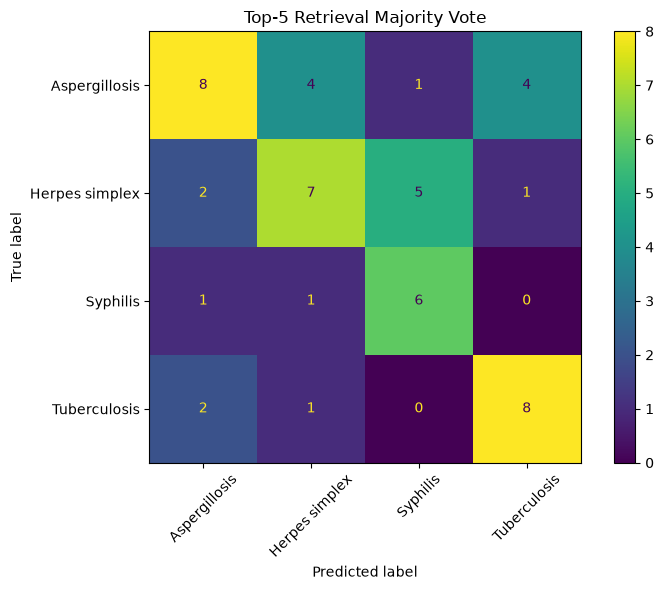

In [65]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

cm = confusion_matrix(
    majority_results_df["true_label"],
    majority_results_df["prediction"],
    labels=DISEASE_LABELS
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=DISEASE_LABELS
)

fig, ax = plt.subplots(
    figsize=(8, 6)
)

disp.plot(
    ax=ax,
    xticks_rotation=45
)

plt.title(
    "Top-5 Retrieval Majority Vote"
)

plt.tight_layout()
plt.show()

In [66]:
prompt = build_classification_prompt(
    patient_text,
    retrieved_results
)

answer = generate_rag_answer(prompt)

prediction = parse_prediction(answer)

print("TRUE       :", sample["disease"])
print("RAW OUTPUT :", repr(answer))
print("PREDICTED  :", prediction)

TRUE       : Tuberculosis
RAW OUTPUT : 'Aspergillosis'
PREDICTED  : Aspergillosis


In [67]:
import pandas as pd
from pathlib import Path
import time

CHECKPOINT_PATH = Path(
    "../discovery/qwen_rag_predictions.csv"
)

qwen_results = []

for i, row in enumerate(
    test_df.itertuples(),
    start=1
):

    print(
        f"[{i}/{len(test_df)}] "
        f"{row.id} | True: {row.disease}"
    )

    # -------------------------
    # Retrieve Top-5
    # -------------------------

    retrieved = retrieve(
        row.text,
        k=5
    )

    # -------------------------
    # Build prompt
    # -------------------------

    prompt = build_classification_prompt(
        row.text,
        retrieved
    )

    # -------------------------
    # Qwen prediction
    # -------------------------

    try:

        raw_answer = generate_rag_answer(
            prompt
        )

        prediction = parse_prediction(
            raw_answer
        )

    except Exception as e:

        print("ERROR:", e)

        raw_answer = str(e)
        prediction = None

    # -------------------------
    # Save result
    # -------------------------

    qwen_results.append({
        "case_id": row.id,
        "true_label": row.disease,
        "prediction": prediction,
        "raw_output": raw_answer
    })

    pd.DataFrame(
        qwen_results
    ).to_csv(
        CHECKPOINT_PATH,
        index=False
    )

    print(
        "Prediction:",
        prediction
    )

    print("-" * 60)

[1/51] PMC2826293_01 | True: Tuberculosis
Prediction: Aspergillosis
------------------------------------------------------------
[2/51] PMC4399170_01 | True: Herpes simplex
Prediction: Aspergillosis
------------------------------------------------------------
[3/51] PMC3177425_01 | True: Tuberculosis
Prediction: Tuberculosis
------------------------------------------------------------
[4/51] PMC8512623_01 | True: Aspergillosis
Prediction: Aspergillosis
------------------------------------------------------------
[5/51] PMC8512623_02 | True: Aspergillosis
Prediction: Aspergillosis
------------------------------------------------------------
[6/51] PMC8512623_03 | True: Aspergillosis
Prediction: Aspergillosis
------------------------------------------------------------
[7/51] PMC8512623_04 | True: Aspergillosis
Prediction: Aspergillosis
------------------------------------------------------------
[8/51] PMC7322736_01 | True: Tuberculosis
Prediction: Aspergillosis
------------------------

In [68]:
checkpoint = pd.read_csv(
    "../discovery/qwen_rag_predictions.csv"
)

print(
    "Completed:",
    len(checkpoint)
)

Completed: 51


In [69]:
qwen_results_df = pd.read_csv(
    "../discovery/qwen_rag_predictions.csv"
)

print(
    qwen_results_df[
        "prediction"
    ].value_counts(
        dropna=False
    )
)

prediction
Aspergillosis    35
Tuberculosis      7
NaN               5
Syphilis          4
Name: count, dtype: int64


In [71]:
invalid = qwen_results_df[
    qwen_results_df["prediction"].isna()
]

for _, row in invalid.iterrows():
    print("=" * 80)
    print("CASE:", row["case_id"])
    print("TRUE:", row["true_label"])
    print("RAW:")
    print(repr(row["raw_output"]))

CASE: PMC6394359_01
TRUE: Herpes simplex
RAW:
'Histoplasmosis'
CASE: PMC5514794_01
TRUE: Herpes simplex
RAW:
'Membranous aplasia cutis congenita'
CASE: PMC5791489_01
TRUE: Tuberculosis
RAW:
'Constrictive Pericarditis'
CASE: PMC11268767_01
TRUE: Syphilis
RAW:
'Leishmaniasis'
CASE: PMC12943459_01
TRUE: Syphilis
RAW:
'Rhinoscleroma'


In [72]:
qwen_results_df["valid_output"] = (
    qwen_results_df["prediction"].notna()
)

print(
    qwen_results_df["valid_output"]
    .value_counts()
)

print(
    "Valid output rate:",
    qwen_results_df["valid_output"].mean()
)

valid_output
True     46
False     5
Name: count, dtype: int64
Valid output rate: 0.9019607843137255


In [73]:
qwen_results_df["correct"] = (
    qwen_results_df["true_label"]
    ==
    qwen_results_df["prediction"]
)

qwen_accuracy = (
    qwen_results_df["correct"].mean()
)

correct_count = (
    qwen_results_df["correct"].sum()
)

print(
    f"Qwen RAG Accuracy: "
    f"{qwen_accuracy:.4f}"
)

print(
    f"Correct: "
    f"{correct_count}/"
    f"{len(qwen_results_df)}"
)

print(
    f"Valid output rate: "
    f"{qwen_results_df['valid_output'].mean():.4f}"
)

Qwen RAG Accuracy: 0.4902
Correct: 25/51
Valid output rate: 0.9020


In [74]:
from sklearn.metrics import classification_report

eval_predictions = (
    qwen_results_df["prediction"]
    .fillna("Invalid")
)

print(
    classification_report(
        qwen_results_df["true_label"],
        eval_predictions,
        labels=DISEASE_LABELS,
        digits=4,
        zero_division=0
    )
)

                precision    recall  f1-score   support

 Aspergillosis     0.4857    1.0000    0.6538        17
Herpes simplex     0.0000    0.0000    0.0000        15
      Syphilis     0.7500    0.3750    0.5000         8
  Tuberculosis     0.7143    0.4545    0.5556        11

     micro avg     0.5435    0.4902    0.5155        51
     macro avg     0.4875    0.4574    0.4274        51
  weighted avg     0.4336    0.4902    0.4162        51



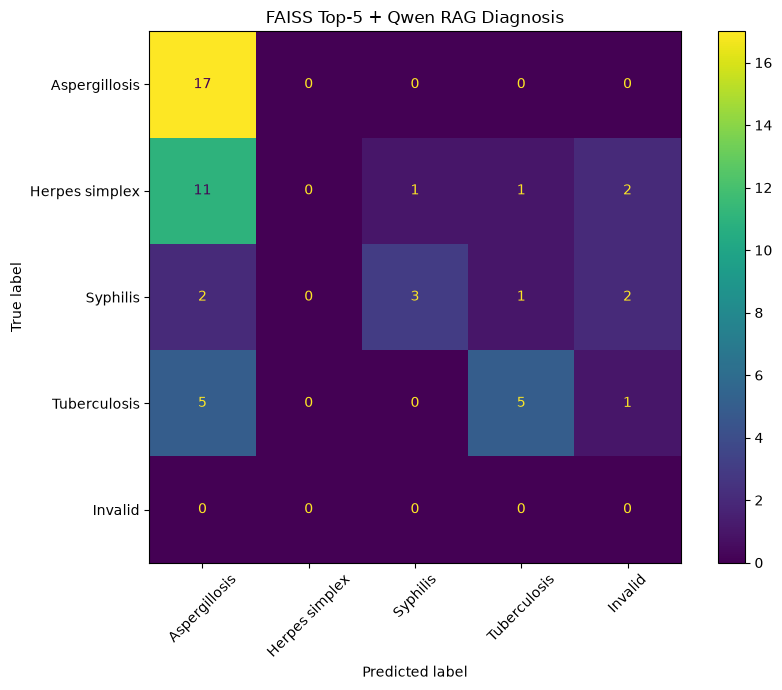

In [75]:
from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay
)

import matplotlib.pyplot as plt

labels_with_invalid = (
    DISEASE_LABELS + ["Invalid"]
)

cm = confusion_matrix(
    qwen_results_df["true_label"],
    eval_predictions,
    labels=labels_with_invalid
)

fig, ax = plt.subplots(
    figsize=(9, 7)
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=labels_with_invalid
)

disp.plot(
    ax=ax,
    xticks_rotation=45
)

plt.title(
    "FAISS Top-5 + Qwen RAG Diagnosis"
)

plt.tight_layout()
plt.show()

In [76]:
from pathlib import Path

RESULT_DIR = Path("../discovery/results")
RESULT_DIR.mkdir(parents=True, exist_ok=True)

majority_results_df.to_csv(
    RESULT_DIR / "majority_vote_results.csv",
    index=False
)

qwen_results_df.to_csv(
    RESULT_DIR / "qwen_rag_results.csv",
    index=False
)

print("Results saved.")

Results saved.


In [77]:
experiment_summary = pd.DataFrame([
    {
        "method": "FAISS Top-1",
        "accuracy": 0.5294,
        "macro_f1": None
    },
    {
        "method": "FAISS Top-5 Majority Vote",
        "accuracy": 0.5686,
        "macro_f1": 0.5750
    },
    {
        "method": "FAISS Top-5 + Qwen2.5-1.5B",
        "accuracy": 25 / 51,
        "macro_f1": 0.4274
    }
])

experiment_summary.to_csv(
    RESULT_DIR / "text_rag_summary.csv",
    index=False
)

display(experiment_summary)

,method,accuracy,macro_f1
0,FAISS Top-1,0.529400,NaN
1,FAISS Top-5 Majority Vote,0.568600,0.5750
2,FAISS Top-5 + Qwen2.5-1.5B,0.490196,0.4274


In [78]:
case_dataset = (
    final_split_dataset
    .sort_values(
        ["article_id", "case_id", "image_file"]
    )
    .drop_duplicates(
        subset=["article_id", "case_id"],
        keep="first"
    )
    .reset_index(drop=True)
)

print("Cases:", len(case_dataset))

print(
    case_dataset.groupby(
        ["split", "disease"]
    ).size()
)

Cases: 320
split  disease       
test   Aspergillosis     17
       Herpes simplex    15
       Syphilis           8
       Tuberculosis      11
train  Aspergillosis     53
       Herpes simplex    54
       Syphilis          57
       Tuberculosis      57
val    Aspergillosis     10
       Herpes simplex    11
       Syphilis          15
       Tuberculosis      12
dtype: int64


In [79]:
from pathlib import Path

case_dataset["image_exists"] = (
    case_dataset["image_path"]
    .apply(lambda x: Path(str(x)).exists())
)

print(
    case_dataset["image_exists"]
    .value_counts()
)

image_exists
True    320
Name: count, dtype: int64


In [81]:
%pip install torchvision

   ---------------------------------------- 0.0/1.4 MB ? eta -:--:--
   --------------- ------------------------ 0.5/1.4 MB 5.6 MB/s eta 0:00:01
   ---------------------------------------- 1.4/1.4 MB 8.9 MB/s eta 0:00:00
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.3.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [82]:
import torch
import torch.nn as nn

from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models
from PIL import Image

CLASSES = [
    "Aspergillosis",
    "Herpes simplex",
    "Syphilis",
    "Tuberculosis"
]

label2id = {
    label: i
    for i, label in enumerate(CLASSES)
}

id2label = {
    i: label
    for label, i in label2id.items()
}

case_dataset["label"] = (
    case_dataset["disease"]
    .map(label2id)
)

print(label2id)

{'Aspergillosis': 0, 'Herpes simplex': 1, 'Syphilis': 2, 'Tuberculosis': 3}


In [83]:
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(10),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

eval_transform = transforms.Compose([
    transforms.Resize((224, 224)),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

In [84]:
class ImageDataset(Dataset):

    def __init__(
        self,
        dataframe,
        transform=None
    ):
        self.df = dataframe.reset_index(
            drop=True
        )

        self.transform = transform


    def __len__(self):
        return len(self.df)


    def __getitem__(self, idx):

        row = self.df.iloc[idx]

        image = Image.open(
            row["image_path"]
        ).convert("RGB")

        if self.transform:
            image = self.transform(image)

        label = torch.tensor(
            int(row["label"]),
            dtype=torch.long
        )

        return {
            "image": image,
            "label": label,
            "case_id": row["case_id"],
            "disease": row["disease"]
        }

In [85]:
train_df_img = case_dataset[
    case_dataset["split"] == "train"
].copy()

val_df_img = case_dataset[
    case_dataset["split"] == "val"
].copy()

test_df_img = case_dataset[
    case_dataset["split"] == "test"
].copy()

print("Train:", len(train_df_img))
print("Val:", len(val_df_img))
print("Test:", len(test_df_img))

Train: 221
Val: 48
Test: 51


In [86]:
train_image_dataset = ImageDataset(
    train_df_img,
    train_transform
)

val_image_dataset = ImageDataset(
    val_df_img,
    eval_transform
)

test_image_dataset = ImageDataset(
    test_df_img,
    eval_transform
)

BATCH_SIZE = 8

train_image_loader = DataLoader(
    train_image_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0
)

val_image_loader = DataLoader(
    val_image_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

test_image_loader = DataLoader(
    test_image_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

In [87]:
batch = next(
    iter(train_image_loader)
)

print("Images:", batch["image"].shape)
print("Labels:", batch["label"].shape)
print("Diseases:", batch["disease"])

Images: torch.Size([8, 3, 224, 224])
Labels: torch.Size([8])
Diseases: ['Aspergillosis', 'Tuberculosis', 'Herpes simplex', 'Herpes simplex', 'Herpes simplex', 'Herpes simplex', 'Tuberculosis', 'Aspergillosis']


In [88]:
device = torch.device(
    "cuda"
    if torch.cuda.is_available()
    else "cpu"
)

print("Device:", device)

if torch.cuda.is_available():
    print(
        "GPU:",
        torch.cuda.get_device_name(0)
    )

Device: cpu


In [89]:
from torchvision.models import (
    resnet18,
    ResNet18_Weights
)

model = resnet18(
    weights=ResNet18_Weights.DEFAULT
)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to C:\Users\Tuyet Phuong/.cache\torch\hub\checkpoints\resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 50.1MB/s]


In [90]:
for param in model.parameters():
    param.requires_grad = False

In [91]:
num_features = model.fc.in_features

model.fc = nn.Sequential(
    nn.Dropout(0.3),
    nn.Linear(
        num_features,
        len(CLASSES)
    )
)

model = model.to(device)

print(model.fc)

Sequential(
  (0): Dropout(p=0.3, inplace=False)
  (1): Linear(in_features=512, out_features=4, bias=True)
)


In [92]:
trainable = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

total = sum(
    p.numel()
    for p in model.parameters()
)

print("Trainable:", trainable)
print("Total:", total)
print(
    f"Trainable: "
    f"{100 * trainable / total:.2f}%"
)

Trainable: 2052
Total: 11178564
Trainable: 0.02%


In [93]:
criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    model.fc.parameters(),
    lr=1e-3
)

In [94]:
def run_epoch(
    model,
    loader,
    criterion,
    optimizer=None
):

    training = optimizer is not None

    if training:
        model.train()
    else:
        model.eval()

    total_loss = 0
    correct = 0
    total = 0

    for batch in loader:

        images = batch["image"].to(device)
        labels = batch["label"].to(device)

        if training:
            optimizer.zero_grad()

        with torch.set_grad_enabled(training):

            outputs = model(images)

            loss = criterion(
                outputs,
                labels
            )

            if training:
                loss.backward()
                optimizer.step()

        total_loss += (
            loss.item()
            * images.size(0)
        )

        predictions = (
            outputs.argmax(dim=1)
        )

        correct += (
            predictions == labels
        ).sum().item()

        total += labels.size(0)

    return (
        total_loss / total,
        correct / total
    )

In [95]:
EPOCHS = 10

best_val_acc = 0.0

MODEL_PATH = (
    "../discovery/"
    "best_resnet18_image_only.pt"
)

for epoch in range(1, EPOCHS + 1):

    train_loss, train_acc = run_epoch(
        model,
        train_image_loader,
        criterion,
        optimizer
    )

    val_loss, val_acc = run_epoch(
        model,
        val_image_loader,
        criterion
    )

    print(
        f"Epoch {epoch:02d} | "
        f"Train Loss {train_loss:.4f} | "
        f"Train Acc {train_acc:.4f} | "
        f"Val Loss {val_loss:.4f} | "
        f"Val Acc {val_acc:.4f}"
    )

    if val_acc > best_val_acc:

        best_val_acc = val_acc

        torch.save(
            model.state_dict(),
            MODEL_PATH
        )

        print(
            "  ✓ Best model saved"
        )

Epoch 01 | Train Loss 1.6000 | Train Acc 0.2624 | Val Loss 1.4135 | Val Acc 0.3333
  ✓ Best model saved
Epoch 02 | Train Loss 1.4802 | Train Acc 0.2670 | Val Loss 1.4907 | Val Acc 0.2500
Epoch 03 | Train Loss 1.4225 | Train Acc 0.3394 | Val Loss 1.5796 | Val Acc 0.2083
Epoch 04 | Train Loss 1.3747 | Train Acc 0.3575 | Val Loss 1.4300 | Val Acc 0.1875
Epoch 05 | Train Loss 1.3272 | Train Acc 0.3665 | Val Loss 1.4606 | Val Acc 0.3125
Epoch 06 | Train Loss 1.2743 | Train Acc 0.4253 | Val Loss 1.4388 | Val Acc 0.3333
Epoch 07 | Train Loss 1.2692 | Train Acc 0.4208 | Val Loss 1.4072 | Val Acc 0.3333
Epoch 08 | Train Loss 1.2324 | Train Acc 0.3891 | Val Loss 1.5564 | Val Acc 0.3542
  ✓ Best model saved
Epoch 09 | Train Loss 1.2655 | Train Acc 0.4344 | Val Loss 1.4871 | Val Acc 0.2708
Epoch 10 | Train Loss 1.2264 | Train Acc 0.4434 | Val Loss 1.5032 | Val Acc 0.3125


In [96]:
print(
    f"Best validation accuracy: "
    f"{best_val_acc:.4f}"
)

Best validation accuracy: 0.3542


In [97]:
model.load_state_dict(
    torch.load(
        "../discovery/best_resnet18_image_only.pt",
        map_location=device
    )
)

model.eval()

print("Best model loaded.")

Best model loaded.


In [98]:
all_true = []
all_pred = []
all_case_ids = []

with torch.no_grad():

    for batch in test_image_loader:

        images = batch["image"].to(device)
        labels = batch["label"].to(device)

        outputs = model(images)

        predictions = outputs.argmax(dim=1)

        all_true.extend(
            labels.cpu().numpy()
        )

        all_pred.extend(
            predictions.cpu().numpy()
        )

        all_case_ids.extend(
            batch["case_id"]
        )

print("Test cases:", len(all_true))

Test cases: 51


In [99]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    f1_score
)

test_accuracy = accuracy_score(
    all_true,
    all_pred
)

macro_f1 = f1_score(
    all_true,
    all_pred,
    average="macro"
)

print(
    f"Image-only Test Accuracy: "
    f"{test_accuracy:.4f}"
)

print(
    f"Image-only Macro-F1: "
    f"{macro_f1:.4f}"
)

print(
    f"Correct: "
    f"{sum(
        t == p
        for t, p in zip(all_true, all_pred)
    )}/51"
)

Image-only Test Accuracy: 0.2941
Image-only Macro-F1: 0.2224
Correct: 15/51


In [100]:
print(
    classification_report(
        all_true,
        all_pred,
        labels=list(range(len(CLASSES))),
        target_names=CLASSES,
        digits=4,
        zero_division=0
    )
)

                precision    recall  f1-score   support

 Aspergillosis     0.4615    0.3529    0.4000        17
Herpes simplex     0.2857    0.5333    0.3721        15
      Syphilis     0.0000    0.0000    0.0000         8
  Tuberculosis     0.1667    0.0909    0.1176        11

      accuracy                         0.2941        51
     macro avg     0.2285    0.2443    0.2224        51
  weighted avg     0.2738    0.2941    0.2681        51



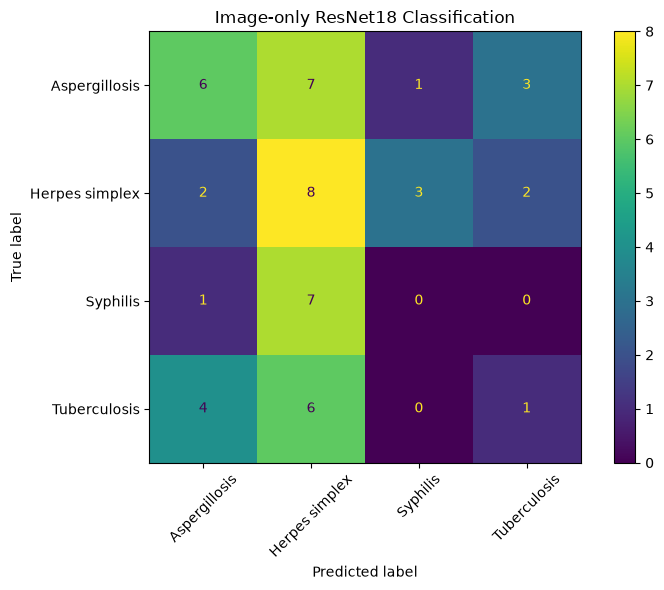

In [101]:
import matplotlib.pyplot as plt

from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay
)

cm = confusion_matrix(
    all_true,
    all_pred,
    labels=list(range(len(CLASSES)))
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=CLASSES
)

fig, ax = plt.subplots(
    figsize=(8, 6)
)

disp.plot(
    ax=ax,
    xticks_rotation=45
)

plt.title(
    "Image-only ResNet18 Classification"
)

plt.tight_layout()
plt.show()

In [102]:
image_results_df = pd.DataFrame({
    "case_id": all_case_ids,

    "true_label": [
        id2label[x]
        for x in all_true
    ],

    "prediction": [
        id2label[x]
        for x in all_pred
    ]
})

image_results_df["correct"] = (
    image_results_df["true_label"]
    ==
    image_results_df["prediction"]
)

image_results_df.to_csv(
    "../discovery/results/"
    "image_only_resnet18_results.csv",
    index=False
)

display(
    image_results_df.head()
)

,case_id,true_label,prediction,correct
0,PMC10086654_01,Herpes simplex,Herpes simplex,True
1,PMC10311228_01,Tuberculosis,Aspergillosis,False
2,PMC10479603_01,Herpes simplex,Syphilis,False
3,PMC10621037_01,Tuberculosis,Herpes simplex,False
4,PMC10726560_01,Syphilis,Herpes simplex,False


In [103]:
from transformers import AutoTokenizer

TEXT_MODEL_NAME = "distilbert-base-uncased"

tokenizer = AutoTokenizer.from_pretrained(
    TEXT_MODEL_NAME
)

MAX_LENGTH = 256

c:\Users\Tuyet Phuong\AppData\Local\Programs\Python\Python312\Lib\site-packages\huggingface_hub\file_download.py:150: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\Tuyet Phuong\.cache\huggingface\hub\models--distilbert-base-uncased. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


In [104]:
class MultimodalDataset(Dataset):

    def __init__(
        self,
        dataframe,
        tokenizer,
        image_transform,
        max_length=256
    ):
        self.df = dataframe.reset_index(drop=True)
        self.tokenizer = tokenizer
        self.image_transform = image_transform
        self.max_length = max_length


    def __len__(self):
        return len(self.df)


    def __getitem__(self, idx):

        row = self.df.iloc[idx]

        # IMAGE
        image = Image.open(
            row["image_path"]
        ).convert("RGB")

        image = self.image_transform(image)

        # TEXT
        text = str(row["case_text"])

        encoding = self.tokenizer(
            text,
            max_length=self.max_length,
            padding="max_length",
            truncation=True,
            return_tensors="pt"
        )

        # LABEL
        label = torch.tensor(
            int(row["label"]),
            dtype=torch.long
        )

        return {
            "image": image,

            "input_ids":
                encoding["input_ids"].squeeze(0),

            "attention_mask":
                encoding["attention_mask"].squeeze(0),

            "label": label,

            "case_id": row["case_id"]
        }

In [105]:
train_mm_dataset = MultimodalDataset(
    train_df_img,
    tokenizer,
    train_transform,
    MAX_LENGTH
)

val_mm_dataset = MultimodalDataset(
    val_df_img,
    tokenizer,
    eval_transform,
    MAX_LENGTH
)

test_mm_dataset = MultimodalDataset(
    test_df_img,
    tokenizer,
    eval_transform,
    MAX_LENGTH
)

In [106]:
MM_BATCH_SIZE = 4

train_mm_loader = DataLoader(
    train_mm_dataset,
    batch_size=MM_BATCH_SIZE,
    shuffle=True,
    num_workers=0
)

val_mm_loader = DataLoader(
    val_mm_dataset,
    batch_size=MM_BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

test_mm_loader = DataLoader(
    test_mm_dataset,
    batch_size=MM_BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

In [107]:
batch = next(iter(train_mm_loader))

print("Image:", batch["image"].shape)
print("Input IDs:", batch["input_ids"].shape)
print("Attention:", batch["attention_mask"].shape)
print("Label:", batch["label"].shape)

Image: torch.Size([4, 3, 224, 224])
Input IDs: torch.Size([4, 256])
Attention: torch.Size([4, 256])
Label: torch.Size([4])


In [108]:
from transformers import AutoModel
from torchvision.models import (
    resnet18,
    ResNet18_Weights
)

In [109]:
class MultimodalClassifier(nn.Module):

    def __init__(
        self,
        num_classes=4
    ):
        super().__init__()

        # =========================
        # IMAGE ENCODER
        # =========================

        self.image_encoder = resnet18(
            weights=ResNet18_Weights.DEFAULT
        )

        image_dim = (
            self.image_encoder.fc.in_features
        )

        self.image_encoder.fc = nn.Identity()

        # Freeze image encoder
        for param in self.image_encoder.parameters():
            param.requires_grad = False


        # =========================
        # TEXT ENCODER
        # =========================

        self.text_encoder = (
            AutoModel.from_pretrained(
                "distilbert-base-uncased"
            )
        )

        text_dim = (
            self.text_encoder.config.hidden_size
        )

        # Freeze DistilBERT
        for param in self.text_encoder.parameters():
            param.requires_grad = False


        # =========================
        # FUSION
        # =========================

        fusion_dim = (
            image_dim + text_dim
        )

        self.classifier = nn.Sequential(

            nn.Linear(
                fusion_dim,
                256
            ),

            nn.ReLU(),

            nn.Dropout(0.4),

            nn.Linear(
                256,
                num_classes
            )
        )


    def forward(
        self,
        image,
        input_ids,
        attention_mask
    ):

        # IMAGE FEATURES
        image_features = (
            self.image_encoder(image)
        )


        # TEXT FEATURES
        text_output = self.text_encoder(
            input_ids=input_ids,
            attention_mask=attention_mask
        )

        # DistilBERT first token
        text_features = (
            text_output
            .last_hidden_state[:, 0, :]
        )


        # CONCATENATE
        combined = torch.cat(
            [
                image_features,
                text_features
            ],
            dim=1
        )


        # CLASSIFICATION
        logits = self.classifier(
            combined
        )

        return logits

In [110]:
mm_model = MultimodalClassifier(
    num_classes=len(CLASSES)
)

mm_model = mm_model.to(device)

Loading weights: 100%|██████████| 100/100 [00:00<00:00, 1158.22it/s]
[transformers] DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_layer_norm.bias   | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 
vocab_projector.bias    | UNEXPECTED |  | 
vocab_layer_norm.weight | UNEXPECTED |  | 
vocab_transform.bias    | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


In [111]:
trainable = sum(
    p.numel()
    for p in mm_model.parameters()
    if p.requires_grad
)

total = sum(
    p.numel()
    for p in mm_model.parameters()
)

print("Total parameters:", total)
print("Trainable parameters:", trainable)

print(
    f"Trainable percentage: "
    f"{100 * trainable / total:.2f}%"
)

Total parameters: 77868356
Trainable parameters: 328964
Trainable percentage: 0.42%


In [112]:
batch = next(
    iter(train_mm_loader)
)

images = batch["image"].to(device)

input_ids = (
    batch["input_ids"].to(device)
)

attention_mask = (
    batch["attention_mask"].to(device)
)

with torch.no_grad():

    outputs = mm_model(
        images,
        input_ids,
        attention_mask
    )

print(
    "Output shape:",
    outputs.shape
)

Output shape: torch.Size([4, 4])


In [113]:
criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.AdamW(
    mm_model.classifier.parameters(),
    lr=1e-3,
    weight_decay=1e-4
)

In [114]:
def run_mm_epoch(
    model,
    loader,
    criterion,
    optimizer=None
):
    training = optimizer is not None

    if training:
        model.train()
    else:
        model.eval()

    total_loss = 0.0
    correct = 0
    total = 0

    for batch in loader:

        images = batch["image"].to(device)

        input_ids = (
            batch["input_ids"].to(device)
        )

        attention_mask = (
            batch["attention_mask"].to(device)
        )

        labels = batch["label"].to(device)

        if training:
            optimizer.zero_grad()

        with torch.set_grad_enabled(training):

            outputs = model(
                images,
                input_ids,
                attention_mask
            )

            loss = criterion(
                outputs,
                labels
            )

            if training:
                loss.backward()
                optimizer.step()

        total_loss += (
            loss.item() * labels.size(0)
        )

        predictions = outputs.argmax(dim=1)

        correct += (
            predictions == labels
        ).sum().item()

        total += labels.size(0)

    return (
        total_loss / total,
        correct / total
    )

In [115]:
from pathlib import Path

MODEL_PATH = Path(
    "../discovery/best_multimodal_model.pt"
)

EPOCHS = 15
PATIENCE = 4

best_val_acc = 0.0
patience_counter = 0

history = []

for epoch in range(1, EPOCHS + 1):

    train_loss, train_acc = run_mm_epoch(
        mm_model,
        train_mm_loader,
        criterion,
        optimizer
    )

    val_loss, val_acc = run_mm_epoch(
        mm_model,
        val_mm_loader,
        criterion
    )

    history.append({
        "epoch": epoch,
        "train_loss": train_loss,
        "train_acc": train_acc,
        "val_loss": val_loss,
        "val_acc": val_acc
    })

    print(
        f"Epoch {epoch:02d} | "
        f"Train Loss {train_loss:.4f} | "
        f"Train Acc {train_acc:.4f} | "
        f"Val Loss {val_loss:.4f} | "
        f"Val Acc {val_acc:.4f}"
    )

    if val_acc > best_val_acc:

        best_val_acc = val_acc
        patience_counter = 0

        torch.save(
            mm_model.state_dict(),
            MODEL_PATH
        )

        print("  ✓ Best model saved")

    else:

        patience_counter += 1

        print(
            f"  No improvement "
            f"({patience_counter}/{PATIENCE})"
        )

        if patience_counter >= PATIENCE:
            print("Early stopping.")
            break

Epoch 01 | Train Loss 1.6774 | Train Acc 0.2308 | Val Loss 1.4247 | Val Acc 0.2708
  ✓ Best model saved
Epoch 02 | Train Loss 1.4403 | Train Acc 0.3032 | Val Loss 1.3621 | Val Acc 0.2500
  No improvement (1/4)
Epoch 03 | Train Loss 1.3603 | Train Acc 0.3529 | Val Loss 1.3739 | Val Acc 0.4167
  ✓ Best model saved
Epoch 04 | Train Loss 1.3562 | Train Acc 0.3484 | Val Loss 1.3489 | Val Acc 0.3333
  No improvement (1/4)
Epoch 05 | Train Loss 1.3181 | Train Acc 0.3710 | Val Loss 1.3605 | Val Acc 0.2708
  No improvement (2/4)
Epoch 06 | Train Loss 1.3316 | Train Acc 0.3484 | Val Loss 1.3401 | Val Acc 0.3333
  No improvement (3/4)
Epoch 07 | Train Loss 1.3353 | Train Acc 0.3439 | Val Loss 1.3354 | Val Acc 0.3542
  No improvement (4/4)
Early stopping.


In [116]:
print(
    f"\nBest validation accuracy: "
    f"{best_val_acc:.4f}"
)


Best validation accuracy: 0.4167


In [117]:
history_df = pd.DataFrame(history)

display(history_df)

,epoch,train_loss,train_acc,val_loss,val_acc
0,1,1.677444,0.230769,1.424712,0.270833
1,2,1.440291,0.303167,1.362097,0.250000
2,3,1.360308,0.352941,1.373884,0.416667
3,4,1.356223,0.348416,1.348894,0.333333
4,5,1.318077,0.371041,1.360477,0.270833
5,6,1.331583,0.348416,1.340052,0.333333
6,7,1.335257,0.343891,1.335442,0.354167


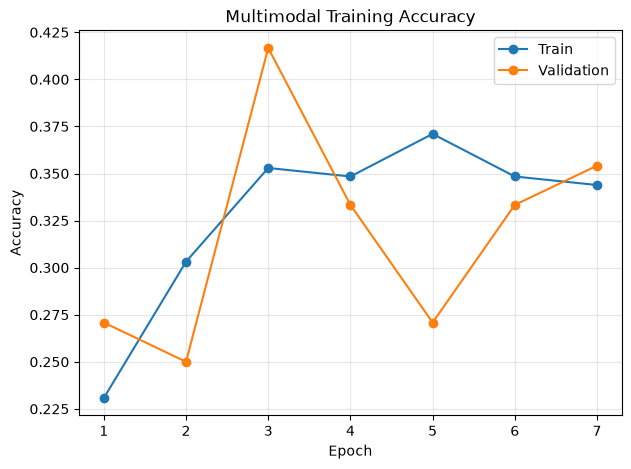

In [118]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 5))

plt.plot(
    history_df["epoch"],
    history_df["train_acc"],
    marker="o",
    label="Train"
)

plt.plot(
    history_df["epoch"],
    history_df["val_acc"],
    marker="o",
    label="Validation"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Multimodal Training Accuracy")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

In [119]:
mm_model.load_state_dict(
    torch.load(
        "../discovery/best_multimodal_model.pt",
        map_location=device
    )
)

mm_model.eval()

print("Best multimodal model loaded.")

Best multimodal model loaded.


In [120]:
mm_true = []
mm_pred = []
mm_case_ids = []

with torch.no_grad():

    for batch in test_mm_loader:

        images = batch["image"].to(device)

        input_ids = batch["input_ids"].to(device)

        attention_mask = (
            batch["attention_mask"].to(device)
        )

        labels = batch["label"].to(device)

        outputs = mm_model(
            images,
            input_ids,
            attention_mask
        )

        predictions = outputs.argmax(dim=1)

        mm_true.extend(
            labels.cpu().numpy()
        )

        mm_pred.extend(
            predictions.cpu().numpy()
        )

        mm_case_ids.extend(
            batch["case_id"]
        )

print("Test cases:", len(mm_true))

Test cases: 51


In [121]:
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report
)

mm_accuracy = accuracy_score(
    mm_true,
    mm_pred
)

mm_macro_f1 = f1_score(
    mm_true,
    mm_pred,
    average="macro"
)

print(
    f"Multimodal Test Accuracy: "
    f"{mm_accuracy:.4f}"
)

print(
    f"Multimodal Macro-F1: "
    f"{mm_macro_f1:.4f}"
)

print(
    f"Correct: "
    f"{sum(t == p for t, p in zip(mm_true, mm_pred))}"
    f"/{len(mm_true)}"
)

Multimodal Test Accuracy: 0.1373
Multimodal Macro-F1: 0.0816
Correct: 7/51


In [122]:
print(
    classification_report(
        mm_true,
        mm_pred,
        labels=list(range(len(CLASSES))),
        target_names=CLASSES,
        digits=4,
        zero_division=0
    )
)

                precision    recall  f1-score   support

 Aspergillosis     0.0000    0.0000    0.0000        17
Herpes simplex     0.2000    0.0667    0.1000        15
      Syphilis     0.1333    0.7500    0.2264         8
  Tuberculosis     0.0000    0.0000    0.0000        11

      accuracy                         0.1373        51
     macro avg     0.0833    0.2042    0.0816        51
  weighted avg     0.0797    0.1373    0.0649        51



[[ 0  3 14  0]
 [ 0  1 14  0]
 [ 0  1  6  1]
 [ 0  0 11  0]]


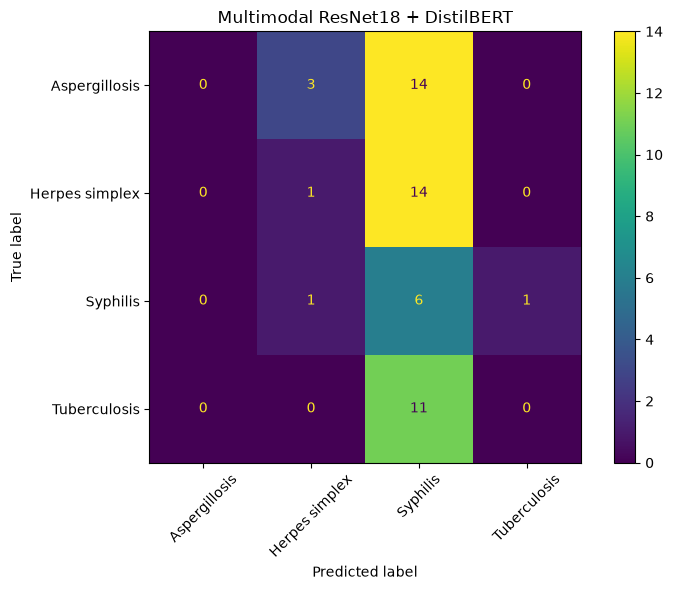

In [123]:
from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay
)

import matplotlib.pyplot as plt

mm_cm = confusion_matrix(
    mm_true,
    mm_pred,
    labels=list(range(len(CLASSES)))
)

print(mm_cm)

disp = ConfusionMatrixDisplay(
    confusion_matrix=mm_cm,
    display_labels=CLASSES
)

fig, ax = plt.subplots(
    figsize=(8, 6)
)

disp.plot(
    ax=ax,
    xticks_rotation=45
)

plt.title(
    "Multimodal ResNet18 + DistilBERT"
)

plt.tight_layout()
plt.show()

In [124]:
mm_results_df = pd.DataFrame({
    "case_id": mm_case_ids,

    "true_label": [
        id2label[x]
        for x in mm_true
    ],

    "prediction": [
        id2label[x]
        for x in mm_pred
    ]
})

mm_results_df["correct"] = (
    mm_results_df["true_label"]
    ==
    mm_results_df["prediction"]
)

mm_results_df.to_csv(
    "../discovery/results/"
    "multimodal_resnet_distilbert_results.csv",
    index=False
)

display(mm_results_df.head())

,case_id,true_label,prediction,correct
0,PMC10086654_01,Herpes simplex,Syphilis,False
1,PMC10311228_01,Tuberculosis,Syphilis,False
2,PMC10479603_01,Herpes simplex,Syphilis,False
3,PMC10621037_01,Tuberculosis,Syphilis,False
4,PMC10726560_01,Syphilis,Tuberculosis,False


In [125]:
for param in mm_model.image_encoder.parameters():
    param.requires_grad = False

for param in mm_model.image_encoder.layer4.parameters():
    param.requires_grad = True

In [126]:
for param in mm_model.text_encoder.parameters():
    param.requires_grad = False

for param in (
    mm_model
    .text_encoder
    .transformer
    .layer[-1]
    .parameters()
):
    param.requires_grad = True

In [127]:
for param in mm_model.classifier.parameters():
    param.requires_grad = True

In [128]:
trainable = sum(
    p.numel()
    for p in mm_model.parameters()
    if p.requires_grad
)

total = sum(
    p.numel()
    for p in mm_model.parameters()
)

print("Trainable:", trainable)
print("Total:", total)
print(
    f"Trainable percentage: "
    f"{100 * trainable / total:.2f}%"
)

Trainable: 15810564
Total: 77868356
Trainable percentage: 20.30%


In [129]:
mm_model = MultimodalClassifier(
    num_classes=len(CLASSES)
).to(device)

Loading weights: 100%|██████████| 100/100 [00:00<00:00, 1326.34it/s]
[transformers] DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_layer_norm.bias   | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 
vocab_projector.bias    | UNEXPECTED |  | 
vocab_layer_norm.weight | UNEXPECTED |  | 
vocab_transform.bias    | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


In [130]:
optimizer = torch.optim.AdamW(
    [
        {
            "params":
                mm_model.image_encoder.layer4.parameters(),
            "lr": 1e-5
        },
        {
            "params":
                mm_model.text_encoder
                .transformer
                .layer[-1]
                .parameters(),
            "lr": 1e-5
        },
        {
            "params":
                mm_model.classifier.parameters(),
            "lr": 3e-4
        }
    ],
    weight_decay=1e-4
)

criterion = nn.CrossEntropyLoss()

In [131]:
MODEL_PATH = Path(
    "../discovery/"
    "best_multimodal_partial_finetune.pt"
)

EPOCHS = 15
PATIENCE = 4

best_val_acc = 0.0
patience_counter = 0

finetune_history = []

for epoch in range(1, EPOCHS + 1):

    train_loss, train_acc = run_mm_epoch(
        mm_model,
        train_mm_loader,
        criterion,
        optimizer
    )

    val_loss, val_acc = run_mm_epoch(
        mm_model,
        val_mm_loader,
        criterion
    )

    finetune_history.append({
        "epoch": epoch,
        "train_loss": train_loss,
        "train_acc": train_acc,
        "val_loss": val_loss,
        "val_acc": val_acc
    })

    print(
        f"Epoch {epoch:02d} | "
        f"Train Loss {train_loss:.4f} | "
        f"Train Acc {train_acc:.4f} | "
        f"Val Loss {val_loss:.4f} | "
        f"Val Acc {val_acc:.4f}"
    )

    if val_acc > best_val_acc:

        best_val_acc = val_acc
        patience_counter = 0

        torch.save(
            mm_model.state_dict(),
            MODEL_PATH
        )

        print("  ✓ Best model saved")

    else:

        patience_counter += 1

        print(
            f"  No improvement "
            f"({patience_counter}/{PATIENCE})"
        )

        if patience_counter >= PATIENCE:
            print("Early stopping.")
            break

print(
    f"\nBest validation accuracy: "
    f"{best_val_acc:.4f}"
)

Epoch 01 | Train Loss 1.4227 | Train Acc 0.2534 | Val Loss 1.4157 | Val Acc 0.3125
  ✓ Best model saved
Epoch 02 | Train Loss 1.4086 | Train Acc 0.2805 | Val Loss 1.3793 | Val Acc 0.2708
  No improvement (1/4)
Epoch 03 | Train Loss 1.3362 | Train Acc 0.3529 | Val Loss 1.3621 | Val Acc 0.2708
  No improvement (2/4)
Epoch 04 | Train Loss 1.3004 | Train Acc 0.3846 | Val Loss 1.3706 | Val Acc 0.3125
  No improvement (3/4)
Epoch 05 | Train Loss 1.3583 | Train Acc 0.3077 | Val Loss 1.3139 | Val Acc 0.3333
  ✓ Best model saved
Epoch 06 | Train Loss 1.2548 | Train Acc 0.4299 | Val Loss 1.4263 | Val Acc 0.2708
  No improvement (1/4)
Epoch 07 | Train Loss 1.2825 | Train Acc 0.3710 | Val Loss 1.3446 | Val Acc 0.2917
  No improvement (2/4)
Epoch 08 | Train Loss 1.3302 | Train Acc 0.3394 | Val Loss 1.3211 | Val Acc 0.3333
  No improvement (3/4)
Epoch 09 | Train Loss 1.2836 | Train Acc 0.3665 | Val Loss 1.3101 | Val Acc 0.3125
  No improvement (4/4)
Early stopping.

Best validation accuracy: 0.3333


In [132]:
from collections import Counter

def diagnose_with_rag(patient_text, k=5):

    retrieved = retrieve(
        patient_text,
        k=k
    )

    diseases = [
        r["disease"]
        for r in retrieved
    ]

    prediction = (
        Counter(diseases)
        .most_common(1)[0][0]
    )

    return {
        "prediction": prediction,
        "retrieved_cases": retrieved
    }

In [133]:
sample = test_df.iloc[0]

result = diagnose_with_rag(
    sample["text"],
    k=5
)

print("True disease:")
print(sample["disease"])

print("\nPredicted disease:")
print(result["prediction"])

print("\nRetrieved evidence:")

for i, r in enumerate(
    result["retrieved_cases"],
    start=1
):
    print(
        f"\n{i}. {r['disease']} "
        f"(score={r['score']:.4f})"
    )

    print(
        r["text"][:300],
        "..."
    )

True disease:
Tuberculosis

Predicted disease:
Tuberculosis

Retrieved evidence:

1. Syphilis (score=0.6198)
A 41-year-old man visited the urology department of JR Tokyo General Hospital with complaints of swelling and pain in the scrotum that had commenced 3 days earlier. A urologist diagnosed epididymitis and prescribed levofloxacin at 500 mg/day. However, the symptoms did not improve, and the patient vi ...

2. Aspergillosis (score=0.6131)
16-month old boy diagnosed with standard-risk precursor B cell-acute lymphoblastic leukemia was initiated induction therapy of ALL BFM 95 treatment protocol which consisted of prednisone (60 mg/m2/day for day 1-28, and tapering for day 29-37), daunorubicin (30 mg/m2/day for day 8 and 15), L-asparagi ...

3. Tuberculosis (score=0.6037)
A 19 year-old-spastic man arrived at our emergency department with abdominal distension, vomiting, and fatigue for 3 days. He also had a low-grade fever for 2 weeks. Since birth, he has been diagnosed with CP and has

In [134]:
def diagnose_with_rag(patient_text, k=5):

    retrieved = retrieve(
        patient_text,
        k=k
    )

    diseases = [
        r["disease"]
        for r in retrieved
    ]

    counts = Counter(diseases)

    prediction, votes = (
        counts.most_common(1)[0]
    )

    confidence = votes / k

    return {
        "prediction": prediction,
        "confidence": confidence,
        "votes": dict(counts),
        "retrieved_cases": retrieved
    }

In [135]:
from transformers import (
    AutoTokenizer,
    AutoModelForCausalLM
)
import torch

QWEN_MODEL = "Qwen/Qwen2.5-1.5B-Instruct"

qwen_tokenizer = AutoTokenizer.from_pretrained(
    QWEN_MODEL
)

qwen_model = AutoModelForCausalLM.from_pretrained(
    QWEN_MODEL,
    torch_dtype=(
        torch.float16
        if torch.cuda.is_available()
        else torch.float32
    ),
    device_map="auto"
)

qwen_model.eval()

print("Qwen loaded.")

Loading weights: 100%|██████████| 338/338 [00:04<00:00, 67.82it/s]

Qwen loaded.


In [136]:
def build_explanation_prompt(
    patient_text,
    prediction,
    retrieved_cases
):

    evidence_parts = []

    for i, case in enumerate(
        retrieved_cases,
        start=1
    ):

        evidence_parts.append(
            f"""
Retrieved Case {i}
Disease label: {case['disease']}
Clinical text:
{case['text']}
"""
        )

    evidence = "\n".join(evidence_parts)

    prompt = f"""
You are assisting with an academic clinical decision-support experiment.

PREDICTED DISEASE:
{prediction}

NEW PATIENT:
{patient_text}

RETRIEVED MULTICARE CASES:
{evidence}

Task:
Explain briefly why the retrieved evidence supports or does not strongly
support the predicted disease.

Rules:
1. Do NOT change the predicted disease.
2. Use only information contained in the new patient text and retrieved cases.
3. Do NOT invent symptoms, laboratory results, imaging findings, history,
   treatment, or demographic information.
4. If the retrieved evidence is weak or conflicting, explicitly say so.
5. Do not claim certainty.
6. Keep the explanation concise.
7. This is an academic decision-support output, not a definitive diagnosis.

Return:

Prediction: <predicted disease>

Evidence:
<2-4 sentences>

Evidence strength: <Strong / Moderate / Weak>
"""

    return prompt

In [137]:
def generate_explanation(
    patient_text,
    prediction,
    retrieved_cases
):

    prompt = build_explanation_prompt(
        patient_text,
        prediction,
        retrieved_cases
    )

    messages = [
        {
            "role": "user",
            "content": prompt
        }
    ]

    formatted_prompt = (
        qwen_tokenizer.apply_chat_template(
            messages,
            tokenize=False,
            add_generation_prompt=True
        )
    )

    inputs = qwen_tokenizer(
        formatted_prompt,
        return_tensors="pt",
        truncation=True,
        max_length=4096
    )

    inputs = {
        k: v.to(qwen_model.device)
        for k, v in inputs.items()
    }

    with torch.no_grad():

        outputs = qwen_model.generate(
            **inputs,
            max_new_tokens=180,
            do_sample=False,
            pad_token_id=qwen_tokenizer.eos_token_id
        )

    generated_tokens = outputs[
        0,
        inputs["input_ids"].shape[1]:
    ]

    explanation = qwen_tokenizer.decode(
        generated_tokens,
        skip_special_tokens=True
    )

    return explanation.strip()

In [138]:
from collections import Counter

def final_diagnose(
    patient_text,
    k=5,
    generate_explanation=True
):

    # -------------------------
    # 1. RETRIEVAL
    # -------------------------

    retrieved = retrieve(
        patient_text,
        k=k
    )

    # -------------------------
    # 2. MAJORITY VOTE
    # -------------------------

    diseases = [
        r["disease"]
        for r in retrieved
    ]

    counts = Counter(diseases)

    prediction, votes = (
        counts.most_common(1)[0]
    )

    agreement = votes / len(retrieved)

    # -------------------------
    # 3. EXPLANATION
    # -------------------------

    explanation = None

    if generate_explanation:

        explanation = generate_explanation(
            patient_text,
            prediction,
            retrieved
        )

    return {
        "prediction": prediction,
        "retrieval_agreement": agreement,
        "votes": dict(counts),
        "retrieved_cases": retrieved,
        "explanation": explanation
    }

In [139]:
sample = test_df.iloc[0]

print("TRUE LABEL:")
print(sample["disease"])

print("\nPATIENT TEXT:")
print(sample["text"][:700])

TRUE LABEL:
Tuberculosis

PATIENT TEXT:
A 41-year-old Nepalese male of Aryan origin presented with 3 months history of gradually progressive jaundice, intermittent right upper quadrant pain, and weight loss of 5 kg over a 2-month period. There was no history of cough, fever, hemoptysis or shortness of breath. He had received a BCG vaccine at childhood, but there was no prior history of tuberculosis, or family history of contact.
On examination, patient was deeply icteric with skin scratch marks all over the body. On abdominal examination, he had mild hepatomegaly and a palpable gall bladder. Initial laboratory values revealed a WBC count of 9200/mm3 (90% neutrophils, 10% lymphocytes), haemoglobin 12.7 g/dL, total bilirubin 24.4 mg


In [142]:
from collections import Counter

def final_diagnose(
    patient_text,
    k=5,
    with_explanation=True
):

    # 1. Retrieve
    retrieved = retrieve(
        patient_text,
        k=k
    )

    # 2. Majority vote
    diseases = [
        r["disease"]
        for r in retrieved
    ]

    counts = Counter(diseases)

    prediction, votes = (
        counts.most_common(1)[0]
    )

    agreement = votes / len(retrieved)

    # 3. Explanation
    explanation = None

    if with_explanation:

        explanation = generate_explanation(
            patient_text,
            prediction,
            retrieved
        )

    return {
        "prediction": prediction,
        "retrieval_agreement": agreement,
        "votes": dict(counts),
        "retrieved_cases": retrieved,
        "explanation": explanation
    }

In [143]:
sample = test_df.iloc[0]

result = final_diagnose(
    sample["text"],
    k=5,
    with_explanation=False
)

print("TRUE:")
print(sample["disease"])

print("\nPREDICTION:")
print(result["prediction"])

print("\nAGREEMENT:")
print(result["retrieval_agreement"])

print("\nVOTES:")
print(result["votes"])

TRUE:
Tuberculosis

PREDICTION:
Tuberculosis

AGREEMENT:
0.6

VOTES:
{'Syphilis': 1, 'Aspergillosis': 1, 'Tuberculosis': 3}


In [144]:
result = final_diagnose(
    sample["text"],
    k=5,
    with_explanation=True
)

print("TRUE:")
print(sample["disease"])

print("\nPREDICTION:")
print(result["prediction"])

print("\nAGREEMENT:")
print(result["retrieval_agreement"])

print("\nVOTES:")
print(result["votes"])

print("\nEXPLANATION:")
print(result["explanation"])

TRUE:
Tuberculosis

PREDICTION:
Tuberculosis

AGREEMENT:
0.6

VOTES:
{'Syphilis': 1, 'Aspergillosis': 1, 'Tuberculosis': 3}

EXPLANATION:
/L, ALT 100 IU/L, ALP 100 IU/L, and albumin 3.5 gm/dl. Urine routine was normal. Chest X-ray was normal. Ultrasonography of abdomen was normal. Contrast-enhanced CT scan of abdomen and pelvis was normal. Laparoscopy was planned but was deferred due to the patient’s poor general condition. The patient was treated with broad spectrum antibiotics (cefuroxime axetil 1 g twice daily for 10 days) and symptomatic analgesics. The pain was relieved after 3 days. The patient was then referred to gastroenterology for further management. The patient was started on triple therapy consisting of clarithromycin, azithromycin, and metronidazole. The patient responded well to the treatment and was discharged after 1 week. The patient was


In [145]:
def shorten_text(text, max_words=120):
    words = str(text).split()

    if len(words) <= max_words:
        return " ".join(words)

    return " ".join(words[:max_words]) + " ..."

In [146]:
def build_explanation_prompt(
    patient_text,
    prediction,
    retrieved_cases
):

    # Patient text cũng giới hạn
    patient_short = shorten_text(
        patient_text,
        max_words=180
    )

    evidence_parts = []

    for i, case in enumerate(
        retrieved_cases,
        start=1
    ):

        case_short = shorten_text(
            case["text"],
            max_words=100
        )

        evidence_parts.append(
            f"""
CASE {i}
Label: {case['disease']}
Text: {case_short}
"""
        )

    evidence = "\n".join(evidence_parts)

    return f"""
You are an evidence summarizer.

The diagnosis has already been selected.
You are NOT allowed to diagnose again.

PREDICTION:
{prediction}

PATIENT:
{patient_short}

RETRIEVED EVIDENCE:
{evidence}

Write a short explanation of why the retrieved cases support the prediction.

STRICT RULES:
- Use ONLY facts explicitly written above.
- Do NOT add laboratory values.
- Do NOT add medications or treatments.
- Do NOT add imaging findings.
- Do NOT add symptoms.
- Do NOT add patient history.
- Do NOT introduce new medical facts.
- Do NOT continue any retrieved case story.
- If evidence is conflicting, say that it is conflicting.
- Maximum 3 sentences.

Output exactly:

Evidence: <short explanation>
Evidence strength: <Strong, Moderate, or Weak>
"""

In [147]:
def generate_explanation(
    patient_text,
    prediction,
    retrieved_cases
):

    prompt = build_explanation_prompt(
        patient_text,
        prediction,
        retrieved_cases
    )

    messages = [
        {
            "role": "user",
            "content": prompt
        }
    ]

    formatted_prompt = (
        qwen_tokenizer.apply_chat_template(
            messages,
            tokenize=False,
            add_generation_prompt=True
        )
    )

    inputs = qwen_tokenizer(
        formatted_prompt,
        return_tensors="pt",
        truncation=True,
        max_length=2048
    )

    inputs = {
        k: v.to(qwen_model.device)
        for k, v in inputs.items()
    }

    with torch.no_grad():

        outputs = qwen_model.generate(
            **inputs,
            max_new_tokens=100,
            do_sample=False,
            repetition_penalty=1.1,
            pad_token_id=qwen_tokenizer.eos_token_id
        )

    generated = outputs[
        0,
        inputs["input_ids"].shape[1]:
    ]

    return qwen_tokenizer.decode(
        generated,
        skip_special_tokens=True
    ).strip()

In [148]:
result = final_diagnose(
    sample["text"],
    k=5,
    with_explanation=True
)

print("TRUE:")
print(sample["disease"])

print("\nPREDICTION:")
print(result["prediction"])

print("\nAGREEMENT:")
print(result["retrieval_agreement"])

print("\nVOTES:")
print(result["votes"])

print("\nEXPLANATION:")
print(result["explanation"])

TRUE:
Tuberculosis

PREDICTION:
Tuberculosis

AGREEMENT:
0.6

VOTES:
{'Syphilis': 1, 'Aspergillosis': 1, 'Tuberculosis': 3}

EXPLANATION:
Evidence: All five cases involve patients presenting with symptoms suggestive of tuberculosis, including abdominal pain, weight loss, and jaundice. The common thread is the absence of typical symptoms like cough, fever, or hemoptysis seen in other diseases such as syphilis, aspergillosis, and acute lymphoblastic leukemia.

Evidence strength: Strong


In [149]:
def agreement_strength(agreement):

    if agreement >= 0.8:
        return "Strong"

    elif agreement >= 0.6:
        return "Moderate"

    else:
        return "Weak"

In [150]:
print(
    agreement_strength(
        result["retrieval_agreement"]
    )
)

Moderate


In [151]:
def build_evidence_summary(
    prediction,
    retrieved_cases
):

    diseases = [
        r["disease"]
        for r in retrieved_cases
    ]

    counts = Counter(diseases)

    prediction_votes = counts[prediction]
    total = len(retrieved_cases)

    other_counts = {
        disease: count
        for disease, count in counts.items()
        if disease != prediction
    }

    summary = (
        f"{prediction_votes} of {total} retrieved "
        f"MultiCaRe cases support {prediction}."
    )

    if other_counts:

        conflicts = ", ".join(
            f"{disease} ({count})"
            for disease, count
            in other_counts.items()
        )

        summary += (
            f" Conflicting retrieved labels: "
            f"{conflicts}."
        )

    return summary

In [152]:
summary = build_evidence_summary(
    result["prediction"],
    result["retrieved_cases"]
)

print(summary)

3 of 5 retrieved MultiCaRe cases support Tuberculosis. Conflicting retrieved labels: Syphilis (1), Aspergillosis (1).


In [153]:
def final_diagnose(
    patient_text,
    k=5
):

    # 1. Retrieval
    retrieved = retrieve(
        patient_text,
        k=k
    )

    # 2. Majority vote
    diseases = [
        r["disease"]
        for r in retrieved
    ]

    counts = Counter(diseases)

    prediction, votes = (
        counts.most_common(1)[0]
    )

    agreement = votes / len(retrieved)

    # 3. Deterministic evidence
    evidence_summary = (
        build_evidence_summary(
            prediction,
            retrieved
        )
    )

    strength = agreement_strength(
        agreement
    )

    return {
        "prediction": prediction,
        "retrieval_agreement": agreement,
        "evidence_strength": strength,
        "votes": dict(counts),
        "evidence_summary": evidence_summary,
        "retrieved_cases": retrieved
    }

In [154]:
result = final_diagnose(
    sample["text"],
    k=5
)

print("TRUE:")
print(sample["disease"])

print("\nPREDICTION:")
print(result["prediction"])

print("\nAGREEMENT:")
print(result["retrieval_agreement"])

print("\nEVIDENCE STRENGTH:")
print(result["evidence_strength"])

print("\nVOTES:")
print(result["votes"])

print("\nEVIDENCE SUMMARY:")
print(result["evidence_summary"])

TRUE:
Tuberculosis

PREDICTION:
Tuberculosis

AGREEMENT:
0.6

EVIDENCE STRENGTH:
Moderate

VOTES:
{'Syphilis': 1, 'Aspergillosis': 1, 'Tuberculosis': 3}

EVIDENCE SUMMARY:
3 of 5 retrieved MultiCaRe cases support Tuberculosis. Conflicting retrieved labels: Syphilis (1), Aspergillosis (1).


In [155]:
import torch
import torch.nn.functional as F
from torchvision.models import resnet18, ResNet18_Weights
import torch.nn as nn

image_model = resnet18(
    weights=ResNet18_Weights.DEFAULT
)

num_features = image_model.fc.in_features

image_model.fc = nn.Sequential(
    nn.Dropout(0.3),
    nn.Linear(num_features, len(CLASSES))
)

image_model.load_state_dict(
    torch.load(
        "../discovery/best_resnet18_image_only.pt",
        map_location=device
    )
)

image_model = image_model.to(device)
image_model.eval()

print("Image model loaded.")

Image model loaded.


In [156]:
def predict_image(image_path):

    image = Image.open(
        image_path
    ).convert("RGB")

    image_tensor = eval_transform(
        image
    ).unsqueeze(0).to(device)

    with torch.no_grad():

        logits = image_model(
            image_tensor
        )

        probs = F.softmax(
            logits,
            dim=1
        )[0]

    probabilities = {
        id2label[i]: float(probs[i])
        for i in range(len(CLASSES))
    }

    prediction = max(
        probabilities,
        key=probabilities.get
    )

    return {
        "prediction": prediction,
        "probabilities": probabilities
    }

In [157]:
sample_case = case_dataset[
    case_dataset["case_id"] == sample["id"]
].iloc[0]

image_result = predict_image(
    sample_case["image_path"]
)

print("TRUE:")
print(sample_case["disease"])

print("\nIMAGE PREDICTION:")
print(image_result["prediction"])

print("\nPROBABILITIES:")

for disease, prob in image_result[
    "probabilities"
].items():

    print(
        f"{disease:20s}: "
        f"{prob:.4f}"
    )

TRUE:
Tuberculosis

IMAGE PREDICTION:
Herpes simplex

PROBABILITIES:
Aspergillosis       : 0.2172
Herpes simplex      : 0.6621
Syphilis            : 0.0130
Tuberculosis        : 0.1077


In [158]:
def get_text_scores(
    patient_text,
    k=5
):

    retrieved = retrieve(
        patient_text,
        k=k
    )

    diseases = [
        r["disease"]
        for r in retrieved
    ]

    counts = Counter(diseases)

    scores = {
        disease:
            counts.get(disease, 0) / k
        for disease in CLASSES
    }

    return scores, retrieved

In [159]:
text_scores, retrieved = (
    get_text_scores(
        sample["text"],
        k=5
    )
)

print(text_scores)

{'Aspergillosis': 0.2, 'Herpes simplex': 0.0, 'Syphilis': 0.2, 'Tuberculosis': 0.6}


In [160]:
def late_fusion_predict(
    patient_text,
    image_path,
    alpha=0.8,
    k=5
):

    # TEXT
    text_scores, retrieved = (
        get_text_scores(
            patient_text,
            k=k
        )
    )

    # IMAGE
    image_result = predict_image(
        image_path
    )

    image_scores = (
        image_result["probabilities"]
    )

    # FUSION
    fusion_scores = {}

    for disease in CLASSES:

        fusion_scores[disease] = (
            alpha
            * text_scores[disease]

            +

            (1 - alpha)
            * image_scores[disease]
        )

    prediction = max(
        fusion_scores,
        key=fusion_scores.get
    )

    return {
        "prediction": prediction,
        "text_scores": text_scores,
        "image_scores": image_scores,
        "fusion_scores": fusion_scores,
        "retrieved_cases": retrieved
    }

In [161]:
fusion_result = late_fusion_predict(
    patient_text=sample["text"],
    image_path=sample_case["image_path"],
    alpha=0.8,
    k=5
)

print("TRUE:")
print(sample["disease"])

print("\nTEXT SCORES:")
print(fusion_result["text_scores"])

print("\nIMAGE SCORES:")
print(fusion_result["image_scores"])

print("\nFUSION SCORES:")

for disease, score in sorted(
    fusion_result["fusion_scores"].items(),
    key=lambda x: x[1],
    reverse=True
):

    print(
        f"{disease:20s}: "
        f"{score:.4f}"
    )

print("\nFINAL PREDICTION:")
print(fusion_result["prediction"])

TRUE:
Tuberculosis

TEXT SCORES:
{'Aspergillosis': 0.2, 'Herpes simplex': 0.0, 'Syphilis': 0.2, 'Tuberculosis': 0.6}

IMAGE SCORES:
{'Aspergillosis': 0.21717174351215363, 'Herpes simplex': 0.6620912551879883, 'Syphilis': 0.013024047017097473, 'Tuberculosis': 0.10771295428276062}

FUSION SCORES:
Tuberculosis        : 0.5015
Aspergillosis       : 0.2034
Syphilis            : 0.1626
Herpes simplex      : 0.1324

FINAL PREDICTION:
Tuberculosis


In [162]:
val_fusion_df = val_df.merge(
    case_dataset[
        [
            "case_id",
            "image_path"
        ]
    ],
    left_on="id",
    right_on="case_id",
    how="left"
)

print(
    "Validation cases:",
    len(val_fusion_df)
)

print(
    "Missing images:",
    val_fusion_df["image_path"]
    .isna()
    .sum()
)

Validation cases: 48
Missing images: 0


In [163]:
from sklearn.metrics import (
    accuracy_score,
    f1_score
)

alphas = [
    0.5,
    0.6,
    0.7,
    0.8,
    0.9,
    1.0
]

fusion_validation_results = []

for alpha in alphas:

    y_true = []
    y_pred = []

    for row in val_fusion_df.itertuples():

        result = late_fusion_predict(
            patient_text=row.text,
            image_path=row.image_path,
            alpha=alpha,
            k=5
        )

        y_true.append(
            row.disease
        )

        y_pred.append(
            result["prediction"]
        )

    acc = accuracy_score(
        y_true,
        y_pred
    )

    macro_f1 = f1_score(
        y_true,
        y_pred,
        average="macro"
    )

    fusion_validation_results.append({
        "alpha_text": alpha,
        "alpha_image": 1-alpha,
        "accuracy": acc,
        "macro_f1": macro_f1
    })

fusion_validation_df = pd.DataFrame(
    fusion_validation_results
)

display(fusion_validation_df)

,alpha_text,alpha_image,accuracy,macro_f1
0,0.5,0.5,0.562500,0.565707
1,0.6,0.4,0.562500,0.565707
2,0.7,0.3,0.520833,0.522727
3,0.8,0.2,0.520833,0.524235
4,0.9,0.1,0.520833,0.524235
5,1.0,0.0,0.520833,0.522487


In [164]:
best_row = (
    fusion_validation_df
    .sort_values(
        [
            "macro_f1",
            "accuracy"
        ],
        ascending=False
    )
    .iloc[0]
)

BEST_ALPHA = float(
    best_row["alpha_text"]
)

print(
    "Best alpha:",
    BEST_ALPHA
)

print(
    "Validation Accuracy:",
    best_row["accuracy"]
)

print(
    "Validation Macro-F1:",
    best_row["macro_f1"]
)

Best alpha: 0.5
Validation Accuracy: 0.5625
Validation Macro-F1: 0.5657066765762419


In [165]:
test_fusion_df = test_df.merge(
    case_dataset[
        [
            "case_id",
            "image_path"
        ]
    ],
    left_on="id",
    right_on="case_id",
    how="left"
)

print(
    "Test cases:",
    len(test_fusion_df)
)

print(
    "Missing images:",
    test_fusion_df["image_path"]
    .isna()
    .sum()
)

Test cases: 51
Missing images: 0


In [166]:
BEST_ALPHA = 0.5

fusion_true = []
fusion_pred = []

fusion_records = []

for row in test_fusion_df.itertuples():

    result = late_fusion_predict(
        patient_text=row.text,
        image_path=row.image_path,
        alpha=BEST_ALPHA,
        k=5
    )

    fusion_true.append(
        row.disease
    )

    fusion_pred.append(
        result["prediction"]
    )

    fusion_records.append({
        "case_id": row.id,
        "true_label": row.disease,
        "prediction": result["prediction"],
        "correct":
            row.disease
            == result["prediction"]
    })

In [167]:
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report
)

fusion_accuracy = accuracy_score(
    fusion_true,
    fusion_pred
)

fusion_macro_f1 = f1_score(
    fusion_true,
    fusion_pred,
    average="macro"
)

print(
    f"Late Fusion Test Accuracy: "
    f"{fusion_accuracy:.4f}"
)

print(
    f"Late Fusion Macro-F1: "
    f"{fusion_macro_f1:.4f}"
)

print(
    f"Correct: "
    f"{sum(
        t == p
        for t, p
        in zip(fusion_true, fusion_pred)
    )}/51"
)

Late Fusion Test Accuracy: 0.5882
Late Fusion Macro-F1: 0.5913
Correct: 30/51


In [168]:
print(
    classification_report(
        fusion_true,
        fusion_pred,
        labels=CLASSES,
        target_names=CLASSES,
        digits=4,
        zero_division=0
    )
)

                precision    recall  f1-score   support

 Aspergillosis     0.6667    0.5882    0.6250        17
Herpes simplex     0.4375    0.4667    0.4516        15
      Syphilis     0.4444    0.5000    0.4706         8
  Tuberculosis     0.8182    0.8182    0.8182        11

      accuracy                         0.5882        51
     macro avg     0.5917    0.5933    0.5913        51
  weighted avg     0.5971    0.5882    0.5914        51



[[10  6  0  1]
 [ 2  7  5  1]
 [ 1  3  4  0]
 [ 2  0  0  9]]


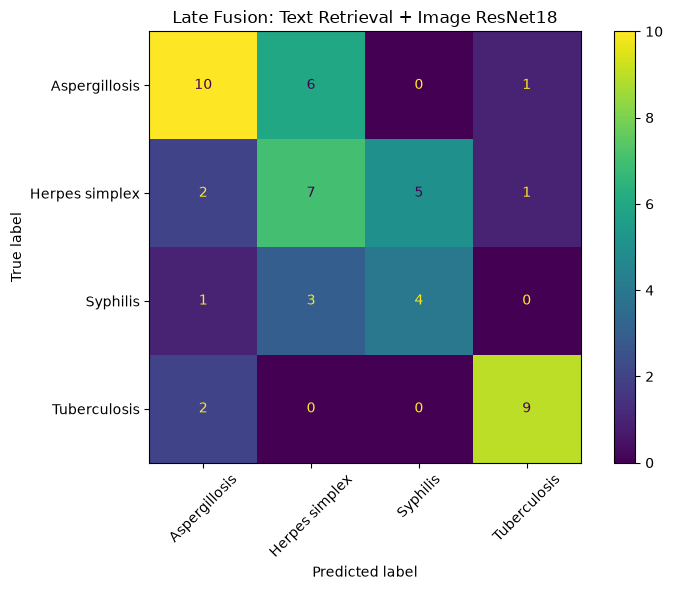

In [169]:
from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay
)

import matplotlib.pyplot as plt

fusion_cm = confusion_matrix(
    fusion_true,
    fusion_pred,
    labels=CLASSES
)

print(fusion_cm)

disp = ConfusionMatrixDisplay(
    confusion_matrix=fusion_cm,
    display_labels=CLASSES
)

fig, ax = plt.subplots(
    figsize=(8, 6)
)

disp.plot(
    ax=ax,
    xticks_rotation=45
)

plt.title(
    "Late Fusion: Text Retrieval + Image ResNet18"
)

plt.tight_layout()
plt.show()

In [170]:
fusion_results_df = pd.DataFrame(
    fusion_records
)

fusion_results_df.to_csv(
    "../discovery/results/"
    "late_fusion_results.csv",
    index=False
)

display(
    fusion_results_df.head()
)

,case_id,true_label,prediction,correct
0,PMC2826293_01,Tuberculosis,Tuberculosis,True
1,PMC4399170_01,Herpes simplex,Herpes simplex,True
2,PMC3177425_01,Tuberculosis,Tuberculosis,True
3,PMC8512623_01,Aspergillosis,Aspergillosis,True
4,PMC8512623_02,Aspergillosis,Aspergillosis,True


In [171]:
final_comparison = pd.DataFrame([
    {
        "Method": "Image-only ResNet18",
        "Accuracy": 0.2941,
        "Macro-F1": 0.2224
    },
    {
        "Method": "Text FAISS Top-1",
        "Accuracy": 0.5294,
        "Macro-F1": None
    },
    {
        "Method": "Text FAISS Top-5 Majority",
        "Accuracy": 0.5686,
        "Macro-F1": 0.5750
    },
    {
        "Method": "Text FAISS + Qwen 1.5B",
        "Accuracy": 0.4902,
        "Macro-F1": 0.4274
    },
    {
        "Method": "Early Fusion ResNet18 + DistilBERT",
        "Accuracy": 0.1373,
        "Macro-F1": 0.0816
    },
    {
        "Method": "Late Fusion Image + Text",
        "Accuracy": fusion_accuracy,
        "Macro-F1": fusion_macro_f1
    }
])

display(
    final_comparison
)

,Method,Accuracy,Macro-F1
0,Image-only ResNet18,0.294100,0.222400
1,Text FAISS Top-1,0.529400,NaN
2,Text FAISS Top-5 Majority,0.568600,0.575000
3,Text FAISS + Qwen 1.5B,0.490200,0.427400
4,Early Fusion ResNet18 + DistilBERT,0.137300,0.081600
5,Late Fusion Image + Text,0.588235,0.591346


In [172]:
final_comparison.to_csv(
    "../discovery/results/"
    "final_model_comparison.csv",
    index=False
)

In [173]:
BEST_ALPHA = 0.5

def final_multimodal_diagnose(
    patient_text,
    image_path,
    k=5
):
    # ==================================
    # 1. TEXT RETRIEVAL
    # ==================================

    text_scores, retrieved = get_text_scores(
        patient_text,
        k=k
    )

    # ==================================
    # 2. IMAGE PREDICTION
    # ==================================

    image_result = predict_image(
        image_path
    )

    image_scores = image_result[
        "probabilities"
    ]

    # ==================================
    # 3. LATE FUSION
    # ==================================

    fusion_scores = {}

    for disease in CLASSES:

        fusion_scores[disease] = (
            BEST_ALPHA * text_scores[disease]
            +
            (1 - BEST_ALPHA)
            * image_scores[disease]
        )

    prediction = max(
        fusion_scores,
        key=fusion_scores.get
    )

    # ==================================
    # 4. RETRIEVAL SUPPORT
    # ==================================

    retrieved_labels = [
        r["disease"]
        for r in retrieved
    ]

    counts = Counter(
        retrieved_labels
    )

    support_votes = counts.get(
        prediction,
        0
    )

    agreement = (
        support_votes / len(retrieved)
    )

    strength = agreement_strength(
        agreement
    )

    # ==================================
    # 5. GROUNDED SUMMARY
    # ==================================

    evidence_summary = (
        build_evidence_summary(
            prediction,
            retrieved
        )
    )

    return {
        "prediction": prediction,

        "fusion_confidence":
            fusion_scores[prediction],

        "text_scores":
            text_scores,

        "image_scores":
            image_scores,

        "fusion_scores":
            fusion_scores,

        "retrieval_agreement":
            agreement,

        "evidence_strength":
            strength,

        "retrieved_cases":
            retrieved,

        "evidence_summary":
            evidence_summary
    }

In [174]:
final_result = final_multimodal_diagnose(
    patient_text=sample["text"],
    image_path=sample_case["image_path"],
    k=5
)

In [175]:
print("=" * 60)
print("MULTIMODAL DIAGNOSIS SUPPORT")
print("=" * 60)

print("\nPredicted disease:")
print(
    final_result["prediction"]
)

print("\nFusion score:")
print(
    f"{final_result['fusion_confidence']:.4f}"
)

print("\nText scores:")
for disease, score in (
    final_result["text_scores"].items()
):
    print(
        f"{disease:20s}: {score:.4f}"
    )

print("\nImage scores:")
for disease, score in (
    final_result["image_scores"].items()
):
    print(
        f"{disease:20s}: {score:.4f}"
    )

print("\nFusion scores:")
for disease, score in sorted(
    final_result["fusion_scores"].items(),
    key=lambda x: x[1],
    reverse=True
):
    print(
        f"{disease:20s}: {score:.4f}"
    )

print("\nRetrieval agreement:")
print(
    f"{final_result['retrieval_agreement']:.2f}"
)

print("\nEvidence strength:")
print(
    final_result["evidence_strength"]
)

print("\nEvidence summary:")
print(
    final_result["evidence_summary"]
)

MULTIMODAL DIAGNOSIS SUPPORT

Predicted disease:
Tuberculosis

Fusion score:
0.3539

Text scores:
Aspergillosis       : 0.2000
Herpes simplex      : 0.0000
Syphilis            : 0.2000
Tuberculosis        : 0.6000

Image scores:
Aspergillosis       : 0.2172
Herpes simplex      : 0.6621
Syphilis            : 0.0130
Tuberculosis        : 0.1077

Fusion scores:
Tuberculosis        : 0.3539
Herpes simplex      : 0.3310
Aspergillosis       : 0.2086
Syphilis            : 0.1065

Retrieval agreement:
0.60

Evidence strength:
Moderate

Evidence summary:
3 of 5 retrieved MultiCaRe cases support Tuberculosis. Conflicting retrieved labels: Syphilis (1), Aspergillosis (1).


In [176]:
for i, case in enumerate(
    final_result["retrieved_cases"],
    start=1
):

    print("\n" + "=" * 60)

    print(
        f"Evidence #{i}"
    )

    print(
        f"Disease: "
        f"{case['disease']}"
    )

    print(
        f"Similarity: "
        f"{case['score']:.4f}"
    )

    print(
        f"Case ID: "
        f"{case['id']}"
    )

    print("\nClinical case:")

    print(
        case["text"][:500]
    )


Evidence #1
Disease: Syphilis
Similarity: 0.6198
Case ID: PMC8286098_01

Clinical case:
A 41-year-old man visited the urology department of JR Tokyo General Hospital with complaints of swelling and pain in the scrotum that had commenced 3 days earlier. A urologist diagnosed epididymitis and prescribed levofloxacin at 500 mg/day. However, the symptoms did not improve, and the patient visited the dermatology department of JR Tokyo General Hospital (day 0).
On admission, he presented with a temperature of 36.5 C, a blood pressure of 131/80 mmHg, and a heart rate of 100 beats per minut

Evidence #2
Disease: Aspergillosis
Similarity: 0.6131
Case ID: PMC3340993_01

Clinical case:
16-month old boy diagnosed with standard-risk precursor B cell-acute lymphoblastic leukemia was initiated induction therapy of ALL BFM 95 treatment protocol which consisted of prednisone (60 mg/m2/day for day 1-28, and tapering for day 29-37), daunorubicin (30 mg/m2/day for day 8 and 15), L-asparaginase (5,000 U/m2

In [177]:
final_summary = pd.DataFrame([
    {
        "Method":
            "Image-only ResNet18",
        "Accuracy": 0.2941,
        "Macro_F1": 0.2224
    },
    {
        "Method":
            "Text FAISS Top-1",
        "Accuracy": 0.5294,
        "Macro_F1": None
    },
    {
        "Method":
            "Text FAISS Top-5 Majority",
        "Accuracy": 0.5686,
        "Macro_F1": 0.5750
    },
    {
        "Method":
            "Text FAISS + Qwen2.5-1.5B",
        "Accuracy": 0.4902,
        "Macro_F1": 0.4274
    },
    {
        "Method":
            "Early Fusion ResNet18 + DistilBERT",
        "Accuracy": 0.1373,
        "Macro_F1": 0.0816
    },
    {
        "Method":
            "Late Fusion Image + Text",
        "Accuracy": 0.5882,
        "Macro_F1": 0.5913
    }
])

final_summary.to_csv(
    "../discovery/results/"
    "final_experiment_summary.csv",
    index=False
)

display(final_summary)

,Method,Accuracy,Macro_F1
0,Image-only ResNet18,0.2941,0.2224
1,Text FAISS Top-1,0.5294,NaN
2,Text FAISS Top-5 Majority,0.5686,0.5750
3,Text FAISS + Qwen2.5-1.5B,0.4902,0.4274
4,Early Fusion ResNet18 + DistilBERT,0.1373,0.0816
5,Late Fusion Image + Text,0.5882,0.5913


In [179]:
import pandas as pd

results = pd.DataFrame([
    {
        "Method": "Image-only ResNet18",
        "Accuracy": 0.2941,
        "Macro-F1": 0.2224
    },
    {
        "Method": "Text FAISS Top-1",
        "Accuracy": 0.5294,
        "Macro-F1": None
    },
    {
        "Method": "Text FAISS Top-5 Majority Vote",
        "Accuracy": 0.5686,
        "Macro-F1": 0.5750
    },
    {
        "Method": "Text FAISS Top-5 + Qwen2.5-1.5B",
        "Accuracy": 0.4902,
        "Macro-F1": 0.4274
    },
    {
        "Method": "Early Fusion ResNet18 + DistilBERT",
        "Accuracy": 0.1373,
        "Macro-F1": 0.0816
    },
    {
        "Method": "Late Fusion Image + Text",
        "Accuracy": 0.5882,
        "Macro-F1": 0.5913
    }
])

results["Accuracy (%)"] = (
    results["Accuracy"] * 100
).round(2)

results["Macro-F1"] = (
    results["Macro-F1"].round(4)
)

display(
    results[
        [
            "Method",
            "Accuracy (%)",
            "Macro-F1"
        ]
    ]
)

,Method,Accuracy (%),Macro-F1
0,Image-only ResNet18,29.41,0.2224
1,Text FAISS Top-1,52.94,NaN
2,Text FAISS Top-5 Majority Vote,56.86,0.5750
3,Text FAISS Top-5 + Qwen2.5-1.5B,49.02,0.4274
4,Early Fusion ResNet18 + DistilBERT,13.73,0.0816
5,Late Fusion Image + Text,58.82,0.5913


In [180]:
RESULT_DIR = Path("../discovery/results")
RESULT_DIR.mkdir(parents=True, exist_ok=True)

results.to_csv(
    RESULT_DIR / "final_experiment_summary.csv",
    index=False
)

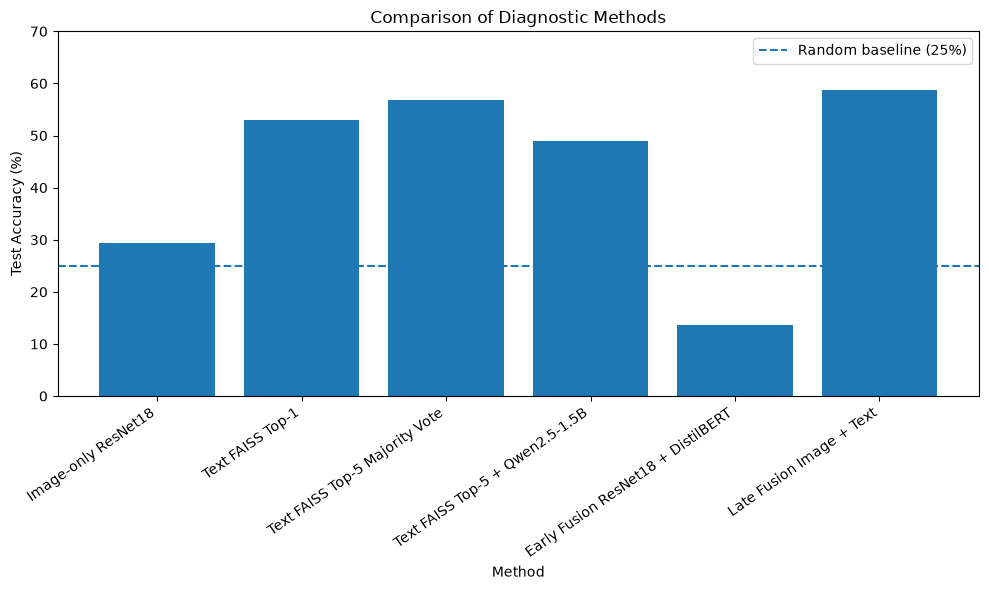

In [181]:
import matplotlib.pyplot as plt

plot_df = results.copy()

plt.figure(figsize=(10, 6))

bars = plt.bar(
    plot_df["Method"],
    plot_df["Accuracy (%)"]
)

plt.axhline(
    y=25,
    linestyle="--",
    label="Random baseline (25%)"
)

plt.ylabel("Test Accuracy (%)")
plt.xlabel("Method")

plt.title(
    "Comparison of Diagnostic Methods"
)

plt.xticks(
    rotation=35,
    ha="right"
)

plt.ylim(0, 70)

plt.legend()

plt.tight_layout()

plt.savefig(
    RESULT_DIR / "model_accuracy_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [182]:
ablation = pd.DataFrame([
    {
        "Configuration": "Image only",
        "Image": "✓",
        "Text": "",
        "Retrieval": "",
        "Fusion": "",
        "Accuracy": 0.2941,
        "Macro-F1": 0.2224
    },
    {
        "Configuration": "Text retrieval",
        "Image": "",
        "Text": "✓",
        "Retrieval": "✓",
        "Fusion": "",
        "Accuracy": 0.5686,
        "Macro-F1": 0.5750
    },
    {
        "Configuration": "Early multimodal fusion",
        "Image": "✓",
        "Text": "✓",
        "Retrieval": "",
        "Fusion": "Early",
        "Accuracy": 0.1373,
        "Macro-F1": 0.0816
    },
    {
        "Configuration": "Late multimodal fusion",
        "Image": "✓",
        "Text": "✓",
        "Retrieval": "✓",
        "Fusion": "Late",
        "Accuracy": 0.5882,
        "Macro-F1": 0.5913
    }
])

display(ablation)

ablation.to_csv(
    RESULT_DIR / "ablation_results.csv",
    index=False
)

,Configuration,Image,Text,Retrieval,Fusion,Accuracy,Macro-F1
0,Image only,✓,,,,0.2941,0.2224
1,Text retrieval,,✓,✓,,0.5686,0.5750
2,Early multimodal fusion,✓,✓,,Early,0.1373,0.0816
3,Late multimodal fusion,✓,✓,✓,Late,0.5882,0.5913


In [183]:
image_acc = 0.2941
text_acc = 0.5686
late_acc = 0.5882

print(
    "Late fusion vs image-only:"
)

print(
    f"{(late_acc-image_acc)*100:.2f} percentage points"
)

print(
    "\nLate fusion vs text-only:"
)

print(
    f"{(late_acc-text_acc)*100:.2f} percentage points"
)

Late fusion vs image-only:
29.41 percentage points

Late fusion vs text-only:
1.96 percentage points


In [184]:
class_results = pd.DataFrame([
    {
        "Disease": "Aspergillosis",
        "Precision": 0.6667,
        "Recall": 0.5882,
        "F1": 0.6250,
        "Support": 17
    },
    {
        "Disease": "Herpes simplex",
        "Precision": 0.4375,
        "Recall": 0.4667,
        "F1": 0.4516,
        "Support": 15
    },
    {
        "Disease": "Syphilis",
        "Precision": 0.4444,
        "Recall": 0.5000,
        "F1": 0.4706,
        "Support": 8
    },
    {
        "Disease": "Tuberculosis",
        "Precision": 0.8182,
        "Recall": 0.8182,
        "F1": 0.8182,
        "Support": 11
    }
])

display(class_results)

class_results.to_csv(
    RESULT_DIR / "late_fusion_per_class.csv",
    index=False
)

,Disease,Precision,Recall,F1,Support
0,Aspergillosis,0.6667,0.5882,0.6250,17
1,Herpes simplex,0.4375,0.4667,0.4516,15
2,Syphilis,0.4444,0.5000,0.4706,8
3,Tuberculosis,0.8182,0.8182,0.8182,11


In [185]:
errors = fusion_results_df[
    fusion_results_df["correct"] == False
].copy()

print(
    "Misclassified cases:",
    len(errors)
)

display(errors)

Misclassified cases: 21


,case_id,true_label,prediction,correct
10,PMC3481801_01,Herpes simplex,Syphilis,False
11,PMC6503770_01,Aspergillosis,Herpes simplex,False
12,PMC555544_01,Aspergillosis,Herpes simplex,False
18,PMC3800390_01,Herpes simplex,Syphilis,False
19,PMC5514794_01,Herpes simplex,Syphilis,False
20,PMC8019250_01,Herpes simplex,Aspergillosis,False
21,PMC3872660_01,Aspergillosis,Herpes simplex,False
26,PMC4031206_01,Aspergillosis,Herpes simplex,False
27,PMC4336666_01,Herpes simplex,Syphilis,False
28,PMC5463668_01,Aspergillosis,Tuberculosis,False


In [186]:
error_matrix = (
    errors
    .groupby(
        [
            "true_label",
            "prediction"
        ]
    )
    .size()
    .reset_index(
        name="count"
    )
    .sort_values(
        "count",
        ascending=False
    )
)

display(error_matrix)

,true_label,prediction,count
0,Aspergillosis,Herpes simplex,6
3,Herpes simplex,Syphilis,5
6,Syphilis,Herpes simplex,3
2,Herpes simplex,Aspergillosis,2
7,Tuberculosis,Aspergillosis,2
1,Aspergillosis,Tuberculosis,1
5,Syphilis,Aspergillosis,1
4,Herpes simplex,Tuberculosis,1


In [187]:
import torch
import torch.nn as nn

image_encoder = nn.Sequential(
    *list(image_model.children())[:-1]
)

image_encoder = image_encoder.to(device)
image_encoder.eval()

print(image_encoder)

Sequential(
  (0): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (2): ReLU(inplace=True)
  (3): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (4): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (

In [188]:
sample_image = Image.open(
    sample_case["image_path"]
).convert("RGB")

x = eval_transform(
    sample_image
).unsqueeze(0).to(device)

with torch.no_grad():
    feature = image_encoder(x)

print("Raw shape:", feature.shape)

feature = feature.flatten(1)

print("Embedding shape:", feature.shape)

Raw shape: torch.Size([1, 512, 1, 1])
Embedding shape: torch.Size([1, 512])


In [189]:
import torch.nn.functional as F

def encode_image(image_path):

    image = Image.open(
        image_path
    ).convert("RGB")

    tensor = eval_transform(
        image
    ).unsqueeze(0).to(device)

    with torch.no_grad():

        embedding = image_encoder(
            tensor
        )

        embedding = embedding.flatten(1)

        embedding = F.normalize(
            embedding,
            p=2,
            dim=1
        )

    return (
        embedding
        .cpu()
        .numpy()[0]
        .astype("float32")
    )

In [190]:
emb = encode_image(
    sample_case["image_path"]
)

print("Shape:", emb.shape)
print(
    "Norm:",
    (emb ** 2).sum() ** 0.5
)

Shape: (512,)
Norm: 1.0


In [191]:
train_image_df = (
    case_dataset[
        case_dataset["split"] == "train"
    ]
    [
        [
            "article_id",
            "case_id",
            "disease",
            "image_path"
        ]
    ]
    .reset_index(drop=True)
)

print(
    "Training images:",
    len(train_image_df)
)

print(
    train_image_df[
        "disease"
    ].value_counts()
)

Training images: 221
disease
Syphilis          57
Tuberculosis      57
Herpes simplex    54
Aspergillosis     53
Name: count, dtype: int64


In [192]:
import numpy as np

train_image_embeddings = []

for i, row in train_image_df.iterrows():

    emb = encode_image(
        row["image_path"]
    )

    train_image_embeddings.append(
        emb
    )

    if (i + 1) % 25 == 0:
        print(
            f"Encoded {i+1}/"
            f"{len(train_image_df)}"
        )

train_image_embeddings = np.vstack(
    train_image_embeddings
).astype("float32")

print(
    "Embedding matrix:",
    train_image_embeddings.shape
)

Encoded 25/221
Encoded 50/221
Encoded 75/221
Encoded 100/221
Encoded 125/221
Encoded 150/221
Encoded 175/221
Encoded 200/221
Embedding matrix: (221, 512)


In [193]:
import faiss

image_index = faiss.IndexFlatIP(
    train_image_embeddings.shape[1]
)

image_index.add(
    train_image_embeddings
)

print(
    "Image index size:",
    image_index.ntotal
)

Image index size: 221


In [194]:
faiss.write_index(
    image_index,
    "../discovery/faiss_multicare_images.index"
)

train_image_df.to_csv(
    "../discovery/faiss_multicare_images_metadata.csv",
    index=False
)

In [195]:
def retrieve_image(
    image_path,
    k=5
):

    query_embedding = encode_image(
        image_path
    ).reshape(1, -1)

    scores, indices = image_index.search(
        query_embedding,
        k
    )

    results = []

    for rank, (idx, score) in enumerate(
        zip(indices[0], scores[0]),
        start=1
    ):

        row = train_image_df.iloc[
            int(idx)
        ]

        results.append({
            "rank": rank,
            "score": float(score),
            "case_id": row["case_id"],
            "article_id": row["article_id"],
            "disease": row["disease"],
            "image_path": row["image_path"]
        })

    return results

In [196]:
image_neighbors = retrieve_image(
    sample_case["image_path"],
    k=5
)

print(
    "TRUE:",
    sample_case["disease"]
)

print()

for result in image_neighbors:

    print(
        f"Rank {result['rank']} | "
        f"{result['disease']:20s} | "
        f"{result['score']:.4f} | "
        f"{result['case_id']}"
    )

TRUE: Tuberculosis

Rank 1 | Herpes simplex       | 0.7666 | PMC3461402_01
Rank 2 | Tuberculosis         | 0.7611 | PMC5958587_01
Rank 3 | Tuberculosis         | 0.7565 | PMC12906382_01
Rank 4 | Aspergillosis        | 0.7554 | PMC8565698_01
Rank 5 | Aspergillosis        | 0.7327 | PMC3920391_01


In [197]:
def evaluate_image_retrieval(
    test_data,
    k=5
):

    top1_correct = 0
    recall_hits = 0
    reciprocal_ranks = []

    for row in test_data.itertuples():

        results = retrieve_image(
            row.image_path,
            k=k
        )

        retrieved_diseases = [
            r["disease"]
            for r in results
        ]

        true_disease = row.disease

        # Top-1
        if (
            retrieved_diseases[0]
            == true_disease
        ):
            top1_correct += 1

        # Recall@K + reciprocal rank
        if true_disease in retrieved_diseases:

            recall_hits += 1

            rank = (
                retrieved_diseases
                .index(true_disease)
                + 1
            )

            reciprocal_ranks.append(
                1 / rank
            )

        else:

            reciprocal_ranks.append(
                0.0
            )

    n = len(test_data)

    return {
        "n": n,
        "k": k,
        "top1_accuracy":
            top1_correct / n,

        "recall@k":
            recall_hits / n,

        "mrr@k":
            sum(reciprocal_ranks) / n
    }

In [198]:
image_retrieval_metrics = (
    evaluate_image_retrieval(
        test_fusion_df,
        k=5
    )
)

image_retrieval_metrics

{'n': 51,
 'k': 5,
 'top1_accuracy': 0.29411764705882354,
 'recall@k': 0.803921568627451,
 'mrr@k': 0.4604575163398693}

In [199]:
def image_retrieval_predict(
    image_path,
    k=5
):

    results = retrieve_image(
        image_path,
        k=k
    )

    diseases = [
        r["disease"]
        for r in results
    ]

    prediction = (
        Counter(diseases)
        .most_common(1)[0][0]
    )

    return prediction

In [200]:
image_rag_true = []
image_rag_pred = []

for row in test_fusion_df.itertuples():

    pred = image_retrieval_predict(
        row.image_path,
        k=5
    )

    image_rag_true.append(
        row.disease
    )

    image_rag_pred.append(
        pred
    )

image_rag_accuracy = accuracy_score(
    image_rag_true,
    image_rag_pred
)

image_rag_f1 = f1_score(
    image_rag_true,
    image_rag_pred,
    average="macro"
)

print(
    f"Image Retrieval Majority Accuracy: "
    f"{image_rag_accuracy:.4f}"
)

print(
    f"Image Retrieval Majority Macro-F1: "
    f"{image_rag_f1:.4f}"
)

Image Retrieval Majority Accuracy: 0.3137
Image Retrieval Majority Macro-F1: 0.2961


In [201]:
def reciprocal_rank_fusion(
    text_results,
    image_results,
    text_weight=1.0,
    image_weight=1.0,
    rrf_k=60
):
    scores = {}
    metadata = {}

    # TEXT ranking
    for rank, result in enumerate(
        text_results,
        start=1
    ):
        case_id = result["id"]

        scores[case_id] = (
            scores.get(case_id, 0)
            + text_weight / (rrf_k + rank)
        )

        metadata[case_id] = {
            "case_id": case_id,
            "disease": result["disease"]
        }

    # IMAGE ranking
    for rank, result in enumerate(
        image_results,
        start=1
    ):
        case_id = result["case_id"]

        scores[case_id] = (
            scores.get(case_id, 0)
            + image_weight / (rrf_k + rank)
        )

        metadata[case_id] = {
            "case_id": case_id,
            "disease": result["disease"]
        }

    ranked = sorted(
        scores.items(),
        key=lambda x: x[1],
        reverse=True
    )

    return [
        {
            **metadata[case_id],
            "rrf_score": score
        }
        for case_id, score in ranked
    ]

In [202]:
def multimodal_rrf_retrieve(
    patient_text,
    image_path,
    final_k=5,
    search_k=20,
    text_weight=1.0,
    image_weight=1.0
):

    text_results = retrieve(
        patient_text,
        k=search_k,
        search_k=max(search_k, 30)
    )

    image_results = retrieve_image(
        image_path,
        k=search_k
    )

    fused = reciprocal_rank_fusion(
        text_results,
        image_results,
        text_weight=text_weight,
        image_weight=image_weight,
        rrf_k=60
    )

    return fused[:final_k]

In [203]:
rrf_results = multimodal_rrf_retrieve(
    patient_text=sample["text"],
    image_path=sample_case["image_path"],
    final_k=5
)

print("TRUE:", sample["disease"])

for rank, result in enumerate(
    rrf_results,
    start=1
):
    print(
        f"{rank}. "
        f"{result['disease']:20s} | "
        f"RRF={result['rrf_score']:.6f} | "
        f"{result['case_id']}"
    )

TRUE: Tuberculosis
1. Tuberculosis         | RRF=0.030018 | PMC5958587_01
2. Tuberculosis         | RRF=0.026320 | PMC4531549_01
3. Syphilis             | RRF=0.016393 | PMC8286098_01
4. Herpes simplex       | RRF=0.016393 | PMC3461402_01
5. Aspergillosis        | RRF=0.016129 | PMC3340993_01


In [204]:
def rrf_predict(
    patient_text,
    image_path,
    text_weight=1.0,
    image_weight=1.0,
    k=5
):

    retrieved = multimodal_rrf_retrieve(
        patient_text=patient_text,
        image_path=image_path,
        final_k=k,
        search_k=20,
        text_weight=text_weight,
        image_weight=image_weight
    )

    diseases = [
        r["disease"]
        for r in retrieved
    ]

    counts = Counter(diseases)

    prediction = (
        counts.most_common(1)[0][0]
    )

    return {
        "prediction": prediction,
        "votes": dict(counts),
        "retrieved_cases": retrieved
    }

In [205]:
rrf_weights = [
    (1.0, 0.25),
    (1.0, 0.50),
    (1.0, 0.75),
    (1.0, 1.00)
]

In [206]:
rrf_val_results = []

for text_w, image_w in rrf_weights:

    y_true = []
    y_pred = []

    for row in val_fusion_df.itertuples():

        result = rrf_predict(
            patient_text=row.text,
            image_path=row.image_path,
            text_weight=text_w,
            image_weight=image_w,
            k=5
        )

        y_true.append(row.disease)
        y_pred.append(result["prediction"])

    acc = accuracy_score(
        y_true,
        y_pred
    )

    macro_f1 = f1_score(
        y_true,
        y_pred,
        average="macro"
    )

    rrf_val_results.append({
        "text_weight": text_w,
        "image_weight": image_w,
        "accuracy": acc,
        "macro_f1": macro_f1
    })

rrf_val_df = pd.DataFrame(
    rrf_val_results
)

display(rrf_val_df)

,text_weight,image_weight,accuracy,macro_f1
0,1.0,0.25,0.583333,0.587846
1,1.0,0.50,0.583333,0.587846
2,1.0,0.75,0.583333,0.587846
3,1.0,1.00,0.500000,0.503968


In [207]:
best_rrf = (
    rrf_val_df
    .sort_values(
        ["macro_f1", "accuracy"],
        ascending=False
    )
    .iloc[0]
)

BEST_TEXT_WEIGHT = float(
    best_rrf["text_weight"]
)

BEST_IMAGE_WEIGHT = float(
    best_rrf["image_weight"]
)

print(
    "Best text weight:",
    BEST_TEXT_WEIGHT
)

print(
    "Best image weight:",
    BEST_IMAGE_WEIGHT
)

print(
    "Validation Accuracy:",
    best_rrf["accuracy"]
)

print(
    "Validation Macro-F1:",
    best_rrf["macro_f1"]
)

Best text weight: 1.0
Best image weight: 0.25
Validation Accuracy: 0.5833333333333334
Validation Macro-F1: 0.5878464276633613


In [208]:
BEST_TEXT_WEIGHT = 1.0
BEST_IMAGE_WEIGHT = 0.25

rrf_test_true = []
rrf_test_pred = []
rrf_test_records = []

for row in test_fusion_df.itertuples():

    result = rrf_predict(
        patient_text=row.text,
        image_path=row.image_path,
        text_weight=BEST_TEXT_WEIGHT,
        image_weight=BEST_IMAGE_WEIGHT,
        k=5
    )

    rrf_test_true.append(
        row.disease
    )

    rrf_test_pred.append(
        result["prediction"]
    )

    rrf_test_records.append({
        "case_id": row.id,
        "true_label": row.disease,
        "prediction": result["prediction"],
        "correct":
            row.disease == result["prediction"],
        "votes": str(result["votes"])
    })

In [209]:
rrf_test_accuracy = accuracy_score(
    rrf_test_true,
    rrf_test_pred
)

rrf_test_macro_f1 = f1_score(
    rrf_test_true,
    rrf_test_pred,
    average="macro"
)

print(
    f"Multimodal RRF Test Accuracy: "
    f"{rrf_test_accuracy:.4f}"
)

print(
    f"Multimodal RRF Macro-F1: "
    f"{rrf_test_macro_f1:.4f}"
)

print(
    f"Correct: "
    f"{sum(
        t == p
        for t, p in zip(
            rrf_test_true,
            rrf_test_pred
        )
    )}/51"
)

Multimodal RRF Test Accuracy: 0.5882
Multimodal RRF Macro-F1: 0.5820
Correct: 30/51


In [210]:
print(
    classification_report(
        rrf_test_true,
        rrf_test_pred,
        labels=CLASSES,
        target_names=CLASSES,
        digits=4,
        zero_division=0
    )
)

                precision    recall  f1-score   support

 Aspergillosis     0.6667    0.5882    0.6250        17
Herpes simplex     0.7000    0.4667    0.5600        15
      Syphilis     0.3846    0.6250    0.4762         8
  Tuberculosis     0.6154    0.7273    0.6667        11

      accuracy                         0.5882        51
     macro avg     0.5917    0.6018    0.5820        51
  weighted avg     0.6212    0.5882    0.5915        51



[[10  2  2  3]
 [ 3  7  4  1]
 [ 1  1  5  1]
 [ 1  0  2  8]]


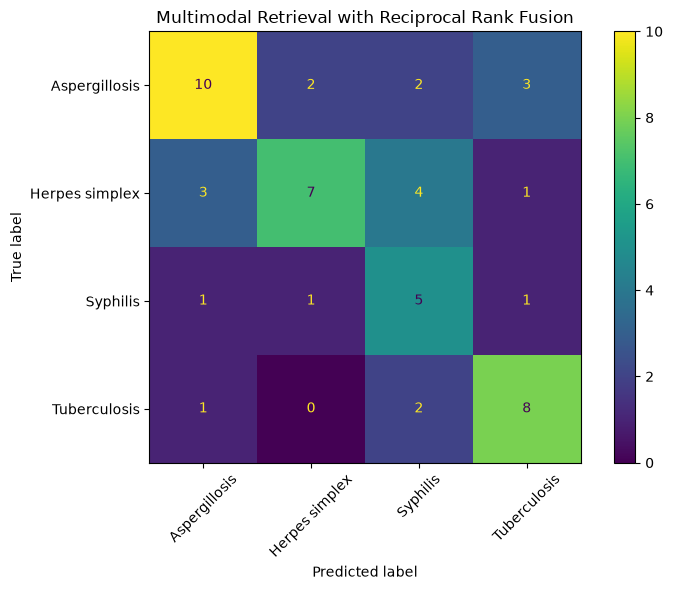

In [211]:
rrf_cm = confusion_matrix(
    rrf_test_true,
    rrf_test_pred,
    labels=CLASSES
)

print(rrf_cm)

disp = ConfusionMatrixDisplay(
    confusion_matrix=rrf_cm,
    display_labels=CLASSES
)

fig, ax = plt.subplots(
    figsize=(8, 6)
)

disp.plot(
    ax=ax,
    xticks_rotation=45
)

plt.title(
    "Multimodal Retrieval with Reciprocal Rank Fusion"
)

plt.tight_layout()
plt.show()

In [212]:
rrf_test_df = pd.DataFrame(
    rrf_test_records
)

rrf_test_df.to_csv(
    "../discovery/results/"
    "multimodal_rrf_results.csv",
    index=False
)

display(
    rrf_test_df.head()
)

,case_id,true_label,prediction,correct,votes
0,PMC2826293_01,Tuberculosis,Tuberculosis,True,"{'Tuberculosis': 3, 'Syphilis': 1, 'Aspergillo..."
1,PMC4399170_01,Herpes simplex,Tuberculosis,False,"{'Tuberculosis': 2, 'Syphilis': 2, 'Herpes sim..."
2,PMC3177425_01,Tuberculosis,Tuberculosis,True,"{'Tuberculosis': 4, 'Aspergillosis': 1}"
3,PMC8512623_01,Aspergillosis,Tuberculosis,False,"{'Tuberculosis': 2, 'Aspergillosis': 2, 'Herpe..."
4,PMC8512623_02,Aspergillosis,Aspergillosis,True,"{'Aspergillosis': 3, 'Tuberculosis': 2}"


In [213]:
complete_results = pd.DataFrame([
    {
        "Method": "Image-only ResNet18",
        "Accuracy": 0.2941,
        "Macro_F1": 0.2224
    },
    {
        "Method": "Image Retrieval Top-5 Majority",
        "Accuracy": 0.3137,
        "Macro_F1": 0.2961
    },
    {
        "Method": "Text FAISS Top-1",
        "Accuracy": 0.5294,
        "Macro_F1": None
    },
    {
        "Method": "Text FAISS Top-5 Majority",
        "Accuracy": 0.5686,
        "Macro_F1": 0.5750
    },
    {
        "Method": "Text FAISS + Qwen2.5-1.5B",
        "Accuracy": 0.4902,
        "Macro_F1": 0.4274
    },
    {
        "Method": "Early Fusion ResNet18 + DistilBERT",
        "Accuracy": 0.1373,
        "Macro_F1": 0.0816
    },
    {
        "Method": "Late Fusion Image + Text",
        "Accuracy": 0.5882,
        "Macro_F1": 0.5913
    },
    {
        "Method": "Multimodal Retrieval + RRF",
        "Accuracy": rrf_test_accuracy,
        "Macro_F1": rrf_test_macro_f1
    }
])

complete_results["Accuracy (%)"] = (
    complete_results["Accuracy"]
    * 100
).round(2)

display(
    complete_results[
        [
            "Method",
            "Accuracy (%)",
            "Macro_F1"
        ]
    ]
)

complete_results.to_csv(
    "../discovery/results/"
    "complete_experiment_results.csv",
    index=False
)

,Method,Accuracy (%),Macro_F1
0,Image-only ResNet18,29.41,0.222400
1,Image Retrieval Top-5 Majority,31.37,0.296100
2,Text FAISS Top-1,52.94,NaN
3,Text FAISS Top-5 Majority,56.86,0.575000
4,Text FAISS + Qwen2.5-1.5B,49.02,0.427400
5,Early Fusion ResNet18 + DistilBERT,13.73,0.081600
6,Late Fusion Image + Text,58.82,0.591300
7,Multimodal Retrieval + RRF,58.82,0.581964


In [214]:
dataset_summary = pd.DataFrame([
    {
        "Disease": "Aspergillosis",
        "Train": 53,
        "Validation": 10,
        "Test": 17,
        "Total": 80
    },
    {
        "Disease": "Herpes simplex",
        "Train": 54,
        "Validation": 11,
        "Test": 15,
        "Total": 80
    },
    {
        "Disease": "Syphilis",
        "Train": 57,
        "Validation": 15,
        "Test": 8,
        "Total": 80
    },
    {
        "Disease": "Tuberculosis",
        "Train": 57,
        "Validation": 12,
        "Test": 11,
        "Total": 80
    }
])

display(dataset_summary)

print("Total cases:", dataset_summary["Total"].sum())

,Disease,Train,Validation,Test,Total
0,Aspergillosis,53,10,17,80
1,Herpes simplex,54,11,15,80
2,Syphilis,57,15,8,80
3,Tuberculosis,57,12,11,80


Total cases: 320


In [215]:
dataset_summary.to_csv(
    "../discovery/results/dataset_summary.csv",
    index=False
)

In [216]:
retrieval_results = pd.DataFrame([
    {
        "Modality": "Clinical Text",
        "Top-1 Accuracy": 0.5294,
        "Recall@5": 0.8235,
        "MRR@5": 0.6441,
        "Top-5 Majority Accuracy": 0.5686
    },
    {
        "Modality": "Medical Image",
        "Top-1 Accuracy": 0.2941,
        "Recall@5": 0.8039,
        "MRR@5": 0.4605,
        "Top-5 Majority Accuracy": 0.3137
    }
])

display(retrieval_results)

retrieval_results.to_csv(
    "../discovery/results/retrieval_results.csv",
    index=False
)

,Modality,Top-1 Accuracy,Recall@5,MRR@5,Top-5 Majority Accuracy
0,Clinical Text,0.5294,0.8235,0.6441,0.5686
1,Medical Image,0.2941,0.8039,0.4605,0.3137


In [217]:
plot_results = pd.DataFrame([
    ["Image-only", 29.41],
    ["Text Top-1", 52.94],
    ["Text Top-5 Vote", 56.86],
    ["Qwen RAG", 49.02],
    ["Late Fusion", 58.82],
    ["Multimodal RRF", 58.82]
], columns=[
    "Method",
    "Accuracy"
])

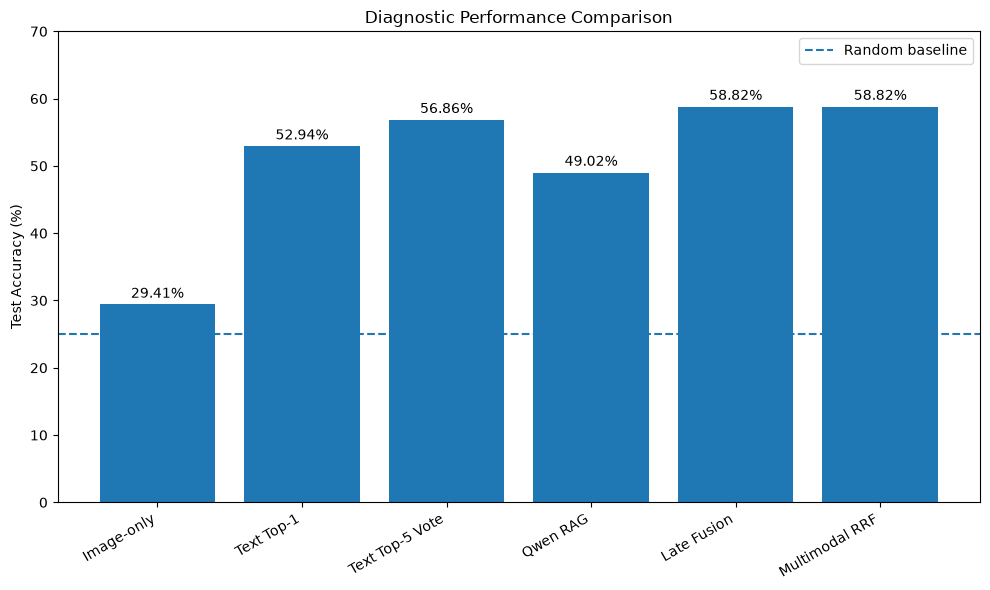

In [218]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

bars = plt.bar(
    plot_results["Method"],
    plot_results["Accuracy"]
)

plt.axhline(
    25,
    linestyle="--",
    label="Random baseline"
)

plt.ylabel("Test Accuracy (%)")

plt.title(
    "Diagnostic Performance Comparison"
)

plt.xticks(
    rotation=30,
    ha="right"
)

plt.ylim(0, 70)

for bar, value in zip(
    bars,
    plot_results["Accuracy"]
):
    plt.text(
        bar.get_x()
        + bar.get_width()/2,

        value + 1,

        f"{value:.2f}%",

        ha="center"
    )

plt.legend()
plt.tight_layout()

plt.savefig(
    "../discovery/results/"
    "final_accuracy_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [219]:
per_class_comparison = pd.DataFrame({
    "Disease": [
        "Aspergillosis",
        "Herpes simplex",
        "Syphilis",
        "Tuberculosis"
    ],

    "Late Fusion": [
        0.6250,
        0.4516,
        0.4706,
        0.8182
    ],

    "RRF": [
        0.6250,
        0.5600,
        0.4762,
        0.6667
    ]
})

display(per_class_comparison)

,Disease,Late Fusion,RRF
0,Aspergillosis,0.6250,0.6250
1,Herpes simplex,0.4516,0.5600
2,Syphilis,0.4706,0.4762
3,Tuberculosis,0.8182,0.6667


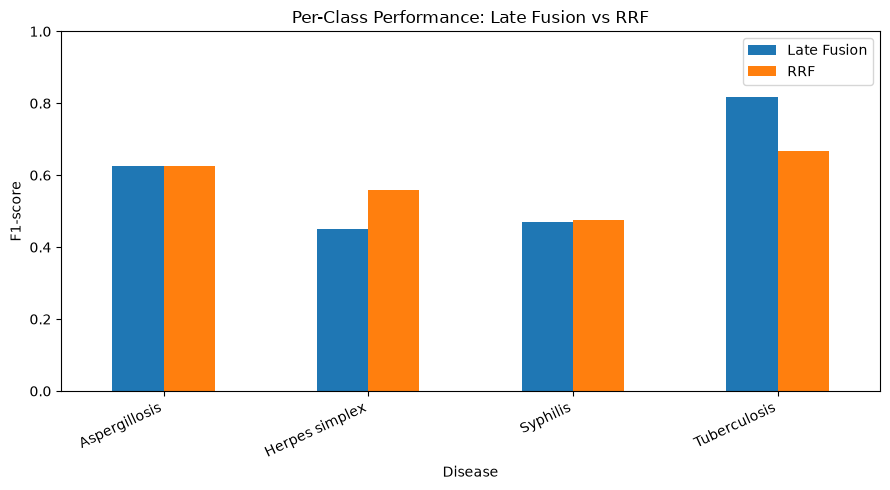

In [220]:
ax = (
    per_class_comparison
    .set_index("Disease")
    .plot(
        kind="bar",
        figsize=(9, 5)
    )
)

ax.set_ylabel("F1-score")

ax.set_title(
    "Per-Class Performance: "
    "Late Fusion vs RRF"
)

ax.set_ylim(0, 1)

plt.xticks(
    rotation=25,
    ha="right"
)

plt.tight_layout()

plt.savefig(
    "../discovery/results/"
    "late_fusion_vs_rrf.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [221]:
print("=" * 70)
print("FINAL EXPERIMENT SUMMARY")
print("=" * 70)

print("""
Dataset
-------
MultiCaRe only
4 disease classes
320 cases
643 verified images

Split
-----
Train:      221 cases
Validation:  48 cases
Test:        51 cases

Text Retrieval
--------------
Top-1 Accuracy: 52.94%
Recall@5:       82.35%
MRR@5:          0.6441
Top-5 Vote:     56.86%

Image Retrieval
---------------
Top-1 Accuracy: 29.41%
Recall@5:       80.39%
MRR@5:          0.4605
Top-5 Vote:     31.37%

Best Classification
-------------------
Late Fusion
Accuracy: 58.82%
Macro-F1: 0.5913

Multimodal RAG Retrieval
------------------------
Weighted RRF
Text weight:  1.0
Image weight: 0.25

Accuracy: 58.82%
Macro-F1: 0.5820
""")

FINAL EXPERIMENT SUMMARY

Dataset
-------
MultiCaRe only
4 disease classes
320 cases
643 verified images

Split
-----
Train:      221 cases
Validation:  48 cases
Test:        51 cases

Text Retrieval
--------------
Top-1 Accuracy: 52.94%
Recall@5:       82.35%
MRR@5:          0.6441
Top-5 Vote:     56.86%

Image Retrieval
---------------
Top-1 Accuracy: 29.41%
Recall@5:       80.39%
MRR@5:          0.4605
Top-5 Vote:     31.37%

Best Classification
-------------------
Late Fusion
Accuracy: 58.82%
Macro-F1: 0.5913

Multimodal RAG Retrieval
------------------------
Weighted RRF
Text weight:  1.0
Image weight: 0.25

Accuracy: 58.82%
Macro-F1: 0.5820

